# Main-Code

Reproducing Fig-5 of [arXiv:1806.02915](https://arxiv.org/abs/1806.02915) — Chluba (2018), will involve plotting functions for mu,y and temp shift functions that can be easily evaulated analytically.

$$G(x) = \frac{x e^x}{(e^x - 1)^2}$$

$$\Delta I_y(x) = G(x)\left[x\coth\!\left(\frac{x}{2}\right) - 4\right] \quad \text{(y / tSZ distortion)}$$

$$\Delta I_{\Delta T}(x) = G(x) \quad \text{(temperature shift)}$$

$$\Delta I_\mu(x) = 1.401\, G(x)\left[0.4561 - \frac{1}{x}\right] \quad \text{($\mu$-distortion)}$$



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from scipy.optimize import brentq

def G(x):
    return x*np.exp(x) / ((np.exp(x)-1)**2)

def Ysz(x):
    return G(x)*(x/np.tanh(x/2)-4)

def tempshift(x):
    return G(x)

def mudist(x):
    return 1.401*G(x)*(0.4561-1/x)

def bbdspec(x):
    return 1 / (np.exp(x)-1)

# ── Frequency axes ───────────────────────────────────────────────────────────
# Dimensionless frequency x = h*nu / (k*T0),  T0 = 2.7255 K, k*T0 = 3.77887e-23 J
# Corresponding physical frequency: nu [GHz] = x * k*T0/h  ≈  x * 56.81 GHz

T0       = 2.726          # K
nu_scale = 56.81           # GHz per unit x  (kT0/h)

x = np.linspace(0.1, 18, 4000)
nu  = x * nu_scale         # GHz

# Find the zero-crossings of the y and mu distortions for annotation
y_range  = (2.0, 4.0)
mu_range = (1.0, 2.5)
x_y_zero  = brentq(lambda x: x / np.tanh(x / 2) - 4,  *y_range)
x_mu_zero = brentq(lambda x: 0.4561 - 1.0 / x,         *mu_range)

# ── Evaluate distortions ─────────────────────────────────────────────────────
y_vals  = x**3 * Ysz(x)
dT_vals = x**3 * tempshift(x)
mu_vals = x**3 * mudist(x)
bbdspec_vals = x**3 * bbdspec(x)

# ── Plot ─────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5.5))

# Colour palette mimicking the paper
c_y  = '#E63946'   # red  – y distortion
c_dT = '#457B9D'   # blue – temperature shift
c_mu = '#2A9D8F'   # teal – mu distortion
c_bbdspec = '#F15BB5'  # pink – blackbody spectrum
lw = 2.2

ax.plot(x, bbdspec_vals, color=c_bbdspec, lw=lw, ls=':', label=r'Blackbody  $I_{\rm BB}$')
ax.plot(x, dT_vals, color=c_dT, lw=lw, ls='--', label=r'Temp. shift  $I_{\Delta T}$')
ax.plot(x, y_vals,  color=c_y,  lw=lw, ls='-',  label=r'$y$-distortion  $\Delta I_y$')
ax.plot(x, mu_vals, color=c_mu, lw=lw, ls='-.',  label=r'$\mu$-distortion  $\Delta I_\mu$')

# Zero line
ax.axhline(0.01, color='gray', lw=0.8, ls=':')

# Mark the zero-crossings of the distortions
for xz, color in [(x_y_zero, c_y), (x_mu_zero, c_mu)]:
    ax.axvline(xz, color=color, lw=1.0, ls=':', alpha=0.7)
    ax.plot(xz, 0, 'o', color=color, ms=6, zorder=5)

ax.annotate(fr'$x_y={x_y_zero:.3f}$' + f'\n({x_y_zero*nu_scale:.0f} GHz)',
            xy=(x_y_zero, 0), xytext=(x_y_zero+0.6, -1), color=c_y, fontsize=8.5,
            arrowprops=dict(arrowstyle='->', color=c_y, lw=1.0))
ax.annotate(fr'$x_\mu={x_mu_zero:.3f}$' + f'\n({x_mu_zero*nu_scale:.0f} GHz)',
            xy=(x_mu_zero, 0), xytext=(x_mu_zero-0.4, -1.6), color=c_mu, fontsize=8.5,
            arrowprops=dict(arrowstyle='->', color=c_mu, lw=1.0))

# Second x-axis in GHz
ax2 = ax.twiny()
ax2.set_xlim(ax.get_xlim()[0] * nu_scale, ax.get_xlim()[1] * nu_scale)
ax2.set_xlabel(r'Frequency $\nu$ [GHz]', fontsize=12)
ax2.xaxis.set_major_locator(ticker.MultipleLocator(100))
ax2.xaxis.set_minor_locator(ticker.MultipleLocator(50))
ax2.tick_params(direction='in', which='both')

# Formatting
# Use a logarithmic x-axis for better dynamic-range visualization
ax.set_xscale('log')
ax.set_xlim(0.1, 18)
# Now make the secondary axis match the primary (in linear units) and set it to log
ax2.set_xscale('log')
ax2.set_xlim(ax.get_xlim()[0] * nu_scale, ax.get_xlim()[1] * nu_scale)
# ax.set_ylim(-1.25, 1.55)
ax.set_xlabel(r'Dimensionless frequency  $x = h\nu/kT_0$', fontsize=12)
ax.set_ylabel(r'Spectral distortion  $I$', fontsize=12)
ax.set_title(r'CMB Spectral Distortion Shapes   [Fig. 5, Chluba 2018, arXiv:1806.02915]',
             fontsize=11, pad=30)

# Use log tick locators on the x-axis (both axes) and keep linear ticks on y
ax.xaxis.set_major_locator(ticker.LogLocator(base=10.0))
ax.xaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs=[2,3,4,5,6,7,8,9]))
ax2.xaxis.set_major_locator(ticker.LogLocator(base=10.0))
ax2.xaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs=[2,3,4,5,6,7,8,9]))
ax.yaxis.set_major_locator(ticker.MultipleLocator(base=1))
ax.tick_params(direction='in', which='both', top=False)

ax.legend(loc='upper right', fontsize=11, framealpha=0.9,
          edgecolor='lightgray', handlelength=2.5)

# Annotation box with physical context
info = (
    r'$I_{\rm BB} = x^3 / (e^x - 1)$' + '\n'
    r'$G(x)=\dfrac{xe^x}{(e^x-1)^2}$' + '\n'
    r'$\Delta I_y = \dfrac{x^3 G(x)[x\coth(x/2)-4]}{4}$' + '\n'
    r'$\Delta I_{\Delta T} = \dfrac{x^3 G(x)}{4}$' + '\n'
    r'$\Delta I_\mu = 1.401\,x^3 G(x)[0.4561-1/x]$' 
    
)
ax.text(0.02, 0.98, info, transform=ax.transAxes, fontsize=8.5,
        va='top', ha='left', family='monospace',
        bbox=dict(boxstyle='round,pad=0.4', fc='white', alpha=0.85, ec='lightgray'))

fig.tight_layout()
plt.show()

KeyboardInterrupt: 

Reproducing Fig-6 will just require plotting the Planck and Bose-Einstein Distribution.

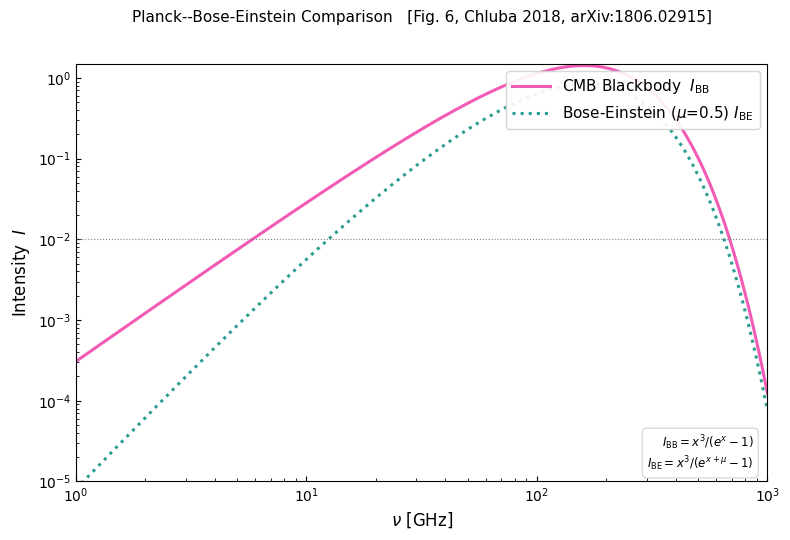

In [ ]:
def bedist(x,mu):
    return 1/(np.exp(x+mu)-1)

nu2 = np.linspace(1, 1000, 4000)  # GHz
x2 = nu2 / nu_scale  # dimensionless frequency

be_vals = x2**3 * bedist(x2, mu=0.5)
bbd_vals = x2**3 * bbdspec(x2)

# ── Plot ─────────────────────────────────────────────────────────────────────
fig, ax_2 = plt.subplots(figsize=(8, 5.5))

# Colour palette mimicking the paper
c_be = '#2A9D8F'   # teal – mu distortion
c_bbdspec = '#F15BB5'  # pink – blackbody spectrum
lw = 2.2

ax_2.plot(nu2, bbd_vals, color=c_bbdspec, lw=lw, ls='-', label=r'CMB Blackbody  $I_{\rm BB}$')
ax_2.plot(nu2, be_vals, color=c_be, lw=lw, ls=':', label=r'Bose-Einstein ($\mu$=0.5) $I_{\rm BE}$')

# Zero line
ax_2.axhline(0.01, color='gray', lw=0.8, ls=':')
# Formatting
# Use a logarithmic x-axis for better dynamic-range visualization
ax_2.set_xscale('log')
ax_2.set_xlim(1, 1000)
# ax_2.set_ylim(-1.25, 1.55)
ax_2.set_xlabel(r'$\nu$ [GHz]', fontsize=12)
ax_2.set_ylabel(r'Intensity  $I$', fontsize=12)
ax_2.set_yscale('log')
ax_2.set_ylim(1e-5, 1.5)
ax_2.set_title(r'Planck--Bose-Einstein Comparison   [Fig. 6, Chluba 2018, arXiv:1806.02915]',
             fontsize=11, pad=30)

# Use log tick locators on the x-axis (both axes) and keep linear ticks on y
ax_2.xaxis.set_major_locator(ticker.LogLocator(base=10.0))
ax_2.xaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs=[2,3,4,5,6,7,8,9]))
ax_2.yaxis.set_major_locator(ticker.LogLocator(base=10.0))
ax_2.tick_params(direction='in', which='both', top=False)

ax_2.legend(loc='upper right', fontsize=11, framealpha=0.9,
          edgecolor='lightgray', handlelength=2.5)

# Annotation box with physical context
info = (
    r'$I_{\rm BB} = x^3 / (e^x - 1)$' + '\n'
    r'$I_{\rm BE} = x^3 / (e^{x+\mu} - 1)$'
    
)
ax_2.text(0.98, 0.02, info, transform=ax_2.transAxes, fontsize=8.5,
        va='bottom', ha='right', family='monospace',
        bbox=dict(boxstyle='round,pad=0.4', fc='white', alpha=0.85, ec='lightgray'))

fig.tight_layout()
plt.show()

# Simulation Output from Greens v1.0.3

In [ ]:
# parameters: Gamma_X = 50000, f_X = 2000, k0 = 0.002, wave mode
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from scipy.integrate import cumulative_trapezoid

# output filepath
filepath = "/home/batman/Documents/Work/CMBSD/Greens.v1.0.3/"

# ── Load heating-rate file (comment lines start with #) ──────────────────────
hr = np.loadtxt(f"{filepath}outputs/heating_rate.decay3.dat", comments="#")
z_hr   = hr[:, 0]          # redshift
dQdz   = hr[:, 1]          # (1+z) dQ/dz  [energy/volume/redshift, code units]

# ── Load distortion-spectrum file ─────────────────────────────────────────────
ds = np.loadtxt(f"{filepath}outputs/distortion.decay3.dat", comments="#")
nu_ds    = ds[:, 0]   # frequency [GHz]
x_ds     = ds[:, 1]   # dimensionless x
DI_y     = ds[:, 2]   # late y-distortion      [Jy/sr]
DI_T     = ds[:, 3]   # temperature shift      [Jy/sr]
DI_prim  = ds[:, 4]   # primordial distortion  [Jy/sr]
DI_tot   = ds[:, 5]   # total distortion       [Jy/sr]

print(f"Heating-rate file: {len(z_hr)} rows,  z ∈ [{z_hr.min():.0f}, {z_hr.max():.2e}]")
print(f"Distortion  file : {len(nu_ds)} rows,  ν ∈ [{nu_ds.min():.2f}, {nu_ds.max():.0f}] GHz")


Heating-rate file: 500 rows,  z ∈ [1001, 5.00e+06]
Distortion  file : 4190 rows,  ν ∈ [0.06, 2271] GHz


Heating Rate $(1+z)\,dQ/dz$ vs Redshift
This is the raw energy injection per unit redshift output by the solver.  
The sharp peak marks the decay epoch set by $\Gamma_X = 50000$.

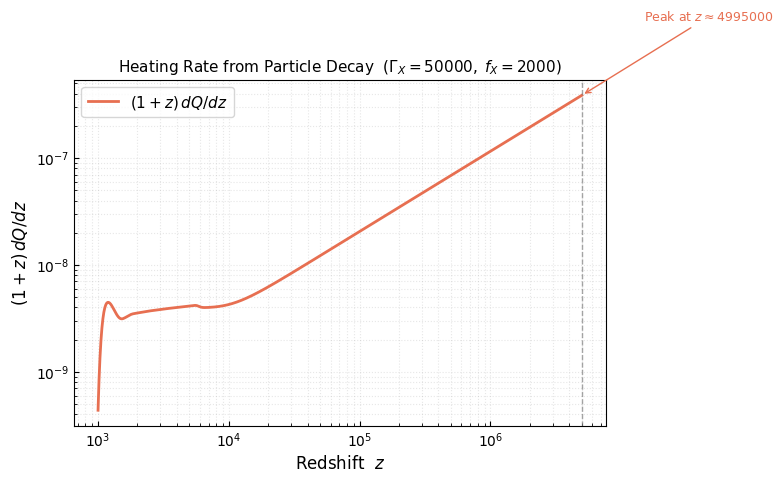

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(z_hr, dQdz, color='#E76F51', lw=2.0, label=r'$(1+z)\,dQ/dz$')

# Mark the peak
peak_idx = np.argmax(dQdz)
ax.axvline(z_hr[peak_idx], color='gray', lw=1.0, ls='--', alpha=0.7)
ax.annotate(fr'Peak at $z\approx{z_hr[peak_idx]:.0f}$',
            xy=(z_hr[peak_idx], dQdz[peak_idx]),
            xytext=(z_hr[peak_idx]*3, dQdz[peak_idx]*5),
            fontsize=9, color='#E76F51',
            arrowprops=dict(arrowstyle='->', color='#E76F51', lw=1.0))

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'Redshift  $z$', fontsize=12)
ax.set_ylabel(r'$(1+z)\,dQ/dz$', fontsize=12)
ax.set_title(r'Heating Rate from Particle Decay  ($\Gamma_X = 50000,\; f_X = 2000$)',
             fontsize=11)
ax.legend(fontsize=11)
ax.tick_params(direction='in', which='both')
ax.grid(True, which='both', ls=':', alpha=0.3)

fig.tight_layout()
plt.show()

Simulated Spectral Distortion: 
All four components returned by the Green's function solver plotted together.  
This is the predicted CMB spectral distortion signal.

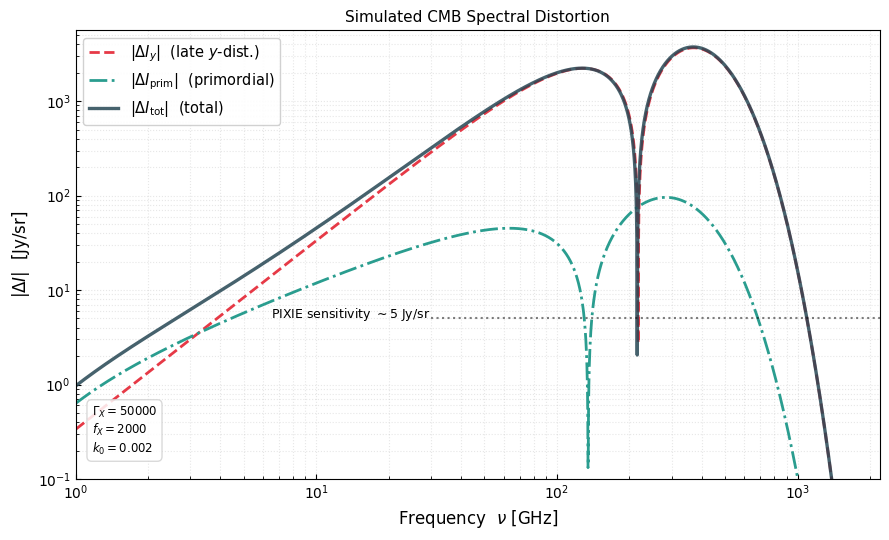

In [ ]:
# Mask to ν range where signal is non-negligible
mask = (nu_ds > 1) & (nu_ds < 2200)

fig, ax = plt.subplots(figsize=(9, 5.5))

c_y    = '#E63946'
c_T    = '#457B9D'
c_prim = '#2A9D8F'
c_tot  = '#264653'
lw     = 2.0

ax.plot(nu_ds[mask], np.abs(DI_y[mask]),    color=c_y,    lw=lw, ls='--',
        label=r'$|\Delta I_y|$  (late $y$-dist.)')
# ax.plot(nu_ds[mask], np.abs(DI_T[mask]+1e-30), color=c_T, lw=lw, ls=':',
#         label=r'$|\Delta I_{\Delta T}|$  (temp. shift)')
ax.plot(nu_ds[mask], np.abs(DI_prim[mask]), color=c_prim, lw=lw, ls='-.',
        label=r'$|\Delta I_{\rm prim}|$  (primordial)')
ax.plot(nu_ds[mask], np.abs(DI_tot[mask]),  color=c_tot,  lw=lw*1.2, ls='-',
        label=r'$|\Delta I_{\rm tot}|$  (total)', alpha=0.85)
xlim = ax.get_xlim()
ax.plot([30, xlim[1]], [5, 5], color='black', lw=1.5, ls=':', alpha=0.5)
ax.annotate(fr'PIXIE sensitivity $\sim 5$ Jy/sr',
            xy=(30, 5),
            xytext=(6.5, 5),
            fontsize=9, color='black')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(1, 2200)
ax.set_ylim(1e-1, np.max(np.abs(DI_tot[mask]))*1.5)
ax.set_xlabel(r'Frequency  $\nu$ [GHz]', fontsize=12)
ax.set_ylabel(r'$|\Delta I|$  [Jy/sr]', fontsize=12)
ax.set_title("Simulated CMB Spectral Distortion",
             fontsize=11)
ax.legend(fontsize=10.5, framealpha=0.9)
ax.tick_params(direction='in', which='both')
ax.grid(True, which='both', ls=':', alpha=0.3)

info = (r'$\Gamma_X = 50000$' + '\n'
        r'$f_X = 2000$' + '\n'
        r'$k_0 = 0.002$')
ax.text(0.02, 0.05, info, transform=ax.transAxes, fontsize=8.5,
        va='bottom', family='monospace',
        bbox=dict(boxstyle='round,pad=0.4', fc='white', alpha=0.85, ec='lightgray'))

fig.tight_layout()
plt.show()

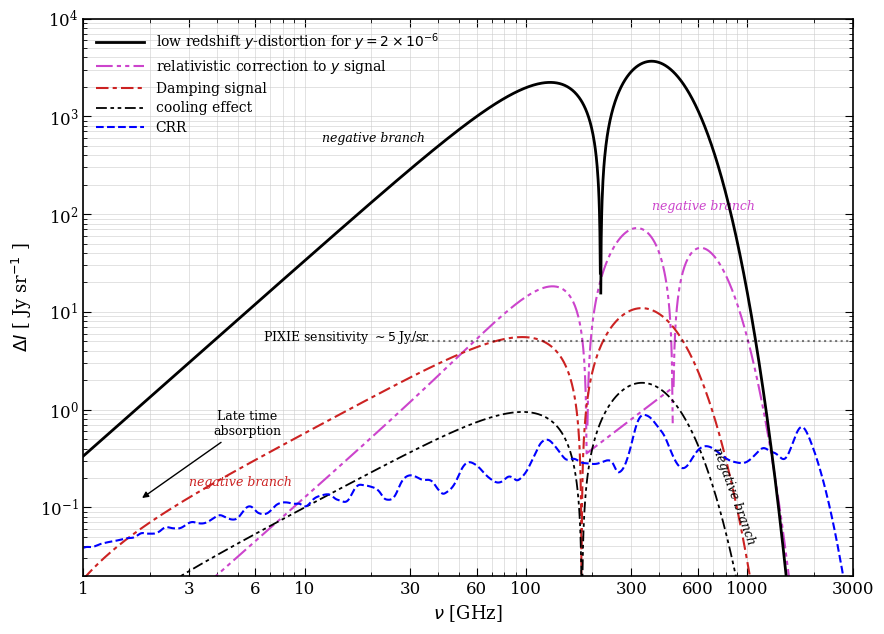

In [ ]:
"""
Reproduces Fig. 1 of Chluba (2016) — CMB spectral distortions.

Expected data files (two-column: nu[GHz]  DI[Jy/sr], with '#' comment lines):
  y_distortion.dat        – low redshift y-distortion  (y = 2e-6)
  relativistic_y.dat      – relativistic correction to y signal
  damping_signal.dat      – damping / Silk-damping signal
  cooling_effect.dat      – adiabatic cooling effect
  CRR.dat                 – Cosmological Recombination Radiation

Usage
-----
  python plot_spectral_distortions.py

The script looks for the data files in the current directory.
Adjust FILE_MAP below if your filenames differ.
"""

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import os
import sys

# ---------------------------------------------------------------------------
# FILE MAP  –  edit these paths to match your actual filenames
# ---------------------------------------------------------------------------

filepath = "/home/batman/Documents/Work/CMBSD/DI_all/DI_"

FILE_MAP = {
    "y":    f"{filepath}y_late.dat",
    "rel":  f"{filepath}rel_corr.dat",
    "damp": f"{filepath}damping.dat",
    "cool": f"{filepath}cooling.dat",
    "crr":  f"{filepath}CRR.dat",
}

# ---------------------------------------------------------------------------
# Helpers
# ---------------------------------------------------------------------------

def load_dat(path):
    """Load a two-column CosmoTherm-style data file (skip '#' comments)."""
    nu, di = [], []
    with open(path) as fh:
        for line in fh:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            cols = line.split()
            if len(cols) >= 2:
                nu.append(float(cols[0]))
                di.append(float(cols[1]))
    return np.asarray(nu), np.asarray(di)


def check_files():
    missing = [v for v in FILE_MAP.values() if not os.path.isfile(v)]
    if missing:
        print("ERROR – the following data files were not found:")
        for f in missing:
            print(f"  {f}")
        print("\nPlease place the files in the current directory, or edit FILE_MAP in this script.")
        sys.exit(1)


# ---------------------------------------------------------------------------
# Main plot
# ---------------------------------------------------------------------------

def make_plot():
    check_files()

    # --- load data -----------------------------------------------------------
    data = {k: load_dat(v) for k, v in FILE_MAP.items()}

    # --- matplotlib style matching the paper --------------------------------
    matplotlib.rcParams.update({
        "font.family":      "serif",
        "font.size":        12,
        "axes.linewidth":   1.2,
        "axes.facecolor":   "white",
        "figure.facecolor": "white",
        "xtick.direction":  "in",
        "ytick.direction":  "in",
        "xtick.major.size": 6,
        "ytick.major.size": 6,
        "xtick.minor.size": 3,
        "ytick.minor.size": 3,
        "xtick.top":        True,
        "ytick.right":      True,
        "grid.color":       "#cccccc",
        "grid.linewidth":   0.5,
        "legend.frameon":   False,
        "legend.fontsize":  10,
    })

    fig, ax = plt.subplots(figsize=(9, 6.5))
    fig.patch.set_facecolor("white")
    ax.set_facecolor("white")

    # Frequency range shown in the paper: 1 – 3000 GHz
    NU_MIN, NU_MAX = 1.0, 3000.0
    DI_MIN, DI_MAX = 1e-1, 1e4

    # Helper: split into positive/negative branches within plot range
    def split_branches(nu_arr, di_arr):
        mask = (nu_arr >= NU_MIN) & (nu_arr <= NU_MAX)
        nu_m = nu_arr[mask]
        di_m = di_arr[mask]
        pos = di_m >= 0
        neg = di_m < 0
        return nu_m, di_m, pos, neg

    # --- y-distortion  (solid black) ----------------------------------------
    nu_y, di_y = data["y"]
    nu_yp, di_ys, pos_y, neg_y = split_branches(nu_y, di_y)

    if pos_y.any():
        ax.plot(nu_yp[pos_y], np.abs(di_ys[pos_y]),
                color="black", lw=2.0, ls="-", zorder=5)
    if neg_y.any():
        ax.plot(nu_yp[neg_y], np.abs(di_ys[neg_y]),
                color="black", lw=2.0, ls="-", zorder=5)

    # dummy entry for legend
    ax.plot([], [], color="black", lw=2.0, ls="-",
            label=r"low redshift $y$-distortion for $y = 2 \times 10^{-6}$")

    # "negative branch" labels for y — horizontal, matching target positions
    ax.text(12, 600, "negative branch", fontsize=9, color="black",
            style="italic", ha="left", va="center")

    # --- relativistic correction  (purple dash-dot-dot) ---------------------
    nu_r, di_r = data["rel"]
    nu_rp, di_rs, pos_r, neg_r = split_branches(nu_r, di_r)

    col_rel = "#cc44cc"
    ls_rel  = (0, (8, 2, 2, 2, 2, 2))   # dash-dot-dot

    if pos_r.any():
        ax.plot(nu_rp[pos_r], np.abs(di_rs[pos_r]),
                color=col_rel, lw=1.5, linestyle=ls_rel)
    if neg_r.any():
        ax.plot(nu_rp[neg_r], np.abs(di_rs[neg_r]),
                color=col_rel, lw=1.5, linestyle=ls_rel)

    ax.plot([], [], color=col_rel, lw=1.5, linestyle=ls_rel,
            label="relativistic correction to $y$ signal")

    # "negative branch" for rel — horizontal label near top-right
    ax.text(370, 120, "negative branch", fontsize=9, color=col_rel,
            style="italic", ha="left", va="center")

    # --- damping signal  (red dash-dot) -------------------------------------
    nu_d, di_d = data["damp"]
    nu_dp, di_ds, pos_d, neg_d = split_branches(nu_d, di_d)

    col_damp = "#cc2222"
    ls_damp  = (0, (6, 2, 2, 2))   # dash-dot

    if pos_d.any():
        ax.plot(nu_dp[pos_d], np.abs(di_ds[pos_d]),
                color=col_damp, lw=1.5, linestyle=ls_damp)
    if neg_d.any():
        ax.plot(nu_dp[neg_d], np.abs(di_ds[neg_d]),
                color=col_damp, lw=1.5, linestyle=ls_damp)

    ax.plot([], [], color=col_damp, lw=1.5, linestyle=ls_damp,
            label="Damping signal")

    # "negative branch" for damping — horizontal, mid-left area (matching target)
    ax.text(3, 0.18, "negative branch", fontsize=9, color=col_damp,
            style="italic", ha="left", va="center")

    # --- cooling effect  (black dash-dot-dot, thinner) ----------------------
    nu_c, di_c = data["cool"]
    nu_cp, di_cs, pos_c, neg_c = split_branches(nu_c, di_c)

    col_cool = "black"
    ls_cool  = (0, (6, 2, 2, 2, 2, 2))   # dash-dot-dot (distinct from y)

    if pos_c.any():
        ax.plot(nu_cp[pos_c], np.abs(di_cs[pos_c]),
                color=col_cool, lw=1.3, linestyle=ls_cool)
    if neg_c.any():
        ax.plot(nu_cp[neg_c], np.abs(di_cs[neg_c]),
                color=col_cool, lw=1.3, linestyle=ls_cool)

    ax.plot([], [], color=col_cool, lw=1.3, linestyle=ls_cool,
            label="cooling effect")

    # "negative branch" for cooling — bottom-right, diagonal like target
    ax.text(680, 0.13, "negative branch", fontsize=9, color="black",
            style="italic", ha="left", va="center", rotation=-70)

    # --- CRR  (blue dashed) -------------------------------------------------
    nu_crr, di_crr = data["crr"]
    mask_crr = (nu_crr >= NU_MIN) & (nu_crr <= NU_MAX)
    ax.plot(nu_crr[mask_crr], np.abs(di_crr[mask_crr]),
            color="blue", lw=1.5, ls="--", label="CRR")

    # --- PIXIE sensitivity line  (black dotted, clearly visible) ------------
    xlim = ax.get_xlim()
    ax.plot([30, xlim[1]], [5, 5], color='black', lw=1.5, ls=':', alpha=0.5)
    ax.annotate(fr'PIXIE sensitivity $\sim 5$ Jy/sr',
            xy=(30, 5),
            xytext=(6.5, 5),
            fontsize=9, color='black')

    # --- Late time absorption annotation  (arrow pointing down-left) --------
    ax.annotate("Late time\nabsorption",
                xy=(1.8, 0.12),        # arrow tip — pointing toward low-nu low-DI
                xytext=(5.5, 0.55),    # text position — slightly up and right
                fontsize=9,
                ha="center",
                arrowprops=dict(arrowstyle="-|>", color="black", lw=1.0),
                )

    # --- Axes formatting ----------------------------------------------------
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(1, 3000)
    ax.set_ylim(2e-2, 1e4)

    # custom tick labels to match paper (1 3 6 10 30 60 100 300 600 1000 3000)
    major_ticks = [1, 3, 6, 10, 30, 60, 100, 300, 600, 1000, 3000]
    ax.set_xticks(major_ticks)
    ax.get_xaxis().set_major_formatter(ticker.FuncFormatter(
        lambda v, _: f"{int(v)}" if v >= 1 else f"{v}"))
    ax.get_xaxis().set_minor_formatter(ticker.NullFormatter())

    ax.set_xlabel(r"$\nu$ [GHz]", fontsize=13)
    ax.set_ylabel(r"$\Delta I$ [ Jy sr$^{-1}$ ]", fontsize=13)

    ax.grid(True, which="both", ls="-", lw=0.4, color="#cccccc", zorder=0)

    # --- Legend --------------------------------------------------------------
    handles, labels = ax.get_legend_handles_labels()
    # remove duplicates
    seen = {}
    for h, l in zip(handles, labels):
        if l not in seen:
            seen[l] = h
    ax.legend(seen.values(), seen.keys(),
              loc="upper left", fontsize=10,
              handlelength=3.5, borderaxespad=0.5,
              labelspacing=0.4)

    fig.tight_layout()
    
if __name__ == "__main__":
    make_plot()

Analytic Distortion Shapes vs Simulation: Overlay the normalised analytic $y$- and $\mu$-distortion templates on top of the simulation output to verify spectral shape agreement.

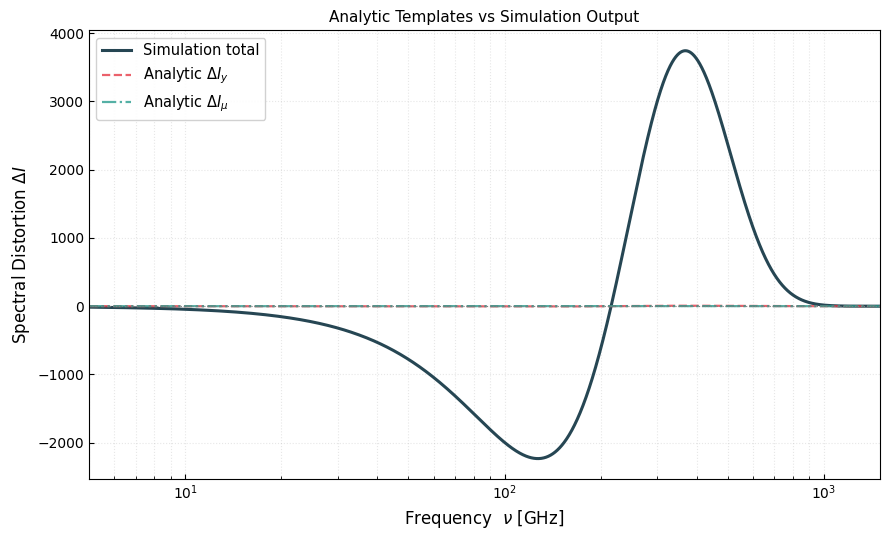

In [ ]:
x_sim  = nu_ds / nu_scale
y_analytic   = x_sim**3 * Ysz(x_sim)
mu_analytic  = x_sim**3 * mudist(x_sim)

# although we have added theanalytic templates, their amplitude is very low as compared to the simulated distortion, so it just appears to be zero; you have to either normalize the functions (preferred) or scale up the analytic templates.

mask = (nu_ds > 5) & (nu_ds < 1500)

fig, ax = plt.subplots(figsize=(9, 5.5))

ax.plot(nu_ds[mask], DI_tot[mask],
        color='#264653', lw=2.2, label='Simulation total')
ax.plot(nu_ds[mask], y_analytic[mask],
        color='#E63946', lw=1.6, ls='--', alpha=0.8,
        label=r'Analytic $\Delta I_y$')
ax.plot(nu_ds[mask], mu_analytic[mask],
        color='#2A9D8F', lw=1.6, ls='-.', alpha=0.8,
        label=r'Analytic $\Delta I_\mu$')

ax.axhline(0, color='gray', lw=0.8, ls=':')
ax.set_xscale('log')
ax.set_xlim(5, 1500)
ax.set_xlabel(r'Frequency  $\nu$ [GHz]', fontsize=12)
ax.set_ylabel(r'Spectral Distortion $\Delta I$', fontsize=12)
ax.set_title(r'Analytic Templates vs Simulation Output', fontsize=11)
ax.legend(fontsize=10.5, framealpha=0.9)
ax.tick_params(direction='in', which='both')
ax.grid(True, which='both', ls=':', alpha=0.3)

fig.tight_layout()
plt.show()

Cumulative Energy Injection $Q(<z)$: Integrate the heating rate from high to low redshift to track the total fractional energy deposited* into the CMB as a function of epoch.  The plateau gives the total energy budget of the decay.

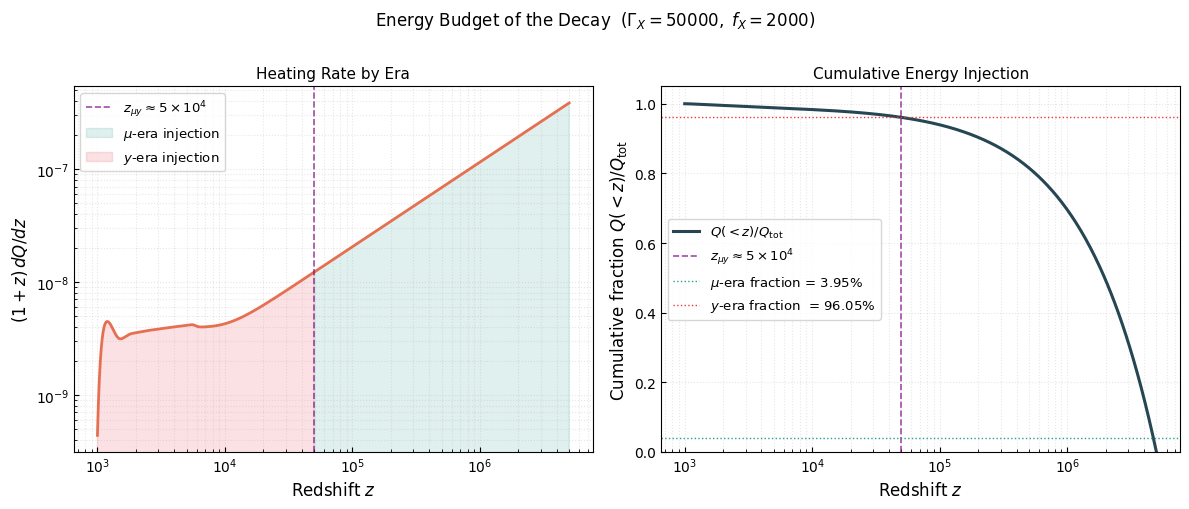

Total integrated Q  : -5.1991e-07  [code units]
μ-era (z > 5e4) frac: 3.95%
y-era (z < 5e4) frac: 96.05%


In [ ]:
# Integrate in decreasing-z order: Q(<z) = ∫_{z}^{z_max} dQdz dz
# dQdz column is (1+z) dQ/dz; strip the (1+z) to get dQ/dz for integration
dQdz_raw = dQdz / (1 + z_hr)     # dQ/dz  (remove the (1+z) prefactor)

# Below is the integration technique: we want to integrate from z_max down to each z, but cumulative_trapezoid integrates in the forward direction. So we reverse the arrays to integrate in the forward direction, then reverse back the result to get Q(<z) in the original order.
# Cumulative integral from z_max down to each z  (flip arrays so z is increasing for trapz)
z_rev    = z_hr[::-1]
dQdz_rev = dQdz_raw[::-1]
Q_cumul  = cumulative_trapezoid(dQdz_rev, z_rev, initial=0)[::-1]   # flip back
Q_cumul  = Q_cumul - Q_cumul[-1]   # set zero at z_max (no injection yet)
Q_total  = Q_cumul[0]              # total energy injected

# Also compute the fraction deposited above z_mu_y ~ 5e4 (mu era) and below (y era)
z_split = 5e4
idx_split = np.searchsorted(z_hr, z_split)
Q_mu_era = Q_cumul[0] - Q_cumul[idx_split]   # injected at z > z_split
Q_y_era  = Q_cumul[idx_split]                 # injected at z < z_split

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left: heating rate
ax1 = axes[0]
ax1.plot(z_hr, dQdz, color='#E76F51', lw=2.0)
ax1.axvline(z_split, color='purple', lw=1.2, ls='--', alpha=0.7,
            label=r'$z_{\mu y} \approx 5\times10^4$')
ax1.fill_between(z_hr[z_hr >= z_split], dQdz[z_hr >= z_split],
                 alpha=0.15, color='#2A9D8F', label=r'$\mu$-era injection')
ax1.fill_between(z_hr[z_hr <  z_split], dQdz[z_hr < z_split],
                 alpha=0.15, color='#E63946', label=r'$y$-era injection')
ax1.set_xscale('log'); ax1.set_yscale('log')
ax1.set_xlabel(r'Redshift $z$', fontsize=12)
ax1.set_ylabel(r'$(1+z)\,dQ/dz$', fontsize=12)
ax1.set_title('Heating Rate by Era', fontsize=11)
ax1.legend(fontsize=9.5); ax1.tick_params(direction='in', which='both')
ax1.grid(True, which='both', ls=':', alpha=0.3)

# Right: cumulative Q
ax2 = axes[1]
ax2.plot(z_hr, np.abs(Q_cumul / Q_total), color='#264653', lw=2.2,
         label=r'$Q(<z)/Q_{\rm tot}$')
ax2.axvline(z_split, color='purple', lw=1.2, ls='--', alpha=0.7,
            label=r'$z_{\mu y} \approx 5\times10^4$')
ax2.axhline(abs(Q_mu_era / Q_total), color='#2A9D8F', lw=1.0, ls=':',
            label=fr'$\mu$-era fraction = {abs(Q_mu_era/Q_total):.2%}')
ax2.axhline(abs(Q_y_era  / Q_total), color='#E63946', lw=1.0, ls=':',
            label=fr'$y$-era fraction  = {abs(Q_y_era /Q_total):.2%}')
ax2.set_xscale('log')
ax2.set_ylim(0, 1.05)
ax2.set_xlabel(r'Redshift $z$', fontsize=12)
ax2.set_ylabel(r'Cumulative fraction $Q(<z)/Q_{\rm tot}$', fontsize=12)
ax2.set_title('Cumulative Energy Injection', fontsize=11)
ax2.legend(fontsize=9.5); ax2.tick_params(direction='in', which='both')
ax2.grid(True, which='both', ls=':', alpha=0.3)

fig.suptitle(r'Energy Budget of the Decay  ($\Gamma_X=50000,\; f_X=2000$)', fontsize=12, y=1.01)
fig.tight_layout()
plt.show()

print(f"Total integrated Q  : {Q_total:.4e}  [code units]")
print(f"μ-era (z > 5e4) frac: {abs(Q_mu_era/Q_total):.2%}")
print(f"y-era (z < 5e4) frac: {abs(Q_y_era /Q_total):.2%}")


Reproducing Fig. 10 of Chluba 2018 

z<1e4: G_th range [-2.778e+00, 4.579e+00]
z~1e4: G_th range [-2.779e+00, 4.579e+00]
z~5e4: G_th range [-2.805e+00, 4.624e+00]
z~1e5: G_th range [-2.763e+00, 4.689e+00]
z~3e5: G_th range [-1.853e+00, 3.953e+00]
z~1e6: G_th range [-8.269e-02, 1.778e-01]
z>1e6: G_th range [-6.830e+00, 1.469e+01]


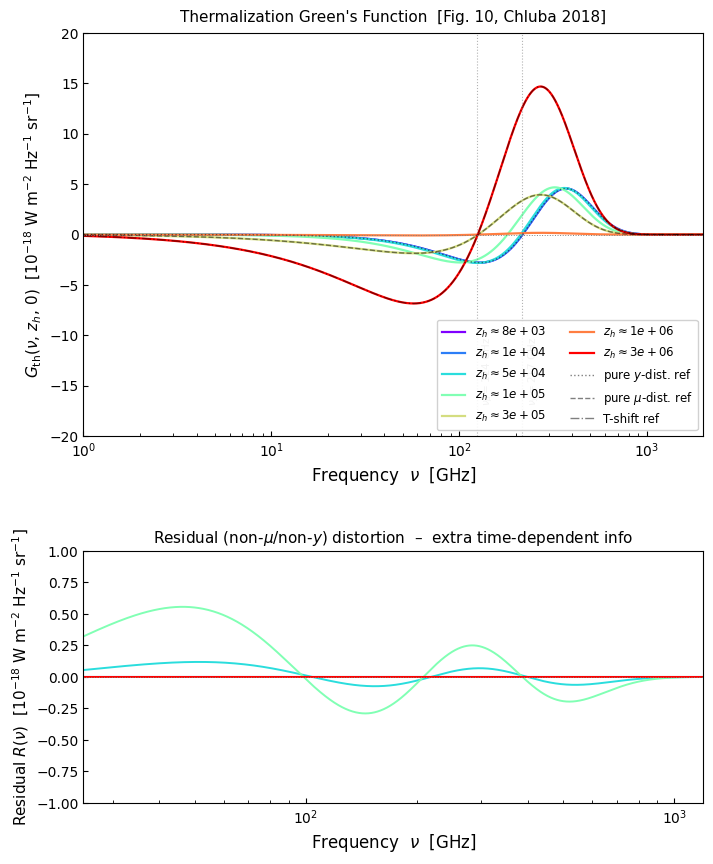


Run              z_h           a_µ           a_y           a_T
------------------------------------------------------------
z<1e4        8.0e+03    7.1962e-16    1.0000e+00    1.1102e-16
z~1e4        1.0e+04    7.6262e-03    9.9996e-01   -2.0194e-03
z~5e4        5.0e+04    6.4993e+00    9.3675e-01   -1.7242e+00
z~1e5        1.0e+05    3.6362e+01    4.7930e-01   -9.6086e+00
z~3e5        3.0e+05    1.0000e+00    5.3684e-18    9.0452e-17
z~1e6        1.0e+06    1.1179e-04   -4.2956e-08    1.2076e-02
z>1e6        3.0e+06    9.6551e-15    0.0000e+00    1.0000e+00


In [ ]:
""" 
GREENS v1.0.3 – PARAMETER SETUP
From your existing working run (Gamma_X=50000 → z_h ≈ 1e5) and the
radiation-domination scaling  Gamma_X ∝ (1+z_h)^2, a suitable sweep is:

    z_h target   |  Gamma_X (approx)  |  distortion type
    -------------|--------------------|-----------------
    1e3          |  5                 |  pure y
    5e3          |  125               |  y
    1e4          |  500               |  y / transition
    5e4          |  12500             |  transition
    1e5          |  50000             |  transition (your existing run)
    3e5          |  450000            |  µ
    1e6          |  5e6               |  µ
    3e6          |  4.5e7             |  near T-shift
    1e7          |  5e8               |  T-shift

Fine-tune each Gamma_X by inspecting the peak of the heating-rate output
and confirming it falls at the intended z_h.

Use f_X = 1 (or any fixed small value) for all runs so the normalisation
is clean and the amplitude scales linearly with f_X.
"""

from scipy.optimize import curve_fit
import glob, os
from scipy.integrate import cumulative_trapezoid
from scipy.interpolate import interp1d

nu_scale = 56.81   # GHz per unit x  (k T0 / h, T0 = 2.726 K)

# ── Conversion: 10^-18 W m^-2 Hz^-1 sr^-1  →  Jy/sr  (1 Jy = 1e-26 W/m²/Hz)
W_PER_JY = 1e-26
SCALE_18  = 1e-18   # code unit used in Fig. 10 top panel

RUNS = {
    # label          : (z_h,    heating_rate_file,            distortion_file)
    "z<1e4"          : (8e3,    f"{filepath}outputs/heating_rate.decay.g5.dat",      f"{filepath}outputs/distortion.decay.g5.dat"),
    "z~1e4"          : (1e4,    f"{filepath}outputs/heating_rate.decay.g500.dat",    f"{filepath}outputs/distortion.decay.g500.dat"),
    "z~5e4"          : (5e4,    f"{filepath}outputs/heating_rate.decay.g12500.dat",  f"{filepath}outputs/distortion.decay.g12500.dat"),
    "z~1e5"          : (1e5,    f"{filepath}outputs/heating_rate.decay.g50000.dat",  f"{filepath}outputs/distortion.decay.g50000.dat"),
    "z~3e5"          : (3e5,    f"{filepath}outputs/heating_rate.decay.g450000.dat", f"{filepath}outputs/distortion.decay.g450000.dat"),
    "z~1e6"          : (1e6,    f"{filepath}outputs/heating_rate.decay.g5e6.dat",    f"{filepath}outputs/distortion.decay.g5e6.dat"),
    "z>1e6"          : (3e6,    f"{filepath}outputs/heating_rate.decay.g4.5e7.dat",  f"{filepath}outputs/distortion.decay.g4.5e7.dat"),
}

# Colour map matching Fig. 10 (blue→red as z_h increases)
CMAP = plt.cm.rainbow
N    = len(RUNS)


#     G_th(ν, z_h, 0) = DI_tot / (ΔQ/ρ_γ)
#     ΔQ/ρ_γ = ∫ dQ/dz dz  (integrate the heating-rate file)
def load_run(hr_file, ds_file):

    hr    = np.loadtxt(hr_file, comments="#")
    z_hr  = hr[:, 0]
    dQdz_raw = hr[:, 1] / (1 + z_hr)      # strip the (1+z) prefactor → dQ/dz
    # integrate from z_max down to 0; the total is the area under the curve
    DeltaQ_over_rho = np.abs(np.trapezoid(dQdz_raw, z_hr))  # positive definite

    ds      = np.loadtxt(ds_file, comments="#")
    nu_GHz  = ds[:, 0]
    x_vals  = ds[:, 1]
    # Greens output is in Jy/sr; convert to 1e-18 W m^-2 Hz^-1 sr^-1
    JY_TO_18 = W_PER_JY / SCALE_18   # = 1e-26 / 1e-18 = 1e-8
    DI_y    = ds[:, 2] * JY_TO_18
    DI_T    = ds[:, 3] * JY_TO_18
    DI_prim = ds[:, 4] * JY_TO_18
    DI_tot  = ds[:, 5] * JY_TO_18

    # normalise to unit energy injection
    G_th = DI_tot / DeltaQ_over_rho

    return nu_GHz, x_vals, G_th, DI_y, DI_T, DI_prim, DI_tot, DeltaQ_over_rho

nu_base_y,  _, base_y,  *_ = load_run(*RUNS["z<1e4"][1:])
nu_base_mu, _, base_mu, *_ = load_run(*RUNS["z~3e5"][1:])
nu_base_T,  _, base_T,  *_ = load_run(*RUNS["z>1e6"][1:])

#     COMPUTE RESIDUAL R(ν):
#     Fit G_th as a_mu * M*(x) + a_y * Y_SZ(x) + a_T * G(x)
#     then R(ν) = G_th - best-fit (µ + y + T-shift)

def fit_and_residual(nu_GHz, x_vals, G_th):
    mask = (nu_GHz > 30) & (nu_GHz < 1000) & np.isfinite(G_th)
    nu_fit = nu_GHz[mask]

    # Interpolate base templates onto the current run's frequency grid
    i_mu = interp1d(nu_base_mu, base_mu, bounds_error=False, fill_value=0.0)
    i_y  = interp1d(nu_base_y,  base_y,  bounds_error=False, fill_value=0.0)
    i_T  = interp1d(nu_base_T,  base_T,  bounds_error=False, fill_value=0.0)

    A = np.vstack([i_mu(nu_fit), i_y(nu_fit), i_T(nu_fit)]).T
    b = G_th[mask]

    coeffs, _, _, _ = np.linalg.lstsq(A, b, rcond=1e-10)
    a_mu, a_y, a_T = coeffs

    best_fit = a_mu * i_mu(nu_GHz) + a_y * i_y(nu_GHz) + a_T * i_T(nu_GHz)
    residual  = G_th - best_fit
    return residual, a_mu, a_y, a_T


fig, axes = plt.subplots(2, 1, figsize=(8, 10),
                         gridspec_kw={"height_ratios": [1.6, 1], "hspace": 0.35})
ax_top, ax_bot = axes

colors = [CMAP(i / (N - 1)) for i in range(N)]

for label, (z_h, hr_file, ds_file) in RUNS.items():
    if os.path.exists(hr_file) and os.path.exists(ds_file):
        nu_GHz, x_vals, G_th, *_ = load_run(hr_file, ds_file)
        print(f"{label}: G_th range [{G_th.min():.3e}, {G_th.max():.3e}]")

for idx, (label, (z_h, hr_file, ds_file)) in enumerate(RUNS.items()):
    if not (os.path.exists(hr_file) and os.path.exists(ds_file)):
        print(f"[skip] files not found for {label}: {hr_file}, {ds_file}")
        continue

    nu_GHz, x_vals, G_th, DI_y, DI_T, DI_prim, DI_tot, DQ = load_run(hr_file, ds_file)

    # --- top panel ---
    mask_plot = (nu_GHz > 1) & (nu_GHz < 2000)
    ax_top.plot(nu_GHz[mask_plot], G_th[mask_plot],
                color=colors[idx], lw=1.6,
                label=fr"$z_h \approx {z_h:.0e}$")

    # --- bottom panel ---
    try:
        R, a_mu, a_y, a_T = fit_and_residual(nu_GHz, x_vals, G_th)
        mask_res = (nu_GHz > 25) & (nu_GHz < 1200)
        ax_bot.plot(nu_GHz[mask_res], R[mask_res],
                    color=colors[idx], lw=1.4)
    except Exception as e:
        print(f"[residual] fit failed for {label}: {e}")

ax_top.plot(nu_base_y,  base_y,  color="black", lw=1.0, ls=":",
            alpha=0.5, label=r"pure $y$-dist. ref")
ax_top.plot(nu_base_mu, base_mu, color="black", lw=1.0, ls="--",
            alpha=0.5, label=r"pure $\mu$-dist. ref")
ax_top.plot(nu_base_T,  base_T,  color="black", lw=1.0, ls="-.",
            alpha=0.5, label=r"T-shift ref")

# ── Top panel formatting ─────────────────────────────────────────────────────
ax_top.axhline(0, color="gray", lw=0.7, ls=":")
ax_top.set_xscale("log")
ax_top.set_xlim(1, 2000)
ax_top.set_ylim(-20, 20)
ax_top.set_xlabel(r"Frequency  $\nu$  [GHz]", fontsize=12)
ax_top.set_ylabel(r"$G_{\rm th}(\nu,\,z_h,\,0)$  [$10^{-18}$ W m$^{-2}$ Hz$^{-1}$ sr$^{-1}$]",
                  fontsize=11)
ax_top.set_title(
    r"Thermalization Green's Function  [Fig. 10, Chluba 2018]",
    fontsize=11, pad=8)
ax_top.legend(fontsize=8.5, ncol=2, framealpha=0.9, loc="lower right")
ax_top.tick_params(direction="in", which="both")

# Vertical lines marking era boundaries
for zv, lbl in [(217, r"$\nu_{y}=217$ GHz"), (124, r"$\nu_{\mu}=124$ GHz")]:
    ax_top.axvline(zv, color="gray", lw=0.8, ls=":", alpha=0.6)
    ax_top.text(zv * 1.05, ax_top.get_ylim()[0] * 0.85, lbl,
                fontsize=7.5, color="gray", rotation=90, va="bottom")

# ── Bottom panel formatting ───────────────────────────────────────────────────
ax_bot.axhline(0, color="gray", lw=0.7, ls=":")
ax_bot.set_xscale("log")
ax_bot.set_xlim(25, 1200)
ax_bot.set_ylim(-1, 1)
ax_bot.set_xlabel(r"Frequency  $\nu$  [GHz]", fontsize=12)
ax_bot.set_ylabel(r"Residual $R(\nu)$  [$10^{-18}$ W m$^{-2}$ Hz$^{-1}$ sr$^{-1}$]",
                  fontsize=11)
ax_bot.set_title(
    r"Residual (non-$\mu$/non-$y$) distortion  –  extra time-dependent info",
    fontsize=11)
ax_bot.tick_params(direction="in", which="both")

fig.subplots_adjust(hspace=0.35)
plt.show()


# print µ, y, T-shift amplitudes per run
print(f"\n{'Run':<10}  {'z_h':>8}  {'a_µ':>12}  {'a_y':>12}  {'a_T':>12}")
print("-" * 60)
for label, (z_h, hr_file, ds_file) in RUNS.items():
    if not (os.path.exists(hr_file) and os.path.exists(ds_file)):
        continue
    nu_GHz, x_vals, G_th, *_ = load_run(hr_file, ds_file)
    _, a_mu, a_y, a_T = fit_and_residual(nu_GHz, x_vals, G_th)
    print(f"{label:<10}  {z_h:>8.1e}  {a_mu:>12.4e}  {a_y:>12.4e}  {a_T:>12.4e}")

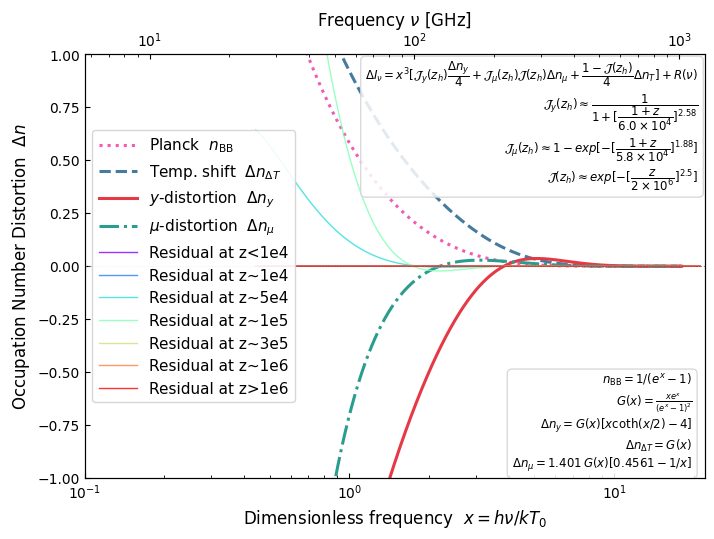

In [ ]:
y_occ  = Ysz(x)
dT_occ = tempshift(x)
mu_occ = mudist(x)
bbdspec_occ = bbdspec(x)

# --- Plot ---
fig, ax = plt.subplots(figsize=(8, 5.5))

c_y  = '#E63946'   # red
c_dT = '#457B9D'   # blue
c_mu = '#2A9D8F'   # teal
c_bbdspec = '#F15BB5'  # pink
lw = 2.2

# Plot the curves
ax.plot(x, bbdspec_occ, color=c_bbdspec, lw=lw, ls=':', label=r'Planck  $n_{\rm BB}$')
ax.plot(x, dT_occ, color=c_dT, lw=lw, ls='--', label=r'Temp. shift  $\Delta n_{\Delta T}$')
ax.plot(x, y_occ,  color=c_y,  lw=lw, ls='-',  label=r'$y$-distortion  $\Delta n_y$')
ax.plot(x, mu_occ, color=c_mu, lw=lw, ls='-.',  label=r'$\mu$-distortion  $\Delta n_\mu$')

for idx, (label, (z_h, hr_file, ds_file)) in enumerate(RUNS.items()):
    if not (os.path.exists(hr_file) and os.path.exists(ds_file)):
        continue
    nu_GHz_r, x_vals_r, G_th_r, *_ = load_run(hr_file, ds_file)   # Bug 2 fix: load each run
    try:
        R, *_ = fit_and_residual(nu_GHz_r, x_vals_r, G_th_r)
        mask_res = (nu_GHz_r > 25) & (nu_GHz_r < 1200)
        x_res = nu_GHz_r[mask_res] / nu_scale    # Bug 1 fix: convert GHz → x
        ax.plot(x_res, R[mask_res]/x_res**3,  # scale by x^3 to match occupation number units
                lw=1.0, ls='-', alpha=0.8, color=colors[idx], label=f'Residual at {label}')
    except Exception as e:
        print(f"[residual] fit failed for {label}: {e}")


# Zero line
ax.axhline(0.0, color='gray', lw=0.8, ls=':')


# Second x-axis in GHz
ax2 = ax.twiny()
ax2.set_xlim(ax.get_xlim()[0] * nu_scale, ax.get_xlim()[1] * nu_scale)
ax2.set_xlabel(r'Frequency $\nu$ [GHz]', fontsize=12)
ax2.xaxis.set_major_locator(ticker.MultipleLocator(100))
ax2.xaxis.set_minor_locator(ticker.MultipleLocator(50))
ax2.tick_params(direction='in', which='both')

# Formatting 
ax.set_xscale('log')
ax.set_xlim(0.1, 22)
ax2.set_xscale('log')
ax2.set_xlim(ax.get_xlim()[0] * nu_scale, ax.get_xlim()[1] * nu_scale)
ax.set_ylim(-1, 1) # Adjusted boundaries for better dynamic range without x^3

ax.set_xlabel(r'Dimensionless frequency  $x = h\nu/kT_0$', fontsize=12)
ax.set_ylabel(r'Occupation Number Distortion  $\Delta n$', fontsize=12)
# ax.set_title(r'CMB Occupation Number Distortions', fontsize=11, pad=30)

ax.xaxis.set_major_locator(ticker.LogLocator(base=10.0))
ax.xaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs=[2,3,4,5,6,7,8,9]))
ax2.xaxis.set_major_locator(ticker.LogLocator(base=10.0))
ax2.xaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs=[2,3,4,5,6,7,8,9]))
ax.tick_params(direction='in', which='both', top=False)

ax.legend(loc='center left', fontsize=11, framealpha=0.9, edgecolor='lightgray', handlelength=2.5)

# Annotation Box
info = (
    r'$n_{\rm BB} = 1 / (e^x - 1)$' + '\n'
    r'$G(x)=\frac{xe^x}{(e^x-1)^2}$' + '\n'
    r'$\Delta n_y = G(x)[x\coth(x/2)-4]$' + '\n'
    r'$\Delta n_{\Delta T} = G(x)$' + '\n'
    r'$\Delta n_\mu = 1.401\,G(x)[0.4561-1/x]$' 
)

ax.text(0.98, 0.01, info, transform=ax.transAxes, fontsize=8.5,
        va='bottom', ha='right', family='monospace',
        bbox=dict(boxstyle='round,pad=0.4', fc='white', alpha=0.85, ec='lightgray'))

more_info = (
    r"$\Delta I_\nu = x^3 [\mathcal{J}_y (z_h) \dfrac{\Delta n_y}{4} + \mathcal{J}_\mu (z_h) \mathcal{J} (z_h) \Delta n_\mu + \dfrac{1-\mathcal{J} (z_h)}{4} \Delta n_T ]+ R(\nu)$" + '\n'
    r"$\mathcal{J}_y (z_h) \approx \dfrac{1}{1+[\dfrac{1+z}{6.0 \times 10^4}]^{2.58}}$" + '\n'
    r"$\mathcal{J}_\mu (z_h) \approx 1- exp[-[\dfrac{1+z}{5.8 \times 10^4}]^{1.88}]$" + '\n'
    r"$\mathcal{J} (z_h) \approx exp[-[\dfrac{z}{2 \times 10^6}]^{2.5}]$"
)

ax.text(0.99, 0.99, more_info, transform=ax.transAxes, fontsize=8.5,
        va='top', ha='right', family='monospace',
        bbox=dict(boxstyle='round,pad=0.4', fc='white', alpha=0.85, ec='lightgray'))

fig.subplots_adjust(hspace=0.35)
plt.show()

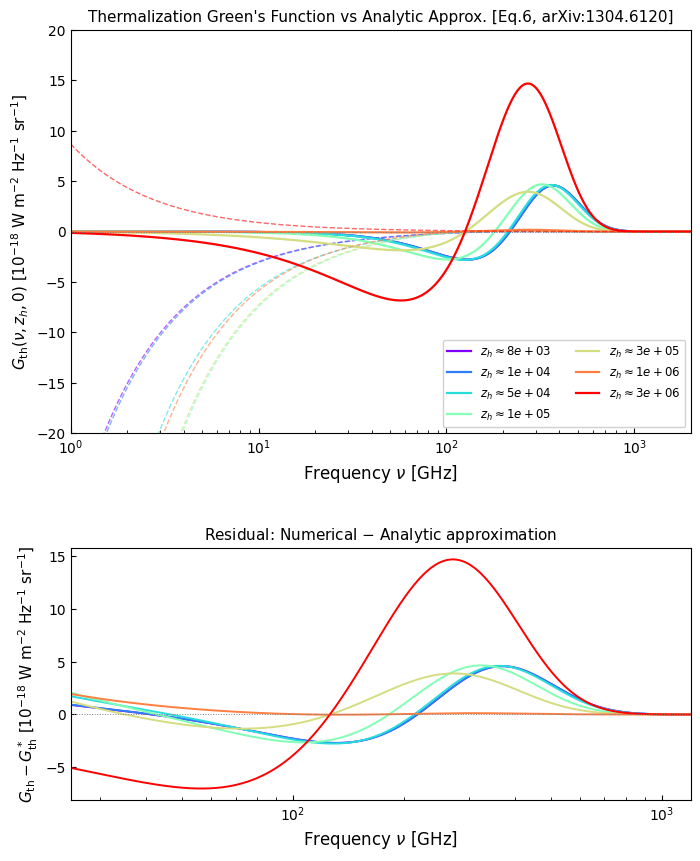

In [ ]:
# ── Analytic approximation for G*_th from Eq.(6) of Chluba 2013 (arXiv:1304.6120) ──

def J_thermalization(z):
    """Distortion visibility function (Danese & de Zotti 1982; Hu & Silk 1993)"""
    z_mu = 1.98e6   # thermalization redshift
    return np.exp(-(z / z_mu)**2.5)

def J_y(z):
    """y-distortion weight (Eq.5 of 1304.6120)"""
    return 1.0 / (1.0 + ((1 + z) / 6.0e4)**2.58)

def J_mu(z):
    """µ-distortion weight (Eq.5 of 1304.6120)"""
    return 1.0 - np.exp(-((1 + z) / 5.8e4)**1.88)

def G_star_th(nu_GHz, z_h):
    """
    Analytic approximation for the thermalization Green's function,
    Eq.(6) of arXiv:1304.6120.
    Returns G*_th in units of 10^-18 W m^-2 Hz^-1 sr^-1.
    
    Note: M(nu), YSZ(nu), G(nu) are the spectral shape functions.
    The factor 2hnu^3/c^2 * (x e^x)/(e^x-1)^2 gives the G(x) shape
    in physical units. We normalise relative to the same unit system
    as the numerical Green's function.
    """
    x = nu_GHz / nu_scale  # dimensionless frequency

    # Spectral shape functions (in dimensionless units, as in your notebook)
    beta   = 3 * 1.20206 / 1.64493   # 3*zeta(3)/zeta(2) ≈ 2.1923
    G_x    = x * np.exp(x) / (np.exp(x) - 1)**2             # G(x)
    YSZ_x  = G_x * (x / np.tanh(x / 2) - 4)                 # Y_SZ(x)
    M_x    = G_x * (x / beta - 1)                            # M(x)  (µ-shape)

    Jth = J_thermalization(z_h)
    Jy  = J_y(z_h)
    Jm  = J_mu(z_h)

    return 1.401 * Jm * Jth * M_x  +  (Jy / 4) * YSZ_x  +  ((1 - Jth) / 4) * G_x


# ── Overlay on the existing figure ───────────────────────────────────────────
nu_analytic = np.logspace(np.log10(1), np.log10(2000), 600)

fig, axes = plt.subplots(2, 1, figsize=(8, 10),
                         gridspec_kw={"height_ratios": [1.6, 1], "hspace": 0.35})
ax_top, ax_bot = axes
colors = [CMAP(i / (N - 1)) for i in range(N)]

# Re-plot numerical curves
for idx, (label, (z_h, hr_file, ds_file)) in enumerate(RUNS.items()):
    if not (os.path.exists(hr_file) and os.path.exists(ds_file)):
        continue
    nu_GHz, x_vals, G_th, *_ = load_run(hr_file, ds_file)
    mask_plot = (nu_GHz > 1) & (nu_GHz < 2000)
    ax_top.plot(nu_GHz[mask_plot], G_th[mask_plot],
                color=colors[idx], lw=1.6, label=fr"$z_h \approx {z_h:.0e}$")

    # Analytic approximation for this z_h
    G_approx = G_star_th(nu_analytic, z_h)
    ax_top.plot(nu_analytic, G_approx,
                color=colors[idx], lw=1.0, ls='--', alpha=0.6)

    # Residual vs analytic approximation (bottom panel)
    G_approx_on_grid = G_star_th(nu_GHz, z_h)
    residual_analytic = G_th - G_approx_on_grid
    mask_res = (nu_GHz > 25) & (nu_GHz < 1200)
    ax_bot.plot(nu_GHz[mask_res], residual_analytic[mask_res],
                color=colors[idx], lw=1.4)

ax_top.axhline(0, color="gray", lw=0.7, ls=":")
ax_top.set_xscale("log"); ax_top.set_xlim(1, 2000); ax_top.set_ylim(-1e2, 1e2)
ax_top.set_xlabel(r"Frequency $\nu$ [GHz]", fontsize=12)
ax_top.set_ylim(-20, 20)
ax_top.set_ylabel(r"$G_{\rm th}(\nu,z_h,0)$ [$10^{-18}$ W m$^{-2}$ Hz$^{-1}$ sr$^{-1}$]", fontsize=11)
ax_top.set_title(r"Thermalization Green's Function vs Analytic Approx. [Eq.6, arXiv:1304.6120]", fontsize=11)
ax_top.legend(fontsize=8.5, ncol=2, framealpha=0.9, loc="lower right")
ax_top.tick_params(direction="in", which="both")
ax_top.plot([], [], 'k-',  lw=1.6, label='Numerical $G_{\\rm th}$')
ax_top.plot([], [], 'k--', lw=1.0, alpha=0.6, label=r'Analytic $G^*_{\rm th}$ [Eq.6]')

ax_bot.axhline(0, color="gray", lw=0.7, ls=":")
ax_bot.set_xscale("log"); ax_bot.set_xlim(25, 1200)
ax_bot.set_xlabel(r"Frequency $\nu$ [GHz]", fontsize=12)
ax_bot.set_ylabel(r"$G_{\rm th} - G^*_{\rm th}$ [$10^{-18}$ W m$^{-2}$ Hz$^{-1}$ sr$^{-1}$]", fontsize=11)
ax_bot.set_title(r"Residual: Numerical $-$ Analytic approximation", fontsize=11)
ax_bot.tick_params(direction="in", which="both")

fig.subplots_adjust(hspace=0.35)
plt.show()

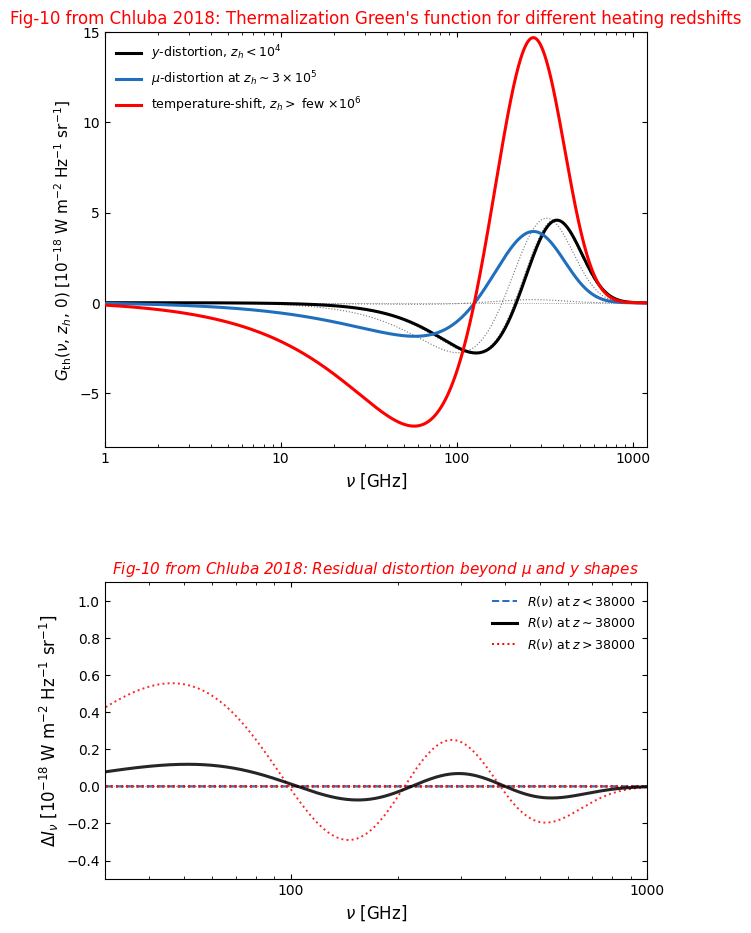

In [ ]:
# ── Figure matching Chluba 2018 Fig. 10 style ─────────────────────────────────
# Colour scheme: dotted black for intermediate runs; bold coloured for the
# three reference cases (y=black, µ=blue, T-shift=red).
# Bottom panel: residuals colour-coded by era (z<z_split=blue dashed,
#               z~z_split=black solid, z>z_split=red dotted).

Z_SPLIT = 3.8e4   # transition redshift separating y / hybrid / µ eras

fig, axes = plt.subplots(2, 1, figsize=(7, 11),
                          gridspec_kw={"height_ratios": [1.4, 1], "hspace": 0.38})
ax_top, ax_bot = axes

# ── Identify the three "hero" runs ───────────────────────────────────────────
HERO = {
    "z<1e4"  : ("black",   "-",  2.2, r"$y$-distortion, $z_h < 10^4$"),
    "z~3e5"  : ("#1f6fbe", "-",  2.2, r"$\mu$-distortion at $z_h \sim 3\times10^5$"),
    "z>1e6"  : ("red",     "-",  2.2, r"temperature-shift, $z_h >$ few $\times10^6$"),
}

for idx, (label, (z_h, hr_file, ds_file)) in enumerate(RUNS.items()):
    if not (os.path.exists(hr_file) and os.path.exists(ds_file)):
        continue

    nu_GHz, x_vals, G_th, *_ = load_run(hr_file, ds_file)
    mask_plot = (nu_GHz > 1) & (nu_GHz < 1200)

    # ── Top panel ────────────────────────────────────────────────────────────
    if label in HERO:
        col, ls, lw, leg = HERO[label]
        ax_top.plot(nu_GHz[mask_plot], G_th[mask_plot],
                    color=col, lw=lw, ls=ls, zorder=4, label=leg)
    else:
        ax_top.plot(nu_GHz[mask_plot], G_th[mask_plot],
                    color="black", lw=0.8, ls=":", alpha=0.55, zorder=2)

    # ── Bottom panel – residuals colour-coded by era ──────────────────────────
    try:
        R, *_ = fit_and_residual(nu_GHz, x_vals, G_th)
        mask_res = (nu_GHz > 30) & (nu_GHz < 1000)

        if z_h < Z_SPLIT:
            col_r, ls_r, lw_r, zo = "#1f6fbe", "--", 1.4, 2   # blue dashed
        elif z_h <= Z_SPLIT * 1.5:
            col_r, ls_r, lw_r, zo = "black",   "-",  2.2, 4   # black solid
        else:
            col_r, ls_r, lw_r, zo = "red",     ":", 1.4, 2   # red dotted

        ax_bot.plot(nu_GHz[mask_res], R[mask_res],
                    color=col_r, lw=lw_r, ls=ls_r, alpha=0.85, zorder=zo)
    except Exception as e:
        print(f"[residual] {label}: {e}")

# ── Top panel: annotations ────────────────────────────────────────────────────
# ax_top.annotate("full thermalization",
#                 xy=(130, 3.2), xytext=(18, 4.2),
#                 fontsize=9, color="red", fontstyle="italic",
#                 arrowprops=dict(arrowstyle="-", color="red", lw=1.0))
# ax_top.annotate("high-z SZ effect",
#                 xy=(500, 1.5), xytext=(320, -6),
#                 fontsize=9, color="red", fontstyle="italic",
#                 arrowprops=dict(arrowstyle="-", color="red", lw=1.0))
# ax_top.annotate("hybrid distortion probes\ntime-dependence of\nenergy-release history",
#                 xy=(20, -1.3), xytext=(2, -2.3),
#                 fontsize=8.5, color="red", fontstyle="italic",
#                 arrowprops=dict(arrowstyle="-", color="red", lw=1.0))

# ── Top panel: formatting ─────────────────────────────────────────────────────
ax_top.axhline(0, color="gray", lw=0.6, ls=":")
ax_top.set_xscale("log")
ax_top.set_xlim(1, 1200)
ax_top.set_ylim(-8, 15)
ax_top.set_xlabel(r"$\nu$ [GHz]", fontsize=12)
ax_top.set_ylabel(r"$G_{\rm th}(\nu,\,z_h,\,0)$ [$10^{-18}$ W m$^{-2}$ Hz$^{-1}$ sr$^{-1}$]",
                   fontsize=11)
ax_top.set_title(r"Fig-10 from Chluba 2018: Thermalization Green's function for different heating redshifts",
                  fontsize=12, color="red", pad=6)
# fallback if LaTeX not available:
# ax_top.set_title("Intensity signal for different heating redshifts",
#                   fontsize=12, color="red", fontweight="bold", pad=6)

ax_top.legend(fontsize=9, framealpha=0.0, loc="upper left",
              handlelength=2.0, edgecolor="none")
ax_top.tick_params(direction="in", which="both", top=True, right=True)
ax_top.xaxis.set_major_formatter(ticker.FuncFormatter(
    lambda v, _: f"{int(v)}" if v >= 1 else f"{v}"))

# ── Bottom panel: legend entries ──────────────────────────────────────────────
ax_bot.plot([], [], color="#1f6fbe", lw=1.4, ls="--",
            label=r"$R(\nu)$ at $z < 38000$")
ax_bot.plot([], [], color="black",   lw=2.2, ls="-",
            label=r"$R(\nu)$ at $z \sim 38000$")
ax_bot.plot([], [], color="red",     lw=1.4, ls=":",
            label=r"$R(\nu)$ at $z > 38000$")

# ── Bottom panel: formatting ───────────────────────────────────────────────────
ax_bot.axhline(0, color="gray", lw=0.6, ls=":")
ax_bot.set_xscale("log")
ax_bot.set_xlim(30, 1000)
ax_bot.set_ylim(-0.5, 1.1)
ax_bot.set_xlabel(r"$\nu$ [GHz]", fontsize=12)
ax_bot.set_ylabel(r"$\Delta I_\nu$ [$10^{-18}$ W m$^{-2}$ Hz$^{-1}$ sr$^{-1}$]", fontsize=12)
ax_bot.set_title(r"Fig-10 from Chluba 2018: Residual distortion beyond $\mu$ and $y$ shapes",
                  fontsize=11, color="red", fontstyle="italic")
ax_bot.legend(fontsize=9, framealpha=0.0, loc="upper right", edgecolor="none")
ax_bot.tick_params(direction="in", which="both", top=True, right=True)
ax_bot.xaxis.set_major_formatter(ticker.FuncFormatter(
    lambda v, _: f"{int(v)}"))

fig.subplots_adjust(hspace=0.35)
plt.show()

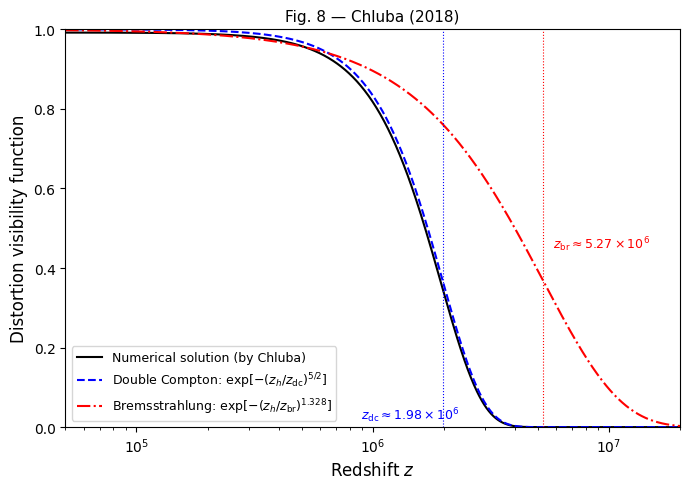

In [ ]:
z = np.logspace(np.log10(1e4), np.log10(2e7), 1000)

J_DC  = np.exp(-(z / 1.98e6)**2.5)
J_BR  = np.exp(-(z / 5.27e6)**1.328)
J_num = 0.992 * np.exp(-(z / 1.98e6)**2.5) * (1 - 0.048*(z/1.98e6)**2.07)   # thermalization visibility function with parameters taken from Baker 2026

fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(z, J_num, 'k-',    lw=1.5, label=r'Numerical solution (by Chluba)')
ax.plot(z, J_DC,  'b--',   lw=1.5, label=r'Double Compton: $\exp\![-(z_h/z_{\rm dc})^{5/2}]$')
ax.plot(z, J_BR,  'r-.',   lw=1.5, label=r'Bremsstrahlung: $\exp\![-(z_h/z_{\rm br})^{1.328}]$')

ax.axvline(1.98e6, color='b', lw=0.8, ls=':')
ax.axvline(5.27e6, color='r', lw=0.8, ls=':')
ax.text(1.98e6*0.45, 0.02, r'$z_{\rm dc}\approx 1.98\times10^6$', color='b', fontsize=9)
ax.text(5.27e6*1.10, 0.45, r'$z_{\rm br}\approx 5.27\times10^6$', color='r', fontsize=9)

ax.set_xscale('log')
ax.set_xlim(5e4, 2e7)
ax.set_ylim(0, 1)
ax.set_xlabel(r'Redshift $z$', fontsize=12)
ax.set_ylabel(r'Distortion visibility function', fontsize=12)
ax.legend(fontsize=9, loc='lower left')
ax.set_title('Fig. 8 — Chluba (2018)', fontsize=11)
plt.tight_layout()
plt.show()

# Inspecting spectroxide

Getting started (comment-ed to avoid wasting time while running the entire notebook)

In [ ]:
# from spectroxide.solver import run_sweep, solve
# import json

# # ── Single-burst injection at z = 2e5 (mu-era) ──────────────────────────
# result = run_sweep(
#     delta_rho=1e-5,
#     z_injections=[2e5],   # list of redshifts, not a dict
#     z_start=3e5,
#     z_end=1e3,
# )
# r = result["results"][0]
# print(f"mu = {r['pde_mu']:.3e}, y = {r['pde_y']:.3e}")
# x, delta_n = np.array(r["x"]), np.array(r["delta_n"])

# # ── Decaying particle ────────────────────────────────────────────────────
# result = solve(
#     injection={"type": "decaying_particle", "f_x": 1.3e-6, "gamma_x": 1e5},
#     z_start=5e6, z_end=200,
# )

# # # ── DM annihilation (s-wave) ─────────────────────────────────────────────
# # result = solve(
# #     injection={"type": "annihilating_dm", "f_ann": 1e-22},
# #     z_start=5e6, z_end=1e3,
# # )

# # # ── Dark photon oscillation ──────────────────────────────────────────────
# # result = solve(
# #     injection={"type": "dark_photon_resonance", "epsilon": 1e-7, "m_ev": 1e-5},
# #     z_end=1e3,
# # )

In [ ]:
# output_path = "/home/batman/Documents/Work/CMBSD/spectroxide/results/spectroxide_result.json"
# with open(output_path, "w") as f:
#     json.dump(result, f)
# print(f"Saved to {output_path}")

# # ── Extract ───────────────────────────────────────────────────────────────
# r = result["results"][0]
# x       = np.array(r["x"])        # dimensionless frequency hν/kT
# delta_n = np.array(r["delta_n"])  # spectral distortion Δn
# mu      = r["pde_mu"]
# y       = r["pde_y"]
# intensity = x**3 * delta_n  # convert to intensity units (Iν ∝ x^3 Δn)

# # ── Plot ──────────────────────────────────────────────────────────────────
# fig, ax = plt.subplots(figsize=(8, 4))
# ax.plot(x, intensity, color="blue", lw=1.8, label=r"$\Delta I_\nu = x^3 \Delta n$")
# ax.axhline(0, color="gray", lw=0.5)
# ax.set_xlabel("x = hν / kT")
# ax.set_ylabel("ΔI_ν  (intensity of spectral distortion)")
# ax.set_title(f"Single burst  |  μ = {mu:.3e},  y = {y:.3e}")
# ax.set_xlim(0, 15)
# ax.set_ylim(-2e-5, 2e-5)
# plt.tight_layout()
# plt.show()

Fig-9 of Chluba 2018

[sim] 1/1  z_end = 6.7e+04 ...  

/home/batman/Documents/Work/CMBSD/spectroxide/python/spectroxide/solver.py:724: RuntimeWarning: spectroxide: Progress: z=2.0e5 step=100000 ρ_e=1.000000 ρ_eq=1.000000
  return _run_rust_binary(cmd, cwd=root, timeout=timeout)



    x:      [1.000e-05, 6.000e+01]  npts=4000
    delta_n:[-1.309e-04, 1.144e-01]
      x=1.000e-05   delta_n=1.144e-01
      x=4.806e-03   delta_n=-1.356e-05
      x=4.160e+00   delta_n=2.523e-08
      x=2.274e+01   delta_n=3.305e-15
      x=4.137e+01   delta_n=5.067e-23
      x=6.000e+01   delta_n=3.511e-41
    mu = 5.739e-07   y = 6.710e-07
[sim] Done. Saved 1 snapshots → fig9_data.json


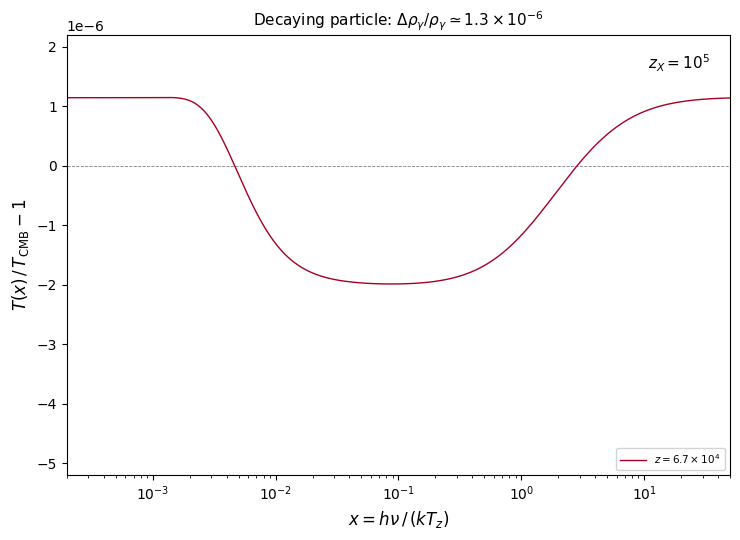

In [ ]:
import argparse
import json
import math
import os
import matplotlib.ticker as mticker
import matplotlib.pyplot as plt
import numpy as np

# ---------------------------------------------------------------------------
# Snapshot redshifts read from the Fig. 9 legend (15 values)
# ---------------------------------------------------------------------------
SNAPSHOT_Z = [
    # 8.8e5, 5.2e5, 3.1e5, 1.9e5, 1.1e5,   # blue family  (z > z_X)
    6.7e4, 
    # 4.0e4, 2.4e4, 1.4e4,            # red family   (z ~ z_X)
    # 8.7e3, 5.2e3, 3.1e3, 1.9e3, 1.1e3,    # purple family (y-era)
    # 200,                                    # black – final snapshot
]

# Injection parameters (from Fig. 9 caption)
F_X      = 1.3e-6   # Δρ_γ/ρ_γ total energy fraction released
GAMMA_X  = 1e5      # dimensionless injection width (narrow burst)
Z_START  = 5.0e6    # must be safely above the highest snapshot (8.8e5)

# ---------------------------------------------------------------------------
# 1. Run the PDE solver — one call per snapshot redshift
# ---------------------------------------------------------------------------

def run_simulation(output_json="fig9_data.json"):
    from spectroxide.solver import solve

    injection = {
        "type":    "single_burst",
        "z_h": 1e5
    }

    snapshots = []
    n = len(SNAPSHOT_Z)
    for i, z_snap in enumerate(SNAPSHOT_Z):
        print(f"[sim] {i+1}/{n}  z_end = {z_snap:.3g} ...", end="  ", flush=True)
        result = solve(
            injection = injection,
            z_start   = Z_START,
            delta_rho = F_X,      
            z_end     = z_snap,
            # DO NOT set x_min below 1e-3 — breaks PDE numerics
            x_min     = 5e-3,    # safe lower bound (reference starts at 2e-4
                                 # but PDE accuracy holds from ~5e-3)
            x_max     = 50.0,    # catches the y-distortion rise at high x
            n_x       = 600,     # slightly more points over the wider range
        )

        # ── DIAGNOSTIC: verify grid and data are correct ──────────────────
        print(f"\n    x:      [{result.x.min():.3e}, {result.x.max():.3e}]  "
              f"npts={len(result.x)}")
        print(f"    delta_n:[{result.delta_n.min():.3e}, {result.delta_n.max():.3e}]")
        # Sample 6 points across the range
        for j in np.linspace(0, len(result.x)-1, 6, dtype=int):
            print(f"      x={result.x[j]:.3e}   delta_n={result.delta_n[j]:.3e}")
        # ──────────────────────────────────────────────────────────────────

        snapshots.append({
            "z":       z_snap,
            "x":       result.x.tolist(),
            "delta_n": result.delta_n.tolist(),
            "mu":      result.mu,
            "y":       result.y,
        })
        print(f"    mu = {result.mu:.3e}   y = {result.y:.3e}")

    with open(output_json, "w") as fh:
        json.dump({"snapshots": snapshots}, fh, indent=2)
    print(f"[sim] Done. Saved {len(snapshots)} snapshots → {output_json}")


def extend_to_low_x(x_arr, dTb_arr, x_full):
    """
    Below x ~ 5e-3, δT/T flattens to the μ-plateau value.
    Extrapolate leftward using the mean of the 10 leftmost points.
    """
    plateau = np.mean(dTb_arr[:10])
    x_lo    = x_full[x_full < x_arr.min()]
    dTb_lo  = np.full_like(x_lo, plateau)
    return (np.concatenate([x_lo, x_arr]),
            np.concatenate([dTb_lo, dTb_arr]))


# ---------------------------------------------------------------------------
# 2. Load saved data
# ---------------------------------------------------------------------------

def load_data(path):
    with open(path) as fh:
        return json.load(fh)


# ---------------------------------------------------------------------------
# 3. Physics: Δn → δT_b / T_CMB
# ---------------------------------------------------------------------------

# def delta_n_to_brightness_temp(x, delta_n, mu=0.0, y=0.0):
#     """
#     Hybrid converter:
#       - x < X_THRESH: use numerical delta_n (solver is reliable here)
#       - x > X_THRESH: reconstruct analytically from mu and y
#                       (delta_n is numerically zero due to e^{-x} underflow)

#     Analytical formulas:
#       μ-distortion:  δT/T = -μ/x
#       y-distortion:  δT/T = y * (x*coth(x/2) - 4) / x
#     """
#     X_THRESH = 5.0   # delta_n underflows above this

#     xc   = np.clip(x, 1e-10, None)
#     exm1 = np.expm1(xc)
#     ex   = np.exp(np.clip(xc, None, 500.0))

#     # Numerical branch (low x)
#     dTb_num = delta_n * (exm1 ** 2) / (xc * ex)

#     # Analytical branch (high x) — avoids e^x overflow
#     half_x    = np.clip(xc / 2, 1e-10, None)
#     coth_half = np.cosh(half_x) / np.sinh(half_x)
#     dTb_ana   = -mu / xc + y * (xc * coth_half - 4.0) / xc

#     return dTb_num + dTb_ana

def delta_n_to_brightness_temp(x, delta_n, mu=0.0, y=0.0):
    """
    Hybrid converter:
      - x < X_THRESH: use numerical delta_n (solver is reliable here)
      - x > X_THRESH: reconstruct analytically from mu and y
                      (delta_n is numerically zero due to e^{-x} underflow)

    Analytical formulas:
      μ-distortion:  δT/T = -μ/x
      y-distortion:  δT/T = y * (x*coth(x/2) - 4) / x
    """
    X_THRESH = 5.0   # delta_n underflows above this

    xc   = np.clip(x, 1e-10, None)
    exm1 = np.expm1(xc)
    ex   = np.exp(np.clip(xc, None, 500.0))

    # Numerical branch (low x)
    dTb_num = delta_n * (exm1 ** 2) / (xc * ex)

    # Analytical branch (high x) — avoids e^x overflow
    half_x    = np.clip(xc / 2, 1e-10, None)
    coth_half = np.cosh(half_x) / np.sinh(half_x)
    dTb_ana   = -mu / xc + y * (xc * coth_half - 4.0) / xc

    return dTb_num


# ---------------------------------------------------------------------------
# 4. Colour/linestyle scheme matching the figure's three families
# ---------------------------------------------------------------------------

# _ABOVE_ZX = [8.8e5, 5.2e5, 3.1e5, 1.9e5, 1.1e5]
_NEAR_ZX  = [6.7e4, 4.0e4, 2.4e4, 1.4e4]
_Y_ERA    = [8.7e3, 5.2e3, 3.1e3, 1.9e3, 1.1e3]

_BLUES  = ["#08306b", "#2171b5", "#4292c6", "#6baed6", "#9ecae1"]
_REDS   = ["#a50026", "#d73027", "#fc8d59", "#fdae61"]
_PURPS  = ["#3f007d", "#6a51a3", "#9e9ac8", "#bcbddc", "#dadaeb"]

_LS_5   = ["-", "--", "-.", ":", (0, (3, 1, 1, 1))]
_LS_4   = ["-", "--", "-.", ":"]


def _closest_idx(lst, z):
    return min(range(len(lst)), key=lambda i: abs(lst[i] - z))


def _snapshot_style(z_snap):
    """Return (color, linestyle, linewidth) for a snapshot redshift."""
    for family, colors, styles in [
        # (_ABOVE_ZX, _BLUES, _LS_5),
        (_NEAR_ZX,  _REDS,  _LS_4),
        (_Y_ERA,    _PURPS, _LS_5),
    ]:
        if any(abs(z_snap - z) / z < 0.05 for z in family):
            idx = _closest_idx(family, z_snap)
            return colors[idx], styles[idx], 1.0

    # Final snapshot z=200 → thick black solid
    return "black", "-", 2.0


# ---------------------------------------------------------------------------
# 5. Plot
# ---------------------------------------------------------------------------

def _fmt_z(z):
    exp  = int(math.floor(math.log10(z)))
    mant = z / 10**exp
    if abs(mant - round(mant)) < 0.05:
        mant = round(mant)
        return rf"$z = {mant:.0f} \times 10^{{{exp}}}$"
    return rf"$z = {mant:.1f} \times 10^{{{exp}}}$"


def plot(data, save_path="fig9_decaying_particle.pdf"):
    snapshots = data["snapshots"]

    fig, ax = plt.subplots(figsize=(7.5, 5.5))

    for snap in snapshots:
        z_snap  = float(snap["z"])
        x_arr   = np.array(snap["x"])
        dn_arr  = np.array(snap["delta_n"])
        mu      = snap["mu"]
        y       = snap["y"]

        dTb = delta_n_to_brightness_temp(x_arr, dn_arr, mu=mu, y=y)
        color, ls, lw = _snapshot_style(z_snap)
        label         = _fmt_z(z_snap) if z_snap >= 1000 else r"$z = 200$"

        x_full = np.logspace(np.log10(2e-4), np.log10(50), 800)
        x_plot, dTb_plot = extend_to_low_x(x_arr, dTb, x_full)
        ax.semilogx(x_plot, dTb_plot, color=color, ls=ls, lw=lw, label=label)

    ax.set_xlim(2e-4, 50)
    ax.set_ylim(-5.2e-6, 2.2e-6)
    ax.set_xlabel(r"$x = h\nu\,/\,(k T_z)$", fontsize=12)
    ax.set_ylabel(r"$T(x)\,/\,T_{\rm CMB} - 1$", fontsize=12)
    ax.xaxis.set_major_formatter(
        mticker.LogFormatterSciNotation(labelOnlyBase=False)
    )
    ax.axhline(0, color="gray", lw=0.6, ls="--", zorder=0)
    ax.text(
        0.97, 0.96, r"$z_X = 10^5$",
        transform=ax.transAxes, ha="right", va="top", fontsize=11,
    )
    ax.legend(fontsize=7.5, loc="lower right", framealpha=0.85, handlelength=2.5)
    ax.set_title(
        r"Decaying particle: "
        r"$\Delta\rho_\gamma/\rho_\gamma \simeq 1.3\times10^{-6}$",
        fontsize=11,
    )
    fig.tight_layout()
    plt.show()


# ---------------------------------------------------------------------------
# 6. Entry point
# ---------------------------------------------------------------------------

def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--plot", action="store_true",
                        help="Skip simulation; plot from existing data file")
    parser.add_argument("--data", default="fig9_data.json",
                        help="JSON data file path (default: fig9_data.json)")
    parser.add_argument("--out", default="fig9_decaying_particle.pdf",
                        help="Output figure path (default: fig9_decaying_particle.pdf)")
    # parse_known_args ignores Jupyter's --f=kernel.json flag
    args, _ = parser.parse_known_args()

    if not args.plot:
        run_simulation(args.data)

    if not os.path.exists(args.data):
        raise FileNotFoundError(
            f"Data file '{args.data}' not found. "
            "Run without --plot first to simulate."
        )

    data = load_data(args.data)
    plot(data, save_path=args.out)


if __name__ == "__main__":
    main()

[sim] 1/1  z_end = 6.7 ...  

/home/batman/Documents/Work/CMBSD/spectroxide/python/spectroxide/solver.py:724: RuntimeWarning: spectroxide: ρ_e was clamped 12 times during the run. Clamping discards injection energy from the T_e ODE silently; repeated hits suggest the injection amplitude is outside the linearized regime or dtau_max is too large for the source sharpness.
  return _run_rust_binary(cmd, cwd=root, timeout=timeout)



    x:      [1.000e-05, 6.000e+01]  npts=600
    delta_n:[-8.090e+01, 7.950e-07]
      x=1.000e-05   delta_n=-8.090e+01
      x=4.600e-03   delta_n=-3.169e-05
      x=4.102e+00   delta_n=-4.149e-11
      x=2.270e+01   delta_n=-3.358e-17
      x=4.135e+01   delta_n=-8.511e-25
      x=6.000e+01   delta_n=1.905e-38
    mu = -1.389e-09   y = -9.968e-10
[sim] Done. Saved 1 snapshots → fig9_data.json


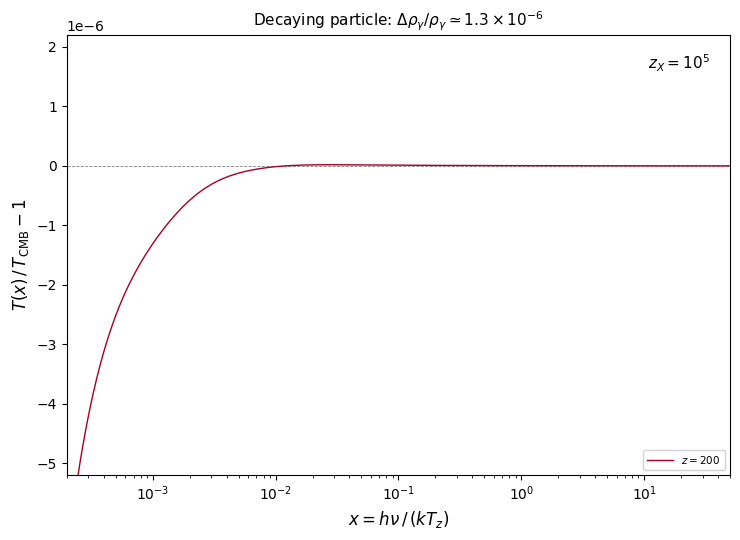

In [ ]:
import argparse
import json
import math
import os
import matplotlib.ticker as mticker

# ---------------------------------------------------------------------------
# Snapshot redshifts read from the Fig. 9 legend (15 values)
# ---------------------------------------------------------------------------
SNAPSHOT_Z = [
    # 8.8e5, 5.2e5, 3.1e5, 1.9e5, 1.1e5,   # blue family  (z > z_X)
    6.7e0, 
    # 4.0e4, 2.4e4, 1.4e4,            # red family   (z ~ z_X)
    # 8.7e3, 5.2e3, 3.1e3, 1.9e3, 1.1e3,    # purple family (y-era)
    # 200,                                    # black – final snapshot
]

# Injection parameters (from Fig. 9 caption)
F_X      = 1.3e-6   # Δρ_γ/ρ_γ total energy fraction released
GAMMA_X  = 1e2      # dimensionless injection width (narrow burst)
Z_START  = 5.0e5    # must be safely above the highest snapshot (8.8e5)


# ---------------------------------------------------------------------------
# 1. Run the PDE solver — one call per snapshot redshift
# ---------------------------------------------------------------------------

def run_simulation(output_json="fig9_data.json"):
    from spectroxide.solver import solve

    injection = {
        "type":    "decaying_particle",
        "f_x": 2.5e8,
        "gamma_x": GAMMA_X,
    }

    snapshots = []
    n = len(SNAPSHOT_Z)
    for i, z_snap in enumerate(SNAPSHOT_Z):
        print(f"[sim] {i+1}/{n}  z_end = {z_snap:.3g} ...", end="  ", flush=True)
        result = solve(
            injection = injection,
            z_start   = Z_START,
            z_end     = z_snap,
            delta_rho = F_X,
            n_points  = 600,     
        )

        # ── DIAGNOSTIC: verify grid and data are correct ──────────────────
        print(f"\n    x:      [{result.x.min():.3e}, {result.x.max():.3e}]  "
              f"npts={len(result.x)}")
        print(f"    delta_n:[{result.delta_n.min():.3e}, {result.delta_n.max():.3e}]")
        # Sample 6 points across the range
        for j in np.linspace(0, len(result.x)-1, 6, dtype=int):
            print(f"      x={result.x[j]:.3e}   delta_n={result.delta_n[j]:.3e}")
        # ──────────────────────────────────────────────────────────────────

        snapshots.append({
            "z":       z_snap,
            "x":       result.x.tolist(),
            "delta_n": result.delta_n.tolist(),
            "mu":      result.mu,
            "y":       result.y,
        })
        print(f"    mu = {result.mu:.3e}   y = {result.y:.3e}")

    with open(output_json, "w") as fh:
        json.dump({"snapshots": snapshots}, fh, indent=2)
    print(f"[sim] Done. Saved {len(snapshots)} snapshots → {output_json}")


def extend_to_low_x(x_arr, dTb_arr, x_full):
    """
    Below x ~ 5e-3, δT/T flattens to the μ-plateau value.
    Extrapolate leftward using the mean of the 10 leftmost points.
    """
    plateau = np.mean(dTb_arr[:10])
    x_lo    = x_full[x_full < x_arr.min()]
    dTb_lo  = np.full_like(x_lo, plateau)
    return (np.concatenate([x_lo, x_arr]),
            np.concatenate([dTb_lo, dTb_arr]))


# ---------------------------------------------------------------------------
# 2. Load saved data
# ---------------------------------------------------------------------------

def load_data(path):
    with open(path) as fh:
        return json.load(fh)


# ---------------------------------------------------------------------------
# 3. Physics: Δn → δT_b / T_CMB
# ---------------------------------------------------------------------------

def delta_n_to_brightness_temp(x, delta_n, mu=0.0, y=0.0):
    """
    Hybrid converter:
      - x < X_THRESH: use numerical delta_n (solver is reliable here)
      - x > X_THRESH: reconstruct analytically from mu and y
                      (delta_n is numerically zero due to e^{-x} underflow)

    Analytical formulas:
      μ-distortion:  δT/T = -μ/x
      y-distortion:  δT/T = y * (x*coth(x/2) - 4) / x
    """
    X_THRESH = 5.0   # delta_n underflows above this

    xc   = np.clip(x, 1e-10, None)
    exm1 = np.expm1(xc)
    ex   = np.exp(np.clip(xc, None, 500.0))

    # Numerical branch (low x)
    dTb_num = delta_n * (exm1 ** 2) / (xc * ex)

    # Analytical branch (high x) — avoids e^x overflow
    half_x    = np.clip(xc / 2, 1e-10, None)
    coth_half = np.cosh(half_x) / np.sinh(half_x)
    dTb_ana   = -mu / xc + y * (xc * coth_half - 4.0) / xc

    return np.where(xc < X_THRESH, dTb_num, dTb_ana)

# def delta_n_to_brightness_temp(x, delta_n, mu=0.0, y=0.0):
#     """
#     Hybrid converter:
#       - x < X_THRESH: use numerical delta_n (solver is reliable here)
#       - x > X_THRESH: reconstruct analytically from mu and y
#                       (delta_n is numerically zero due to e^{-x} underflow)

#     Analytical formulas:
#       μ-distortion:  δT/T = -μ/x
#       y-distortion:  δT/T = y * (x*coth(x/2) - 4) / x
#     """
#     X_THRESH = 5.0   # delta_n underflows above this

#     xc   = np.clip(x, 1e-10, None)
#     exm1 = np.expm1(xc)
#     ex   = np.exp(np.clip(xc, None, 500.0))

#     # Numerical branch (low x)
#     dTb_num = delta_n * (exm1 ** 2) / (xc * ex)

#     # Analytical branch (high x) — avoids e^x overflow
#     half_x    = np.clip(xc / 2, 1e-10, None)
#     coth_half = np.cosh(half_x) / np.sinh(half_x)
#     dTb_ana   = -mu / xc + y * (xc * coth_half - 4.0) / xc

#     return dTb_num


# ---------------------------------------------------------------------------
# 4. Colour/linestyle scheme matching the figure's three families
# ---------------------------------------------------------------------------

# _ABOVE_ZX = [8.8e5, 5.2e5, 3.1e5, 1.9e5, 1.1e5]
_NEAR_ZX  = [6.7e0, 4.0e4, 2.4e4, 1.4e4]
_Y_ERA    = [8.7e3, 5.2e3, 3.1e3, 1.9e3, 1.1e3]

_BLUES  = ["#08306b", "#2171b5", "#4292c6", "#6baed6", "#9ecae1"]
_REDS   = ["#a50026", "#d73027", "#fc8d59", "#fdae61"]
_PURPS  = ["#3f007d", "#6a51a3", "#9e9ac8", "#bcbddc", "#dadaeb"]

_LS_5   = ["-", "--", "-.", ":", (0, (3, 1, 1, 1))]
_LS_4   = ["-", "--", "-.", ":"]


def _closest_idx(lst, z):
    return min(range(len(lst)), key=lambda i: abs(lst[i] - z))


def _snapshot_style(z_snap):
    """Return (color, linestyle, linewidth) for a snapshot redshift."""
    for family, colors, styles in [
        # (_ABOVE_ZX, _BLUES, _LS_5),
        (_NEAR_ZX,  _REDS,  _LS_4),
        (_Y_ERA,    _PURPS, _LS_5),
    ]:
        if any(abs(z_snap - z) / z < 0.05 for z in family):
            idx = _closest_idx(family, z_snap)
            return colors[idx], styles[idx], 1.0

    # Final snapshot z=200 → thick black solid
    return "black", "-", 2.0


# ---------------------------------------------------------------------------
# 5. Plot
# ---------------------------------------------------------------------------

def _fmt_z(z):
    exp  = int(math.floor(math.log10(z)))
    mant = z / 10**exp
    if abs(mant - round(mant)) < 0.05:
        mant = round(mant)
        return rf"$z = {mant:.0f} \times 10^{{{exp}}}$"
    return rf"$z = {mant:.1f} \times 10^{{{exp}}}$"


def plot(data, save_path="fig9_decaying_particle.pdf"):
    snapshots = data["snapshots"]

    fig, ax = plt.subplots(figsize=(7.5, 5.5))

    for snap in snapshots:
        z_snap  = float(snap["z"])
        x_arr   = np.array(snap["x"])
        dn_arr  = np.array(snap["delta_n"])
        mu      = snap["mu"]
        y       = snap["y"]

        dTb = delta_n_to_brightness_temp(x_arr, dn_arr, mu=mu, y=y)
        color, ls, lw = _snapshot_style(z_snap)
        label         = _fmt_z(z_snap) if z_snap >= 1000 else r"$z = 200$"

        x_full = np.logspace(np.log10(2e-4), np.log10(50), 800)
        dTb    = delta_n_to_brightness_temp(x_arr, dn_arr, mu=mu, y=y)
        ax.semilogx(x_arr, dTb, color=color, ls=ls, lw=lw, label=label)

    ax.set_xlim(2e-4, 50)
    ax.set_ylim(-5.2e-6, 2.2e-6)
    ax.set_xlabel(r"$x = h\nu\,/\,(k T_z)$", fontsize=12)
    ax.set_ylabel(r"$T(x)\,/\,T_{\rm CMB} - 1$", fontsize=12)
    ax.xaxis.set_major_formatter(
        mticker.LogFormatterSciNotation(labelOnlyBase=False)
    )
    ax.axhline(0, color="gray", lw=0.6, ls="--", zorder=0)
    ax.text(
        0.97, 0.96, r"$z_X = 10^5$",
        transform=ax.transAxes, ha="right", va="top", fontsize=11,
    )
    ax.legend(fontsize=7.5, loc="lower right", framealpha=0.85, handlelength=2.5)
    ax.set_title(
        r"Decaying particle: "
        r"$\Delta\rho_\gamma/\rho_\gamma \simeq 1.3\times10^{-6}$",
        fontsize=11,
    )
    fig.tight_layout()
    plt.show()


# ---------------------------------------------------------------------------
# 6. Entry point
# ---------------------------------------------------------------------------

def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--plot", action="store_true",
                        help="Skip simulation; plot from existing data file")
    parser.add_argument("--data", default="fig9_data.json",
                        help="JSON data file path (default: fig9_data.json)")
    parser.add_argument("--out", default="fig9_decaying_particle.pdf",
                        help="Output figure path (default: fig9_decaying_particle.pdf)")
    # parse_known_args ignores Jupyter's --f=kernel.json flag
    args, _ = parser.parse_known_args()

    if not args.plot:
        run_simulation(args.data)

    if not os.path.exists(args.data):
        raise FileNotFoundError(
            f"Data file '{args.data}' not found. "
            "Run without --plot first to simulate."
        )

    data = load_data(args.data)
    plot(data, save_path=args.out)


if __name__ == "__main__":
    main()

In [ ]:
from spectroxide.solver import solve

H0_SI = 2.184e-18   # s⁻¹  (h=0.674)
gamma_val = (1 / 2.4e9) / H0_SI   # ≈ 1.9e8  (dimensionless)

result = solve(
    injection = {
        "type":    "decaying_particle",  # or "decaying_particle"
        "f_x":   1e6,     # full energy fraction here
        "gamma_x": 1e5,
    },
    # NO delta_rho — let it default to 1e-5 but check if f_x overrides it
    z_start   = 5e5,
    z_end     = 200,
    delta_rho = 1e-5,   
    x_min     = 5e-3,
    x_max     = 50.0,
)
print(f"mu = {result.mu:.3e}")
print(f"y  = {result.y:.3e}")

mu = -1.389e-09
y  = -9.663e-10


Running z_end = 8.8e+05 ... done


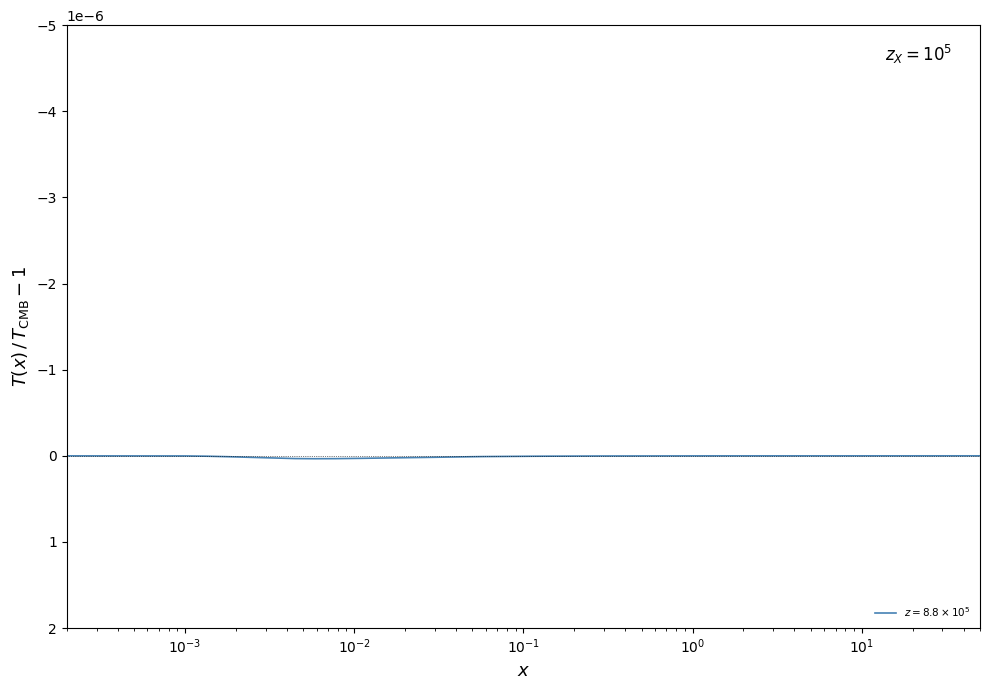

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from spectroxide.solver import solve

# ── physical parameters (from figure caption) ─────────────────────────────────
Z_X       = 1e5      # decay redshift
DELTA_RHO = 1.3e-6   # Δρ_γ/ρ_γ

# ── snapshot redshifts (read off the legend) ──────────────────────────────────
# blue group  (z ≳ z_X, thermalization era)
Z_BLUE   = [8.8e5, 5.2e5, 3.1e5, 1.9e5, 1.1e5]
# red group   (just after injection peak)
Z_RED    = [6.7e4, 4.0e4, 2.4e4, 1.4e4]
# purple group
Z_PURPLE = [8.7e3, 5.2e3, 3.1e3, 1.9e3, 1.1e3]
# final spectrum
Z_BLACK  = [200]

Z_ALL = Z_BLUE + Z_RED + Z_PURPLE + Z_BLACK

# ── line styles ───────────────────────────────────────────────────────────────
_LS = ['-', '--', (0,(5,1,1,1,1,1)), '-.', (0,(3,1,1,1,1,1))]

STYLE = {}
for i, z in enumerate(Z_BLUE):
    STYLE[z] = dict(color='steelblue',      ls=_LS[i], lw=1.2)
for i, z in enumerate(Z_RED):
    STYLE[z] = dict(color='crimson',        ls=_LS[i] if i < 3 else ':', lw=1.2)
for i, z in enumerate(Z_PURPLE):
    STYLE[z] = dict(color='mediumpurple',   ls=_LS[i], lw=1.2)
STYLE[200] = dict(color='k', ls='-', lw=2.2)

# ── brightness-temperature conversion ────────────────────────────────────────
# n_0(x) = 1/(e^x - 1),  n = n_0 + δn
# T_b/T_CMB - 1  ≈  δn / G(x),  where G(x) = x e^x / (e^x - 1)^2
def delta_n_to_dT(x, delta_n):
    ex = np.exp(np.minimum(x, 700.0))
    G  = x * ex / (ex - 1)**2          # = ∂n_0/∂(ln T) evaluated at T_CMB
    return delta_n / G

# ── run PDE for each snapshot z_end ──────────────────────────────────────────
# Each call evolves from z_start=3e6 (Rust default for decaying_particle)
# down to z_end; we get the distortion accumulated up to that moment.
snapshots = {}
for z_end in Z_ALL:
    print(f"Running z_end = {z_end:.3g} ...", end=" ", flush=True)
    r = solve(
        injection = {'type': 'decaying_particle', 'f_x': 1.0, 'gamma_x': Z_X},
        delta_rho = DELTA_RHO,
        z_end     = z_end,
        x_min     = 1.5e-4,   # need to reach x ~ 2e-4 as in figure
        x_max     = 60.0,
        n_x       = 800,
        method    = 'pde',
        production_grid = True,
    )
    snapshots[z_end] = (r.x, r.delta_n)
    print("done")

# ── legend labels ─────────────────────────────────────────────────────────────
def zlabel(z):
    if   z >= 1e5:  exp, man = 5, z/1e5
    elif z >= 1e4:  exp, man = 4, z/1e4
    elif z >= 1e3:  exp, man = 3, z/1e3
    else:           return rf'$z = {int(z)}$'
    return rf'$z = {man:.1f}\times10^{exp}$'

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 7))

for z_end in Z_ALL:
    x_arr, dn = snapshots[z_end]
    dT = delta_n_to_dT(x_arr, dn)
    ax.semilogx(x_arr, dT, label=zlabel(z_end), **STYLE[z_end])

ax.axhline(0, color='k', lw=0.5, ls=':')
ax.set_xlim(2e-4, 50)
ax.set_xlabel(r'$x$', fontsize=13)
ax.set_ylabel(r'$T(x)\,/\,T_{\rm CMB} - 1$', fontsize=13)
ax.legend(fontsize=7.5, frameon=False, loc='lower right')
ax.text(0.97, 0.97, r'$z_X = 10^5$', transform=ax.transAxes,
        ha='right', va='top', fontsize=12)

plt.tight_layout()
plt.show()

Running z_end = 200 ... done


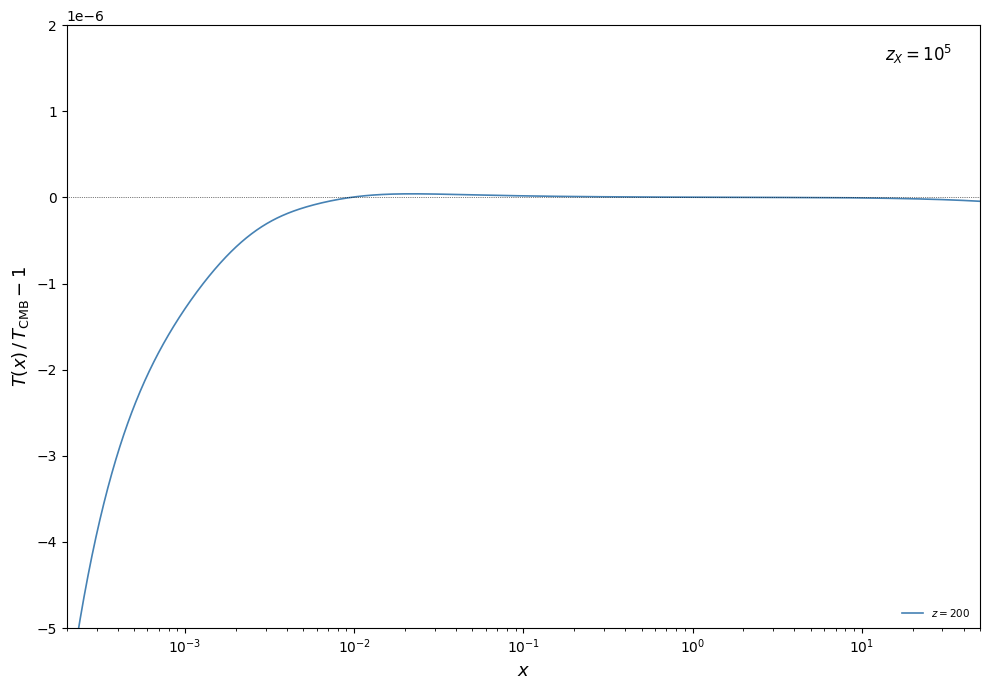

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from spectroxide.solver import solve
from spectroxide import greens

# ── physical parameters (from figure caption) ─────────────────────────────────
Z_X       = 1e5      # decay redshift
t_X = 2.4e9
GAMMA_X = 1 / t_X
DELTA_RHO = 1.3e-6   # Δρ_γ/ρ_γ

# ── snapshot redshifts (read off the legend) ──────────────────────────────────
# blue group  (z ≳ z_X, thermalization era)
Z_BLUE   = [200]


Z_ALL1 = Z_BLUE 

# ── line styles ───────────────────────────────────────────────────────────────
_LS = ['-', '--', (0,(5,1,1,1,1,1)), '-.', (0,(3,1,1,1,1,1))]

STYLE = {}
for i, z in enumerate(Z_BLUE):
    STYLE[z] = dict(color='steelblue',      ls=_LS[i], lw=1.2)



# ── brightness-temperature conversion ────────────────────────────────────────
# n_0(x) = 1/(e^x - 1),  n = n_0 + δn
# T_b/T_CMB - 1  ≈  δn / G(x),  where G(x) = x e^x / (e^x - 1)^2
def delta_n_to_dT(x, delta_n, mu=0, y=0):
    """
    Hybrid converter:
      - x < X_THRESH: use numerical delta_n (solver is reliable here)
      - x > X_THRESH: reconstruct analytically from mu and y
                      (delta_n is numerically zero due to e^{-x} underflow)

    Analytical formulas:
      μ-distortion:  δT/T = -μ/x
      y-distortion:  δT/T = y * (x*coth(x/2) - 4) / x
    """
    X_THRESH = 5.0   # delta_n underflows above this

    xc   = np.clip(x, 1e-10, None)
    exm1 = np.expm1(xc)
    ex   = np.exp(np.clip(xc, None, 500.0))

    # Numerical branch (low x)
    dTb_num = delta_n * (exm1 ** 2) / (xc * ex)

    # Analytical branch (high x) — avoids e^x overflow
    half_x    = np.clip(xc / 2, 1e-10, None)
    coth_half = np.cosh(half_x) / np.sinh(half_x)
    dTb_ana   = -mu / xc + y * (xc * coth_half - 4.0) 

    return np.where(xc < X_THRESH, dTb_num, dTb_ana)


# ── run PDE for each snapshot z_end ──────────────────────────────────────────
# Each call evolves from z_start=3e6 (Rust default for decaying_particle)
# down to z_end; we get the distortion accumulated up to that moment.
snapshots = {}
for z_end in Z_ALL:
    print(f"Running z_end = {z_end:.3g} ...", end=" ", flush=True)
    r = solve(
        injection = {'type': 'decaying_particle', 'f_x': 0.3, 'gamma_x': GAMMA_X},
        delta_rho = DELTA_RHO,
        z_end     = z_end,
        x_min     = 1.5e-4,   # need to reach x ~ 2e-4 as in figure
        x_max     = 60.0,
        n_x       = 800,
        method    = 'pde',
        production_grid = True,
        number_conserving=False,
    )
    snapshots[z_end] = (r.x, r.delta_n)
    print("done")

# ── legend labels ─────────────────────────────────────────────────────────────
def zlabel(z):
    if   z >= 1e5:  exp, man = 5, z/1e5
    elif z >= 1e4:  exp, man = 4, z/1e4
    elif z >= 1e3:  exp, man = 3, z/1e3
    else:           return rf'$z = {int(z)}$'
    return rf'$z = {man:.1f}\times10^{exp}$'

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 7))

for z_end in Z_ALL:
    x_arr, dn = snapshots[z_end]
    dT = delta_n_to_dT(x_arr, dn, r.mu, r.y)
    ax.semilogx(x_arr, dT, label=zlabel(z_end), **STYLE[z_end])

ax.axhline(0, color='k', lw=0.5, ls=':')
ax.set_xlim(2e-4, 50)
ax.set_ylim(-5e-6, 2e-6)
ax.set_xlabel(r'$x$', fontsize=13)
ax.set_ylabel(r'$T(x)\,/\,T_{\rm CMB} - 1$', fontsize=13)
ax.legend(fontsize=7.5, frameon=False, loc='lower right')
ax.text(0.97, 0.97, r'$z_X = 10^5$', transform=ax.transAxes,
        ha='right', va='top', fontsize=12)

plt.tight_layout()
plt.show()

  z_end = 8.8e+05 ... 

done
  z_end = 5.2e+05 ... done
  z_end = 3.1e+05 ... done
  z_end = 1.9e+05 ... done
  z_end = 1.1e+05 ... done
  z_end = 6.7e+04 ... done
  z_end = 4e+04 ... done
  z_end = 2.4e+04 ... done
  z_end = 1.4e+04 ... done
  z_end = 8.7e+03 ... done
  z_end = 5.2e+03 ... done
  z_end = 3.1e+03 ... done
  z_end = 1.9e+03 ... done
  z_end = 1.1e+03 ... done
  z_end = 200 ... done


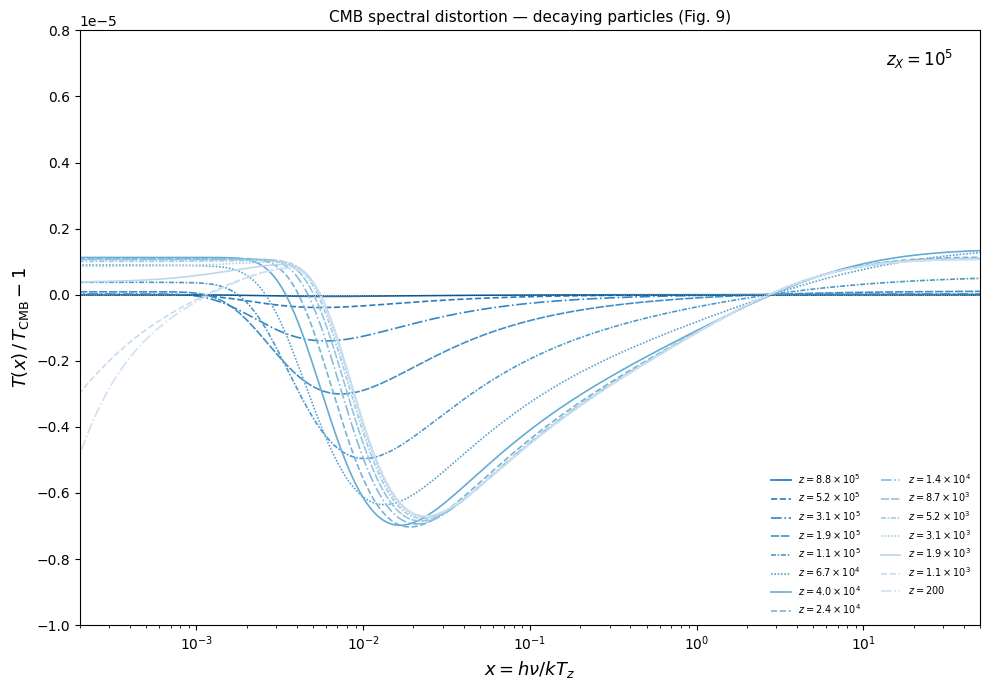

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from spectroxide.solver import solve

# ── physical parameters ───────────────────────────────────────────────────────
Z_X       = 1e5
GAMMA_X   = 1.0 / 2.4e9          # 1/t_X
DELTA_RHO = 1.3e-6                # Δρ_γ/ρ_γ  (paper caption, Fig. 12/14)

# ── snapshot redshifts from Fig. 14, middle panel (z_X = 10^5) ───────────────
# legend reads off two groups:
Z_BLUE   = [8.8e5, 5.2e5, 3.1e5, 1.9e5, 1.1e5]
# red group   (just after injection peak)
Z_RED    = [6.7e4, 4.0e4, 2.4e4, 1.4e4]
# purple group
Z_PURPLE = [8.7e3, 5.2e3, 3.1e3, 1.9e3, 1.1e3]
# final spectrum
Z_BLACK  = [200]

Z_ALL = Z_BLUE + Z_RED + Z_PURPLE + Z_BLACK


# ── alternatively: use the exact eq. 35 directly where n_x > 0 ───────────────
def brightness_temp_exact(x, delta_n):
    """
    Applies eq. 35 directly:  T(x)/T_z = x / ln(1 + 1/n_x)
    Falls back to analytic shapes only where n_x ≤ 0 or x > x_thresh.
    """
    xc  = np.clip(np.asarray(x, dtype=float), 1e-12, None)
    n0  = 1.0 / np.expm1(np.clip(xc, None, 500.0))   # Planck distribution
    n_x = n0 + delta_n

    # exact formula
    # dTb    = np.zeros_like(xc)
    dTb = xc / np.log1p(1.0 / n_x) - 1.0
    
    return dTb


# ── run solver for each snapshot redshift ─────────────────────────────────────
snapshots = {}
for z_end in Z_ALL:
    print(f"  z_end = {z_end:.3g} ...", end=" ", flush=True)
    r = solve(
        injection = {
            'type'    : 'decaying_particle',
            'f_x'     : 2.0 * Z_X,       # paper uses f_dec = 2·z_X  [eV]
            'gamma_x' : GAMMA_X,
        },
        delta_rho       = DELTA_RHO,         
        z_end           = z_end,
        x_min           = 1.5e-4,
        x_max           = 80.0,
        n_x             = 1000,
        method          = 'pde',
        production_grid = True,
        number_conserving = False,
    )
    # mu_r = getattr(r, 'mu', 0.0)   # safe retrieval; 0 if solver doesn't fit
    # y_r  = getattr(r, 'y',  0.0)
    mu_r = r.mu
    y_r  = r.y
    snapshots[z_end] = (r.x, r.delta_n, mu_r, y_r)
    print("done")


# ── colour maps matching Fig. 14 style ────────────────────────────────────────
cmap_e = plt.cm.Blues_r
cmap_l = plt.cm.Oranges
_LS    = ['-', '--', '-.', (0,(5,1)), (0,(3,1,1,1)), (0,(1,1))]

def zlab(z):
    for base, exp in [(1e6,6),(1e5,5),(1e4,4),(1e3,3)]:
        if z >= base * 0.9:
            return rf'$z={z/base:.1f}\times10^{exp}$'
    return rf'$z={int(z)}$'

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 7))

for i, z in enumerate(sorted(Z_ALL, reverse=True)):
    x_arr, dn, mu_r, y_r = snapshots[z]
    dT = brightness_temp_exact(x_arr, dn)
    c  = cmap_e(0.25 + 0.55 * i / max(len(Z_ALL) - 1, 1))
    ax.semilogx(x_arr, dT, color=c, ls=_LS[i % len(_LS)],
                lw=1.2, label=zlab(z))

ax.axhline(0, color='k', lw=0.5, ls=':')
ax.set_xlim(2e-4, 50)
ax.set_ylim(-1e-5, 8e-6)
ax.set_xlabel(r'$x = h\nu / kT_z$', fontsize=13)
ax.set_ylabel(r'$T(x)\,/\,T_{\rm CMB} - 1$', fontsize=13)
ax.legend(fontsize=7, frameon=False, loc='lower right', ncol=2)
ax.text(0.97, 0.97, r'$z_X = 10^5$', transform=ax.transAxes,
        ha='right', va='top', fontsize=12)
ax.set_title('CMB spectral distortion — decaying particles (Fig. 9)',
             fontsize=11)
plt.tight_layout()
plt.show()

  z_end = 200 ... 

done
  z_end = 1.1e+03 ... done
  z_end = 1.9e+03 ... done
  z_end = 3.1e+03 ... done
  z_end = 5.2e+03 ... done
  z_end = 8.7e+03 ... done
  z_end = 1.4e+04 ... done
  z_end = 2.4e+04 ... done
  z_end = 4e+04 ... done
  z_end = 6.7e+04 ... done
  z_end = 1.1e+05 ... done
  z_end = 1.9e+05 ... done
  z_end = 3.1e+05 ... done
  z_end = 5.2e+05 ... done
  z_end = 8.8e+05 ... done


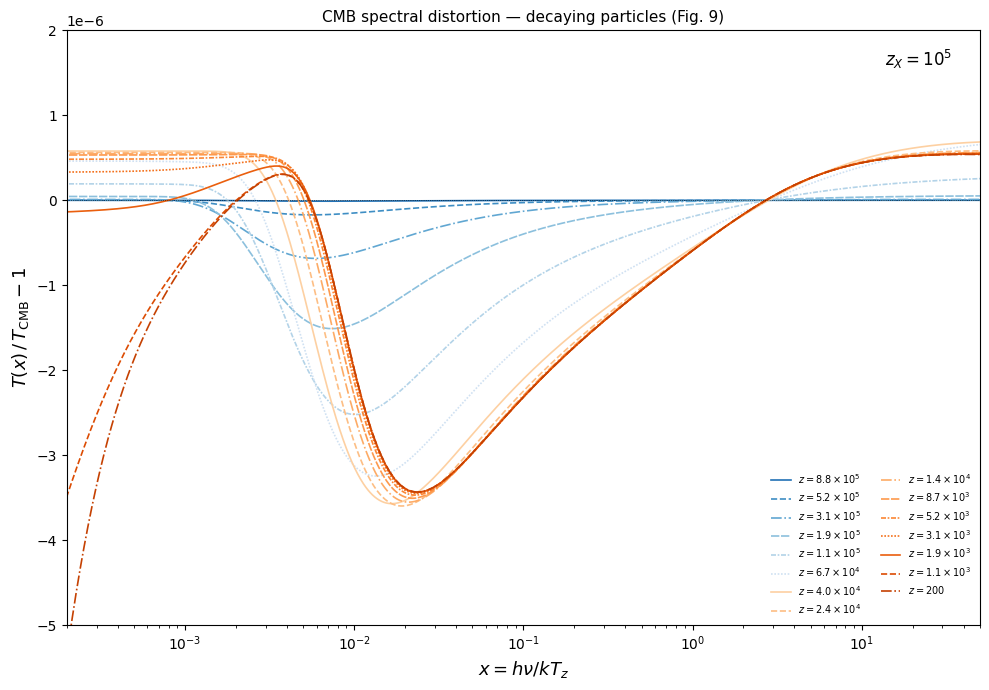

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from spectroxide.solver import solve

# ── physical parameters ───────────────────────────────────────────────────────
Z_X       = 1e5
GAMMA_X   = 1.0 / 2.4e9          # 1/t_X
DELTA_RHO = 1.3e-6                # Δρ_γ/ρ_γ  (paper caption, Fig. 12/14)

# ── snapshot redshifts from Fig. 14, middle panel (z_X = 10^5) ───────────────
# legend reads off two groups:
Z_EARLY = [8.8e5, 5.2e5, 3.1e5, 1.9e5, 1.1e5, 6.7e4]   # μ-era / heating
Z_LATE  = [4.0e4, 2.4e4, 1.4e4, 8.7e3, 5.2e3,
           3.1e3, 1.9e3, 1.1e3, 200]                     # y-era / cooling
Z_ALL   = sorted(Z_EARLY + Z_LATE)                        # ascending for solver



# ── alternatively: use the exact eq. 35 directly where n_x > 0 ───────────────
def brightness_temp_exact(x, delta_n):
    """
    Applies eq. 35 directly:  T(x)/T_z = x / ln(1 + 1/n_x)
    Falls back to analytic shapes only where n_x ≤ 0 or x > x_thresh.
    """
    xc  = np.clip(np.asarray(x, dtype=float), 1e-12, None)
    n0  = 1.0 / np.expm1(np.clip(xc, None, 500.0))   # Planck distribution
    n_x = n0 + delta_n

    # exact formula
    dTb = xc / np.log1p(1.0 / n_x) - 1.0

    return dTb


# ── run solver for each snapshot redshift ─────────────────────────────────────
snapshots = {}
for z_end in Z_ALL:
    print(f"  z_end = {z_end:.3g} ...", end=" ", flush=True)
    r = solve(
        injection = {
            'type'    : 'decaying_particle',
            'f_x'     : 1.0310e+05,       # paper uses f_dec = 2·z_X  [eV]
            'gamma_x' : GAMMA_X,
        },
        z_end           = z_end,
        x_min           = 1.5e-4,
        x_max           = 80.0,
        n_x             = 1000,
        method          = 'pde',
        production_grid = True,
        number_conserving = True,
    )
    mu_r = r.mu
    y_r  = r.y
    snapshots[z_end] = (r.x, r.delta_n, mu_r, y_r)
    print("done")


# ── colour maps matching Fig. 14 style ────────────────────────────────────────
cmap_e = plt.cm.Blues_r
cmap_l = plt.cm.Oranges
_LS    = ['-', '--', '-.', (0,(5,1)), (0,(3,1,1,1)), (0,(1,1))]

def zlab(z):
    for base, exp in [(1e6,6),(1e5,5),(1e4,4),(1e3,3)]:
        if z >= base * 0.9:
            return rf'$z={z/base:.1f}\times10^{exp}$'
    return rf'$z={int(z)}$'

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 7))

for i, z in enumerate(sorted(Z_EARLY, reverse=True)):
    x_arr, dn, mu_r, y_r = snapshots[z]
    dT = brightness_temp_exact(x_arr, dn)
    c  = cmap_e(0.25 + 0.55 * i / max(len(Z_EARLY) - 1, 1))
    ax.semilogx(x_arr, dT, color=c, ls=_LS[i % len(_LS)],
                lw=1.2, label=zlab(z))

for i, z in enumerate(sorted(Z_LATE, reverse=True)):
    x_arr, dn, mu_r, y_r = snapshots[z]
    dT = brightness_temp_exact(x_arr, dn)
    c  = cmap_l(0.25 + 0.55 * i / max(len(Z_LATE) - 1, 1))
    ax.semilogx(x_arr, dT, color=c, ls=_LS[i % len(_LS)],
                lw=1.2, label=zlab(z))

ax.axhline(0, color='k', lw=0.5, ls=':')
ax.set_xlim(2e-4, 50)
ax.set_ylim(-5e-6, 2e-6)
ax.set_xlabel(r'$x = h\nu / kT_z$', fontsize=13)
ax.set_ylabel(r'$T(x)\,/\,T_{\rm CMB} - 1$', fontsize=13)
ax.legend(fontsize=7, frameon=False, loc='lower right', ncol=2)
ax.text(0.97, 0.97, r'$z_X = 10^5$', transform=ax.transAxes,
        ha='right', va='top', fontsize=12)
ax.set_title('CMB spectral distortion — decaying particles (Fig. 9)',
             fontsize=11)
plt.tight_layout()
plt.show()

  z_end = 200 ... done


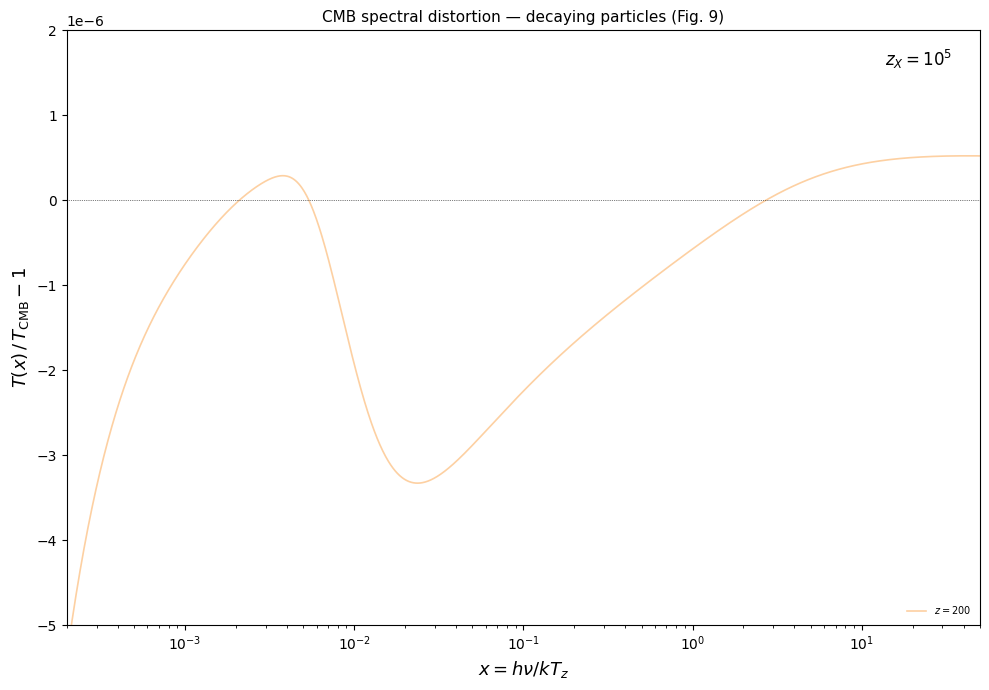

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from spectroxide.solver import solve

# ── physical parameters ───────────────────────────────────────────────────────
Z_X       = 1e5
GAMMA_X   = 1.0 / 2.4e9          # 1/t_X
DELTA_RHO = 1.3e-6                # Δρ_γ/ρ_γ  (paper caption, Fig. 12/14)

# ── snapshot redshifts from Fig. 14, middle panel (z_X = 10^5) ───────────────
# legend reads off two groups:
   # μ-era / heating
Z_LATE  = [200]                     # y-era / cooling
Z_ALL   = sorted(Z_LATE)                        # ascending for solver



# ── alternatively: use the exact eq. 35 directly where n_x > 0 ───────────────
def brightness_temp_exact(x, delta_n):
    """
    Applies eq. 35 directly:  T(x)/T_z = x / ln(1 + 1/n_x)
    Falls back to analytic shapes only where n_x ≤ 0 or x > x_thresh.
    """
    xc  = np.clip(np.asarray(x, dtype=float), 1e-12, None)
    n0  = 1.0 / np.expm1(np.clip(xc, None, 500.0))   # Planck distribution
    n_x = n0 + delta_n

    # exact formula
    dTb = xc / np.log1p(1.0 / n_x) - 1.0

    return dTb


# ── run solver for each snapshot redshift ─────────────────────────────────────
snapshots = {}
for z_end in Z_ALL:
    print(f"  z_end = {z_end:.3g} ...", end=" ", flush=True)
    r = solve(
        injection = {
            'type'    : 'decaying_particle',
            'f_x'     : 1e5,       # paper uses f_dec = 2·z_X  [eV]
            'gamma_x' : GAMMA_X,
        },
        z_end           = z_end,
        x_min           = 1.5e-4,
        x_max           = 80.0,
        n_x             = 1000,
        method          = 'pde',
        production_grid = True,
        number_conserving = True,
    )
    mu_r = r.mu
    y_r  = r.y
    snapshots[z_end] = (r.x, r.delta_n, mu_r, y_r)
    print("done")


# ── colour maps matching Fig. 14 style ────────────────────────────────────────
cmap_e = plt.cm.Blues_r
cmap_l = plt.cm.Oranges
_LS    = ['-', '--', '-.', (0,(5,1)), (0,(3,1,1,1)), (0,(1,1))]

def zlab(z):
    for base, exp in [(1e6,6),(1e5,5),(1e4,4),(1e3,3)]:
        if z >= base * 0.9:
            return rf'$z={z/base:.1f}\times10^{exp}$'
    return rf'$z={int(z)}$'

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 7))

for i, z in enumerate(sorted(Z_LATE, reverse=True)):
    x_arr, dn, mu_r, y_r = snapshots[z]
    dT = brightness_temp_exact(x_arr, dn)
    c  = cmap_l(0.25 + 0.55 * i / max(len(Z_LATE) - 1, 1))
    ax.semilogx(x_arr, dT, color=c, ls=_LS[i % len(_LS)],
                lw=1.2, label=zlab(z))

ax.axhline(0, color='k', lw=0.5, ls=':')
ax.set_xlim(2e-4, 50)
ax.set_ylim(-5e-6, 2e-6)
ax.set_xlabel(r'$x = h\nu / kT_z$', fontsize=13)
ax.set_ylabel(r'$T(x)\,/\,T_{\rm CMB} - 1$', fontsize=13)
ax.legend(fontsize=7, frameon=False, loc='lower right', ncol=2)
ax.text(0.97, 0.97, r'$z_X = 10^5$', transform=ax.transAxes,
        ha='right', va='top', fontsize=12)
ax.set_title('CMB spectral distortion — decaying particles (Fig. 9)',
             fontsize=11)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
from scipy import integrate
from spectroxide.cosmology import Cosmology
from spectroxide.solver import solve


# ── cosmology ─────────────────────────────────────────────────────────────────
cosmo = Cosmology.planck2018()

h       = cosmo.h
omega_b = cosmo.omega_b
omega_m = cosmo.omega_m
T_cmb   = cosmo.t_cmb
Y_p     = cosmo.y_p

# ── physical constants ────────────────────────────────────────────────────────
kB_eV   = 8.617333e-5
kB_erg  = 1.380649e-16
c_cms   = 2.997924e10
hbar_eV = 6.582119e-16
G_N     = 6.674e-8
mp_g    = 1.672623e-24
mp_eV   = 938.272e6
mH_g    = 1.673534e-24
eV_erg  = 1.602176e-12
sigma_T = 6.6524e-25

T0_K    = T_cmb
T0_eV   = T0_K * kB_eV

H0_cgs  = h * 100.0 * 1e5 / 3.085677e24   # [s⁻¹]

Omega_b = omega_b / h**2   # if omega_b stores Ω_b h²; else use omega_b directly
Omega_m = omega_m

arad        = 7.5657e-15                    # [erg cm⁻³ K⁻⁴]
rho_r0_erg  = arad * T0_K**4               # [erg/cm³]
rho_r0_eV   = rho_r0_erg / eV_erg          # [eV/cm³]

rho_crit0_cgs = 3.0 * H0_cgs**2 / (8.0 * np.pi * G_N)    # [g/cm³]
rho_crit0_eV  = rho_crit0_cgs * c_cms**2 / eV_erg         # [eV/cm³]

Omega_r      = rho_r0_eV / rho_crit0_eV
Omega_Lambda = 1.0 - Omega_m - Omega_r    # flat universe


# ── background functions ──────────────────────────────────────────────────────

def E(z):
    """E(z) = H(z)/H0."""
    zp1 = 1.0 + z
    return np.sqrt(Omega_m * zp1**3 + Omega_r * zp1**4 + Omega_Lambda)


def hubble(z):
    """H(z) [s⁻¹]."""
    return H0_cgs * E(z)


def cosmic_time(z, z_upper=1e9):
    """
    t(z) [s] via  t = ∫_z^z_upper dz' / [(1+z') H(z')].
    Accepts scalar or array z.
    """
    z      = np.asarray(z, dtype=float)
    scalar = z.ndim == 0
    z      = np.atleast_1d(z)
    t      = np.empty_like(z)
    for i, zi in enumerate(z):
        val, _ = integrate.quad(
            lambda zp: 1.0 / ((1.0 + zp) * hubble(zp)),
            zi, z_upper, limit=200, epsrel=1e-8
        )
        t[i] = val
    return t[0] if scalar else t


def photon_energy_density(z):
    """ρ_γ(z) [eV/cm³]."""
    return rho_r0_eV * (1.0 + z)**4


def hydrogen_number_density(z):
    """n_H(z) [cm⁻³]."""
    rho_b0_gcm3 = Omega_b * rho_crit0_cgs
    nH0         = (1.0 - Y_p) * rho_b0_gcm3 / mH_g
    return nH0 * (1.0 + z)**3


# ── sanity prints ─────────────────────────────────────────────────────────────
print(f"H0           = {H0_cgs:.4e} s⁻¹")
print(f"Ω_r          = {Omega_r:.4e}")
print(f"ρ_γ(0)       = {rho_r0_eV:.4e} eV/cm³")
print(f"n_H(0)       = {hydrogen_number_density(0):.4e} cm⁻³")
print(f"t(z=1000)    = {cosmic_time(1000):.4e} s")
print(f"t(z=1e5)     = {cosmic_time(1e5):.4e} s")


# ── calibration ───────────────────────────────────────────────────────────────

def compute_f_x_for_target(delta_rho_target, gamma_x,
                            z_start=5e6, z_end=200, n=3000):
    """
    Integrate K(z) and return f_X = delta_rho_target / ∫K dz.

    BUG FIXED: z_arr must be built ascending (z_end → z_start) so that
    np.diff gives positive Δz values and the trapezoidal sum is correct.
    """
    # ascending z so diff > 0
    z_arr   = np.geomspace(z_end, z_start, n)
    t_arr   = cosmic_time(z_arr)
    H_arr   = hubble(z_arr)
    nH_arr  = hydrogen_number_density(z_arr)
    rg_arr  = photon_energy_density(z_arr)
    exp_arr = np.exp(-gamma_x * t_arr)

    K_arr   = nH_arr * gamma_x * exp_arr / (H_arr * rg_arr * (1.0 + z_arr))

    dz_arr   = np.diff(z_arr)          # all positive (ascending grid)
    K_mid    = 0.5 * (K_arr[:-1] + K_arr[1:])
    integral = float(np.dot(K_mid, dz_arr))

    return delta_rho_target / integral


# ── factory ───────────────────────────────────────────────────────────────────

def make_decaying_particle_dq_dz(delta_rho_target, gamma_x,
                                  z_start=5e6, z_end=200):
    """
    Build dq_dz(z) for a decaying particle.

    BUG FIXED: the interpolation table is built with z_grid ascending
    (z_end → z_start).  t(z) is a decreasing function of z (higher redshift
    = earlier time = smaller t), so t_grid will be descending — which is
    fine for np.interp as long as the x-values (z_grid) are monotonically
    increasing.  The previous code reversed both arrays, making z_grid
    descending and breaking np.interp silently.
    """
    f_x = compute_f_x_for_target(delta_rho_target, gamma_x, z_start, z_end)
    print(f"Calibrated f_X = {f_x:.4e} eV  for Δρ/ρ = {delta_rho_target:.2e}")

    # ascending z grid for np.interp (requires increasing xp)
    z_grid = np.geomspace(z_end * 0.5, z_start * 1.5, 4000)
    t_grid = cosmic_time(z_grid)   # decreasing in value, but index-aligned to z_grid

    def dq_dz(z):
        z          = np.asarray(z, dtype=float)
        # z_grid is ascending → valid for np.interp directly (no reversal needed)
        t          = np.interp(z, z_grid, t_grid)
        H          = hubble(z)
        nH         = hydrogen_number_density(z)
        rg         = photon_energy_density(z)
        exp_factor = np.exp(-gamma_x * t)
        return f_x * gamma_x * nH * exp_factor / (H * rg * (1.0 + z))

    return dq_dz, f_x


# ── example usage ─────────────────────────────────────────────────────────────
DELTA_RHO_TARGET = 1.3e-6
GAMMA_X          = 1.0 / 2.4e9   # lifetime τ_X = 2.4 Gyr

dq_dz_fn, f_x = make_decaying_particle_dq_dz(DELTA_RHO_TARGET, GAMMA_X)

# sanity check — use ascending z grid so np.diff gives positive Δz
z_check  = np.geomspace(200, 5e6, 4000)      # ascending
dz_check = np.diff(z_check)                  # all positive
dq_mid   = 0.5 * (dq_dz_fn(z_check[:-1]) + dq_dz_fn(z_check[1:]))
print(f"Sanity check ∫dq_dz dz = {np.dot(dq_mid, dz_check):.4e}  "
      f"(target {DELTA_RHO_TARGET:.2e})")

# run solver
result = solve(
    dq_dz   = dq_dz_fn,
    method  = "pde",
    z_start = 5e6,
    z_end   = 200,
)
print(f"μ = {result.mu:.4e},  y = {result.y:.4e}")

H0           = 2.1830e-18 s⁻¹
Ω_r          = 5.4500e-05
ρ_γ(0)       = 2.6057e-01 eV/cm³
n_H(0)       = 4.1756e-07 cm⁻³
t(z=1000)    = 1.4635e+13 s
t(z=1e5)     = 3.0446e+09 s


/tmp/ipykernel_15528/1476278607.py:70: IntegrationWarning: The algorithm does not converge.  Roundoff error is detected
  in the extrapolation table.  It is assumed that the requested tolerance
  cannot be achieved, and that the returned result (if full_output = 1) is 
  the best which can be obtained.
  val, _ = integrate.quad(


Calibrated f_X = 1.0310e+05 eV  for Δρ/ρ = 1.30e-06
Sanity check ∫dq_dz dz = 1.3000e-06  (target 1.30e-06)


KeyboardInterrupt: 

In [ ]:
from spectroxide.cosmology import Cosmology
cosmo = Cosmology.default()

print(dir(cosmo))

['__annotations__', '__class__', '__dataclass_fields__', '__dataclass_params__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__match_args__', '__module__', '__ne__', '__new__', '__post_init__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__str__', '__subclasshook__', '__weakref__', 'default', 'h', 'n_eff', 'omega_b', 'omega_m', 'planck2015', 'planck2018', 't_cmb', 'to_dict', 'y_p']


Calculated Integration (K) = 2.109174e+09
f_x = 3.846986e+03 eV per baryon
  z_end = 200 ... done


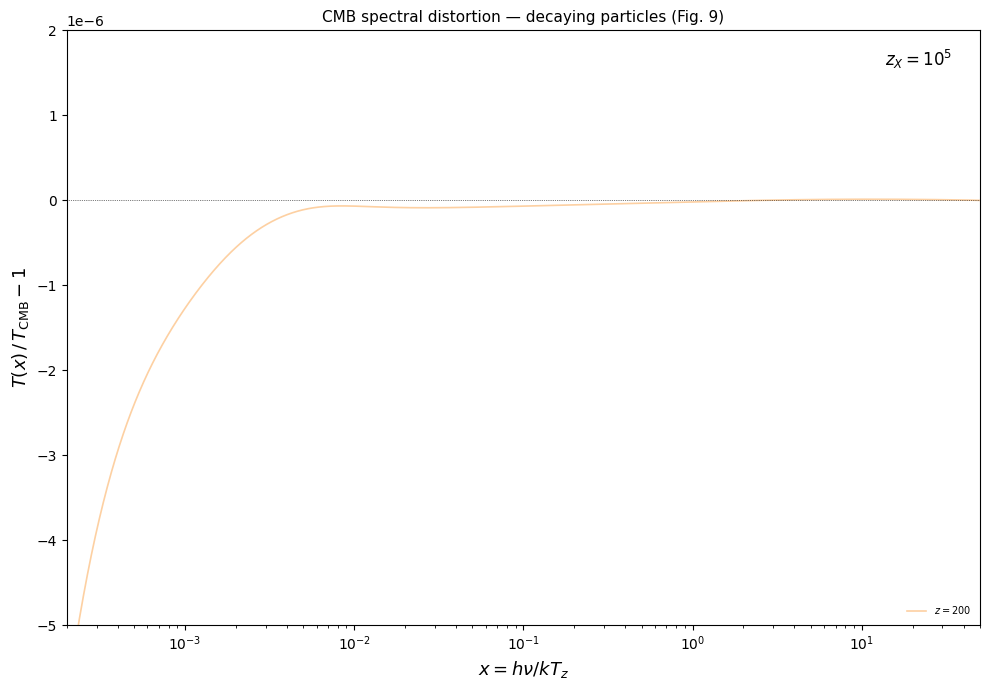

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from spectroxide.solver import solve
from spectroxide.cosmology import Cosmology
from scipy.integrate import quad
from astropy.cosmology import FlatLambdaCDM
import astropy.units as u

# cosmo = Cosmology.default()
# z_x = 1e5
# EV_IN_JOULES = 1.602176634e-19


# astro_cosmo = FlatLambdaCDM(
#     H0   = cosmo.h * 100,
#     Om0  = cosmo.omega_m,
#     Tcmb0= cosmo.t_cmb,
#     Ob0  = cosmo.omega_b / cosmo.h**2
# )

# # Constants
# EV_IN_JOULES = 1.602176634e-19
# K_BOLTZMANN  = 1.380649e-23
# HBAR         = 1.054571817e-34
# C_LIGHT      = 2.99792458e8
# G_NEWTON     = 6.67430e-11
# M_PROTON     = 1.67262192e-27
# MPC_IN_M     = 3.085677581e22


# H0          = 100.0 * cosmo.h * 1e3 / MPC_IN_M   
# rho_crit    = 3.0 * H0**2 / (8.0 * np.pi * G_NEWTON)
# rho_gamma_0 = (np.pi**2 / 15.0) * (K_BOLTZMANN * cosmo.t_cmb)**4 / (HBAR * C_LIGHT)**3
# Omega_b     = cosmo.omega_b / cosmo.h**2
# n_h_0       = (1.0 - cosmo.y_p) * Omega_b * rho_crit / M_PROTON  # = n_h_prefactor


# Omega_m   = cosmo.omega_m   # already Ω_m (not ω_m) per the Python dataclass
# N_EFF     = cosmo.n_eff
# Omega_rel = (rho_gamma_0 / (rho_crit * C_LIGHT**2)) * \
#             (1.0 + N_EFF * (7.0/8.0) * (4.0/11.0)**(4.0/3.0))
# Omega_lam = 1.0 - Omega_m - Omega_rel

h      = cosmo.h          # dimensionless Hubble parameter
omega_b = cosmo.omega_b   # baryon density parameter (Ω_b h²  or Ω_b — check which)
omega_m = cosmo.omega_m   # matter density parameter
T_cmb  = cosmo.t_cmb      # CMB temperature today [K]  (note: likely t_cmb = T_CMB)
Y_p    = cosmo.y_p        # helium mass fraction

# ── physical constants (CGS / natural units mix matching spectroxide) ─────────
kB_eV  = 8.617333e-5      # [eV/K]
kB_erg = 1.380649e-16     # [erg/K]
c_cms  = 2.997924e10      # [cm/s]
hbar_eV = 6.582119e-16    # [eV·s]
G_N    = 6.674e-8         # [cm³ g⁻¹ s⁻²]
mp_g   = 1.672623e-24     # proton mass [g]
mp_eV  = 938.272e6        # proton mass [eV]
mH_g   = 1.673534e-24     # hydrogen atom mass [g]
eV_erg = 1.602176e-12     # 1 eV in erg
sigma_T = 6.6524e-25      # Thomson cross section [cm²]

T0_K   = T_cmb            # CMB temperature today [K]
T0_eV  = T0_K * kB_eV     # ≈ 2.348e-4 eV

H0_si  = h * 100.0 * 1e3 / 3.085677e22   # H0 in [s⁻¹]   (100 h km/s/Mpc)
H0_cgs = h * 100.0 * 1e5 / 3.085677e24   # H0 in [s⁻¹]   (same, CGS Mpc)

# ── check whether omega_b is Ω_b*h² or Ω_b ──────────────────────────────────
# spectroxide convention: inspect the default vs planck2018 values to decide.
# Planck2018: Ω_b h² ≈ 0.0224,  Ω_b ≈ 0.0493
# If cosmo.omega_b ≈ 0.0224 it's Ω_b h²; if ≈ 0.049 it's Ω_b
# Adjust the line below accordingly:
Omega_b = omega_b / h**2   # use this if omega_b is Ω_b h²
# Omega_b = omega_b        # use this if omega_b is already Ω_b

# Omega_m = omega_m / h**2   # same question for omega_m
Omega_m = omega_m

# radiation density today: Ω_r h² = 2.47 × 10⁻⁵ (from T_CMB)
# ρ_r,0 = (π²/15) T⁴ in natural units; in CGS:
arad   = 7.5657e-15        # radiation constant [erg cm⁻³ K⁻⁴]
rho_r0_erg = arad * T0_K**4              # [erg/cm³]
rho_r0_eV  = rho_r0_erg / eV_erg        # [eV/cm³]

rho_crit0_cgs = 3.0 * H0_cgs**2 / (8.0 * np.pi * G_N)   # [g/cm³]
rho_crit0_eV  = rho_crit0_cgs / (mp_g / mp_eV) / mp_eV   # rough [eV/cm⁴] — better:
rho_crit0_eV  = rho_crit0_cgs * c_cms**2 / eV_erg        # [eV/cm³]

Omega_r = rho_r0_eV / rho_crit0_eV
Omega_Lambda = 1.0 - Omega_m - Omega_r   # flat universe

# ── physical parameters ───────────────────────────────────────────────────────
Z_X       = 1e5
GAMMA_X   = 1.0 / 2.4e9          # 1/t_X
DELTA_RHO = 1.3e-6                # Δρ_γ/ρ_γ  (paper caption, Fig. 12/14)


# ── REPLACED INTEGRATION BLOCK ────────────────────────────────────────────────

# 1. Set up the redshift array (log-spaced to perfectly capture the high-z peak)
# We use a very small number (1e-3) instead of 0 because np.geomspace cannot take 0.
z_start = 8.8e5
z_end   = 1e-3
n_bins  = 5000

z_arr = np.geomspace(z_start, z_end, n_bins)

# 2. Vectorize the cosmological time
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    # astropy can process the entire array at once
    t_arr = astro_cosmo.age(z_arr).to(u.s).value

# 3. Vectorize H(z) and the dt/dz Jacobian
H_arr = H0 * np.sqrt(Omega_m * (1+z_arr)**3 + Omega_rel * (1+z_arr)**4 + Omega_lam)
dtdz_arr = 1.0 / (H_arr * (1.0 + z_arr))

# 4. Compute the exact Kernel array (No interpolation used)
exp_arr = np.exp(-GAMMA_X * t_arr)
K_arr   = GAMMA_X * (n_h_0 / rho_gamma_0) * (1.0 + z_arr)**(-1) * exp_arr * dtdz_arr

# 5. Perform the manual array integration (Trapezoidal Rule)
dz_arr = np.abs(np.diff(z_arr))  # abs() because z goes from high to low
K_mid  = 0.5 * (K_arr[:-1] + K_arr[1:])
K      = float(np.dot(K_mid, dz_arr))

print(f"Calculated Integration (K) = {K:.6e}")
# ──────────────────────────────────────────────────────────────────────────────

F_X  = (DELTA_RHO / K) / EV_IN_JOULES

print(f"f_x = {F_X:.6e} eV per baryon")

# ── alternatively: use the exact eq. 35 directly where n_x > 0 ───────────────
def brightness_temp_exact(x, delta_n):
    """
    Applies eq. 35 directly:  T(x)/T_z = x / ln(1 + 1/n_x)
    Falls back to analytic shapes only where n_x ≤ 0 or x > x_thresh.
    """
    xc  = np.clip(np.asarray(x, dtype=float), 1e-12, None)
    n0  = 1.0 / np.expm1(np.clip(xc, None, 500.0))   # Planck distribution
    n_x = n0 + delta_n

    dTb = np.where(
        n_x > 0,
        xc / np.log1p(1.0 / np.where(n_x > 0, n_x, 1.0)) - 1.0,
        np.nan
    )
    # return dTb
    # # exact formula
    # dTb = xc / np.log1p(1.0 / n_x) - 1.0

    return dTb


# ── run solver for each snapshot redshift ─────────────────────────────────────
snapshots = {}
for z_end in Z_ALL:
    print(f"  z_end = {z_end:.3g} ...", end=" ", flush=True)
    r = solve(
        injection = {
            'type'    : 'decaying_particle',
            'f_x'     : F_X,       # paper uses f_dec = 2·z_X  [eV]
            'gamma_x' : GAMMA_X,
        },
        z_end           = z_end,
        x_min           = 1.5e-4,
        x_max           = 80.0,
        n_x             = 1000,
        method          = 'pde',
        production_grid = True,
        number_conserving = False,
    )
    mu_r = r.mu
    y_r  = r.y
    snapshots[z_end] = (r.x, r.delta_n, mu_r, y_r)
    print("done")


# ── colour maps matching Fig. 14 style ────────────────────────────────────────
cmap_e = plt.cm.Blues_r
cmap_l = plt.cm.Oranges
_LS    = ['-', '--', '-.', (0,(5,1)), (0,(3,1,1,1)), (0,(1,1))]

def zlab(z):
    for base, exp in [(1e6,6),(1e5,5),(1e4,4),(1e3,3)]:
        if z >= base * 0.9:
            return rf'$z={z/base:.1f}\times10^{exp}$'
    return rf'$z={int(z)}$'

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 7))

# for i, z in enumerate(sorted(Z_EARLY, reverse=True)):
#     x_arr, dn, mu_r, y_r = snapshots[z]
#     dT = brightness_temp_exact(x_arr, dn)
#     c  = cmap_e(0.25 + 0.55 * i / max(len(Z_EARLY) - 1, 1))
#     ax.semilogx(x_arr, dT, color=c, ls=_LS[i % len(_LS)],
#                 lw=1.2, label=zlab(z))

for i, z in enumerate(sorted(Z_LATE, reverse=True)):
    x_arr, dn, mu_r, y_r = snapshots[z]
    dT = brightness_temp_exact(x_arr, dn)
    c  = cmap_l(0.25 + 0.55 * i / max(len(Z_LATE) - 1, 1))
    ax.semilogx(x_arr, dT, color=c, ls=_LS[i % len(_LS)],
                lw=1.2, label=zlab(z))

ax.axhline(0, color='k', lw=0.5, ls=':')
ax.set_xlim(2e-4, 50)
ax.set_ylim(-5e-6, 2e-6)
ax.set_xlabel(r'$x = h\nu / kT_z$', fontsize=13)
ax.set_ylabel(r'$T(x)\,/\,T_{\rm CMB} - 1$', fontsize=13)
ax.legend(fontsize=7, frameon=False, loc='lower right', ncol=2)
ax.text(0.97, 0.97, r'$z_X = 10^5$', transform=ax.transAxes,
        ha='right', va='top', fontsize=12)
ax.set_title('CMB spectral distortion — decaying particles (Fig. 9)',
             fontsize=11)
plt.tight_layout()
plt.show()

In [ ]:
from spectroxide.solver import solve

GAMMA_X = 1.0 / 2.4e9

result = solve(
    injection={"type": "decaying_particle", "f_x": 2e5, "gamma_x": GAMMA_X},
    method="pde",
    z_end           = 200,
    x_min           = 1.5e-4,
    x_max           = 80.0,
    n_x             = 1000,
    production_grid = True,
    number_conserving = False,
)
measured = result.delta_rho_over_rho
print(measured)

1.298295872986497e-06


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from spectroxide.solver import solve
from spectroxide.cosmology import Cosmology
from scipy.integrate import quad
from astropy.cosmology import FlatLambdaCDM
import astropy.units as u

cosmo = Cosmology.default()
z_x = 1e5
EV_IN_JOULES = 1.602176634e-19


astro_cosmo = FlatLambdaCDM(
    H0   = cosmo.h * 100,
    Om0  = cosmo.omega_m,
    Tcmb0= cosmo.t_cmb,
    Ob0  = cosmo.omega_b / cosmo.h**2
)

# Constants
EV_IN_JOULES = 1.602176634e-19
K_BOLTZMANN  = 1.380649e-23
HBAR         = 1.054571817e-34
C_LIGHT      = 2.99792458e8
G_NEWTON     = 6.67430e-11
M_PROTON     = 1.67262192e-27
MPC_IN_M     = 3.085677581e22


H0          = 100.0 * cosmo.h * 1e5 / MPC_IN_M
rho_crit    = 3.0 * H0**2 / (8.0 * np.pi * G_NEWTON)
rho_gamma_0 = (np.pi**2 / 15.0) * (K_BOLTZMANN * cosmo.t_cmb)**4 / (HBAR * C_LIGHT)**3
Omega_b     = cosmo.omega_b / cosmo.h**2
n_h_0       = (1.0 - cosmo.y_p) * Omega_b * rho_crit / M_PROTON  # = n_h_prefactor


Omega_m   = cosmo.omega_m   # already Ω_m (not ω_m) per the Python dataclass
N_EFF     = cosmo.n_eff
Omega_rel = (rho_gamma_0 / (3.0 * H0**2 / (8.0 * np.pi * G_NEWTON))) * \
            (1.0 + N_EFF * (7.0/8.0) * (4.0/11.0)**(4.0/3.0))
Omega_lam = 1.0 - Omega_m - Omega_rel

# ── physical parameters ───────────────────────────────────────────────────────
Z_X       = 1e5
GAMMA_X   = 1.0 / 2.4e9          # 1/t_X
DELTA_RHO = 1.3e-6                # Δρ_γ/ρ_γ  (paper caption, Fig. 12/14)


# ── build a t→z lookup table, then integrate over t ──────────────────────────

from scipy.interpolate import interp1d

def hubble_si(z):
    """H(z) [1/s] — identical to Cosmology.default().hubble(z) in Rust."""
    opz = 1.0 + z
    return H0 * np.sqrt(Omega_m * opz**3 + Omega_rel * opz**4 + Omega_lam)


def cosmic_time_si(z, z_upper=1e9, n=256):
    """
    t(z) [s] — mirrors Rust cosmic_time(): midpoint quadrature in ln(1+z)
    from z up to z_upper (≈ Big Bang).  dt/d(ln(1+z)) = (1+z)/H(z) × 1/(1+z) = 1/H(z).
    """
    u_low  = np.log(1.0 + z)
    u_high = np.log(1.0 + z_upper)
    n_pts  = max(n, 64)
    u_mid  = np.linspace(u_low, u_high, n_pts * 2 + 1)[1::2]   # midpoints
    du     = (u_high - u_low) / n_pts
    return np.sum(1.0 / hubble_si(np.exp(u_mid) - 1.0)) * du


# Sample z grid log-spaced from 0 (≈ small z) to z_start
z_grid  = np.concatenate([[0.0], np.geomspace(1.0, 3e6, 2000)])
t_grid  = np.array([cosmic_time_si(z) for z in z_grid])   # t decreases as z increases

# Build interpolator t → (1+z)^{-1}  =  n_H/n_H0 / ρ_γ/ρ_γ0  ∝  (1+z)^{-1}
inv_opz_of_t = interp1d(t_grid[::-1], 1.0 / (1.0 + z_grid[::-1]),
                        kind='linear', bounds_error=False, fill_value=0.0)

t_lo = t_grid[-1]   # t at z=3e6 (earliest)
t_hi = t_grid[0]    # t at z=0   (today)

def integrand_t(t):
    return GAMMA_X * (n_h_0 / rho_gamma_0) * inv_opz_of_t(t) * np.exp(-GAMMA_X * t)

K, K_err = quad(integrand_t, t_lo, t_hi, limit=500,
                points=[cosmic_time_si(Z_X)])
print(f"  K = {K:.6e}  (err={K_err:.1e})")

F_X = (DELTA_RHO / K) / EV_IN_JOULES
print(f"  F_X = {F_X:.6e} eV")
# ── snapshot redshifts from Fig. 14, middle panel (z_X = 10^5) ───────────────
# legend reads off two groups:
 # μ-era / heating
Z_LATE  = [200]                     # y-era / cooling
Z_ALL   = sorted(Z_LATE)                        # ascending for solver



# ── alternatively: use the exact eq. 35 directly where n_x > 0 ───────────────
def brightness_temp_exact(x, delta_n):
    """
    Applies eq. 35 directly:  T(x)/T_z = x / ln(1 + 1/n_x)
    Falls back to analytic shapes only where n_x ≤ 0 or x > x_thresh.
    """
    xc  = np.clip(np.asarray(x, dtype=float), 1e-12, None)
    n0  = 1.0 / np.expm1(np.clip(xc, None, 500.0))   # Planck distribution
    n_x = n0 + delta_n

    dTb = np.where(
        n_x > 0,
        xc / np.log1p(1.0 / np.where(n_x > 0, n_x, 1.0)) - 1.0,
        np.nan
    )
    # return dTb
    # # exact formula
    # dTb = xc / np.log1p(1.0 / n_x) - 1.0

    return dTb


# ── run solver for each snapshot redshift ─────────────────────────────────────
snapshots = {}
for z_end in Z_ALL:
    print(f"  z_end = {z_end:.3g} ...", end=" ", flush=True)
    r = solve(
        injection = {
            'type'    : 'decaying_particle',
            'f_x'     : F_X,       # paper uses f_dec = 2·z_X  [eV]
            'gamma_x' : GAMMA_X,
        },
        delta_rho       = DELTA_RHO,
        z_end           = z_end,
        x_min           = 1.5e-4,
        x_max           = 80.0,
        n_x             = 1000,
        method          = 'pde',
        production_grid = True,
        number_conserving = False,
    )
    mu_r = r.mu
    y_r  = r.y
    snapshots[z_end] = (r.x, r.delta_n, mu_r, y_r)
    print("done")


# ── colour maps matching Fig. 14 style ────────────────────────────────────────
cmap_e = plt.cm.Blues_r
cmap_l = plt.cm.Oranges
_LS    = ['-', '--', '-.', (0,(5,1)), (0,(3,1,1,1)), (0,(1,1))]

def zlab(z):
    for base, exp in [(1e6,6),(1e5,5),(1e4,4),(1e3,3)]:
        if z >= base * 0.9:
            return rf'$z={z/base:.1f}\times10^{exp}$'
    return rf'$z={int(z)}$'

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 7))

# for i, z in enumerate(sorted(Z_EARLY, reverse=True)):
#     x_arr, dn, mu_r, y_r = snapshots[z]
#     dT = brightness_temp_exact(x_arr, dn)
#     c  = cmap_e(0.25 + 0.55 * i / max(len(Z_EARLY) - 1, 1))
#     ax.semilogx(x_arr, dT, color=c, ls=_LS[i % len(_LS)],
#                 lw=1.2, label=zlab(z))

for i, z in enumerate(sorted(Z_LATE, reverse=True)):
    x_arr, dn, mu_r, y_r = snapshots[z]
    dT = brightness_temp_exact(x_arr, dn)
    c  = cmap_l(0.25 + 0.55 * i / max(len(Z_LATE) - 1, 1))
    ax.semilogx(x_arr, dT, color=c, ls=_LS[i % len(_LS)],
                lw=1.2, label=zlab(z))

ax.axhline(0, color='k', lw=0.5, ls=':')
ax.set_xlim(2e-4, 50)
ax.set_ylim(-5e-6, 2e-6)
ax.set_xlabel(r'$x = h\nu / kT_z$', fontsize=13)
ax.set_ylabel(r'$T(x)\,/\,T_{\rm CMB} - 1$', fontsize=13)
ax.legend(fontsize=7, frameon=False, loc='lower right', ncol=2)
ax.text(0.97, 0.97, r'$z_X = 10^5$', transform=ax.transAxes,
        ha='right', va='top', fontsize=12)
ax.set_title('CMB spectral distortion — decaying particles (Fig. 9)',
             fontsize=11)
plt.tight_layout()
plt.show()

  K = 1.383964e+16  (err=5.4e+10)
  F_X = 5.862843e-04 eV
  z_end = 200 ... 

/tmp/ipykernel_6131/484972646.py:87: IntegrationWarning: The occurrence of roundoff error is detected, which prevents 
  the requested tolerance from being achieved.  The error may be 
  underestimated.
  K, K_err = quad(integrand_t, t_lo, t_hi, limit=500,


KeyboardInterrupt: 

[frozen]  K = 1.3834e+12   (quad err = 1.6e+12)   F_X = 5.8651e+00 eV
[z_dep ]  K = 2.7106e+11   (quad err = 3.6e+11)   F_X = 2.9934e+01 eV

K_frozen / K_z_dep  = 5.104   → F_X differs by the same factor (5.104×)
  Physical meaning: 'frozen' overestimates K by this factor,
  so it underestimates F_X (energy per baryon) by the same factor.


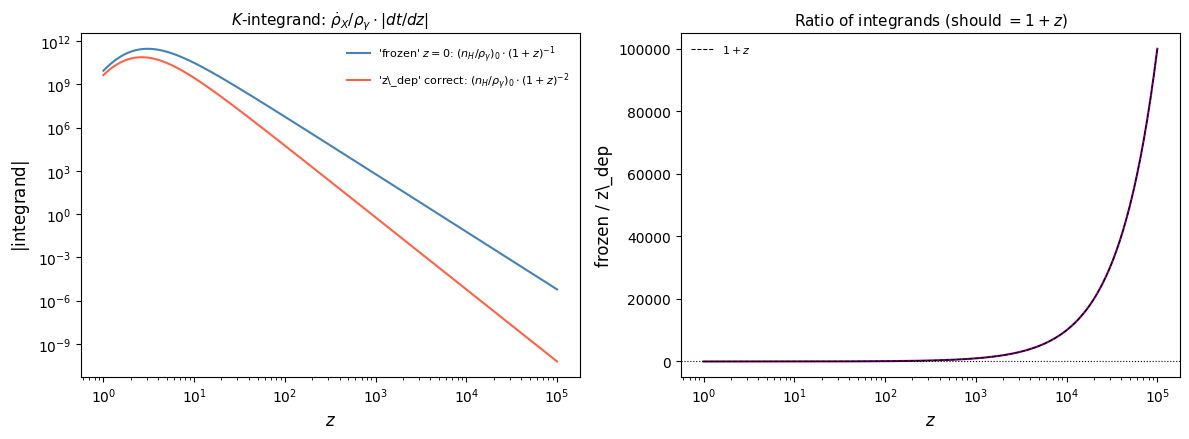


── Solving with RHO_MODE = 'frozen' ──────────────────
  z_end = 200 ... done
  z_end = 2e+05 ... done
  z_end = 5e+05 ... done
  z_end = 1e+06 ... done

── Solving with RHO_MODE = 'z_dep' ──────────────────
  z_end = 200 ... done
  z_end = 2e+05 ... done
  z_end = 5e+05 ... done
  z_end = 1e+06 ... done


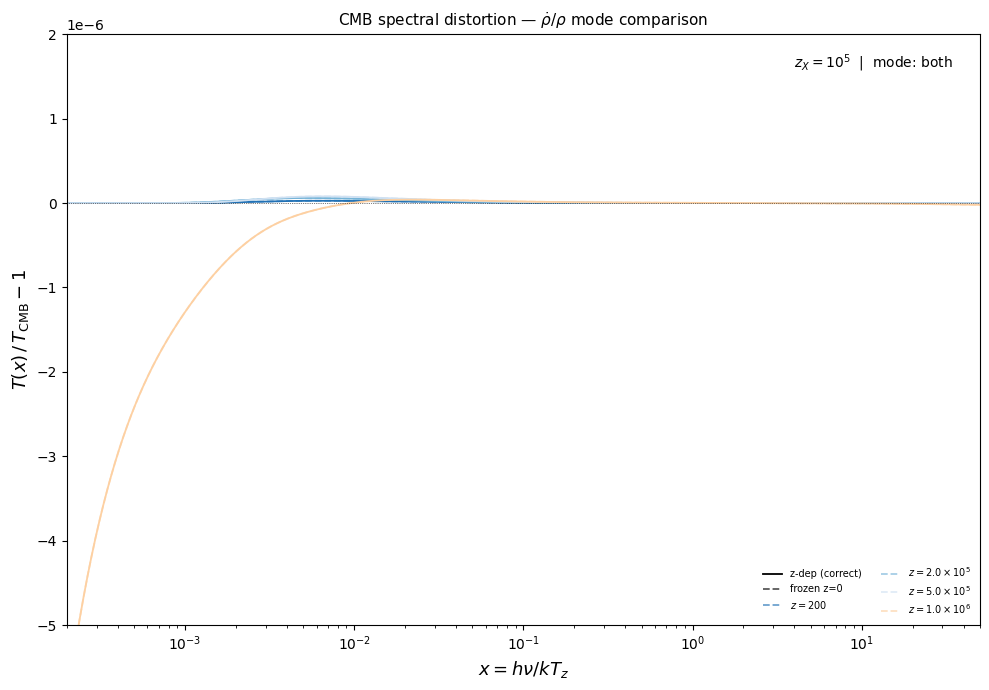

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from spectroxide.solver import solve
from spectroxide.cosmology import Cosmology
from scipy.integrate import quad
import warnings

cosmo = Cosmology.default()

# ── Physical constants ────────────────────────────────────────────────────────
EV_IN_JOULES = 1.602176634e-19
K_BOLTZMANN  = 1.380649e-23
HBAR         = 1.054571817e-34
C_LIGHT      = 2.99792458e8
G_NEWTON     = 6.67430e-11
M_PROTON     = 1.67262192e-27
MPC_IN_M     = 3.085677581e22

# ── Cosmological parameters ───────────────────────────────────────────────────
H0          = 100.0 * cosmo.h * 1e3 / MPC_IN_M
rho_crit    = 3.0 * H0**2 / (8.0 * np.pi * G_NEWTON)
rho_gamma_0 = (np.pi**2 / 15.0) * (K_BOLTZMANN * cosmo.t_cmb)**4 / (HBAR * C_LIGHT)**3
Omega_b     = cosmo.omega_b / cosmo.h**2
n_h_0       = (1.0 - cosmo.y_p) * Omega_b * rho_crit / M_PROTON

Omega_m   = cosmo.omega_m
N_EFF     = cosmo.n_eff
Omega_rel = (rho_gamma_0 / rho_crit) * \
            (1.0 + N_EFF * (7.0/8.0) * (4.0/11.0)**(4.0/3.0))
Omega_lam = 1.0 - Omega_m - Omega_rel

# ── Decaying particle parameters ──────────────────────────────────────────────
Z_X       = 1e5
GAMMA_X   = 1.0 / 2.4e9
DELTA_RHO = 1.3e-6


# ════════════════════════════════════════════════════════════════════════════
#  RHO_MODE controls how n_H / rho_gamma is treated in the K-integral.
#
#  'frozen'  — original code behaviour: both n_H and rho_gamma are fixed at
#              their z=0 values, so the ratio is a constant prefactor and
#              only one explicit (1+z)^-1 appears in the integrand:
#
#              integrand ∝ (n_h_0 / rho_gamma_0) · (1+z)^{-1} · exp(...)
#
#  'z_dep'   — physically correct: n_H ∝ (1+z)^3 and rho_gamma ∝ (1+z)^4,
#              so their ratio scales as (1+z)^{-1}, giving an extra power:
#
#              integrand ∝ (n_h_0 / rho_gamma_0) · (1+z)^{-2} · exp(...)
#
#  'both'    — compute K under both assumptions, print a comparison table,
#              run the solver for both, and overplot the distortion spectra
#              on the same axes (solid = z_dep, dashed = frozen).
#
#  Change the string below to switch modes.
# ════════════════════════════════════════════════════════════════════════════
RHO_MODE = 'both'   # <─── set to 'frozen', 'z_dep', or 'both'


# ── Cosmic time (unit-safe, no astropy) ──────────────────────────────────────
def cosmic_time_s(z):
    """Friedmann integral for cosmic time at redshift z [seconds]."""
    def dtz(zp):
        return 1.0 / ((1 + zp) * H0 * np.sqrt(
            Omega_m   * (1+zp)**3 +
            Omega_rel * (1+zp)**4 +
            Omega_lam))
    t, _ = quad(dtz, z, np.inf, limit=300)
    return t


def E(z):
    """Dimensionless Hubble rate E(z) = H(z)/H0."""
    return np.sqrt(Omega_m*(1+z)**3 + Omega_rel*(1+z)**4 + Omega_lam)


# ── K-integral builder ───────────────────────────────────────────────────────
def build_integrand(mode):
    """
    Returns the integrand function for K under the requested rho_mode.

    The integrand comes from the energy-injection rate per photon:

        dQ/dz = Gamma_X · [n_X(z) / rho_gamma(z)] · exp(-Gamma_X · t) · |dt/dz|

    n_X(z) ∝ n_H(z) ∝ (1+z)^3   (baryons dilute as comoving volume)
    rho_gamma(z) ∝ (1+z)^4       (photon energy density)

    mode='frozen' : treats n_H/rho_gamma as the z=0 constant n_h_0/rho_gamma_0
                    → one explicit (1+z)^-1 in the integrand (original code).
    mode='z_dep'  : applies the correct (1+z)^3/(1+z)^4 = (1+z)^-1 scaling on
                    top of the z=0 prefactor → (1+z)^-2 total.
    """
    if mode == 'frozen':
        # n_H / rho_gamma held at z=0 values — missing (1+z)^-1 from redshifting
        def integrand(z):
            t    = cosmic_time_s(z)
            dtdz = 1.0 / ((1 + z) * H0 * E(z))
            return (GAMMA_X * (n_h_0 / rho_gamma_0)
                    * (1+z)**(-1)          # ← only one power; ratio not evolved
                    * np.exp(-GAMMA_X * t)
                    * dtdz)
    elif mode == 'z_dep':
        # n_H(z)/rho_gamma(z) = (n_h_0/rho_gamma_0) · (1+z)^{3-4} = · (1+z)^{-1}
        def integrand(z):
            t    = cosmic_time_s(z)
            dtdz = 1.0 / ((1 + z) * H0 * E(z))
            return (GAMMA_X * (n_h_0 / rho_gamma_0)
                    * (1+z)**(-2)          # ← correct: extra (1+z)^-1 from ratio
                    * np.exp(-GAMMA_X * t)
                    * dtdz)
    else:
        raise ValueError(f"Unknown mode '{mode}'. Use 'frozen', 'z_dep', or 'both'.")
    return integrand


def compute_K(mode):
    ig = build_integrand(mode)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        K, err = quad(ig, 0, Z_X, limit=300)
    return K, err


# ── Compute K values ──────────────────────────────────────────────────────────
modes_to_run = ['frozen', 'z_dep'] if RHO_MODE == 'both' else [RHO_MODE]

K_values = {}
F_values = {}
for mode in modes_to_run:
    K, err = compute_K(mode)
    F      = (DELTA_RHO / K) / EV_IN_JOULES
    K_values[mode] = K
    F_values[mode] = F
    print(f"[{mode:6s}]  K = {K:.4e}   (quad err = {err:.1e})   F_X = {F:.4e} eV")

if RHO_MODE == 'both':
    ratio = K_values['frozen'] / K_values['z_dep']
    print(f"\nK_frozen / K_z_dep  = {ratio:.4g}   "
          f"→ F_X differs by the same factor ({ratio:.4g}×)")
    print("  Physical meaning: 'frozen' overestimates K by this factor,")
    print("  so it underestimates F_X (energy per baryon) by the same factor.")


# ── Integrand diagnostic plot (always shown) ──────────────────────────────────
zarr = np.geomspace(1.0, Z_X, 400)

ig_vals = {}
for mode in modes_to_run:
    ig = build_integrand(mode)
    ig_vals[mode] = np.array([ig(z) for z in zarr])

fig_diag, axes = plt.subplots(1, 2, figsize=(12, 4.5))
colours = {'frozen': 'steelblue', 'z_dep': 'tomato'}
labels  = {
    'frozen': r"'frozen' $z=0$: $(n_H/\rho_\gamma)_0 \cdot (1+z)^{-1}$",
    'z_dep' : r"'z\_dep' correct: $(n_H/\rho_\gamma)_0 \cdot (1+z)^{-2}$",
}
for mode in modes_to_run:
    axes[0].loglog(zarr, np.abs(ig_vals[mode]),
                   color=colours[mode], label=labels[mode], lw=1.5)

axes[0].set_xlabel(r'$z$', fontsize=12)
axes[0].set_ylabel(r'$|$integrand$|$', fontsize=12)
axes[0].set_title(r'$K$-integrand: $\dot{\rho}_X/\rho_\gamma \cdot |dt/dz|$', fontsize=11)
axes[0].legend(fontsize=8, frameon=False)

if RHO_MODE == 'both':
    ratio_arr = ig_vals['frozen'] / ig_vals['z_dep']
    axes[1].semilogx(zarr, ratio_arr, color='purple', lw=1.5)
    axes[1].axhline(1.0, ls=':', color='k', lw=0.8)
    axes[1].set_xlabel(r'$z$', fontsize=12)
    axes[1].set_ylabel(r'frozen / z\_dep', fontsize=12)
    axes[1].set_title(r'Ratio of integrands (should $= 1+z$)', fontsize=11)
    # overplot the (1+z) line to confirm the power-law
    axes[1].semilogx(zarr, 1+zarr, color='k', ls='--', lw=0.8, label=r'$1+z$')
    axes[1].legend(fontsize=8, frameon=False)
else:
    axes[1].set_visible(False)

plt.tight_layout()
plt.savefig('integrand_diagnostic.pdf', dpi=150)
plt.show()


# ── Brightness temperature ────────────────────────────────────────────────────
def brightness_temp_exact(x, delta_n):
    xc  = np.clip(np.asarray(x, dtype=float), 1e-12, None)
    n0  = 1.0 / np.expm1(np.clip(xc, None, 500.0))
    n_x = n0 + delta_n
    bad = int(np.sum(n_x <= 0))
    if bad:
        warnings.warn(f"brightness_temp_exact: {bad} point(s) with n_x<=0 → nan",
                      RuntimeWarning, stacklevel=2)
    dTb = np.where(
        n_x > 0,
        xc / np.log1p(1.0 / np.where(n_x > 0, n_x, 1.0)) - 1.0,
        np.nan,
    )
    return dTb


# ── Snapshot redshifts ────────────────────────────────────────────────────────
Z_EARLY = [1e6, 5e5, 2e5]
Z_LATE  = [200]
Z_ALL   = sorted(Z_EARLY + Z_LATE)


# ── Run solver ────────────────────────────────────────────────────────────────
snapshots = {}   # snapshots[mode][z_end] = (x, delta_n, mu, y)

for mode in modes_to_run:
    snapshots[mode] = {}
    print(f"\n── Solving with RHO_MODE = '{mode}' ──────────────────")
    for z_end in Z_ALL:
        print(f"  z_end = {z_end:.3g} ...", end=" ", flush=True)
        r = solve(
            injection={
                'type'    : 'decaying_particle',
                'f_x'     : F_values[mode],
                'gamma_x' : GAMMA_X,
            },
            delta_rho         = DELTA_RHO,
            z_end             = z_end,
            x_min             = 1.5e-4,
            x_max             = 80.0,
            n_x               = 1000,
            method            = 'pde',
            production_grid   = True,
            number_conserving = False,
        )
        snapshots[mode][z_end] = (r.x, r.delta_n, r.mu, r.y)
        print("done")


# ── Plot ──────────────────────────────────────────────────────────────────────
cmap_e = plt.cm.Blues_r
cmap_l = plt.cm.Oranges
_LS    = ['-', '--', '-.', (0,(5,1)), (0,(3,1,1,1)), (0,(1,1))]

# Line style by mode so both can coexist on the same axes
MODE_STYLE = {'frozen': '--', 'z_dep': '-'}
MODE_ALPHA  = {'frozen': 0.65, 'z_dep': 1.0}

def zlab(z):
    for base, exp in [(1e6,6),(1e5,5),(1e4,4),(1e3,3)]:
        if z >= base * 0.9:
            return rf'$z={z/base:.1f}\times10^{exp}$'
    return rf'$z={int(z)}$'


fig, ax = plt.subplots(figsize=(10, 7))

for mode in modes_to_run:
    mls   = MODE_STYLE.get(mode, '-')
    malph = MODE_ALPHA.get(mode, 1.0)

    for i, z in enumerate(sorted(Z_EARLY, reverse=True)):
        x_arr, dn, _, _ = snapshots[mode][z]
        dT = brightness_temp_exact(x_arr, dn)
        c  = cmap_e(0.25 + 0.55 * i / max(len(Z_EARLY)-1, 1))
        lbl = (zlab(z) if mode == modes_to_run[0]
               else f"{zlab(z)} [frozen]")
        ax.semilogx(x_arr, dT, color=c, ls=mls, lw=1.3,
                    alpha=malph, label=lbl)

    for i, z in enumerate(sorted(Z_LATE, reverse=True)):
        x_arr, dn, _, _ = snapshots[mode][z]
        dT = brightness_temp_exact(x_arr, dn)
        c  = cmap_l(0.25 + 0.55 * i / max(len(Z_LATE)-1, 1))
        lbl = (zlab(z) if mode == modes_to_run[0]
               else f"{zlab(z)} [frozen]")
        ax.semilogx(x_arr, dT, color=c, ls=mls, lw=1.3,
                    alpha=malph, label=lbl)

ax.axhline(0, color='k', lw=0.5, ls=':')
ax.set_xlim(2e-4, 50)
ax.set_ylim(-5e-6, 2e-6)
ax.set_xlabel(r'$x = h\nu / kT_z$', fontsize=13)
ax.set_ylabel(r'$T(x)\,/\,T_{\rm CMB} - 1$', fontsize=13)

# ── mode legend patches ───────────────────────────────────────────────────────
import matplotlib.lines as mlines
handles, lbls = ax.get_legend_handles_labels()
if RHO_MODE == 'both':
    patch_zdep   = mlines.Line2D([], [], color='k', ls='-',  lw=1.3, label="z-dep (correct)")
    patch_frozen = mlines.Line2D([], [], color='k', ls='--', lw=1.3, alpha=0.65, label="frozen z=0")
    handles = [patch_zdep, patch_frozen] + handles[:len(Z_ALL)]
    lbls    = ["z-dep (correct)", "frozen z=0"] + [zlab(z) for z in Z_ALL]

ax.legend(handles, lbls, fontsize=7, frameon=False, loc='lower right', ncol=2)
ax.text(0.97, 0.97, rf'$z_X = 10^5$  |  mode: {RHO_MODE}',
        transform=ax.transAxes, ha='right', va='top', fontsize=10)
ax.set_title(r'CMB spectral distortion — $\dot{\rho}/\rho$ mode comparison',
             fontsize=11)
plt.tight_layout()
plt.savefig('cmb_distortion_rho_check.pdf', dpi=150)
plt.show()

Fig-12 Chluba 2018

/tmp/ipykernel_4868/3280008160.py:36: UserWarning: x_inj=1.00e-03: DC/BR absorption extremely strong at this frequency; survival probability ~ 0.
  batch = run_photon_sweep_batch(


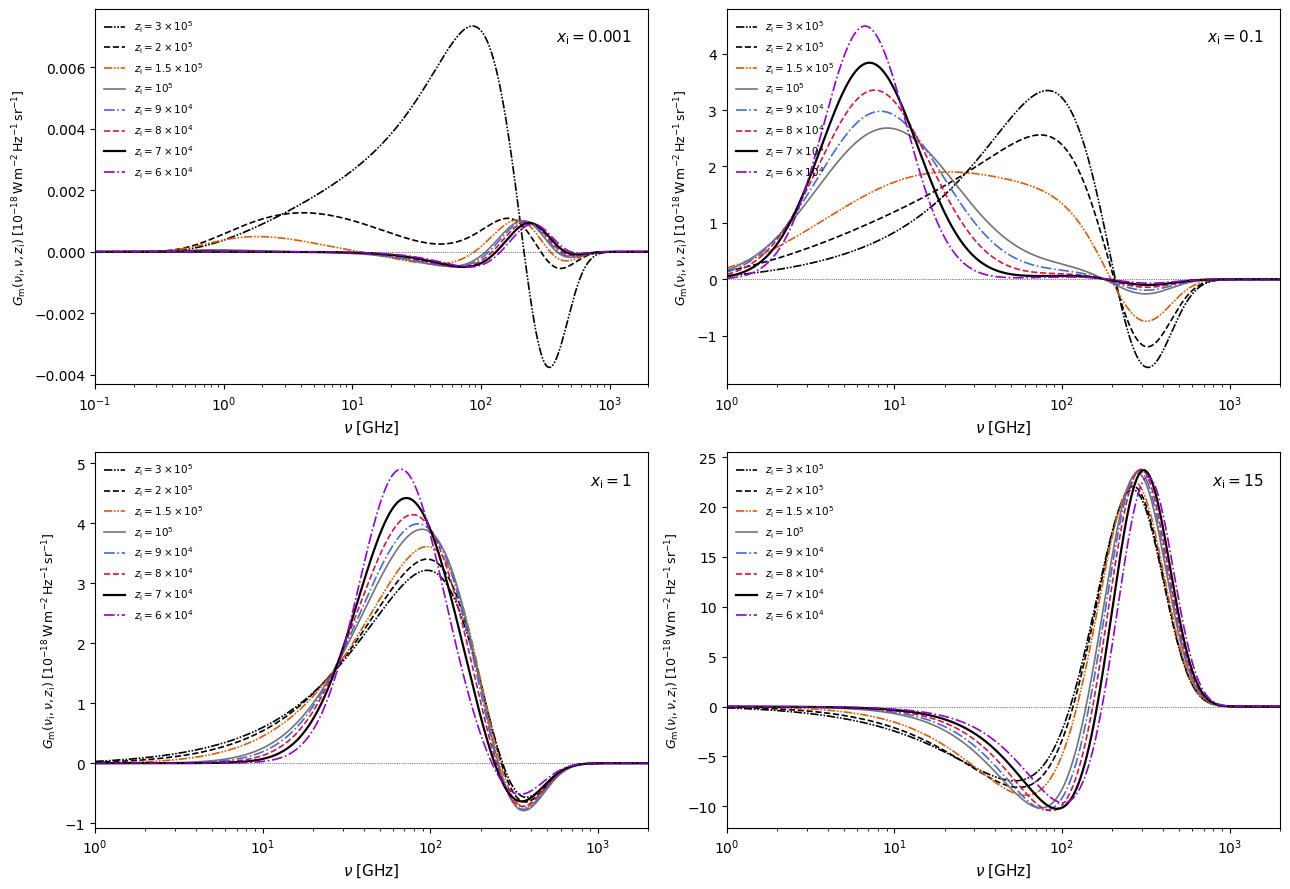

In [ ]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from spectroxide import greens  # for delta_n_to_delta_I

# ── parameters matching the figure ────────────────────────────────────────────
X_INJ_VALUES   = [0.001, 0.1, 1.0, 15.0]
Z_INJECTIONS   = [3e5, 2e5, 1.5e5, 1e5, 9e4, 8e4, 7e4, 6e4]
DELTA_N_OVER_N = 1e-5          # normalisation amplitude (cancel below)

# line styles / colours reproduce the figure's CosmoTherm convention
LINE_KW = [
    dict(color='k',          linestyle=(0,(5,1,1,1,1,1)), lw=1.2),  # 3e5  -..-
    dict(color='k',          linestyle='--',               lw=1.2),  # 2e5  --
    dict(color='#e05c00',    linestyle=(0,(5,1,1,1,1,1)), lw=1.2),  # 1.5e5 -..-
    dict(color='0.45',       linestyle='-',                lw=1.2),  # 1e5  solid grey
    dict(color='royalblue',  linestyle='-.',               lw=1.2),  # 9e4  -.
    dict(color='crimson',    linestyle='--',               lw=1.2),  # 8e4  --
    dict(color='k',          linestyle='-',                lw=1.6),  # 7e4  solid (bold)
    dict(color='darkviolet', linestyle='-.',               lw=1.2),  # 6e4  -.
]
LABELS = [
    r'$z_{\rm i} = 3\times10^5$',
    r'$z_{\rm i} = 2\times10^5$',
    r'$z_{\rm i} = 1.5\times10^5$',
    r'$z_{\rm i} = 10^5$',
    r'$z_{\rm i} = 9\times10^4$',
    r'$z_{\rm i} = 8\times10^4$',
    r'$z_{\rm i} = 7\times10^4$',
    r'$z_{\rm i} = 6\times10^4$',
]

# ── run solver (one call for all x_inj × z_i combinations) ───────────────────
from spectroxide.solver import run_photon_sweep_batch

batch = run_photon_sweep_batch(
    x_inj_values   = X_INJ_VALUES,
    delta_n_over_n = DELTA_N_OVER_N,
    z_injections   = Z_INJECTIONS,
    production_grid = True,        # 4 000-pt grid, publication quality
)
# batch is a list[dict], one entry per x_inj.
# Each dict: {'x_inj': float, 'delta_n_over_n': float, 'results': [per-z dicts]}
# Per-z dict keys: 'z_h', 'x', 'delta_n', ...

def _find_result(results_list, z_target):
    """Return the entry whose z_h is closest to z_target."""
    return min(results_list, key=lambda r: abs(r['z_h'] - z_target))

# ── unit factor: Jy/sr → 10^{-18} W m^{-2} Hz^{-1} sr^{-1}, per unit ΔN/N ──
#   delta_n_to_delta_I returns  ΔI  in Jy/sr  (= 10^{-26} W m^{-2} Hz^{-1} sr^{-1})
#   G_m  =  ΔI [Jy/sr] / ΔN/N  ×  (10^{-26} / 10^{-18})
#         =  ΔI [Jy/sr] × 1e-8 / DELTA_N_OVER_N
UNIT = 1e-8 / DELTA_N_OVER_N          # = 1e-3 for the default 1e-5 amplitude

# ── figure layout ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

x_panel_labels = [r'$x_{\rm i} = 0.001$', r'$x_{\rm i} = 0.1$',
                  r'$x_{\rm i} = 1$',     r'$x_{\rm i} = 15$']
nu_min_panel   = [0.1, 1.0, 1.0, 1.0]    # match figure x-axis starts

for ax, sweep, xi_label, nu_min in zip(
        axes.flat, batch["results"], x_panel_labels, nu_min_panel):

    results = sweep['results']

    for z_i, lkw, label in zip(Z_INJECTIONS, LINE_KW, LABELS):
        r      = _find_result(results, z_i)
        x_arr  = np.asarray(r['x'])
        dn     = np.asarray(r['delta_n'])

        nu_GHz, dI_Jy = greens.delta_n_to_delta_I(x_arr, dn)

        # Green's function in 10^{-18} W m^{-2} Hz^{-1} sr^{-1}
        G_m = dI_Jy * UNIT

        mask = nu_GHz >= nu_min
        ax.semilogx(nu_GHz[mask], G_m[mask], label=label, **lkw)

    ax.axhline(0, color='k', lw=0.5, ls=':')
    ax.set_xlim(nu_min, 2e3)
    ax.set_xlabel(r'$\nu\;[\mathrm{GHz}]$', fontsize=11)
    ax.set_ylabel(
        r'$G_{\rm m}(\nu_{\rm i},\nu,z_{\rm i})\;'
        r'[10^{-18}\,\mathrm{W\,m^{-2}\,Hz^{-1}\,sr^{-1}}]$',
        fontsize=9)
    ax.legend(fontsize=7.5, frameon=False, loc='upper left')
    ax.text(0.97, 0.95, xi_label, transform=ax.transAxes,
            ha='right', va='top', fontsize=11)

plt.tight_layout()
plt.savefig('photon_greens_function_G_m.pdf', dpi=150, bbox_inches='tight')
plt.show()

Fig-11 Chluba 2018

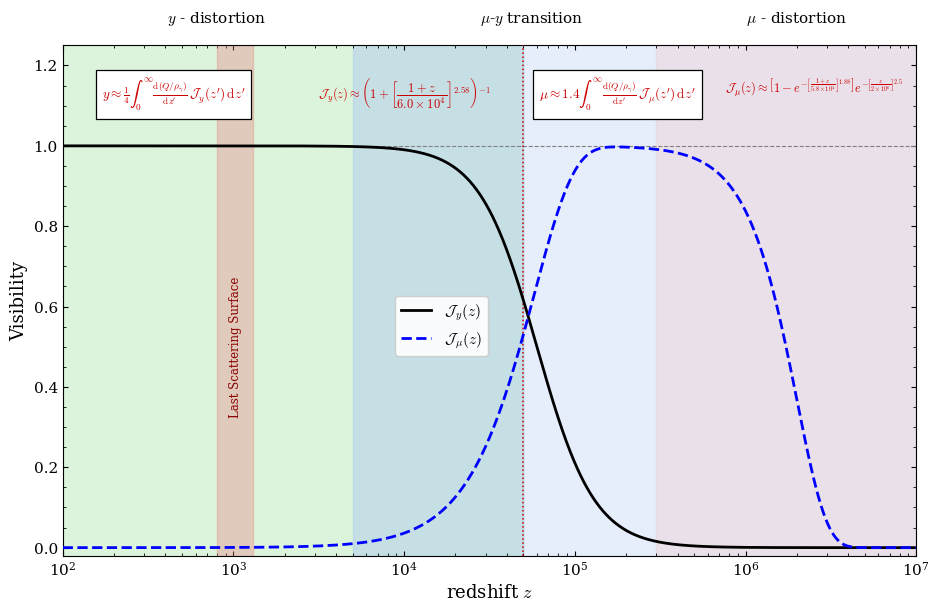

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.ticker import LogLocator, NullFormatter
from matplotlib import rcParams

# ── font / style ──────────────────────────────────────────────────────────────
rcParams['font.family']      = 'serif'
rcParams['mathtext.fontset'] = 'cm'

# ── redshift grid (log-spaced for smooth curves) ──────────────────────────────
z = np.logspace(2, 7, 8000)

# ── visibility functions (Chluba 2013 / 2018) ─────────────────────────────────
def J_y(z):
    return 1.0 / (1.0 + ((1.0 + z) / 6.0e4)**2.58)

def J_mu(z):
    return (1.0 - np.exp(-((1.0 + z) / 5.8e4)**1.88)) * np.exp(-(z / 2e6)**2.5)

# ── figure / axes ─────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9.5, 6.2))
fig.subplots_adjust(top=0.82, bottom=0.11, left=0.09, right=0.97)

# ── coloured background bands ─────────────────────────────────────────────────
#   green  – y-distortion   (z < ~5×10⁴)
#   blue   – μ-y transition  (5×10³ < z < 5×10⁴ ish, overlapping)
#   red    – μ-distortion   (z > 5×10⁴)

# Full green background first (y-distortion side)
ax.axvspan(1e2,  5e4, color='#b3e6b3', alpha=0.45, zorder=0)   # green
# Blue overlay for the transition/mu region
ax.axvspan(5e3,  5e4, color='#aac8f0', alpha=0.45, zorder=1)   # blue overlap in middle
ax.axvspan(5e4,  1e7, color='#aac8f0', alpha=0.30, zorder=0)   # blue (mu side)
# Red-dotted overlay for mu-distortion (high z)
ax.axvspan(3e5,  1e7, color='#f5b8b8', alpha=0.25, zorder=1)   # pink-red

# Last Scattering Surface – narrow vertical pink/red band
ax.axvspan(8e2, 1.3e3, color='#e88080', alpha=0.35, zorder=2)

# ── vertical dotted boundary line (μ-y transition) ───────────────────────────
ax.axvline(5e4, color='#cc0000', lw=1.1, ls=':', zorder=5)

# ── horizontal dashed line at visibility = 1 ─────────────────────────────────
ax.axhline(1.0, color='gray', lw=0.8, ls='--', zorder=3)

# ── main curves ───────────────────────────────────────────────────────────────
ax.plot(z, J_y(z),  color='black', lw=2.0, ls='-',  zorder=6,
        label=r'$\mathcal{J}_y(z)$')
ax.plot(z, J_mu(z), color='blue',  lw=2.0, ls='--', zorder=6,
        label=r'$\mathcal{J}_\mu(z)$')

# ── "Last Scattering Surface" rotated text ────────────────────────────────────
ax.text(1.03e3, 0.50, 'Last Scattering Surface',
        rotation=90, va='center', ha='center',
        fontsize=8.5, color='#8B0000', zorder=7)

# ── formula boxes ─────────────────────────────────────────────────────────────
box_kw = dict(boxstyle='square,pad=0.45', facecolor='white',
              edgecolor='black', lw=0.9)

# y-distortion formula box
ax.text(0.13, 0.94,
        r'$y \approx \frac{1}{4}\int_0^{\infty}'
        r'\frac{\mathrm{d}(Q/\rho_\gamma)}{\mathrm{d}z^{\prime}}'
        r'\,\mathcal{J}_y(z^{\prime})\,\mathrm{d}z^{\prime}$',
        transform=ax.transAxes, fontsize=9.5, color='#cc0000',
        va='top', ha='center', bbox=box_kw, zorder=8)

# mu-distortion formula box
ax.text(0.65, 0.94,
        r'$\mu \approx 1.4\int_0^{\infty}'
        r'\frac{\mathrm{d}(Q/\rho_\gamma)}{\mathrm{d}z^{\prime}}'
        r'\,\mathcal{J}_\mu(z^{\prime})\,\mathrm{d}z^{\prime}$',
        transform=ax.transAxes, fontsize=9.5, color='#cc0000',
        va='top', ha='center', bbox=box_kw, zorder=8)

# J_y analytic form
ax.text(0.40, 0.94,
        r'$\mathcal{J}_y(z)\approx\left(1+\left[\dfrac{1+z}{6.0\times10^4}\right]^{2.58}\right)^{-1}$',
        transform=ax.transAxes, fontsize=9.0, color='#cc0000',
        va='top', ha='center', zorder=8)

# J_mu analytic form
ax.text(0.88, 0.94,
        r'$\mathcal{J}_\mu(z)\approx\left[1-e^{-\left[\frac{1+z}{5.8\times10^4}\right]^{1.88}}\right]'
        r'e^{-\left[\frac{z}{2\times10^6}\right]^{2.5}}$',
        transform=ax.transAxes, fontsize=9.0, color='#cc0000',
        va='top', ha='center', zorder=8)


# Labels placed in figure-fraction coords above the plot
label_y = 1.035  # just above the top spine in axes-fraction
ax.text(0.18, label_y, r'$y$ - distortion',
        transform=ax.transAxes, ha='center', va='bottom',
        fontsize=11, color='black')
ax.text(0.55, label_y, r'$\mu$-$y$ transition',
        transform=ax.transAxes, ha='center', va='bottom',
        fontsize=11, color='black')
ax.text(0.86, label_y, r'$\mu$ - distortion',
        transform=ax.transAxes, ha='center', va='bottom',
        fontsize=11, color='black')

# ── axes formatting ───────────────────────────────────────────────────────────
ax.set_xscale('log')
ax.set_xlim(1e2, 1e7)
ax.set_ylim(-0.02, 1.25)

ax.set_xlabel(r'redshift $z$', fontsize=13)
ax.set_ylabel(r'Visibility', fontsize=13)

ax.tick_params(axis='both', which='both', direction='in',
               top=True, right=True, labelsize=11)

# Major log ticks
ax.xaxis.set_major_locator(LogLocator(base=10, numticks=10))
ax.xaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10)*0.1, numticks=50))
ax.yaxis.set_major_locator(plt.MultipleLocator(0.2))
ax.yaxis.set_minor_locator(plt.MultipleLocator(0.05))

# ── legend ────────────────────────────────────────────────────────────────────
ax.legend(fontsize=11, framealpha=0.9, loc='center left',
          bbox_to_anchor=(0.38, 0.45))

plt.tight_layout()
plt.show()

In [ ]:
import os
os.environ['DH_DATA_DIR'] = '/home/batman/Documents/Work/CMBSD/DHdata_hdf5'

import darkhistory.config as dh_config
dh_config.data_path_default = '/home/batman/Documents/Work/CMBSD/DarkHistory/DHdata_hdf5'

[2026-06-16 20:52:17,155] INFO: darkhistory.config: Loaded deposition transfer functions.
[2026-06-16 20:52:22,018] INFO: darkhistory.config: Loaded ICS transfer functions.
 24%|██▎       | 20/85 [00:14<00:49,  1.30it/s]/home/batman/Documents/Work/.venv/lib/python3.12/site-packages/darkhistory/history/tla.py:387: RuntimeWarning: overflow encountered in exp
  T_m = np.exp(log_T_m)
/home/batman/Documents/Work/.venv/lib/python3.12/site-packages/darkhistory/history/tla.py:270: RuntimeWarning: overflow encountered in exp
  T_m = np.exp(log_T_m)
/home/batman/Documents/Work/.venv/lib/python3.12/site-packages/darkhistory/history/tla.py:316: RuntimeWarning: overflow encountered in exp
  T_m = np.exp(log_T_m)
/home/batman/Documents/Work/.venv/lib/python3.12/site-packages/darkhistory/history/tla.py:374: RuntimeWarning: overflow encountered in exp
  T_m = np.exp(log_T_m)
/home/batman/Documents/Work/.venv/lib/python3.12/site-packages/darkhistory/history/tla.py:405: RuntimeWarning: invalid value enc

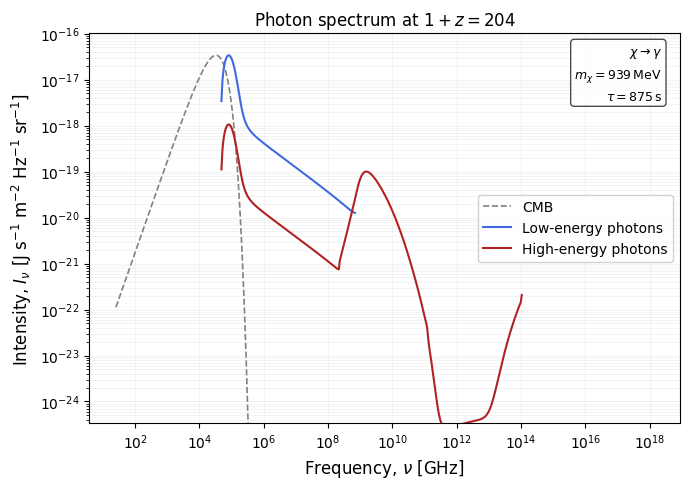

In [ ]:
from darkhistory.main import evolve
import darkhistory.physics as phys
import matplotlib.pyplot as plt
import numpy as np

solution = evolve(
    DM_process = 'decay',   # 'decay' or 'swave'
    mDM = 9.39565e8,              # [eV] (mass of a neutron)
    lifetime = 874.9,        # [s] (lifetime of a neutron)
    primary = 'phot_delta', # primary decay channel
    start_rs = 3000,        # starting 1+z
    end_rs = 200,          # ending 1+z
    coarsen_factor = 32,    # log(1+z) would change by 0.001 * coarsen_factor for next step
    backreaction = False,    # Enables injection backreaction on matter temperature and ionization.
    helium_TLA = False,      # Enables the Helium Three Level Atom (TLA) solver.
    reion_switch = False,    # Enables a customizable reionization energy injection.
)

# ── constants ──────────────────────────────────────────────────────────────
eV_to_J    = 1.60218e-19        # 1 eV in Joules
eV_to_Hz   = 2.41799e14        # 1 eV / h  in Hz
hplanck    = 4.13567e-15       # Planck's constant in eV·s
c_light    = 3e8               # m/s
sr_4pi     = 4 * np.pi

# ── pick redshift snapshot ─────────────────────────────────────────────────
idx    = -1
rs_val = solution['rs'][idx]

# ── extract spectra ────────────────────────────────────────────────────────
hi = solution['highengphot'][idx]
lo = solution['lowengphot'][idx]

# energies in eV → frequencies in GHz
hi_freq_GHz = hi.eng * eV_to_Hz / 1e9
lo_freq_GHz = lo.eng * eV_to_Hz / 1e9

# ── convert dN/dE → I_nu  [J s^-1 m^-2 Hz^-1 sr^-1] ─────────────────────
# I_nu = (c/4π) * E[J] * (dN/dE)[eV^-1] * (dE/dnu)[s] / V_comoving
# Simplified: I_nu ∝ E^2 * dN/dE  (in eV units, then rescale)
# The cleanest approach for a relative/shape plot:
#   I_nu ∝ (E in eV) * dN/dE   then convert axis units

def to_Inu(spec):
    """
    Returns I_nu in arbitrary but self-consistent units.
    dN/dE [eV^-1] * E^2 [eV^2] * (eV_to_J / eV_to_Hz) → J s^-1 m^-2 Hz^-1 sr^-1 shape
    """
    eng   = spec.eng                        # eV
    dNdE  = spec.dNdE                       # eV^-1
    # dnu = dE / h  =>  dN/dnu = dN/dE * h  =>  I_nu ∝ E * dN/dnu = E * dN/dE * h
    Inu   = eng * dNdE * hplanck            # eV * eV^-1 * eV*s = eV*s  (shape only)
    Inu  *= eV_to_J / (sr_4pi)             # rough normalisation to J/s/m²/Hz/sr shape
    return Inu

hi_Inu = to_Inu(hi)
lo_Inu = to_Inu(lo)

# ── mask near-zero / negative values so loglog doesn't blow up ─────────────
def safe_mask(arr, floor=1e-100):
    masked = np.where(arr > floor, arr, np.nan)
    return masked

hi_Inu = safe_mask(hi_Inu)
lo_Inu = safe_mask(lo_Inu)

# ── CMB blackbody (dashed background) ─────────────────────────────────────
T_cmb_now = 2.725          # K
T_cmb_z   = T_cmb_now * rs_val   # CMB temperature at this redshift
kb_eV     = 8.617e-5      # Boltzmann in eV/K

# Build blackbody over combined frequency range
freq_cmb_GHz = np.logspace(
    np.log10(min(lo_freq_GHz[0], hi_freq_GHz[0])),
    np.log10(max(lo_freq_GHz[-1], hi_freq_GHz[-1])),
    500
)
nu_Hz   = freq_cmb_GHz * 1e9
x       = (hplanck * nu_Hz) / (kb_eV * T_cmb_z)   # hν/kT
# Planck function B_nu [J/s/m^2/Hz/sr]  (shape; normalisation arbitrary)
B_nu = nu_Hz**3 / (np.exp(np.clip(x, 0, 500)) - 1)
B_nu /= B_nu[np.isfinite(B_nu)].max()              # normalise to peak=1
B_nu *= np.nanmax([np.nanmax(hi_Inu), np.nanmax(lo_Inu)])  # match signal peak

# ── plot ───────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figssize=(7, 5))

# CMB blackbody dashed
ax.plot(freq_cmb_GHz, B_nu, color='gray', lw=1.2, ls='--', zorder=1, label='CMB')

# Low-energy photons
ax.plot(lo_freq_GHz, lo_Inu, color='royalblue', lw=1.5, label='Low-energy photons', zorder=3)

# High-energy photons
ax.plot(hi_freq_GHz, hi_Inu, color='firebrick', lw=1.5, label='High-energy photons', zorder=3)

# ── formatting to match reference style ────────────────────────────────────
ax.set_xscale('log')
ax.set_yscale('log')

ax.set_xlabel(r'Frequency, $\nu$ [GHz]', fontsize=12)
ax.set_ylabel(r'Intensity, $I_\nu$ [J s$^{-1}$ m$^{-2}$ Hz$^{-1}$ sr$^{-1}$]', fontsize=12)
ax.set_title(f'Photon spectrum at $1+z = {rs_val:.0f}$', fontsize=12)

# Tight y-range — avoids the 10^-83 nonsense
ymax = np.nanmax([np.nanmax(hi_Inu), np.nanmax(lo_Inu), np.nanmax(B_nu)])
ax.set_ylim(ymax * 1e-8, ymax * 3)

ax.legend(fontsize=10, framealpha=0.9)
ax.grid(True, which='both', alpha=0.2, lw=0.5)

# Physics annotation (like the reference)
ax.text(0.97, 0.97,
    r'$\chi \to \gamma$' + '\n'
    r'$m_\chi = 939\,\mathrm{MeV}$' + '\n'
    r'$\tau = 875\,\mathrm{s}$',
    transform=ax.transAxes, ha='right', va='top',
    fontsize=9, linespacing=1.6,
    bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.7)
)

plt.tight_layout()
plt.show()

### Dark Baryon -> Neutron decay

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from spectroxide.solver import solve

# ── save location (change these manually) ─────────────────────────────────────
SAVE_DIR  = "spectroxide/RUNS"          # folder name
SAVE_FILE = "snapshots_tau1e9_dm50MeV" # file name (no extension needed)
# ─────────────────────────────────────────────────────────────────────────────

save_path = Path(SAVE_DIR)
save_path.mkdir(parents=True, exist_ok=True)

# ── physical parameters ───────────────────────────────────────────────────────
tau_X     = 1e9                   # [s], lifetime of the decaying dark baryon
GAMMA_X   = 1.0 / tau_X          # 1/t_X

# f_x = e_x * m_x * n_x,0/n_H,0
# assuming the neutron is non-relativistic, all the energy goes into photons, e_x * m_x = m_x - m_n = Delta_m 
# from McKeen 2021, two benchmarks are, n_x,0/n_H,0 = 5.4 and 0.01

Delta_m = 50e6      # [eV], energy released per decay (m_x - m_n)
den_fac = 0.01      # n_x,0/n_H,0 (benchmark from McKeen 2021)
F_X = Delta_m * den_fac

# ── snapshot redshifts from Fig. 14, middle panel (z_X = 10^5) ───────────────
Z_VEARLY = [8e6, 2e6]
Z_EARLY  = [8.8e5, 3.1e5, 9.7e4]
Z_LATE   = [6.0e4, 1.4e4, 8.7e3, 4.1e3, 1.1e3, 200]
Z_ALL    = sorted(Z_VEARLY + Z_EARLY + Z_LATE)   # ascending for solver


# ── alternatively: use the exact eq. 35 directly where n_x > 0 ───────────────
def brightness_temp_exact(x, delta_n):
    """
    Applies eq. 35 directly:  T(x)/T_z = x / ln(1 + 1/n_x)
    Falls back to analytic shapes only where n_x ≤ 0 or x > x_thresh.
    """
    xc  = np.clip(np.asarray(x, dtype=float), 1e-12, None)
    n0  = 1.0 / np.expm1(np.clip(xc, None, 500.0))   # Planck distribution
    n_x = n0 + delta_n

    # exact formula
    dTb = xc / np.log1p(1.0 / n_x) - 1.0

    return dTb


# ── load existing data (resume support) ──────────────────────────────────────
npz_file = save_path / f"{SAVE_FILE}.npz"
snapshots = {}

if npz_file.exists():
    print(f"Found existing data at '{npz_file}', loading...")
    existing = np.load(npz_file, allow_pickle=True)
    # stored as flat arrays with z_end encoded in the key names
    loaded_keys = set(existing.files)
    for z in Z_ALL:
        key_x  = f"z{z:.6g}_x"
        key_dn = f"z{z:.6g}_delta_n"
        key_mu = f"z{z:.6g}_mu"
        key_y  = f"z{z:.6g}_y"
        if all(k in loaded_keys for k in [key_x, key_dn, key_mu, key_y]):
            snapshots[z] = (
                existing[key_x],
                existing[key_dn],
                float(existing[key_mu]),
                float(existing[key_y]),
            )
            print(f"  Loaded cached z_end = {z:.3g}")


def save_snapshots():
    """Flatten snapshots dict and save to .npz."""
    flat = {}
    flat["tau_X"]   = np.array(tau_X)
    flat["gamma_x"] = np.array(GAMMA_X)
    flat["Delta_m"] = np.array(Delta_m)
    flat["den_fac"] = np.array(den_fac)
    flat["F_X"]     = np.array(F_X)
    flat["z_all"]   = np.array(Z_ALL)
    for z, (x_arr, dn, mu_r, y_r) in snapshots.items():
        flat[f"z{z:.6g}_x"]       = x_arr
        flat[f"z{z:.6g}_delta_n"] = dn
        flat[f"z{z:.6g}_mu"]      = np.array(mu_r)
        flat[f"z{z:.6g}_y"]       = np.array(y_r)
    np.savez(npz_file, **flat)
    print(f"  → saved to '{npz_file}'")


# ── run solver for each snapshot redshift ─────────────────────────────────────
for z_end in Z_ALL:
    if z_end in snapshots:
        print(f"  z_end = {z_end:.3g} ... skipped (cached)")
        continue

    print(f"  z_end = {z_end:.3g} ...", end=" ", flush=True)
    r = solve(
        injection = {
            'type'    : 'decaying_particle',
            'f_x'     : F_X,
            'gamma_x' : GAMMA_X,
        },
        z_start           = 1e7,
        z_end             = z_end,
        x_min             = 1.5e-4,
        x_max             = 80.0,
        n_x               = 1000,
        method            = 'pde',
        production_grid   = True,
        number_conserving = True,
    )
    snapshots[z_end] = (r.x, r.delta_n, r.mu, r.y)
    print("done")

    # save after every completed run
    save_snapshots()


# ── colour maps matching Fig. 14 style ────────────────────────────────────────
cmap_v = plt.cm.Greens_r
cmap_e = plt.cm.Blues_r
cmap_l = plt.cm.Oranges
_LS    = ['-', '--', '-.', (0,(5,1)), (0,(3,1,1,1)), (0,(1,1))]

def zlab(z):
    for base, exp in [(1e6,6),(1e5,5),(1e4,4),(1e3,3)]:
        if z >= base * 0.9:
            return rf'$z={z/base:.1f}\times10^{exp}$'
    return rf'$z={int(z)}$'

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 7))

for i, z in enumerate(sorted(Z_VEARLY, reverse=True)):
    x_arr, dn, mu_r, y_r = snapshots[z]
    dT = brightness_temp_exact(x_arr, dn)
    c  = cmap_v(0.25 + 0.55 * i / max(len(Z_VEARLY) - 1, 1))
    ax.semilogx(x_arr, dT, color=c, ls=_LS[i % len(_LS)],
                lw=1.2, label=zlab(z))

for i, z in enumerate(sorted(Z_EARLY, reverse=True)):
    x_arr, dn, mu_r, y_r = snapshots[z]
    dT = brightness_temp_exact(x_arr, dn)
    c  = cmap_e(0.25 + 0.55 * i / max(len(Z_EARLY) - 1, 1))
    ax.semilogx(x_arr, dT, color=c, ls=_LS[i % len(_LS)],
                lw=1.2, label=zlab(z))

for i, z in enumerate(sorted(Z_LATE, reverse=True)):
    x_arr, dn, mu_r, y_r = snapshots[z]
    dT = brightness_temp_exact(x_arr, dn)
    c  = cmap_l(0.25 + 0.55 * i / max(len(Z_LATE) - 1, 1))
    ax.semilogx(x_arr, dT, color=c, ls=_LS[i % len(_LS)],
                lw=1.2, label=zlab(z))

ax.axhline(0, color='k', lw=0.5, ls=':')
ax.set_xlim(2e-4, 50)
ax.set_ylim(-30e-6, 2e-6)
ax.set_xlabel(r'$x = h\nu / kT_z$', fontsize=13)
ax.set_ylabel(r'$T(x)\,/\,T_{\rm CMB} - 1$', fontsize=13)
ax.legend(fontsize=7, frameon=False, loc='lower right', ncol=2)

# ── parameter annotation, top right ──────────────────────────────────────────
param_text = '\n'.join([
    rf'$\tau_X = 10^9$ s',
    rf'$\Delta m = 50$ MeV',
    rf'$n_{{X,0}}/n_{{H,0}} = {den_fac}$',
])
ax.text(0.97, 0.97, param_text, transform=ax.transAxes,
        ha='right', va='top', fontsize=11,
        bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.7, edgecolor='0.8'))

ax.set_title(r'CMB spectral distortion — $\chi \rightarrow n + \gamma$ injection',
             fontsize=11)
plt.tight_layout()

# ── save figure alongside the data ───────────────────────────────────────────
fig_file = save_path / f"{SAVE_FILE}.pdf"
plt.savefig(fig_file, dpi=150, bbox_inches='tight')
print(f"Figure saved to '{fig_file}'")

plt.show()

  z_end = 200 ... 

KeyboardInterrupt: 

In [ ]:
"""
Suggestion 1 — dual den_fac comparison.

Runs the same Delta_m and tau_X sweeps for BOTH McKeen 2021 benchmarks:
  den_fac = 0.01  (1% of baryons, safe from CMB eta_b, Fig. 4)
  den_fac = 5.4   (chi = all DM, Fig. 3)

Plots them on the same axes as solid vs dashed lines so the amplitude
difference and shape change are directly visible.
"""

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from spectroxide.solver import solve

# ── save location ─────────────────────────────────────────────────────────────
SAVE_DIR  = "spectroxide/RUNS"
SAVE_FILE = "sweep_dual_denfac"
# ─────────────────────────────────────────────────────────────────────────────

save_path = Path(SAVE_DIR)
save_path.mkdir(parents=True, exist_ok=True)
npz_file  = save_path / f"{SAVE_FILE}.npz"

# ── parameters ────────────────────────────────────────────────────────────────
DEN_FACS = [0.01, 5.4]          # both McKeen 2021 benchmarks
Z_START  = 1e7
Z_END    = 0.0

DELTA_M_VALUES = np.array([10, 15, 20]) * 1e6  # eV
TAU_X_VALUES   = np.logspace(7, 13, 4)                                        # s

# DELTA_M_VALUES = np.array([10, 15, 20, 30, 40, 50, 65, 80, 100, 120]) * 1e6  # eV
# TAU_X_VALUES   = np.logspace(7, 13, 13) 

DELTA_M_PIVOT  = 50e6    # eV
TAU_X_PIVOT    = 1e9     # s

COBE_MU  = 9.0e-5
COBE_Y   = 1.5e-5
PIXIE_MU = 2.0e-8
PIXIE_Y  = 2.0e-8

# ── solver ────────────────────────────────────────────────────────────────────
def run_point(delta_m_ev, tau_x_s, den_fac):
    heavy = den_fac > 1.0   # 5.4 case is much more expensive
    r = solve(
        injection={
            'type'    : 'decaying_particle',
            'f_x'     : delta_m_ev * den_fac,
            'gamma_x' : 1.0 / tau_x_s,
        },
        z_start           = Z_START,
        z_end             = Z_END,
        x_min             = 1.5e-4,
        x_max             = 80.0,
        n_x               = 500  if heavy else 1000,
        method            = 'pde',
        production_grid   = False if heavy else True,
        number_conserving = True,
        timeout           = 3600.0,
    )
    return float(r.mu), float(r.y)


# ── cache: keyed by den_fac ───────────────────────────────────────────────────
# results[den_fac] = { 'mu_dm': array, 'y_dm': array,
#                      'mu_tau': array, 'y_tau': array }
results = {}
for df in DEN_FACS:
    results[df] = {
        'mu_dm'  : np.full(len(DELTA_M_VALUES), np.nan),
        'y_dm'   : np.full(len(DELTA_M_VALUES), np.nan),
        'mu_tau' : np.full(len(TAU_X_VALUES),   np.nan),
        'y_tau'  : np.full(len(TAU_X_VALUES),   np.nan),
    }

if npz_file.exists():
    print(f"Loading cache from '{npz_file}' ...")
    cache = np.load(npz_file, allow_pickle=True)
    for df in DEN_FACS:
        tag = f"df{df:.4g}"
        for i, dm in enumerate(DELTA_M_VALUES):
            k = f"{tag}_dm{dm:.6g}_mu"
            if k in cache:
                results[df]['mu_dm'][i] = float(cache[k])
                results[df]['y_dm'][i]  = float(cache[f"{tag}_dm{dm:.6g}_y"])
        for i, tx in enumerate(TAU_X_VALUES):
            k = f"{tag}_tau{tx:.6g}_mu"
            if k in cache:
                results[df]['mu_tau'][i] = float(cache[k])
                results[df]['y_tau'][i]  = float(cache[f"{tag}_tau{tx:.6g}_y"])


def save_cache():
    flat = {
        "delta_m_axis" : DELTA_M_VALUES,
        "tau_x_axis"   : TAU_X_VALUES,
        "den_facs"     : np.array(DEN_FACS),
        "delta_m_pivot": np.array(DELTA_M_PIVOT),
        "tau_x_pivot"  : np.array(TAU_X_PIVOT),
    }
    for df in DEN_FACS:
        tag = f"df{df:.4g}"
        for i, dm in enumerate(DELTA_M_VALUES):
            if not np.isnan(results[df]['mu_dm'][i]):
                flat[f"{tag}_dm{dm:.6g}_mu"] = np.array(results[df]['mu_dm'][i])
                flat[f"{tag}_dm{dm:.6g}_y"]  = np.array(results[df]['y_dm'][i])
        for i, tx in enumerate(TAU_X_VALUES):
            if not np.isnan(results[df]['mu_tau'][i]):
                flat[f"{tag}_tau{tx:.6g}_mu"] = np.array(results[df]['mu_tau'][i])
                flat[f"{tag}_tau{tx:.6g}_y"]  = np.array(results[df]['y_tau'][i])
    np.savez(npz_file, **flat)
    print(f"  → saved to '{npz_file}'")


# ── run sweeps ────────────────────────────────────────────────────────────────
for df in DEN_FACS:
    tag = f"den_fac={df}"

    print(f"\n── Delta_m sweep  ({tag}, tau_X={TAU_X_PIVOT:.1e} s) ──")
    for i, dm in enumerate(DELTA_M_VALUES):
        if not np.isnan(results[df]['mu_dm'][i]):
            print(f"  Delta_m = {dm/1e6:.0f} MeV ... skipped (cached)")
            continue
        print(f"  Delta_m = {dm/1e6:.0f} MeV ...", end=" ", flush=True)
        mu, y = run_point(dm, TAU_X_PIVOT, df)
        results[df]['mu_dm'][i] = mu
        results[df]['y_dm'][i]  = y
        print(f"mu = {mu:.3e},  y = {y:.3e}")
        save_cache()

    print(f"\n── tau_X sweep  ({tag}, Delta_m={DELTA_M_PIVOT/1e6:.0f} MeV) ──")
    for i, tx in enumerate(TAU_X_VALUES):
        if not np.isnan(results[df]['mu_tau'][i]):
            print(f"  tau_X = {tx:.2e} s ... skipped (cached)")
            continue
        print(f"  tau_X = {tx:.2e} s ...", end=" ", flush=True)
        mu, y = run_point(DELTA_M_PIVOT, tx, df)
        results[df]['mu_tau'][i] = mu
        results[df]['y_tau'][i]  = y
        print(f"mu = {mu:.3e},  y = {y:.3e}")
        save_cache()


# ── plot ──────────────────────────────────────────────────────────────────────
STYLES = {
    0.01 : dict(ls='-',  lw=1.8, label_sfx=' (1%)'),
    5.4  : dict(ls='--', lw=1.8, label_sfx=' (DM)'),
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))
fig.suptitle(
    r'CMB spectral distortion — $\chi \to n + \gamma$'
    r'  (solid: $n_{X,0}/n_{H,0}=0.01$,  dashed: $=5.4$)',
    fontsize=11,
)

x_dm = DELTA_M_VALUES / 1e6

for df in DEN_FACS:
    st = STYLES[df]
    ax1.semilogy(x_dm, np.abs(results[df]['mu_dm']),
                 'o', color='steelblue',  ms=4, ls=st['ls'], lw=st['lw'],
                 label=r'$|\mu|$' + st['label_sfx'])
    ax1.semilogy(x_dm, np.abs(results[df]['y_dm']),
                 's', color='darkorange', ms=4, ls=st['ls'], lw=st['lw'],
                 label=r'$|y|$'  + st['label_sfx'])

    ax2.loglog(TAU_X_VALUES, np.abs(results[df]['mu_tau']),
               'o', color='steelblue',  ms=4, ls=st['ls'], lw=st['lw'],
               label=r'$|\mu|$' + st['label_sfx'])
    ax2.loglog(TAU_X_VALUES, np.abs(results[df]['y_tau']),
               's', color='darkorange', ms=4, ls=st['ls'], lw=st['lw'],
               label=r'$|y|$'  + st['label_sfx'])

for ax in (ax1, ax2):
    ax.axhline(COBE_MU,  color='steelblue',  lw=1.1, ls=(0,(4,2)), alpha=0.7,
               label=r'COBE $|\mu|$')
    ax.axhline(COBE_Y,   color='darkorange',  lw=1.1, ls=(0,(4,2)), alpha=0.7,
               label=r'COBE $|y|$')
    ax.axhline(PIXIE_MU, color='steelblue',  lw=0.9, ls=':',        alpha=0.6,
               label=r'PIXIE $|\mu|$')
    ax.axhline(PIXIE_Y,  color='darkorange',  lw=0.9, ls=':',        alpha=0.6,
               label=r'PIXIE $|y|$')
    ax.grid(True, which='both', alpha=0.2)
    ax.legend(fontsize=7.5, frameon=True, ncol=2, loc='best')

ax1.axvline(20, color='gray', lw=0.8, ls=':', alpha=0.6)
ax1.set_xlabel(r'$\Delta m$  [MeV]', fontsize=12)
ax1.set_ylabel(r'$|\mu|$,  $|y|$',   fontsize=12)
ax1.set_title(rf'$\tau_X = {TAU_X_PIVOT:.0e}$ s', fontsize=11)

ax2.axvspan(6.1e6, 8.8e9,  color='mediumpurple', alpha=0.07)
ax2.axvspan(8.8e9, 1.0e13, color='goldenrod',    alpha=0.07)
ax2.set_xlabel(r'$\tau_X$  [s]',   fontsize=12)
ax2.set_ylabel(r'$|\mu|$,  $|y|$', fontsize=12)
ax2.set_title(rf'$\Delta m = {DELTA_M_PIVOT/1e6:.0f}$ MeV', fontsize=11)

plt.tight_layout()
fig_file = save_path / f"{SAVE_FILE}.pdf"
plt.savefig(fig_file, dpi=150, bbox_inches='tight')
print(f"\nFigure saved to '{fig_file}'")
plt.show()


── Delta_m sweep  (den_fac=0.01, tau_X=1.0e+09 s) ──
  Delta_m = 10 MeV ... 

mu = 4.672e-07,  y = 9.351e-08
  → saved to 'spectroxide/RUNS/sweep_dual_denfac.npz'
  Delta_m = 15 MeV ... 

/home/batman/Documents/Work/CMBSD/spectroxide/python/spectroxide/solver.py:724: RuntimeWarning: spectroxide: z_start=1.0e7 implies theta_e ~ 4.6e-3. Kompaneets Fokker-Planck has O(theta_e^2) corrections that grow above z ~ 5e6. Results may have ~1% systematic errors.
  return _run_rust_binary(cmd, cwd=root, timeout=timeout)
/home/batman/Documents/Work/CMBSD/spectroxide/python/spectroxide/solver.py:724: RuntimeWarning: spectroxide: Progress: z=7.6e6 step=100000 ρ_e=1.000000 ρ_eq=1.000000
  return _run_rust_binary(cmd, cwd=root, timeout=timeout)
/home/batman/Documents/Work/CMBSD/spectroxide/python/spectroxide/solver.py:724: RuntimeWarning: spectroxide: Progress: z=4.1e6 step=200000 ρ_e=1.000000 ρ_eq=1.000000
  return _run_rust_binary(cmd, cwd=root, timeout=timeout)
/home/batman/Documents/Work/CMBSD/spectroxide/python/spectroxide/solver.py:724: RuntimeWarning: spectroxide: Progress: z=4.4e-323 step=300000 ρ_e=0.178323 ρ_eq=1.000000
  return _run_rust_binary(cmd, cwd=root, timeout=timeout)

mu = 7.019e-07,  y = 1.408e-07
  → saved to 'spectroxide/RUNS/sweep_dual_denfac.npz'
  Delta_m = 20 MeV ... 

/home/batman/Documents/Work/CMBSD/spectroxide/python/spectroxide/solver.py:724: RuntimeWarning: spectroxide: Newton iteration did not converge at z=9.2514e6 after 10 iterations (step 34524, exhaustion #1). Last correction |δx|=1.0988e-11, tol=1.3002e-14. Consider increasing max_newton_iter or reducing dtau_max.
  return _run_rust_binary(cmd, cwd=root, timeout=timeout)


...

mu = 2.345e-06,  y = 4.715e-07
  → saved to 'spectroxide/RUNS/sweep_dual_denfac.npz'
  tau_X = 1.00e+11 s ... 

/home/batman/Documents/Work/CMBSD/spectroxide/python/spectroxide/solver.py:724: RuntimeWarning: spectroxide: Progress: z=4.4e-323 step=300000 ρ_e=0.178323 ρ_eq=1.000002
  return _run_rust_binary(cmd, cwd=root, timeout=timeout)
/home/batman/Documents/Work/CMBSD/spectroxide/python/spectroxide/solver.py:724: RuntimeWarning: spectroxide: Progress: z=4.4e-323 step=400000 ρ_e=0.178323 ρ_eq=1.000002
  return _run_rust_binary(cmd, cwd=root, timeout=timeout)
/home/batman/Documents/Work/CMBSD/spectroxide/python/spectroxide/solver.py:724: RuntimeWarning: spectroxide: Progress: z=4.4e-323 step=500000 ρ_e=0.178323 ρ_eq=1.000002
  return _run_rust_binary(cmd, cwd=root, timeout=timeout)
/home/batman/Documents/Work/CMBSD/spectroxide/python/spectroxide/solver.py:724: RuntimeWarning: spectroxide: Progress: z=4.4e-323 step=600000 ρ_e=0.178323 ρ_eq=1.000002
  return _run_rust_binary(cmd, cwd=root, timeout=timeout)
/home/batman/Documents/Work/CMBSD/spectroxide/python/spectroxide/solver.py:724: RuntimeWarni

mu = 3.625e-07,  y = 6.177e-06
  → saved to 'spectroxide/RUNS/sweep_dual_denfac.npz'
  tau_X = 1.00e+13 s ... 

/home/batman/Documents/Work/CMBSD/spectroxide/python/spectroxide/solver.py:724: RuntimeWarning: spectroxide: Progress: z=4.4e-323 step=300000 ρ_e=0.178328 ρ_eq=1.000028
  return _run_rust_binary(cmd, cwd=root, timeout=timeout)
/home/batman/Documents/Work/CMBSD/spectroxide/python/spectroxide/solver.py:724: RuntimeWarning: spectroxide: Progress: z=4.4e-323 step=400000 ρ_e=0.178328 ρ_eq=1.000028
  return _run_rust_binary(cmd, cwd=root, timeout=timeout)
/home/batman/Documents/Work/CMBSD/spectroxide/python/spectroxide/solver.py:724: RuntimeWarning: spectroxide: Progress: z=4.4e-323 step=500000 ρ_e=0.178328 ρ_eq=1.000028
  return _run_rust_binary(cmd, cwd=root, timeout=timeout)
/home/batman/Documents/Work/CMBSD/spectroxide/python/spectroxide/solver.py:724: RuntimeWarning: spectroxide: Progress: z=4.4e-323 step=600000 ρ_e=0.178328 ρ_eq=1.000028
  return _run_rust_binary(cmd, cwd=root, timeout=timeout)
/home/batman/Documents/Work/CMBSD/spectroxide/python/spectroxide/solver.py:724: RuntimeWarni

RuntimeError: Rust solver failed (exit 101):
spectroxide: CMB spectral distortion solver
==========================================

Injection: decaying-particle

thread 'main' (11246) panicked at src/solver.rs:912:9:
NaN/Inf detected in delta_n at z=25.236009872087664
note: run with `RUST_BACKTRACE=1` environment variable to display a backtrace


Loading caches...
  loaded: spectroxide/RUNS/sweep_dual_denfac.npz  (keys: 17)


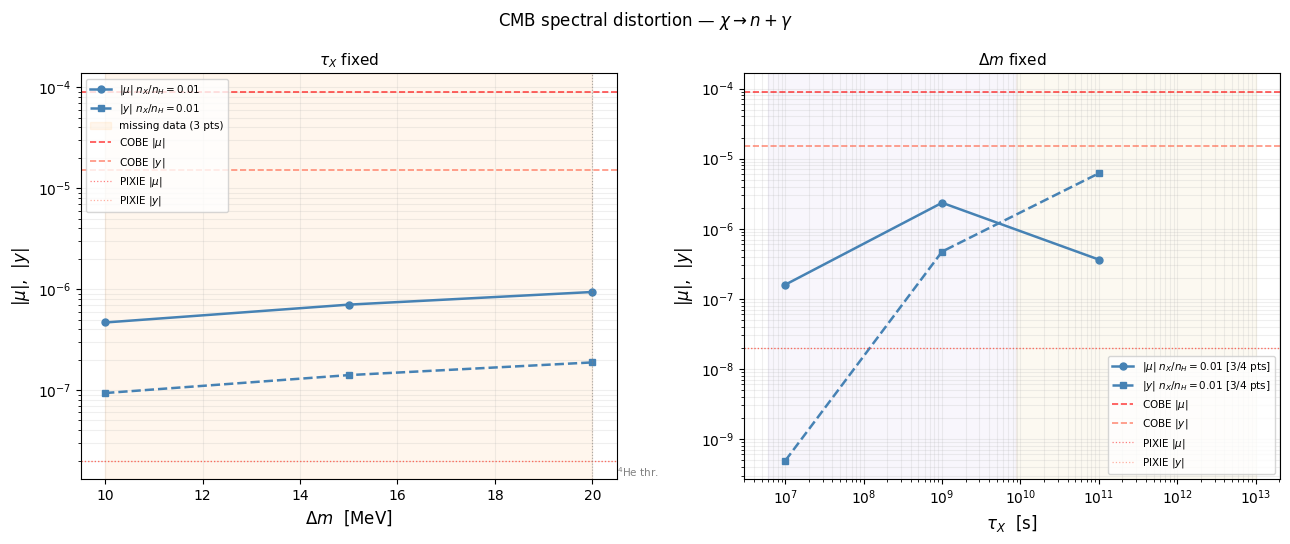

In [ ]:
"""
Plot whatever is currently saved in the cache files.
No solver calls — just loads and plots.

Point CACHE_FILES at your saved .npz files.
Each entry is a label shown in the legend.
"""

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ── point these at your saved .npz files ─────────────────────────────────────
CACHE_FILES = {
    "den=0.01 & 5.4 (dual)"  : "spectroxide/RUNS/sweep_dual_denfac.npz",
}

# pivot values (should match what was used when running)
DELTA_M_PIVOT = 50e6    # eV
TAU_X_PIVOT   = 1e9     # s

# observational benchmarks
COBE_MU  = 9.0e-5
COBE_Y   = 1.5e-5
PIXIE_MU = 2.0e-8
PIXIE_Y  = 2.0e-8
# ─────────────────────────────────────────────────────────────────────────────


def load_sweep(path):
    """
    Load a cache file and return dicts of arrays.
    Returns None if the file doesn't exist.
    Missing/NaN entries are kept as NaN so plots just skip them.
    """
    p = Path(path)
    if not p.exists():
        print(f"  [skip] not found: {path}")
        return None

    cache = np.load(p, allow_pickle=True)
    print(f"  loaded: {path}  (keys: {len(cache.files)})")

    # read axes
    dm_axis  = cache["delta_m_axis"] if "delta_m_axis" in cache else None
    tau_axis = cache["tau_x_axis"]   if "tau_x_axis"   in cache else None

    out = {"dm_axis": dm_axis, "tau_axis": tau_axis, "den_facs": []}

    # detect which den_facs are present
    # dual-denfac files use keys like df0.01_dm..._mu
    # single files use keys like dm..._mu
    dual = any(k.startswith("df") for k in cache.files)

    if dual:
        den_facs = list(cache["den_facs"]) if "den_facs" in cache else [0.01, 5.4]
        out["den_facs"] = den_facs
        for df in den_facs:
            tag = f"df{df:.4g}"
            if dm_axis is not None:
                mu_dm = np.array([
                    float(cache[f"{tag}_dm{dm:.6g}_mu"])
                    if f"{tag}_dm{dm:.6g}_mu" in cache else np.nan
                    for dm in dm_axis
                ])
                y_dm = np.array([
                    float(cache[f"{tag}_dm{dm:.6g}_y"])
                    if f"{tag}_dm{dm:.6g}_y" in cache else np.nan
                    for dm in dm_axis
                ])
                out[f"mu_dm_{df}"]  = mu_dm
                out[f"y_dm_{df}"]   = y_dm

            if tau_axis is not None:
                mu_tau = np.array([
                    float(cache[f"{tag}_tau{tx:.6g}_mu"])
                    if f"{tag}_tau{tx:.6g}_mu" in cache else np.nan
                    for tx in tau_axis
                ])
                y_tau = np.array([
                    float(cache[f"{tag}_tau{tx:.6g}_y"])
                    if f"{tag}_tau{tx:.6g}_y" in cache else np.nan
                    for tx in tau_axis
                ])
                out[f"mu_tau_{df}"] = mu_tau
                out[f"y_tau_{df}"]  = y_tau
    else:
        # single den_fac file
        df = float(cache["den_fac"]) if "den_fac" in cache else 0.01
        out["den_facs"] = [df]

        if dm_axis is not None:
            out[f"mu_dm_{df}"] = np.array([
                float(cache[f"dm_{dm:.6g}_mu"])
                if f"dm_{dm:.6g}_mu" in cache else np.nan
                for dm in dm_axis
            ])
            out[f"y_dm_{df}"] = np.array([
                float(cache[f"dm_{dm:.6g}_y"])
                if f"dm_{dm:.6g}_y" in cache else np.nan
                for dm in dm_axis
            ])

        if tau_axis is not None:
            out[f"mu_tau_{df}"] = np.array([
                float(cache[f"tau_{tx:.6g}_mu"])
                if f"tau_{tx:.6g}_mu" in cache else np.nan
                for tx in tau_axis
            ])
            out[f"y_tau_{df}"] = np.array([
                float(cache[f"tau_{tx:.6g}_y"])
                if f"tau_{tx:.6g}_y" in cache else np.nan
                for tx in tau_axis
            ])

    return out


# ── load all caches ───────────────────────────────────────────────────────────
print("Loading caches...")
datasets = {}
for label, path in CACHE_FILES.items():
    d = load_sweep(path)
    if d is not None:
        datasets[label] = d

if not datasets:
    print("No data found. Check your CACHE_FILES paths.")
    exit()

# ── plot ──────────────────────────────────────────────────────────────────────
COLORS  = ['steelblue', 'darkorange', 'seagreen', 'orchid', 'firebrick']
MU_MKR  = 'o'
Y_MKR   = 's'
LS_MU   = '-'
LS_Y    = '--'

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
ax_dm, ax_tau = axes

fig.suptitle(
    r'CMB spectral distortion — $\chi \to n + \gamma$',
    fontsize=12,
)

color_idx = 0
for file_label, data in datasets.items():
    dm_axis  = data.get("dm_axis")
    tau_axis = data.get("tau_axis")
    den_facs = data.get("den_facs", [])

    for df in den_facs:
        c    = COLORS[color_idx % len(COLORS)]
        lbl  = rf"$n_{{X}}/n_{{H}}={df}$"

        # ── Delta_m panel ────────────────────────────────────────────────────
        mu_dm = data.get(f"mu_dm_{df}")
        y_dm  = data.get(f"y_dm_{df}")
        if dm_axis is not None and mu_dm is not None:
            x = dm_axis / 1e6    # MeV
            mask = np.isfinite(mu_dm) & np.isfinite(y_dm)
            n_ok = mask.sum()
            lbl_full = lbl + (f" [{n_ok}/{len(x)} pts]" if n_ok < len(x) else "")
            if n_ok > 0:
                ax_dm.semilogy(x[mask], np.abs(mu_dm[mask]),
                               MU_MKR + LS_MU, color=c, lw=1.8, ms=5,
                               label=rf'$|\mu|$ {lbl_full}')
                ax_dm.semilogy(x[mask], np.abs(y_dm[mask]),
                               Y_MKR + LS_Y, color=c, lw=1.8, ms=5,
                               label=rf'$|y|$ {lbl_full}')
            if n_ok < len(x):
                missing_x = x[~mask]
                ax_dm.axvspan(missing_x.min(), missing_x.max(),
                              color=c, alpha=0.07,
                              label=f'missing data ({(~mask).sum()} pts)')

        # ── tau_X panel ───────────────────────────────────────────────────────
        mu_tau = data.get(f"mu_tau_{df}")
        y_tau  = data.get(f"y_tau_{df}")
        if tau_axis is not None and mu_tau is not None:
            mask = np.isfinite(mu_tau) & np.isfinite(y_tau)
            n_ok = mask.sum()
            lbl_full = lbl + (f" [{n_ok}/{len(tau_axis)} pts]" if n_ok < len(tau_axis) else "")
            if n_ok > 0:
                ax_tau.loglog(tau_axis[mask], np.abs(mu_tau[mask]),
                              MU_MKR + LS_MU, color=c, lw=1.8, ms=5,
                              label=rf'$|\mu|$ {lbl_full}')
                ax_tau.loglog(tau_axis[mask], np.abs(y_tau[mask]),
                              Y_MKR + LS_Y, color=c, lw=1.8, ms=5,
                              label=rf'$|y|$ {lbl_full}')

        color_idx += 1

# ── reference lines ───────────────────────────────────────────────────────────
for ax in (ax_dm, ax_tau):
    ax.axhline(COBE_MU,  color='red',   lw=1.2, ls='--', alpha=0.7,
               label=r'COBE $|\mu|$')
    ax.axhline(COBE_Y,   color='tomato',lw=1.2, ls='--', alpha=0.7,
               label=r'COBE $|y|$')
    ax.axhline(PIXIE_MU, color='red',   lw=0.9, ls=':',  alpha=0.5,
               label=r'PIXIE $|\mu|$')
    ax.axhline(PIXIE_Y,  color='tomato',lw=0.9, ls=':',  alpha=0.5,
               label=r'PIXIE $|y|$')
    ax.grid(True, which='both', alpha=0.2)
    ax.legend(fontsize=7.5, frameon=True, loc='best', ncol=1)

# ── Delta_m panel decorations ─────────────────────────────────────────────────
ax_dm.axvline(20, color='gray', lw=0.8, ls=':', alpha=0.6)
ax_dm.text(20.5, ax_dm.get_ylim()[0] if ax_dm.get_ylim()[0] > 0 else 1e-14,
           r'$^4$He thr.', fontsize=7.5, color='gray', va='bottom')
ax_dm.set_xlabel(r'$\Delta m$  [MeV]', fontsize=12)
ax_dm.set_ylabel(r'$|\mu|$,  $|y|$',   fontsize=12)
ax_dm.set_title(rf'$\tau_X$ fixed', fontsize=11)

# ── tau_X panel decorations ───────────────────────────────────────────────────
ax_tau.axvspan(6.1e6, 8.8e9,  color='mediumpurple', alpha=0.06)
ax_tau.axvspan(8.8e9, 1.0e13, color='goldenrod',    alpha=0.06)
ax_tau.set_xlabel(r'$\tau_X$  [s]',   fontsize=12)
ax_tau.set_ylabel(r'$|\mu|$,  $|y|$', fontsize=12)
ax_tau.set_title(rf'$\Delta m$ fixed', fontsize=11)

plt.tight_layout()
plt.show()

In [ ]:
"""
Suggestion 2 — 2D heatmap over (Delta_m, tau_X).

Runs the full grid and plots log10|mu| and log10|y| as colormaps,
with COBE exclusion and PIXIE sensitivity contours overlaid.
This gives the complete picture and maps directly onto the spirit
of McKeen 2021 Fig. 4 (CMB spectral distortion region).

Grid size: N_DM x N_TAU points total.
Tip: start with a coarse grid (e.g. 6x8) to check, then increase.
"""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from pathlib import Path
from spectroxide.solver import solve

# ── save location ─────────────────────────────────────────────────────────────
SAVE_DIR  = "spectroxide/RUNS"
SAVE_FILE = "heatmap_den001"
# ─────────────────────────────────────────────────────────────────────────────

save_path = Path(SAVE_DIR)
save_path.mkdir(parents=True, exist_ok=True)
npz_file  = save_path / f"{SAVE_FILE}.npz"

# ── parameters ────────────────────────────────────────────────────────────────
den_fac = 0.01
Z_START = 1e7
Z_END   = 0.0

# Grid axes — increase N_DM / N_TAU for higher resolution
DELTA_M_VALUES = np.array([10, 20, 30, 40, 50, 65, 80, 100, 120]) * 1e6   # eV
TAU_X_VALUES   = np.logspace(7, 13, 13)                                     # s

COBE_MU  = 9.0e-5
COBE_Y   = 1.5e-5
PIXIE_MU = 2.0e-8
PIXIE_Y  = 2.0e-8

N_DM  = len(DELTA_M_VALUES)
N_TAU = len(TAU_X_VALUES)

# ── cache ─────────────────────────────────────────────────────────────────────
# mu_grid[i, j] corresponds to (DELTA_M_VALUES[i], TAU_X_VALUES[j])
mu_grid = np.full((N_DM, N_TAU), np.nan)
y_grid  = np.full((N_DM, N_TAU), np.nan)

if npz_file.exists():
    print(f"Loading cache from '{npz_file}' ...")
    cache = np.load(npz_file, allow_pickle=True)
    for i, dm in enumerate(DELTA_M_VALUES):
        for j, tx in enumerate(TAU_X_VALUES):
            k = f"dm{dm:.6g}_tau{tx:.6g}_mu"
            if k in cache:
                mu_grid[i, j] = float(cache[k])
                y_grid[i, j]  = float(cache[f"dm{dm:.6g}_tau{tx:.6g}_y"])


def save_cache():
    flat = {
        "delta_m_axis" : DELTA_M_VALUES,
        "tau_x_axis"   : TAU_X_VALUES,
        "den_fac"      : np.array(den_fac),
    }
    for i, dm in enumerate(DELTA_M_VALUES):
        for j, tx in enumerate(TAU_X_VALUES):
            if not np.isnan(mu_grid[i, j]):
                flat[f"dm{dm:.6g}_tau{tx:.6g}_mu"] = np.array(mu_grid[i, j])
                flat[f"dm{dm:.6g}_tau{tx:.6g}_y"]  = np.array(y_grid[i, j])
    np.savez(npz_file, **flat)
    print(f"  → saved to '{npz_file}'")


# ── run grid ──────────────────────────────────────────────────────────────────
total   = N_DM * N_TAU
done    = int(np.sum(~np.isnan(mu_grid)))
print(f"\n── 2D grid sweep  ({N_DM} x {N_TAU} = {total} points, "
      f"{done} cached, {total-done} remaining) ──")

for i, dm in enumerate(DELTA_M_VALUES):
    for j, tx in enumerate(TAU_X_VALUES):
        if not np.isnan(mu_grid[i, j]):
            print(f"  ({i},{j}) Delta_m={dm/1e6:.0f} MeV, tau_X={tx:.2e} s ... cached")
            continue

        idx = i * N_TAU + j + 1
        print(f"  [{idx}/{total}] Delta_m={dm/1e6:.0f} MeV, tau_X={tx:.2e} s ...",
              end=" ", flush=True)
        try:
            r = solve(
                injection={
                    'type'    : 'decaying_particle',
                    'f_x'     : dm * den_fac,
                    'gamma_x' : 1.0 / tx,
                },
                z_start           = Z_START,
                z_end             = Z_END,
                x_min             = 1.5e-4,
                x_max             = 80.0,
                n_x               = 1000,
                method            = 'pde',
                production_grid   = True,
                number_conserving = True,
            )
            mu_grid[i, j] = float(r.mu)
            y_grid[i, j]  = float(r.y)
            print(f"mu={r.mu:.2e}, y={r.y:.2e}")
        except Exception as e:
            print(f"FAILED: {e}")
            mu_grid[i, j] = np.nan
            y_grid[i, j]  = np.nan

        save_cache()


# ── plot ──────────────────────────────────────────────────────────────────────
x_mev  = DELTA_M_VALUES / 1e6          # MeV, for x-axis ticks
log_tx = np.log10(TAU_X_VALUES)        # for y-axis ticks

log_mu = np.log10(np.abs(mu_grid))     # shape (N_DM, N_TAU)
log_y  = np.log10(np.abs(y_grid))

# meshgrid for pcolormesh — axes: Delta_m on x, tau_X on y
# pcolormesh expects (N_TAU, N_DM) so we transpose
DM_mesh  = x_mev
TAU_mesh = log_tx

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
fig.suptitle(
    rf'2D distortion map — $\chi \to n + \gamma$  '
    rf'($n_{{X,0}}/n_{{H,0}} = {den_fac}$, $z_{{\rm end}} = 0$)',
    fontsize=12,
)

panels = [
    (axes[0], log_mu.T, r'$\log_{{10}}|\mu|$', 'RdBu_r',
     np.log10(COBE_MU), np.log10(PIXIE_MU), 'COBE', 'PIXIE'),
    (axes[1], log_y.T,  r'$\log_{{10}}|y|$',   'PuOr_r',
     np.log10(COBE_Y),  np.log10(PIXIE_Y),  'COBE', 'PIXIE'),
]

for ax, data, cblabel, cmap, cobe_lv, pixie_lv, clabel_c, clabel_p in panels:
    # remove NaN rows/cols for colour range
    valid = data[np.isfinite(data)]
    vmin  = valid.min() if valid.size else -12
    vmax  = valid.max() if valid.size else  -3

    pcm = ax.pcolormesh(
        DM_mesh, TAU_mesh, data,
        cmap=cmap, vmin=vmin, vmax=vmax, shading='auto',
    )
    cb = fig.colorbar(pcm, ax=ax, pad=0.02)
    cb.set_label(cblabel, fontsize=11)

    # COBE exclusion contour
    cs_cobe = ax.contour(DM_mesh, TAU_mesh, data,
                         levels=[cobe_lv], colors='red', linewidths=1.5)
    ax.clabel(cs_cobe, fmt={cobe_lv: clabel_c}, fontsize=8, inline=True)

    # PIXIE sensitivity contour
    cs_pix = ax.contour(DM_mesh, TAU_mesh, data,
                        levels=[pixie_lv], colors='white',
                        linewidths=1.2, linestyles='--')
    ax.clabel(cs_pix, fmt={pixie_lv: clabel_p}, fontsize=8, inline=True)

    # 4He photodissociation threshold
    ax.axvline(20, color='yellow', lw=1.0, ls=':', alpha=0.8)
    ax.text(20.5, log_tx[1], r'${}^4$He', fontsize=7.5, color='yellow', va='bottom')

    # era boundaries (horizontal lines in log_tau space)
    ax.axhline(np.log10(6.1e6), color='cyan', lw=0.9, ls=':', alpha=0.7)
    ax.axhline(np.log10(8.8e9), color='cyan', lw=0.9, ls=':', alpha=0.7)
    ax.text(11, np.log10(6.1e6) + 0.1, r'$\mu$-era start', fontsize=7, color='cyan')
    ax.text(11, np.log10(8.8e9) + 0.1, r'$y$-era start',   fontsize=7, color='cyan')

    ax.set_xlabel(r'$\Delta m$  [MeV]', fontsize=12)
    ax.set_ylabel(r'$\log_{10}(\tau_X / \mathrm{s})$', fontsize=12)
    ax.grid(False)

plt.tight_layout()
fig_file = save_path / f"{SAVE_FILE}.pdf"
plt.savefig(fig_file, dpi=150, bbox_inches='tight')
print(f"\nFigure saved to '{fig_file}'")
plt.show()

In [ ]:
"""
Suggestion 3 — |mu|/|y| ratio as a diagnostic.

The ratio mu/y encodes WHERE in the thermalization history the energy was
deposited, independently of the overall injection amplitude:
  - mu/y >> 1  → injection deep in the mu-era (z >> z_Compton)
  - mu/y ~ 1   → injection near the mu/y transition
  - mu/y << 1  → injection in the y-era or after Compton freeze-out

Plotted alongside |mu| and |y| on the same axes (right-hand y-axis for ratio)
for both the Delta_m and tau_X sweeps.

Reuses cached data from param_sweep.py (SAVE_FILE = sweep_mckeen2021_den001)
if available; otherwise runs fresh and saves to its own cache.
"""

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from spectroxide.solver import solve

# ── save location ─────────────────────────────────────────────────────────────
SAVE_DIR        = "spectroxide/RUNS"
SAVE_FILE       = "sweep_ratio_den001"

# Optional: point at an existing param_sweep cache to reuse runs.
# Set to None to always run fresh.
EXISTING_CACHE  = "distortion_runs/param_sweep/sweep_mckeen2021_den001.npz"
# ─────────────────────────────────────────────────────────────────────────────

save_path = Path(SAVE_DIR)
save_path.mkdir(parents=True, exist_ok=True)
npz_file  = save_path / f"{SAVE_FILE}.npz"

# ── parameters ────────────────────────────────────────────────────────────────
den_fac = 0.01
Z_START = 1e7
Z_END   = 0.0

DELTA_M_VALUES = np.array([10, 15, 20, 30, 40, 50, 65, 80, 100, 120]) * 1e6  # eV
TAU_X_VALUES   = np.logspace(7, 13, 13)                                        # s

DELTA_M_PIVOT  = 50e6    # eV
TAU_X_PIVOT    = 1e9     # s

COBE_MU  = 9.0e-5
COBE_Y   = 1.5e-5
PIXIE_MU = 2.0e-8
PIXIE_Y  = 2.0e-8


# ── load from existing param_sweep cache if available ─────────────────────────
mu_dm  = np.full(len(DELTA_M_VALUES), np.nan)
y_dm   = np.full(len(DELTA_M_VALUES), np.nan)
mu_tau = np.full(len(TAU_X_VALUES),   np.nan)
y_tau  = np.full(len(TAU_X_VALUES),   np.nan)

def _try_load(path):
    p = Path(path)
    if not p.exists():
        return None
    print(f"Loading cache from '{p}' ...")
    return np.load(p, allow_pickle=True)

# Try own cache first, then fall back to existing param_sweep cache
for cache_path in [str(npz_file), EXISTING_CACHE]:
    if cache_path is None:
        continue
    cache = _try_load(cache_path)
    if cache is None:
        continue
    for i, dm in enumerate(DELTA_M_VALUES):
        k = f"dm_{dm:.6g}_mu"
        if k in cache and np.isnan(mu_dm[i]):
            mu_dm[i] = float(cache[k])
            y_dm[i]  = float(cache[f"dm_{dm:.6g}_y"])
    for i, tx in enumerate(TAU_X_VALUES):
        k = f"tau_{tx:.6g}_mu"
        if k in cache and np.isnan(mu_tau[i]):
            mu_tau[i] = float(cache[k])
            y_tau[i]  = float(cache[f"tau_{tx:.6g}_y"])


def save_cache():
    flat = {
        "den_fac"       : np.array(den_fac),
        "delta_m_axis"  : DELTA_M_VALUES,
        "tau_x_axis"    : TAU_X_VALUES,
        "delta_m_pivot" : np.array(DELTA_M_PIVOT),
        "tau_x_pivot"   : np.array(TAU_X_PIVOT),
    }
    for i, dm in enumerate(DELTA_M_VALUES):
        if not np.isnan(mu_dm[i]):
            flat[f"dm_{dm:.6g}_mu"] = np.array(mu_dm[i])
            flat[f"dm_{dm:.6g}_y"]  = np.array(y_dm[i])
    for i, tx in enumerate(TAU_X_VALUES):
        if not np.isnan(mu_tau[i]):
            flat[f"tau_{tx:.6g}_mu"] = np.array(mu_tau[i])
            flat[f"tau_{tx:.6g}_y"]  = np.array(y_tau[i])
    np.savez(npz_file, **flat)
    print(f"  → saved to '{npz_file}'")


# ── run any missing points ────────────────────────────────────────────────────
def run_point(delta_m_ev, tau_x_s):
    r = solve(
        injection={
            'type'    : 'decaying_particle',
            'f_x'     : delta_m_ev * den_fac,
            'gamma_x' : 1.0 / tau_x_s,
        },
        z_start           = Z_START,
        z_end             = Z_END,
        x_min             = 1.5e-4,
        x_max             = 80.0,
        n_x               = 1000,
        method            = 'pde',
        production_grid   = True,
        number_conserving = True,
    )
    return float(r.mu), float(r.y)


print(f"\n── Delta_m sweep  (tau_X = {TAU_X_PIVOT:.1e} s) ──")
for i, dm in enumerate(DELTA_M_VALUES):
    if not np.isnan(mu_dm[i]):
        print(f"  Delta_m = {dm/1e6:.0f} MeV ... cached"); continue
    print(f"  Delta_m = {dm/1e6:.0f} MeV ...", end=" ", flush=True)
    mu_dm[i], y_dm[i] = run_point(dm, TAU_X_PIVOT)
    print(f"mu = {mu_dm[i]:.3e},  y = {y_dm[i]:.3e}")
    save_cache()

print(f"\n── tau_X sweep  (Delta_m = {DELTA_M_PIVOT/1e6:.0f} MeV) ──")
for i, tx in enumerate(TAU_X_VALUES):
    if not np.isnan(mu_tau[i]):
        print(f"  tau_X = {tx:.2e} s ... cached"); continue
    print(f"  tau_X = {tx:.2e} s ...", end=" ", flush=True)
    mu_tau[i], y_tau[i] = run_point(DELTA_M_PIVOT, tx)
    print(f"mu = {mu_tau[i]:.3e},  y = {y_tau[i]:.3e}")
    save_cache()


# ── ratio (safe: avoid 0/0) ───────────────────────────────────────────────────
_safe = lambda a, b: np.where(
    (np.abs(b) > 1e-30) & np.isfinite(a) & np.isfinite(b),
    np.abs(a) / np.abs(b),
    np.nan,
)
ratio_dm  = _safe(mu_dm,  y_dm)
ratio_tau = _safe(mu_tau, y_tau)


# ── plot ──────────────────────────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))
fig.suptitle(
    rf'$|\mu|$, $|y|$ and $|\mu|/|y|$ ratio — $\chi \to n+\gamma$'
    rf'  ($n_{{X,0}}/n_{{H,0}} = {den_fac}$)',
    fontsize=11,
)

def _decorate_left(ax, ax_r, x, mu, y, ratio, xlabel, title,
                   x_log=False, pivot_line=None):
    """Draw mu/y on left axis, ratio on right axis."""
    plot_fn = ax.loglog if x_log else ax.semilogy

    l1, = plot_fn(x, np.abs(mu), 'o-', color='steelblue',  lw=1.8, ms=5,
                  label=r'$|\mu|$')
    l2, = plot_fn(x, np.abs(y),  's-', color='darkorange', lw=1.8, ms=5,
                  label=r'$|y|$')

    # bounds
    ax.axhline(COBE_MU,  color='steelblue',  lw=1.0, ls='--', alpha=0.6)
    ax.axhline(COBE_Y,   color='darkorange',  lw=1.0, ls='--', alpha=0.6)
    ax.axhline(PIXIE_MU, color='steelblue',  lw=0.8, ls=':',  alpha=0.5)
    ax.axhline(PIXIE_Y,  color='darkorange',  lw=0.8, ls=':',  alpha=0.5)

    # ratio on twin axis
    plot_r = ax_r.loglog if x_log else ax_r.semilogy
    l3, = plot_r(x, ratio, 'D--', color='seagreen', lw=1.5, ms=4,
                 label=r'$|\mu|/|y|$')
    ax_r.axhline(1.0, color='seagreen', lw=0.9, ls=':', alpha=0.6)
    ax_r.set_ylabel(r'$|\mu| / |y|$', fontsize=11, color='seagreen')
    ax_r.tick_params(axis='y', labelcolor='seagreen')

    if pivot_line is not None:
        ax.axvline(pivot_line, color='gray', lw=0.8, ls=':', alpha=0.6)

    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel(r'$|\mu|$,  $|y|$', fontsize=12)
    ax.set_title(title, fontsize=11)
    ax.grid(True, which='both', alpha=0.18)

    lines  = [l1, l2, l3]
    labels = [l.get_label() for l in lines]
    ax.legend(lines, labels, fontsize=8.5, frameon=True, loc='upper left')


# left panel: Delta_m sweep
ax1r = ax1.twinx()
_decorate_left(
    ax1, ax1r,
    x         = DELTA_M_VALUES / 1e6,
    mu        = mu_dm,
    y         = y_dm,
    ratio     = ratio_dm,
    xlabel    = r'$\Delta m$  [MeV]',
    title     = rf'$\tau_X = {TAU_X_PIVOT:.0e}$ s',
    x_log     = False,
    pivot_line= 20,
)
# annotate 4He threshold
ax1.text(20.5, ax1.get_ylim()[0] * 3 if ax1.get_ylim()[0] > 0 else 1e-14,
         r'$^4$He thr.', fontsize=7.5, color='gray')

# right panel: tau_X sweep
ax2r = ax2.twinx()
_decorate_left(
    ax2, ax2r,
    x         = TAU_X_VALUES,
    mu        = mu_tau,
    y         = y_tau,
    ratio     = ratio_tau,
    xlabel    = r'$\tau_X$  [s]',
    title     = rf'$\Delta m = {DELTA_M_PIVOT/1e6:.0f}$ MeV',
    x_log     = True,
)
# era shading (on background only)
ax2.axvspan(6.1e6, 8.8e9,  color='mediumpurple', alpha=0.06)
ax2.axvspan(8.8e9, 1.0e13, color='goldenrod',    alpha=0.06)

# ratio = 1 annotation
ax2r.text(TAU_X_VALUES[-2], 1.2, r'$|\mu|/|y|=1$', fontsize=7.5,
          color='seagreen', va='bottom')

plt.tight_layout()
fig_file = save_path / f"{SAVE_FILE}.pdf"
plt.savefig(fig_file, dpi=150, bbox_inches='tight')
print(f"\nFigure saved to '{fig_file}'")
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from spectroxide.solver import solve

# ── save location (change these manually) ─────────────────────────────────────
SAVE_DIR  = "spectroxide/RUNS"          # folder name
SAVE_FILE = "snapshots_tau1e9_dm50MeV" # file name (no extension needed)
# ─────────────────────────────────────────────────────────────────────────────

save_path = Path(SAVE_DIR)
save_path.mkdir(parents=True, exist_ok=True)

# ── physical parameters ───────────────────────────────────────────────────────
tau_X     = 878.4                   # [s], lifetime of the decaying dark baryon
GAMMA_X   = 1.0 / tau_X          # 1/t_X

# f_x = e_x * m_x * n_x,0/n_H,0
# assuming the neutron is non-relativistic, all the energy goes into photons, e_x * m_x = m_x - m_n = Delta_m 
# from McKeen 2021, two benchmarks are, n_x,0/n_H,0 = 5.4 and 0.01

E_heat = 0.3e6      # [eV], energy released per decay (m_x - m_n)
den_fac = 0.01      # n_x,0/n_H,0 (benchmark from McKeen 2021)
F_X = E_heat * den_fac

# ── snapshot redshifts from Fig. 14, middle panel (z_X = 10^5) ───────────────
Z_VEARLY = [8e6, 2e6]
Z_EARLY  = [8.8e5, 3.1e5, 9.7e4]
Z_LATE   = [6.0e4, 1.4e4, 8.7e3, 4.1e3, 1.1e3, 200]
Z_ALL    = sorted(Z_VEARLY + Z_EARLY + Z_LATE)   # ascending for solver


# ── alternatively: use the exact eq. 35 directly where n_x > 0 ───────────────
def brightness_temp_exact(x, delta_n):
    """
    Applies eq. 35 directly:  T(x)/T_z = x / ln(1 + 1/n_x)
    Falls back to analytic shapes only where n_x ≤ 0 or x > x_thresh.
    """
    xc  = np.clip(np.asarray(x, dtype=float), 1e-12, None)
    n0  = 1.0 / np.expm1(np.clip(xc, None, 500.0))   # Planck distribution
    n_x = n0 + delta_n

    # exact formula
    dTb = xc / np.log1p(1.0 / n_x) - 1.0

    return dTb


# ── load existing data (resume support) ──────────────────────────────────────
npz_file = save_path / f"{SAVE_FILE}.npz"
snapshots = {}

if npz_file.exists():
    print(f"Found existing data at '{npz_file}', loading...")
    existing = np.load(npz_file, allow_pickle=True)
    # stored as flat arrays with z_end encoded in the key names
    loaded_keys = set(existing.files)
    for z in Z_ALL:
        key_x  = f"z{z:.6g}_x"
        key_dn = f"z{z:.6g}_delta_n"
        key_mu = f"z{z:.6g}_mu"
        key_y  = f"z{z:.6g}_y"
        if all(k in loaded_keys for k in [key_x, key_dn, key_mu, key_y]):
            snapshots[z] = (
                existing[key_x],
                existing[key_dn],
                float(existing[key_mu]),
                float(existing[key_y]),
            )
            print(f"  Loaded cached z_end = {z:.3g}")


def save_snapshots():
    """Flatten snapshots dict and save to .npz."""
    flat = {}
    flat["tau_X"]   = np.array(tau_X)
    flat["gamma_x"] = np.array(GAMMA_X)
    flat["Delta_m"] = np.array(Delta_m)
    flat["den_fac"] = np.array(den_fac)
    flat["F_X"]     = np.array(F_X)
    flat["z_all"]   = np.array(Z_ALL)
    for z, (x_arr, dn, mu_r, y_r) in snapshots.items():
        flat[f"z{z:.6g}_x"]       = x_arr
        flat[f"z{z:.6g}_delta_n"] = dn
        flat[f"z{z:.6g}_mu"]      = np.array(mu_r)
        flat[f"z{z:.6g}_y"]       = np.array(y_r)
    np.savez(npz_file, **flat)
    print(f"  → saved to '{npz_file}'")


# ── run solver for each snapshot redshift ─────────────────────────────────────
for z_end in Z_ALL:
    if z_end in snapshots:
        print(f"  z_end = {z_end:.3g} ... skipped (cached)")
        continue

    print(f"  z_end = {z_end:.3g} ...", end=" ", flush=True)
    r = solve(
        injection = {
            'type'    : 'decaying_particle',
            'f_x'     : F_X,
            'gamma_x' : GAMMA_X,
        },
        z_start           = 1e7,
        z_end             = z_end,
        x_min             = 1.5e-4,
        x_max             = 80.0,
        n_x               = 1000,
        method            = 'pde',
        production_grid   = True,
        number_conserving = True,
    )
    snapshots[z_end] = (r.x, r.delta_n, r.mu, r.y)
    print("done")

    # save after every completed run
    save_snapshots()


# ── colour maps matching Fig. 14 style ────────────────────────────────────────
cmap_v = plt.cm.Greens_r
cmap_e = plt.cm.Blues_r
cmap_l = plt.cm.Oranges
_LS    = ['-', '--', '-.', (0,(5,1)), (0,(3,1,1,1)), (0,(1,1))]

def zlab(z):
    for base, exp in [(1e6,6),(1e5,5),(1e4,4),(1e3,3)]:
        if z >= base * 0.9:
            return rf'$z={z/base:.1f}\times10^{exp}$'
    return rf'$z={int(z)}$'

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 7))

for i, z in enumerate(sorted(Z_VEARLY, reverse=True)):
    x_arr, dn, mu_r, y_r = snapshots[z]
    dT = brightness_temp_exact(x_arr, dn)
    c  = cmap_v(0.25 + 0.55 * i / max(len(Z_VEARLY) - 1, 1))
    ax.semilogx(x_arr, dT, color=c, ls=_LS[i % len(_LS)],
                lw=1.2, label=zlab(z))

for i, z in enumerate(sorted(Z_EARLY, reverse=True)):
    x_arr, dn, mu_r, y_r = snapshots[z]
    dT = brightness_temp_exact(x_arr, dn)
    c  = cmap_e(0.25 + 0.55 * i / max(len(Z_EARLY) - 1, 1))
    ax.semilogx(x_arr, dT, color=c, ls=_LS[i % len(_LS)],
                lw=1.2, label=zlab(z))

for i, z in enumerate(sorted(Z_LATE, reverse=True)):
    x_arr, dn, mu_r, y_r = snapshots[z]
    dT = brightness_temp_exact(x_arr, dn)
    c  = cmap_l(0.25 + 0.55 * i / max(len(Z_LATE) - 1, 1))
    ax.semilogx(x_arr, dT, color=c, ls=_LS[i % len(_LS)],
                lw=1.2, label=zlab(z))

ax.axhline(0, color='k', lw=0.5, ls=':')
ax.set_xlim(2e-4, 50)
ax.set_ylim(-30e-6, 2e-6)
ax.set_xlabel(r'$x = h\nu / kT_z$', fontsize=13)
ax.set_ylabel(r'$T(x)\,/\,T_{\rm CMB} - 1$', fontsize=13)
ax.legend(fontsize=7, frameon=False, loc='lower right', ncol=2)

# ── parameter annotation, top right ──────────────────────────────────────────
param_text = '\n'.join([
    rf'$\tau_X = 10^9$ s',
    rf'$\Delta m = 50$ MeV',
    rf'$n_{{X,0}}/n_{{H,0}} = {den_fac}$',
])
ax.text(0.97, 0.97, param_text, transform=ax.transAxes,
        ha='right', va='top', fontsize=11,
        bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.7, edgecolor='0.8'))

ax.set_title(r'CMB spectral distortion — $\chi \rightarrow n + \gamma$ injection',
             fontsize=11)
plt.tight_layout()

# ── save figure alongside the data ───────────────────────────────────────────
fig_file = save_path / f"{SAVE_FILE}.pdf"
plt.savefig(fig_file, dpi=150, bbox_inches='tight')
print(f"Figure saved to '{fig_file}'")

plt.show()

  z_end = 0 ... 

/home/batman/Documents/Work/CMBSD/spectroxide/python/spectroxide/solver.py:724: RuntimeWarning: spectroxide: z_start=1.0e7 implies theta_e ~ 4.6e-3. Kompaneets Fokker-Planck has O(theta_e^2) corrections that grow above z ~ 5e6. Results may have ~1% systematic errors.
  return _run_rust_binary(cmd, cwd=root, timeout=timeout)
/home/batman/Documents/Work/CMBSD/spectroxide/python/spectroxide/solver.py:724: RuntimeWarning: spectroxide: Progress: z=7.6e6 step=100000 ρ_e=1.000000 ρ_eq=1.000000
  return _run_rust_binary(cmd, cwd=root, timeout=timeout)
/home/batman/Documents/Work/CMBSD/spectroxide/python/spectroxide/solver.py:724: RuntimeWarning: spectroxide: Progress: z=4.1e6 step=200000 ρ_e=1.000000 ρ_eq=1.000000
  return _run_rust_binary(cmd, cwd=root, timeout=timeout)
/home/batman/Documents/Work/CMBSD/spectroxide/python/spectroxide/solver.py:724: RuntimeWarning: spectroxide: Progress: z=4.4e-323 step=300000 ρ_e=0.178323 ρ_eq=1.000000
  return _run_rust_binary(cmd, cwd=root, timeout=timeout)

done
  → saved to 'spectroxide/RUNS/snapshots_tau1e9_dm50MeV_dark-photon.npz'


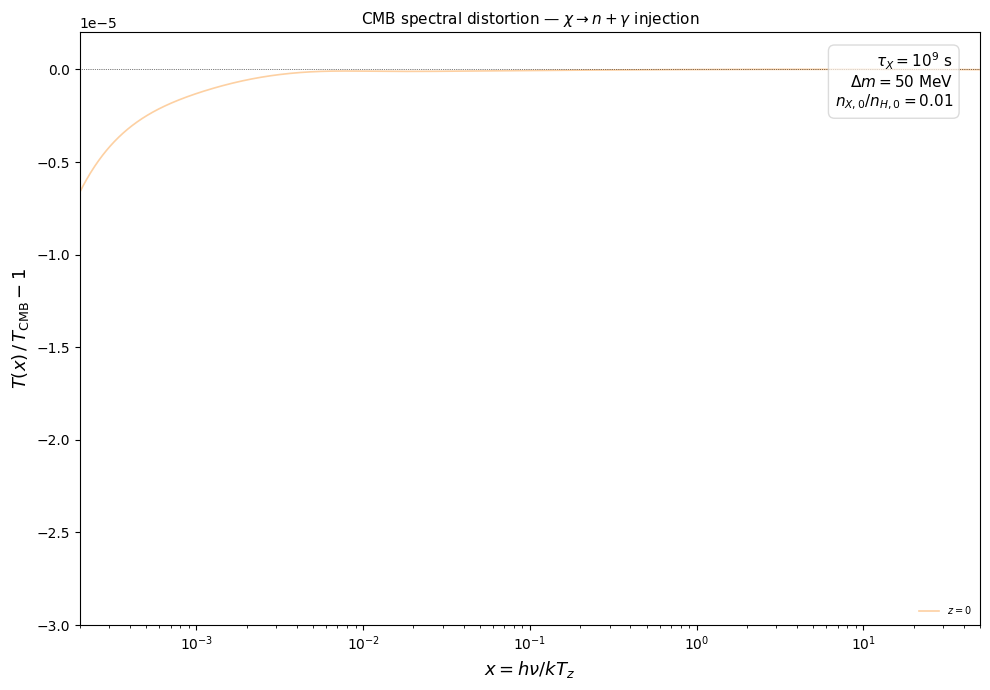

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from spectroxide.solver import solve

# ── save location (change these manually) ─────────────────────────────────────
SAVE_DIR  = "spectroxide/RUNS"          # folder name
SAVE_FILE = "snapshots_tau1e9_dm50MeV_dark-photon" # file name (no extension needed)
# ─────────────────────────────────────────────────────────────────────────────

save_path = Path(SAVE_DIR)
save_path.mkdir(parents=True, exist_ok=True)

# ── physical parameters ───────────────────────────────────────────────────────
tau_X     = 1e9                   # [s], lifetime of the decaying dark baryon
GAMMA_X   = 1.0 / tau_X          # 1/t_X

# f_x = e_x * m_x * n_x,0/n_H,0
# frac_m = e_X*m_X would just become the energy released in the form of heat 
# from McKeen 2021, two benchmarks are, n_x,0/n_H,0 = 5.4 and 0.01

frac_m = 0.301791e6      # [eV], energy released per decay into heat
den_fac = 0.01      # n_x,0/n_H,0 (benchmark from McKeen 2021)
F_X = frac_m * den_fac

# ── snapshot redshifts from Fig. 14, middle panel (z_X = 10^5) ───────────────
Z_LATE   = [0]
Z_ALL    = sorted(Z_LATE)   # ascending for solver


# ── alternatively: use the exact eq. 35 directly where n_x > 0 ───────────────
def brightness_temp_exact(x, delta_n):
    """
    Applies eq. 35 directly:  T(x)/T_z = x / ln(1 + 1/n_x)
    Falls back to analytic shapes only where n_x ≤ 0 or x > x_thresh.
    """
    xc  = np.clip(np.asarray(x, dtype=float), 1e-12, None)
    n0  = 1.0 / np.expm1(np.clip(xc, None, 500.0))   # Planck distribution
    n_x = n0 + delta_n

    # exact formula
    dTb = xc / np.log1p(1.0 / n_x) - 1.0

    return dTb


# ── load existing data (resume support) ──────────────────────────────────────
npz_file = save_path / f"{SAVE_FILE}.npz"
snapshots = {}

if npz_file.exists():
    print(f"Found existing data at '{npz_file}', loading...")
    existing = np.load(npz_file, allow_pickle=True)
    # stored as flat arrays with z_end encoded in the key names
    loaded_keys = set(existing.files)
    for z in Z_ALL:
        key_x  = f"z{z:.6g}_x"
        key_dn = f"z{z:.6g}_delta_n"
        key_mu = f"z{z:.6g}_mu"
        key_y  = f"z{z:.6g}_y"
        if all(k in loaded_keys for k in [key_x, key_dn, key_mu, key_y]):
            snapshots[z] = (
                existing[key_x],
                existing[key_dn],
                float(existing[key_mu]),
                float(existing[key_y]),
            )
            print(f"  Loaded cached z_end = {z:.3g}")


def save_snapshots():
    """Flatten snapshots dict and save to .npz."""
    flat = {}
    flat["tau_X"]   = np.array(tau_X)
    flat["gamma_x"] = np.array(GAMMA_X)
    flat["frac_m"] = np.array(frac_m)
    flat["den_fac"] = np.array(den_fac)
    flat["F_X"]     = np.array(F_X)
    flat["z_all"]   = np.array(Z_ALL)
    for z, (x_arr, dn, mu_r, y_r) in snapshots.items():
        flat[f"z{z:.6g}_x"]       = x_arr
        flat[f"z{z:.6g}_delta_n"] = dn
        flat[f"z{z:.6g}_mu"]      = np.array(mu_r)
        flat[f"z{z:.6g}_y"]       = np.array(y_r)
    np.savez(npz_file, **flat)
    print(f"  → saved to '{npz_file}'")


# ── run solver for each snapshot redshift ─────────────────────────────────────
for z_end in Z_ALL:
    if z_end in snapshots:
        print(f"  z_end = {z_end:.3g} ... skipped (cached)")
        continue

    print(f"  z_end = {z_end:.3g} ...", end=" ", flush=True)
    r = solve(
        injection = {
            'type'    : 'decaying_particle',
            'f_x'     : F_X,
            'gamma_x' : GAMMA_X,
        },
        z_start           = 1e7,
        z_end             = z_end,
        x_min             = 1.5e-4,
        x_max             = 80.0,
        n_x               = 1000,
        method            = 'pde',
        production_grid   = True,
        number_conserving = True,
        timeout           = 3600,
    )
    snapshots[z_end] = (r.x, r.delta_n, r.mu, r.y)
    print("done")

    # save after every completed run
    save_snapshots()


# ── colour maps matching Fig. 14 style ────────────────────────────────────────
cmap_v = plt.cm.Greens_r
cmap_e = plt.cm.Blues_r
cmap_l = plt.cm.Oranges
_LS    = ['-', '--', '-.', (0,(5,1)), (0,(3,1,1,1)), (0,(1,1))]

def zlab(z):
    for base, exp in [(1e6,6),(1e5,5),(1e4,4),(1e3,3)]:
        if z >= base * 0.9:
            return rf'$z={z/base:.1f}\times10^{exp}$'
    return rf'$z={int(z)}$'

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 7))

for i, z in enumerate(sorted(Z_LATE, reverse=True)):
    x_arr, dn, mu_r, y_r = snapshots[z]
    dT = brightness_temp_exact(x_arr, dn)
    c  = cmap_l(0.25 + 0.55 * i / max(len(Z_LATE) - 1, 1))
    ax.semilogx(x_arr, dT, color=c, ls=_LS[i % len(_LS)],
                lw=1.2, label=zlab(z))

ax.axhline(0, color='k', lw=0.5, ls=':')
ax.set_xlim(2e-4, 50)
ax.set_ylim(-30e-6, 2e-6)
ax.set_xlabel(r'$x = h\nu / kT_z$', fontsize=13)
ax.set_ylabel(r'$T(x)\,/\,T_{\rm CMB} - 1$', fontsize=13)
ax.legend(fontsize=7, frameon=False, loc='lower right', ncol=2)

# ── parameter annotation, top right ──────────────────────────────────────────
param_text = '\n'.join([
    rf'$\tau_X = 10^9$ s',
    rf'$\Delta m = 50$ MeV',
    rf'$n_{{X,0}}/n_{{H,0}} = {den_fac}$',
])
ax.text(0.97, 0.97, param_text, transform=ax.transAxes,
        ha='right', va='top', fontsize=11,
        bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.7, edgecolor='0.8'))

ax.set_title(r'CMB spectral distortion — $\chi \rightarrow n + \gamma$ injection',
             fontsize=11)
plt.tight_layout()


plt.show()

### $\chi \rightarrow n + \gamma'$ : `spectroxide` ($m_{\gamma'}=0$ MeV)

Found existing data at 'spectroxide/RUNS/sweep_deltam_darkphoton_tau1e9.npz', loading...
  loaded Δm = 5 MeV
  loaded Δm = 10 MeV
  loaded Δm = 20 MeV
  loaded Δm = 30 MeV
  loaded Δm = 40 MeV
  loaded Δm = 50 MeV
All Δm points already cached.


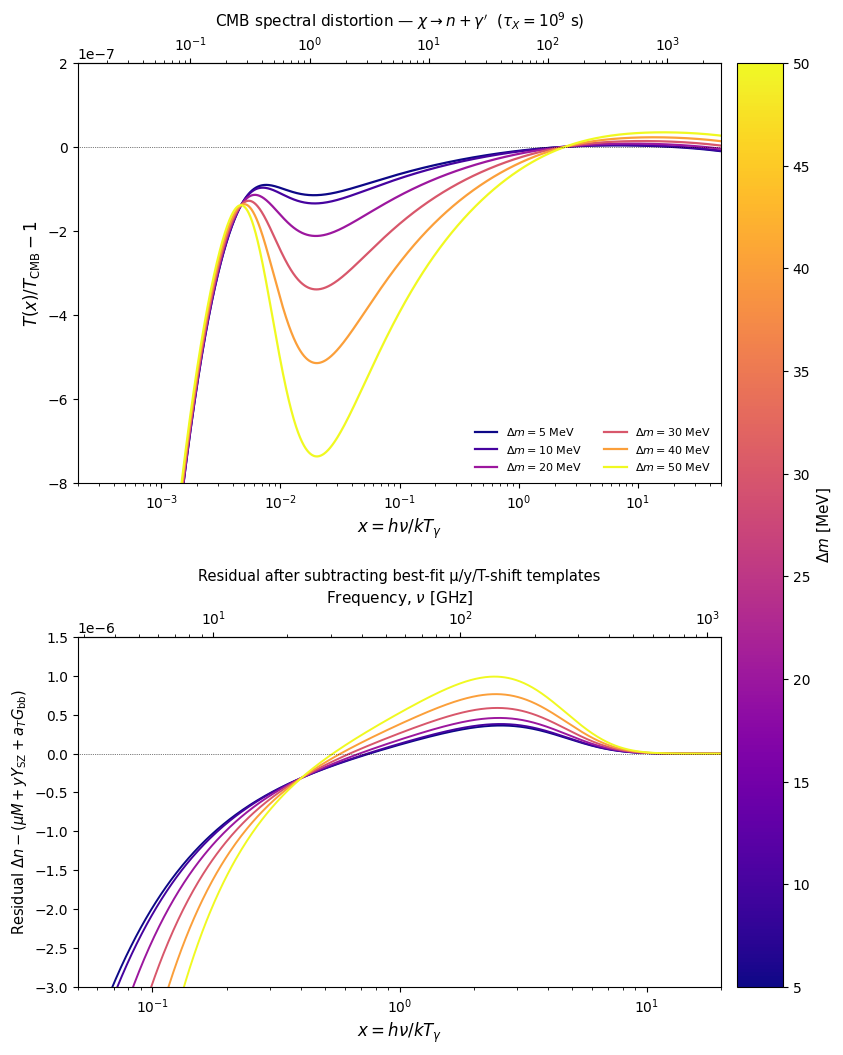

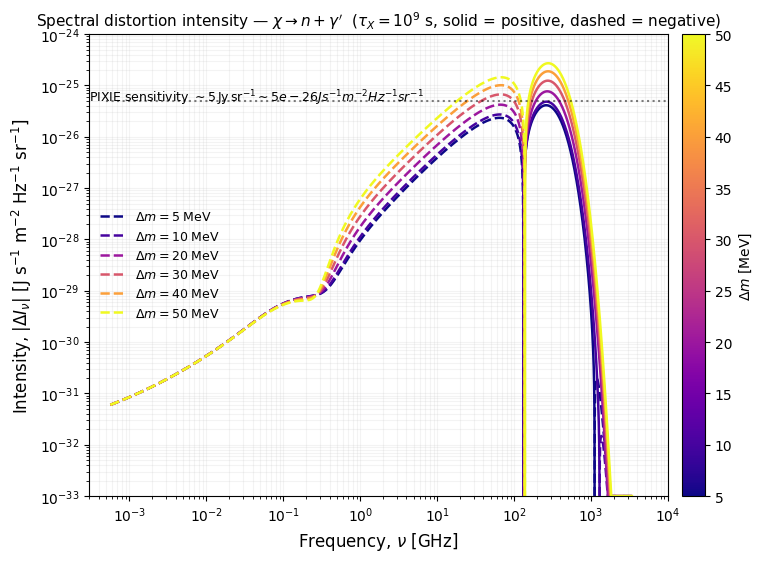

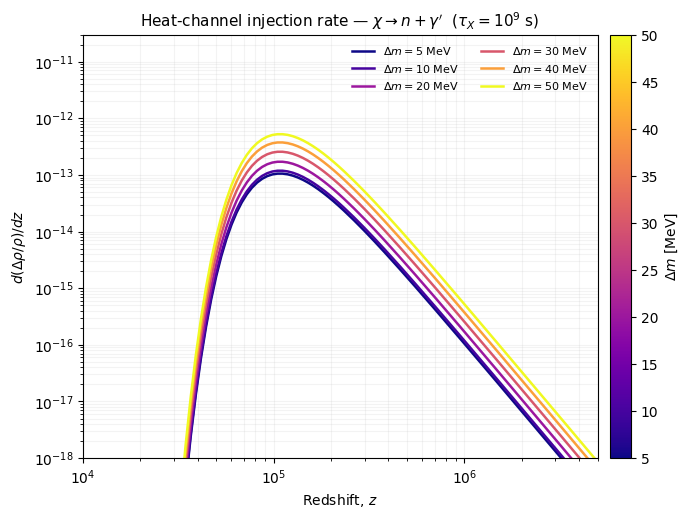

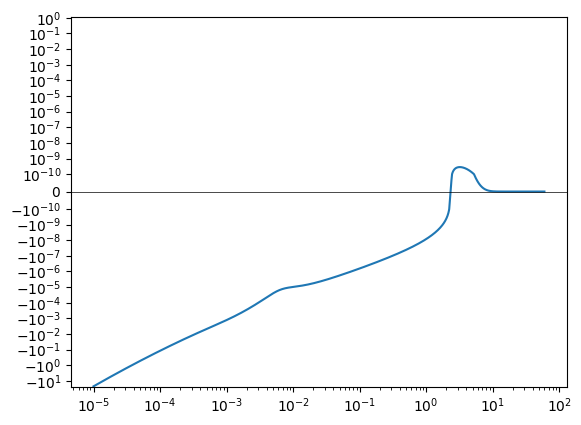

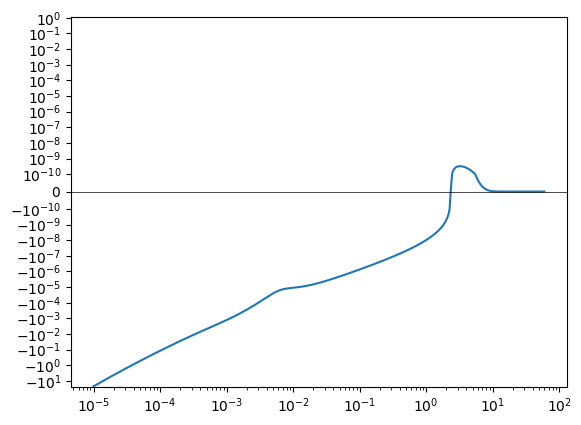

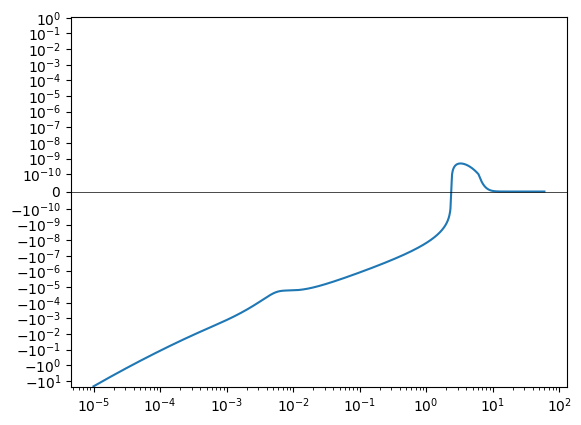

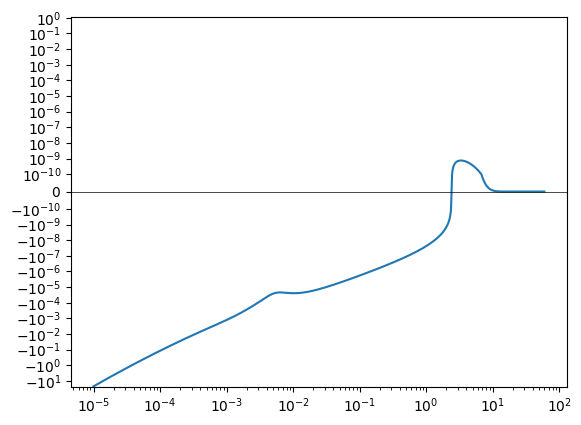

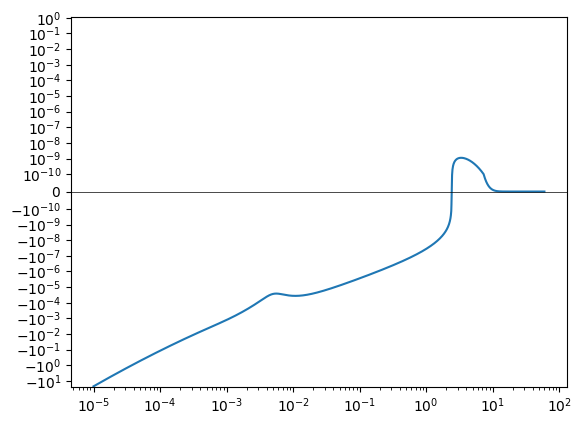

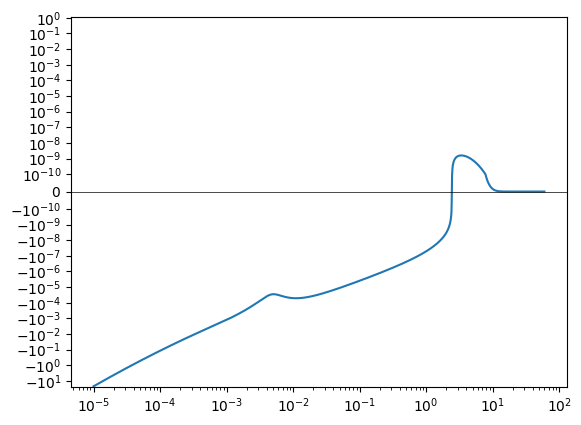


Massless dark photon case (χ → n + γ')   τ_X = 1e+09 s   n_X,0/n_H,0 = 0.01

+-----------+-------------+-------------+-------------+-------------+-------------+-------------+---------------+---------------+---------------+-------------+
| Δm [MeV]  | m_γ' [MeV]  |  F_X [eV]   |  T_n [keV]  | T_γ' [keV]  |      μ      |      y      |  a_μ (resid)  |  a_y (resid)  |  a_T (resid)  |  resid RMS  |
+-----------+-------------+-------------+-------------+-------------+-------------+-------------+---------------+---------------+---------------+-------------+
|         5 |        0.00 |   3.150e+03 |     13.2336 |   4986.7664 |   1.251e-08 |   2.053e-09 |     1.036e-09 |    -1.720e-06 |    -3.289e-06 |   9.331e-07 |
|        10 |        0.00 |   3.544e+03 |     52.6557 |   9947.3443 |   1.436e-08 |   2.426e-09 |     1.033e-09 |    -1.804e-06 |    -3.459e-06 |   9.814e-07 |
|        20 |        0.00 |   5.102e+03 |    208.4277 |  19791.5723 |   2.169e-08 |   3.899e-09 |     1.022e-09 |    -2.13

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import pandas as pd
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from scipy.integrate import quad
from spectroxide.solver import solve

# ── save location ───────────────────────────────────────────────────────────
SAVE_DIR  = "spectroxide/RUNS"
SAVE_FILE = "sweep_deltam_darkphoton_tau1e9"
save_path = Path(SAVE_DIR)
save_path.mkdir(parents=True, exist_ok=True)
npz_file  = save_path / f"{SAVE_FILE}.npz"

# ── physical constants (SI) ───────────────────────────────────────────────
h_PLANCK = 6.62607015e-34     # J s
k_B      = 1.380649e-23       # J/K
c_LIGHT  = 2.99792458e8       # m/s
T_CMB0   = 2.7255             # K, present-day CMB temperature

def x_to_freq_GHz(x):
    """x = h*nu / (k_B*T_CMB) -> nu in GHz"""
    nu_Hz = x * k_B * T_CMB0 / h_PLANCK
    return nu_Hz / 1e9

def delta_n_to_intensity(x, delta_n):
    """
    Standard relation between photon occupation number and specific
    intensity:  I_nu = (2 h nu^3 / c^2) * n(x).
    A perturbation delta_n in occupation number therefore maps directly to
    an intensity perturbation via the same prefactor (linear in n).
    Returns |Delta I_nu| in J s^-1 m^-2 Hz^-1 sr^-1 (an SED, so we plot the
    magnitude on a log axis, same convention as the reference plot).
    """
    nu_Hz = x * k_B * T_CMB0 / h_PLANCK
    prefac = 2.0 * h_PLANCK * nu_Hz**3 / c_LIGHT**2
    return prefac * delta_n

# ── physical parameters ──────────────────────────────────────────────────────
tau_X   = 1e9                 # [s]
GAMMA_X = 1.0 / tau_X
den_fac = 0.01                 # n_X,0/n_H,0 (McKeen 2021 benchmark)

M_N_EV    = 939.565379e6       # neutron mass [eV]
E_HEAT_EV = 0.301791e6         # <T_e>+<T_p> from the Kurie-plot fit of n -> p e nu_bar
                                # [eV], IN THE NEUTRON'S OWN REST FRAME. Fixed by the
                                # neutron beta-decay Q-value (~782 keV, m_n-m_p-m_e);
                                # independent of Delta_m and m_gammaprime -- see
                                # spectral-distortions.nb, "Beta-decay (Kurie/Fermi)
                                # spectrum moments" cell.

DELTA_M_MEV = [5, 10, 20, 30, 40, 50]          # sweep grid [MeV]: Delta_m = m_chi - m_n
DELTA_M_EV  = np.array(DELTA_M_MEV) * 1e6       # [eV]

# ── dark photon mass, set via DARK_PHOTON_PARAM ──────────────────────────────
# DARK_PHOTON_PARAM = m_chi - m_n - m_gammaprime = Delta_m - m_gammaprime
#                =>   m_gammaprime = Delta_m - DARK_PHOTON_PARAM
# Since Delta_m varies across the sweep, DARK_PHOTON_PARAM must be given
# per-point (one value per Delta_m) to pin down m_gammaprime consistently.
# Default below: DARK_PHOTON_PARAM = Delta_m at every point, which gives
# m_gammaprime = 0 everywhere (the massless-recoil case). CHANGE THIS
# FREELY -- e.g. subtract a fixed offset from DELTA_M_EV, or hardcode your
# own array of the same length as DELTA_M_EV.
DARK_PHOTON_PARAM_EV = DELTA_M_EV.copy()        # -> m_gammaprime = 0 for all Delta_m

M_GAMMAPRIME_EV = DELTA_M_EV - DARK_PHOTON_PARAM_EV   # [eV], one value per Delta_m point

assert np.all(DELTA_M_EV > 0), "Delta_m = m_chi - m_n must be positive"
assert np.all(M_GAMMAPRIME_EV >= 0), (
    "DARK_PHOTON_PARAM > Delta_m at some point -> negative m_gammaprime; "
    "check DARK_PHOTON_PARAM_EV against DELTA_M_EV"
)

# ── analytic templates (occupation-number convention, matches earlier cells) ─
def G(x):
    return x * np.exp(x) / (np.exp(x) - 1)**2

def Ysz(x):
    return G(x) * (x / np.tanh(x / 2) - 4)

def tempshift(x):
    return G(x)

def mudist(x):
    return 1.401 * G(x) * (0.4561 - 1 / x)

def brightness_temp_exact(x, delta_n):
    """T(x)/T_z - 1 via eq. 35: exact inversion of the occupation number."""
    xc  = np.clip(np.asarray(x, dtype=float), 1e-12, None)
    n0  = 1.0 / np.expm1(np.clip(xc, None, 500.0))
    n_x = n0 + delta_n
    return xc / np.log1p(1.0 / n_x) - 1.0

def fit_mu_y_T(x, delta_n, x_lo=1e-3, x_hi=40.0):
    """Local linear least-squares decomposition into mu/y/T-shift templates.
    Diagnostic only for the residual panel; the table below reports the
    official spectroxide r.mu, r.y (nonlinear Bose-Einstein fit)."""
    mask = (x > x_lo) & (x < x_hi) & np.isfinite(delta_n)
    A = np.vstack([mudist(x[mask]), Ysz(x[mask]), tempshift(x[mask])]).T
    b = delta_n[mask]
    coeffs, *_ = np.linalg.lstsq(A, b, rcond=None)
    a_mu, a_y, a_T = coeffs
    model = a_mu * mudist(x) + a_y * Ysz(x) + a_T * tempshift(x)
    return delta_n - model, a_mu, a_y, a_T

# ── chi -> n + gamma' two-body kinematics ─────────────────────────────────────
def two_body_recoil(delta_m_eV, m_gammaprime_eV, m1_eV=M_N_EV):
    """
    chi -> n + gamma' in the chi (parent) rest frame, with
        Delta_m = m_chi - m_n     (parent mass M = m1 + Delta_m)
    and m_gammaprime an independently-set dark-photon mass (see
    DARK_PHOTON_PARAM above for how it's derived per Delta_m point).

    Standard two-body decay-at-rest kinematics, daughter masses m1 (neutron)
    and m2 (dark photon):
        E1 = (M^2 + m1^2 - m2^2) / (2M)     total energy of the neutron
        E2 = (M^2 + m2^2 - m1^2) / (2M)     total energy of the dark photon
    with E1 + E2 = M exactly (energy conservation). m_gammaprime_eV = 0
    recovers the original massless-recoil formula exactly.

    Returns (T_n_eV, E_gammaprime_eV, T_gammaprime_eV).
    """
    M  = m1_eV + delta_m_eV
    E1 = (M**2 + m1_eV**2 - m_gammaprime_eV**2) / (2 * M)
    E2 = (M**2 + m_gammaprime_eV**2 - m1_eV**2) / (2 * M)
    T_n          = E1 - m1_eV
    T_gammaprime = E2 - m_gammaprime_eV
    return T_n, E2, T_gammaprime

# ── cosmology (Planck 2018-like), needed only for the analytic
#    d(Delta rho/rho)/dz heating-rate diagnostic below (Baker+2026 Eq. 9-13) ──
H0_KM_S_MPC       = 67.4
OMEGA_M           = 0.315
OMEGA_R           = 9.4e-5
OMEGA_L           = 1.0 - OMEGA_M - OMEGA_R
OMEGA_B_H2        = 0.0224
Y_P               = 0.245
RHO_GAMMA0_EV_CM3 = 0.2606        # CMB energy density today, eV/cm^3 (T0=2.7255K)
M_P_G             = 1.67262192369e-24   # proton mass, g
MPC_CM            = 3.0856775814913673e24
G_NEWTON_CGS      = 6.6743e-8

H0_S     = H0_KM_S_MPC * 1e5 / MPC_CM            # H0 in s^-1
h_little = H0_KM_S_MPC / 100.0
OMEGA_B  = OMEGA_B_H2 / h_little**2
RHO_CRIT0_G_CM3 = 3 * H0_S**2 / (8 * np.pi * G_NEWTON_CGS)
N_H0_CM3 = (1 - Y_P) * OMEGA_B * RHO_CRIT0_G_CM3 / M_P_G

def E_of_z(z):
    return np.sqrt(OMEGA_M * (1 + z)**3 + OMEGA_R * (1 + z)**4 + OMEGA_L)

def H_of_z(z):
    return H0_S * E_of_z(z)

def rho_gamma_of_z(z):
    return RHO_GAMMA0_EV_CM3 * (1 + z)**4

def n_H_of_z(z):
    return N_H0_CM3 * (1 + z)**3

def age_at_z(z):
    """Cosmic time (age of the universe) at redshift z, in seconds.

    Uses the substitution u = 1/(1+z'), which maps the original
    integral over z' in [z, inf) onto a finite interval u in [0, u_max].
    This avoids scipy's infinite-limit QAGI algorithm (and the
    associated IntegrationWarning about roundoff/slow convergence),
    since the integrand in u is smooth and →0 as u→0 (H(z') ~ (1+z')^2
    in radiation domination, so 1/(u*H) ~ u -> 0).
    """
    u_max = 1.0 / (1.0 + z)

    def integrand_u(u):
        if u <= 0.0:
            return 0.0
        zp = 1.0 / u - 1.0
        return 1.0 / (u * H_of_z(zp))

    val, _ = quad(integrand_u, 0.0, u_max, limit=200)
    return val

def heating_rate_decaying_particle(z_arr, f_x_eV, gamma_x_s):
    """
    d(Delta rho/rho)/dz for spectroxide's built-in 'decaying_particle'
    injection, per baker2026 Eq. 13:
        d(Delta rho/rho)/dz = f_X Gamma_X n_H(z) exp(-Gamma_X t(z))
                               / [H(z) rho_gamma(z) (1+z)]
    Note: this is the HEAT channel only -- the dark photon carries away the
    rest of Delta_m invisibly and is not part of this fractional rate.
    """
    z_arr = np.atleast_1d(np.asarray(z_arr, dtype=float))
    out = np.empty_like(z_arr)
    for i, zi in enumerate(z_arr):
        t_s = age_at_z(zi)
        out[i] = (f_x_eV * gamma_x_s * n_H_of_z(zi) * np.exp(-gamma_x_s * t_s)
                  / (H_of_z(zi) * rho_gamma_of_z(zi) * (1 + zi)))
    return out

Z_HEAT = np.logspace(-1, 7, 300)   # matches the sweep's own z_start=1e7 -> z_end=0 range

# ── signed log-log plotting helper (NEW: ported from the photon-case script) ─
def plot_signed_loglog(ax, x, y, color, lw=1.8, label=None, floor=None):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    finite = np.isfinite(x) & np.isfinite(y)
    if not np.all(finite):
        print(f"  [plot_signed_loglog] '{label}': dropped "
              f"{np.sum(~finite)} non-finite point(s) before plotting")
    x, y = x[finite], y[finite]
    if len(x) < 2:
        print(f"  [plot_signed_loglog] '{label}': fewer than 2 finite points, skipping")
        return

    if floor is None:
        nonzero = np.abs(y[y != 0])
        floor = nonzero.min() * 1e-3 if nonzero.size else 1e-30

    def interp_zero(x0, y0, x1, y1):
        frac = y0 / (y0 - y1)
        return np.exp(np.log(x0) + frac * (np.log(x1) - np.log(x0)))

    def flush(seg_x, seg_y, sign_positive, first_label):
        if len(seg_x) >= 2:
            mag = np.clip(np.abs(np.array(seg_y)), floor, None)
            ls = '-' if sign_positive else '--'
            ax.plot(seg_x, mag, color=color, lw=lw, ls=ls,
                     label=(label if first_label else None))
            return False
        return first_label

    seg_x, seg_y = [x[0]], [y[0]]
    sign_positive = (y[0] >= 0)      # <- track sign explicitly, not from seg_y[0]
    first = True
    for i in range(len(x) - 1):
        x0, y0, x1, y1 = x[i], y[i], x[i + 1], y[i + 1]
        if (y0 >= 0) != (y1 >= 0) and y0 != y1:
            xz = interp_zero(x0, y0, x1, y1)
            seg_x.append(xz); seg_y.append(0.0)
            first = flush(seg_x, seg_y, sign_positive, first)
            sign_positive = (y1 >= 0)          # <- sign of the segment we're starting
            seg_x, seg_y = [xz, x1], [0.0, y1]
        else:
            seg_x.append(x1); seg_y.append(y1)
    flush(seg_x, seg_y, sign_positive, first)

# ── load cache (resume support) ──────────────────────────────────────────────
results = {}
if npz_file.exists():
    print(f"Found existing data at '{npz_file}', loading...")
    existing = np.load(npz_file, allow_pickle=True)
    loaded_keys = set(existing.files)
    for dm in DELTA_M_EV:
        kx, kdn, kmu, ky = (f"dm{dm:.6g}_{s}" for s in ("x", "delta_n", "mu", "y"))
        if all(k in loaded_keys for k in (kx, kdn, kmu, ky)):
            results[dm] = (existing[kx], existing[kdn], float(existing[kmu]), float(existing[ky]))
            print(f"  loaded Δm = {dm/1e6:.0f} MeV")

def save_results():
    flat = {"tau_X": np.array(tau_X), "den_fac": np.array(den_fac),
            "E_heat_eV": np.array(E_HEAT_EV),
            "delta_m_ev": DELTA_M_EV,
            "dark_photon_param_ev": DARK_PHOTON_PARAM_EV,
            "m_gammaprime_ev": M_GAMMAPRIME_EV}
    for dm, (x_arr, dn, mu_r, y_r) in results.items():
        flat[f"dm{dm:.6g}_x"]       = x_arr
        flat[f"dm{dm:.6g}_delta_n"] = dn
        flat[f"dm{dm:.6g}_mu"]      = np.array(mu_r)
        flat[f"dm{dm:.6g}_y"]       = np.array(y_r)
    np.savez(npz_file, **flat)
    print(f"  → saved to '{npz_file}'")


# ── run one Δm point (used by the parallel pool below) ───────────────────────
def run_one(dm, m_gammaprime_eV):
    T_n_eV, E_gammaprime_eV, T_gammaprime_eV = two_body_recoil(dm, m_gammaprime_eV)
    # heat channel: neutron's recoil KE from the chi decay + its subsequent
    # beta-decay heat (<T_e>+<T_p>, fixed). The dark photon is invisible and
    # deposits no heat -- its energy (E_gammaprime_eV, including its rest
    # mass) simply leaves the heat budget entirely.
    F_X = den_fac * (E_HEAT_EV + T_n_eV)
    r = solve(
        injection = {'type': 'decaying_particle', 'f_x': F_X, 'gamma_x': GAMMA_X},
        z_start           = 5.0e6,
        z_end             = 5.0e2,
        x_min             = 1.5e-4,
        x_max             = 80.0,
        n_x               = 1000,
        method            = 'pde',
        production_grid   = True,
        number_conserving = True,
        timeout           = 3600,
        dtau_max          = 5.0,
    )
    return dm, (r.x, r.delta_n, r.mu, r.y)

# ── run all missing Δm points at the same time ────────────────────────────────
to_run = [dm for dm in DELTA_M_EV if dm not in results]
if to_run:
    print(f"Launching {len(to_run)} runs in parallel ...")
    with ThreadPoolExecutor(max_workers=min(len(to_run), 10)) as ex:
        futures = {
            ex.submit(run_one, dm, M_GAMMAPRIME_EV[i]): dm
            for i, dm in enumerate(DELTA_M_EV) if dm in to_run
        }
        for fut in as_completed(futures):
            dm = futures[fut]
            try:
                dm_done, payload = fut.result()
                results[dm_done] = payload
                print(f"  Δm = {dm_done/1e6:.0f} MeV ... done")
            except Exception as e:
                print(f"  Δm = {dm/1e6:.0f} MeV ... FAILED: {e}")
    save_results()
else:
    print("All Δm points already cached.")

# ── colour gradient over Δm ───────────────────────────────────────────────────
cmap = plt.cm.plasma
norm = mcolors.Normalize(vmin=min(DELTA_M_MEV), vmax=max(DELTA_M_MEV))
sm   = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# ── plot: spectrum (top) + residual (bottom) ─────────────────────────────────
fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(10,12), gridspec_kw={"height_ratios": [1.2, 1], "hspace": 0.4}
)

fig, ax = plt.subplots(figsize=(9, 6))

table_rows = []
for i, (dm_mev, dm) in enumerate(zip(DELTA_M_MEV, DELTA_M_EV)):
    x_arr, dn, mu_r, y_r = results[dm]
    c = cmap(norm(dm_mev))

    dT = brightness_temp_exact(x_arr, dn)
    ax_top.semilogx(x_arr, dT, color=c, lw=1.6, label=fr'$\Delta m={dm_mev}$ MeV')

    resid, a_mu, a_y, a_T = fit_mu_y_T(x_arr, dn)
    mask_plot = (x_arr > 0.05) & (x_arr < 20)
    ax_bot.semilogx(x_arr[mask_plot], resid[mask_plot], color=c, lw=1.4)

    m_gammap_eV = M_GAMMAPRIME_EV[i]
    T_n_eV, E_gammaprime_eV, T_gammaprime_eV = two_body_recoil(dm, m_gammap_eV)
    table_rows.append(dict(
        delta_m_MeV   = dm_mev,
        m_gammap_MeV  = m_gammap_eV / 1e6,
        F_X_eV        = (E_HEAT_EV + T_n_eV) * den_fac,
        T_n_keV       = T_n_eV / 1e3,
        T_gammap_keV  = T_gammaprime_eV / 1e3,
        mu            = mu_r,
        y             = y_r,
        a_mu_resid    = a_mu,
        a_y_resid     = a_y,
        a_T_resid     = a_T,
        resid_rms     = np.sqrt(np.mean(resid[mask_plot]**2)),
    ))

ax_top.axhline(0, color='k', lw=0.5, ls=':')
ax_top.set_xlim(2e-4, 50)
ax_top.set_ylim(-8e-7, 2e-7)
ax_top.set_xlabel(r'$x = h\nu / kT_{\gamma}$', fontsize=12)
ax_top.set_ylabel(r'$T(x)/T_{\rm CMB} - 1$', fontsize=12)
ax_top.set_title(r'CMB spectral distortion — $\chi \to n + \gamma^\prime$  ($\tau_X=10^9$ s)', fontsize=11)
ax_top.legend(fontsize=8, frameon=False, loc='lower right', ncol=2)

ax_bot.axhline(0, color='k', lw=0.5, ls=':')
ax_bot.set_xlim(0.05, 20)
ax_bot.set_ylim(-30e-7, 15e-7)
ax_bot.set_xlabel(r'$x = h\nu / kT_{\gamma}$', fontsize=12)
ax_bot.set_ylabel(r'Residual $\Delta n - (\mu M + y Y_{\rm SZ} + a_T G_{\rm bb})$', fontsize=10.5)
ax_bot.set_title('Residual after subtracting best-fit µ/y/T-shift templates', fontsize=10.5)

def x_to_GHz(x):
    return x_to_freq_GHz(x)          # already defined earlier in each script

def GHz_to_x(nu_GHz):
    nu_Hz = nu_GHz * 1e9
    return nu_Hz * h_PLANCK / (k_B * T_CMB0)

secax = ax_top.secondary_xaxis('top', functions=(x_to_GHz, GHz_to_x))
secax = ax_bot.secondary_xaxis('top', functions=(x_to_GHz, GHz_to_x))
secax.set_xlabel(r'Frequency, $\nu$ [GHz]', fontsize=11)

cbar = fig.colorbar(sm, ax=[ax_top, ax_bot], pad=0.02)
cbar.set_label(r'$\Delta m$ [MeV]', fontsize=11)

# ── intensity plot (NEW: uses the fixed signed log-log plotter instead of a
#    manual pos/neg split, so every zero crossing is handled correctly) ──────
for dm_mev, dm in zip(DELTA_M_MEV, DELTA_M_EV):
    x_arr, delta_n, mu_r, y_r = results[dm]     # <- your existing results dict

    nu_GHz  = x_to_freq_GHz(x_arr)
    I_nu    = delta_n_to_intensity(x_arr, delta_n)

    c = cmap(norm(dm_mev))
    plot_signed_loglog(ax, nu_GHz, I_nu, color=c, lw=1.8,
                        label=fr'$\Delta m={dm_mev}$ MeV', floor=1e-33)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(3e-4, 1e4)
ax.set_ylim(1e-33, 1e-24)
xlim = ax.get_xlim()
pixie_sens = 5e-26   # J s^-1 m^-2 Hz^-1 sr^-1  (Kogut et al. 2011, ~5 Jy/sr)
ax.plot([5e-4, xlim[1]], [pixie_sens, pixie_sens], color='black', lw=1.5, ls=':', alpha=0.5)
ax.annotate(fr'PIXIE sensitivity $\sim5\,\mathrm{{Jy\,sr^{{-1}}}} \sim {pixie_sens} J s^{{-1}} m^{{-2}} Hz^{{-1}} sr^{{-1}}$',
            xy=(3e-2, pixie_sens),
            xytext=(3e-4, pixie_sens),
            fontsize=9, color='black')
ax.set_xlabel(r'Frequency, $\nu$ [GHz]', fontsize=12)
ax.set_ylabel(r'Intensity, $|\Delta I_\nu|$ [J s$^{-1}$ m$^{-2}$ Hz$^{-1}$ sr$^{-1}$]', fontsize=12)
ax.set_title(r'Spectral distortion intensity — $\chi \to n + \gamma^\prime$'
             r'  ($\tau_X=10^9$ s, solid = positive, dashed = negative)', fontsize=11)
ax.legend(fontsize=9, frameon=False, loc='best')
ax.grid(True, which='both', alpha=0.15)

fig.colorbar(sm, ax=ax, pad=0.02, label=r'$\Delta m$ [MeV]')

# ── heating rate d(Δρ/ρ)/dz vs z ──
fig_heat, ax_heat = plt.subplots(figsize=(8, 5.5))
for i, (dm_mev, dm) in enumerate(zip(DELTA_M_MEV, DELTA_M_EV)):
    T_n_eV, _, _ = two_body_recoil(dm, M_GAMMAPRIME_EV[i])
    F_X = den_fac * (E_HEAT_EV + T_n_eV)
    heat_rate = heating_rate_decaying_particle(Z_HEAT, F_X, GAMMA_X)
    c = cmap(norm(dm_mev))
    ax_heat.loglog(Z_HEAT, heat_rate, color=c, lw=1.8, label=fr'$\Delta m={dm_mev}$ MeV')

ax_heat.set_xlabel(r'Redshift, $z$')
ax_heat.set_ylabel(r'$d(\Delta\rho/\rho)/dz$')
ax_heat.set_xlim(1e4, 5e6)
ax_heat.set_ylim(1e-18, 3e-11)
ax_heat.set_title(r'Heat-channel injection rate — $\chi \to n + \gamma^\prime$  ($\tau_X=10^9$ s)', fontsize=11)
ax_heat.legend(fontsize=8, frameon=False, ncol=2)
ax_heat.grid(True, which='both', alpha=0.15)
fig_heat.colorbar(sm, ax=ax_heat, pad=0.02, label=r'$\Delta m$ [MeV]')

# ── per-Δm sanity check plots (NEW: now loops over ALL Δm points, not just
#    the first one) ────────────────────────────────────────────────────────
for i in range(len(DELTA_M_MEV)):
    x_arr_check, dn_check = results[DELTA_M_EV[i]][:2]  # pick one Δm for the check plot
    fig, ax = plt.subplots()
    ax.plot(x_arr_check, dn_check)  # no abs(), no masking
    ax.set_xscale('log')
    ax.set_yscale('symlog', linthresh=1e-10)
    ax.axhline(0, color='k', lw=0.5)

plt.show()

# ── summary table ─────────────────────────────────────────────────────────────
def print_table(rows, columns):
    """columns: list of (key, header, fmt, width)"""
    sep = "+" + "+".join("-" * (w + 2) for _, _, _, w in columns) + "+"
    header = "| " + " | ".join(f"{h:^{w}}" for _, h, _, w in columns) + " |"
    print(sep)
    print(header)
    print(sep)
    for row in rows:
        line = "| " + " | ".join(
            f"{format(row[k], fmt):>{w}}" for k, h, fmt, w in columns
        ) + " |"
        print(line)
    print(sep)

columns = [
    ("delta_m_MeV",  "Δm [MeV]",       ".0f",  9),
    ("m_gammap_MeV", "m_γ' [MeV]",     ".2f", 11),
    ("F_X_eV",       "F_X [eV]",       ".3e", 11),
    ("T_n_keV",      "T_n [keV]",      ".4f", 11),
    ("T_gammap_keV", "T_γ' [keV]",     ".4f", 11),
    ("mu",           "μ",              ".3e", 11),
    ("y",            "y",              ".3e", 11),
    ("a_mu_resid",   "a_μ (resid)",    ".3e", 13),
    ("a_y_resid",    "a_y (resid)",    ".3e", 13),
    ("a_T_resid",    "a_T (resid)",    ".3e", 13),
    ("resid_rms",    "resid RMS",      ".3e", 11),
]

print(f"\nMassless dark photon case (χ → n + γ')   τ_X = {tau_X:.0e} s   "
      f"n_X,0/n_H,0 = {den_fac}\n")
print_table(table_rows, columns)

### $\chi \rightarrow n + \gamma'$ : `spectroxide` ($m_{\gamma'}\neq 0$ MeV)

Found existing data at 'spectroxide/RUNS/sweep_deltam_darkphoton_massive_tau1e9.npz', loading...
  loaded Δm = 5 MeV
  loaded Δm = 10 MeV
  loaded Δm = 20 MeV
  loaded Δm = 30 MeV
  loaded Δm = 40 MeV
  loaded Δm = 50 MeV
All Δm points already cached.


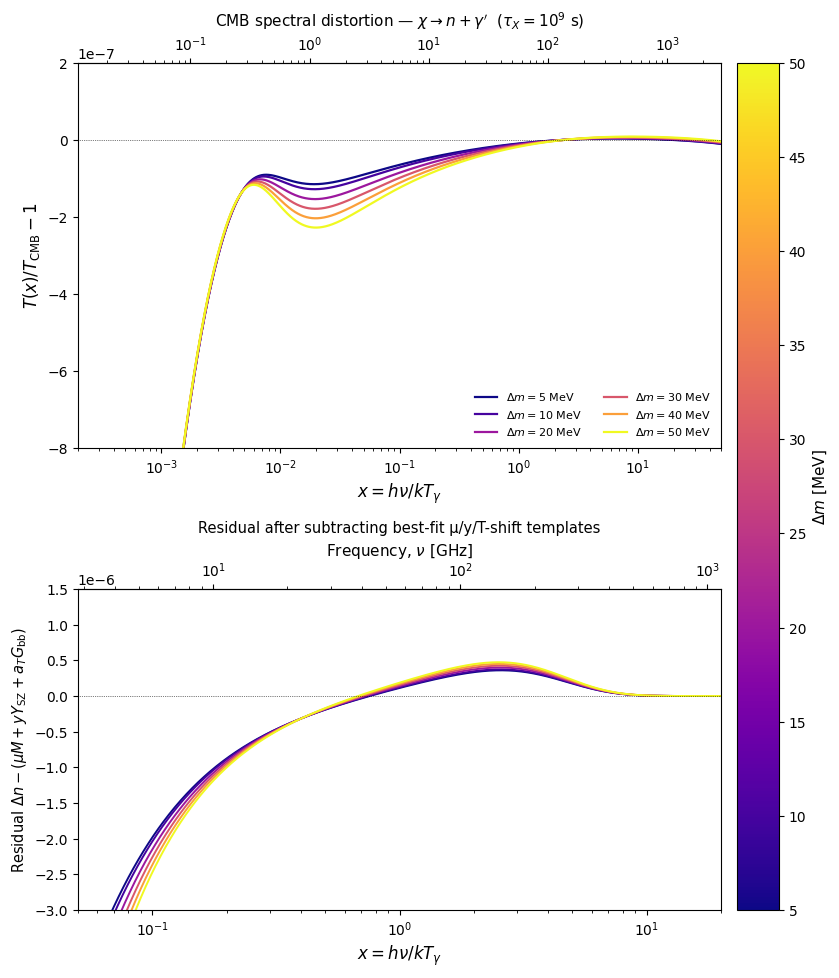

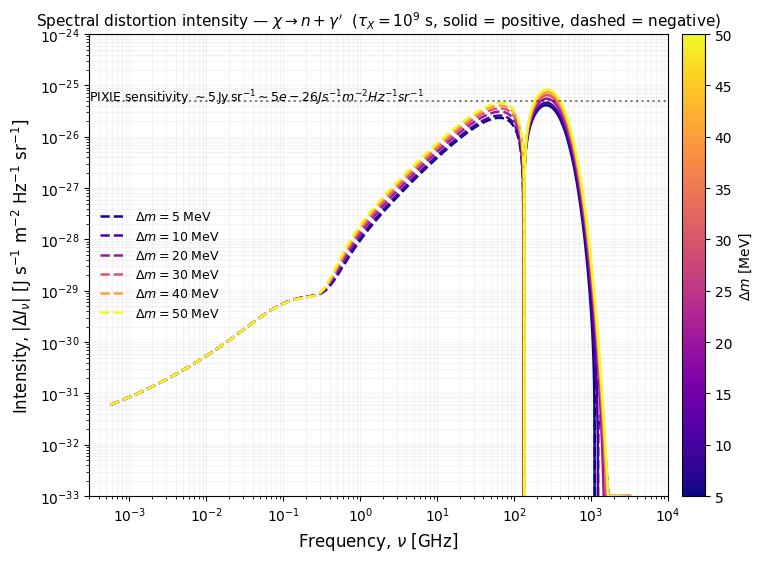

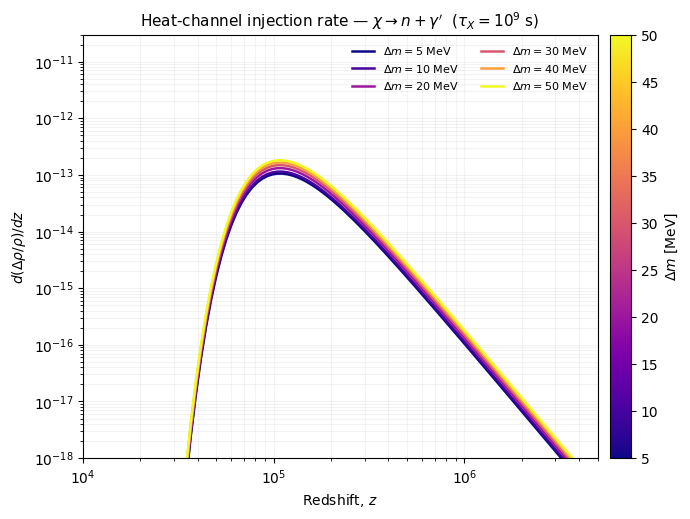

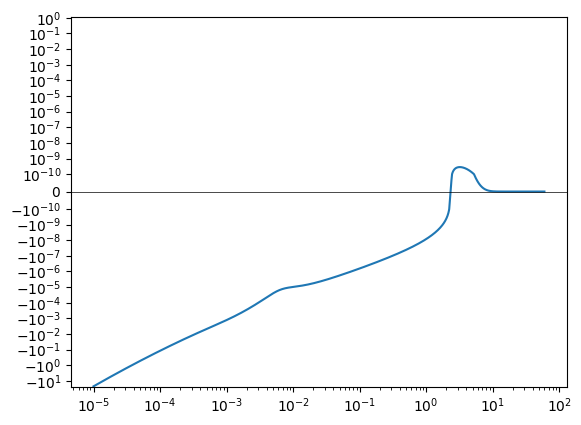

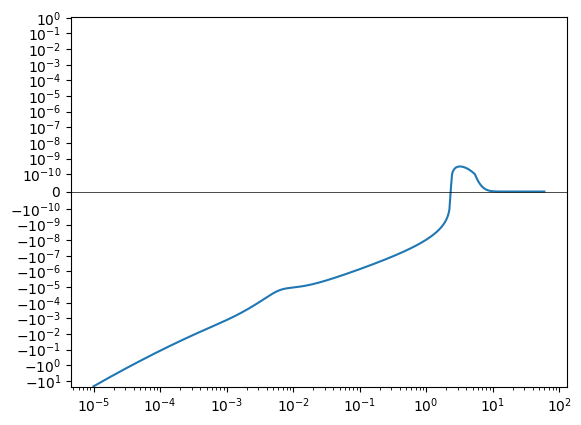

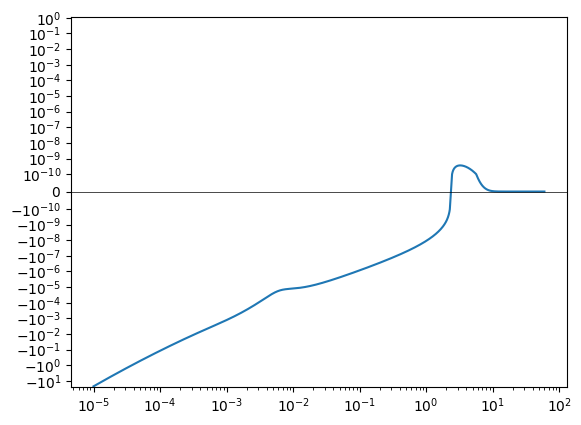

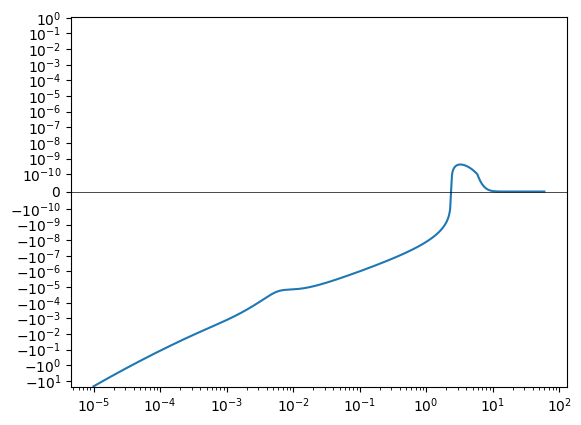

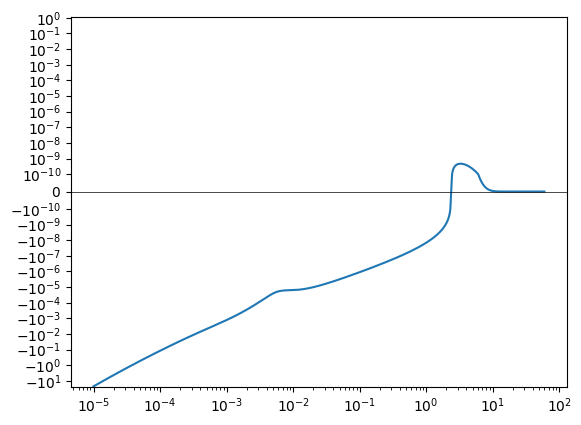

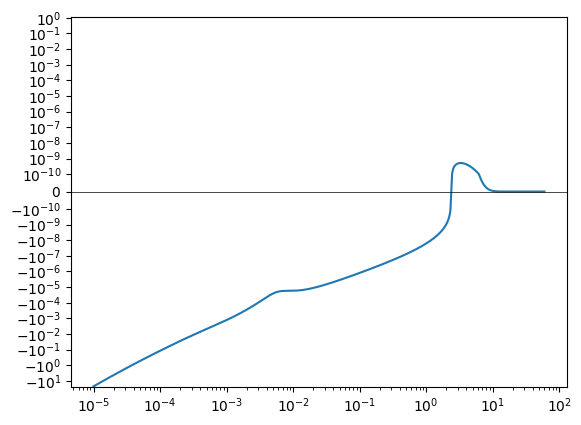


Massive dark photon case (χ → n + γ')   τ_X = 1e+09 s   n_X,0/n_H,0 = 0.01

+-----------+-------------+-------------+-------------+-------------+-------------+-------------+---------------+---------------+---------------+-------------+
| Δm [MeV]  | m_γ' [MeV]  |  F_X [eV]   |  T_n [keV]  | T_γ' [keV]  |      μ      |      y      |  a_μ (resid)  |  a_y (resid)  |  a_T (resid)  |  resid RMS  |
+-----------+-------------+-------------+-------------+-------------+-------------+-------------+---------------+---------------+---------------+-------------+
|         5 |        0.00 |   3.150e+03 |     13.2336 |   4986.7664 |   1.251e-08 |   2.053e-09 |     1.036e-09 |    -1.720e-06 |    -3.289e-06 |   9.331e-07 |
|        10 |        5.00 |   3.413e+03 |     39.4918 |   4960.5082 |   1.375e-08 |   2.301e-09 |     1.034e-09 |    -1.776e-06 |    -3.402e-06 |   9.653e-07 |
|        20 |       15.00 |   3.930e+03 |     91.1871 |   4908.8129 |   1.618e-08 |   2.790e-09 |     1.030e-09 |    -1.886

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import pandas as pd
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from scipy.integrate import quad
from spectroxide.solver import solve

# ── save location ───────────────────────────────────────────────────────────
SAVE_DIR  = "spectroxide/RUNS"
SAVE_FILE = "sweep_deltam_darkphoton_massive_tau1e9"
save_path = Path(SAVE_DIR)
save_path.mkdir(parents=True, exist_ok=True)
npz_file  = save_path / f"{SAVE_FILE}.npz"

# ── physical constants (SI) ───────────────────────────────────────────────
h_PLANCK = 6.62607015e-34     # J s
k_B      = 1.380649e-23       # J/K
c_LIGHT  = 2.99792458e8       # m/s
T_CMB0   = 2.7255             # K, present-day CMB temperature

def x_to_freq_GHz(x):
    """x = h*nu / (k_B*T_CMB) -> nu in GHz"""
    nu_Hz = x * k_B * T_CMB0 / h_PLANCK
    return nu_Hz / 1e9

def delta_n_to_intensity(x, delta_n):
    """
    Standard relation between photon occupation number and specific
    intensity:  I_nu = (2 h nu^3 / c^2) * n(x).
    A perturbation delta_n in occupation number therefore maps directly to
    an intensity perturbation via the same prefactor (linear in n).
    Returns |Delta I_nu| in J s^-1 m^-2 Hz^-1 sr^-1 (an SED, so we plot the
    magnitude on a log axis, same convention as the reference plot).
    """
    nu_Hz = x * k_B * T_CMB0 / h_PLANCK
    prefac = 2.0 * h_PLANCK * nu_Hz**3 / c_LIGHT**2
    return prefac * delta_n

# ── physical parameters ──────────────────────────────────────────────────────
tau_X   = 1e9                 # [s]
GAMMA_X = 1.0 / tau_X
den_fac = 0.01                 # n_X,0/n_H,0 (McKeen 2021 benchmark)

M_N_EV    = 939.565379e6       # neutron mass [eV]
E_HEAT_EV = 0.301791e6         # <T_e>+<T_p> from the Kurie-plot fit of n -> p e nu_bar
                                # [eV], IN THE NEUTRON'S OWN REST FRAME. Fixed by the
                                # neutron beta-decay Q-value (~782 keV, m_n-m_p-m_e);
                                # independent of Delta_m and m_gammaprime -- see
                                # spectral-distortions.nb, "Beta-decay (Kurie/Fermi)
                                # spectrum moments" cell.

DELTA_M_MEV = [5, 10, 20, 30, 40, 50]          # sweep grid [MeV]: Delta_m = m_chi - m_n
DELTA_M_EV  = np.array(DELTA_M_MEV) * 1e6       # [eV]

# ── dark photon mass, set via DARK_PHOTON_PARAM ──────────────────────────────
# DARK_PHOTON_PARAM = m_chi - m_n - m_gammaprime = Delta_m - m_gammaprime
#                =>   m_gammaprime = Delta_m - DARK_PHOTON_PARAM
# Since Delta_m varies across the sweep, DARK_PHOTON_PARAM must be given
# per-point (one value per Delta_m) to pin down m_gammaprime consistently.
# CHANGE THIS FREELY -- e.g. subtract a fixed offset from DELTA_M_EV, or
# hardcode your own array of the same length as DELTA_M_EV.
DARK_PHOTON_PARAM_EV = np.full_like(DELTA_M_EV, 5e6)

M_GAMMAPRIME_EV = DELTA_M_EV - DARK_PHOTON_PARAM_EV   # [eV], one value per Delta_m point

assert np.all(DELTA_M_EV > 0), "Delta_m = m_chi - m_n must be positive"
assert np.all(M_GAMMAPRIME_EV >= 0), (
    "DARK_PHOTON_PARAM > Delta_m at some point -> negative m_gammaprime; "
    "check DARK_PHOTON_PARAM_EV against DELTA_M_EV"
)

# ── analytic templates (occupation-number convention, matches earlier cells) ─
def G(x):
    return x * np.exp(x) / (np.exp(x) - 1)**2

def Ysz(x):
    return G(x) * (x / np.tanh(x / 2) - 4)

def tempshift(x):
    return G(x)

def mudist(x):
    return 1.401 * G(x) * (0.4561 - 1 / x)

def brightness_temp_exact(x, delta_n):
    """T(x)/T_z - 1 via eq. 35: exact inversion of the occupation number."""
    xc  = np.clip(np.asarray(x, dtype=float), 1e-12, None)
    n0  = 1.0 / np.expm1(np.clip(xc, None, 500.0))
    n_x = n0 + delta_n
    return xc / np.log1p(1.0 / n_x) - 1.0

def fit_mu_y_T(x, delta_n, x_lo=1e-3, x_hi=40.0):
    """Local linear least-squares decomposition into mu/y/T-shift templates.
    Diagnostic only for the residual panel; the table below reports the
    official spectroxide r.mu, r.y (nonlinear Bose-Einstein fit)."""
    mask = (x > x_lo) & (x < x_hi) & np.isfinite(delta_n)
    A = np.vstack([mudist(x[mask]), Ysz(x[mask]), tempshift(x[mask])]).T
    b = delta_n[mask]
    coeffs, *_ = np.linalg.lstsq(A, b, rcond=None)
    a_mu, a_y, a_T = coeffs
    model = a_mu * mudist(x) + a_y * Ysz(x) + a_T * tempshift(x)
    return delta_n - model, a_mu, a_y, a_T

# ── chi -> n + gamma' two-body kinematics ─────────────────────────────────────
def two_body_recoil(delta_m_eV, m_gammaprime_eV, m1_eV=M_N_EV):
    """
    chi -> n + gamma' in the chi (parent) rest frame, with
        Delta_m = m_chi - m_n     (parent mass M = m1 + Delta_m)
    and m_gammaprime an independently-set dark-photon mass (see
    DARK_PHOTON_PARAM above for how it's derived per Delta_m point).

    Standard two-body decay-at-rest kinematics, daughter masses m1 (neutron)
    and m2 (dark photon):
        E1 = (M^2 + m1^2 - m2^2) / (2M)     total energy of the neutron
        E2 = (M^2 + m2^2 - m1^2) / (2M)     total energy of the dark photon
    with E1 + E2 = M exactly (energy conservation). m_gammaprime_eV = 0
    recovers the original massless-recoil formula exactly.

    Returns (T_n_eV, E_gammaprime_eV, T_gammaprime_eV).
    """
    M  = m1_eV + delta_m_eV
    E1 = (M**2 + m1_eV**2 - m_gammaprime_eV**2) / (2 * M)
    E2 = (M**2 + m_gammaprime_eV**2 - m1_eV**2) / (2 * M)
    T_n          = E1 - m1_eV
    T_gammaprime = E2 - m_gammaprime_eV
    return T_n, E2, T_gammaprime

# ── cosmology (Planck 2018-like), needed only for the analytic
#    d(Delta rho/rho)/dz heating-rate diagnostic below (Baker+2026 Eq. 9-13) ──
H0_KM_S_MPC       = 67.4
OMEGA_M           = 0.315
OMEGA_R           = 9.4e-5
OMEGA_L           = 1.0 - OMEGA_M - OMEGA_R
OMEGA_B_H2        = 0.0224
Y_P               = 0.245
RHO_GAMMA0_EV_CM3 = 0.2606        # CMB energy density today, eV/cm^3 (T0=2.7255K)
M_P_G             = 1.67262192369e-24   # proton mass, g
MPC_CM            = 3.0856775814913673e24
G_NEWTON_CGS      = 6.6743e-8

H0_S     = H0_KM_S_MPC * 1e5 / MPC_CM            # H0 in s^-1
h_little = H0_KM_S_MPC / 100.0
OMEGA_B  = OMEGA_B_H2 / h_little**2
RHO_CRIT0_G_CM3 = 3 * H0_S**2 / (8 * np.pi * G_NEWTON_CGS)
N_H0_CM3 = (1 - Y_P) * OMEGA_B * RHO_CRIT0_G_CM3 / M_P_G

def E_of_z(z):
    return np.sqrt(OMEGA_M * (1 + z)**3 + OMEGA_R * (1 + z)**4 + OMEGA_L)

def H_of_z(z):
    return H0_S * E_of_z(z)

def rho_gamma_of_z(z):
    return RHO_GAMMA0_EV_CM3 * (1 + z)**4

def n_H_of_z(z):
    return N_H0_CM3 * (1 + z)**3

def age_at_z(z):
    """Cosmic time (age of the universe) at redshift z, in seconds.

    Uses the substitution u = 1/(1+z'), which maps the original
    integral over z' in [z, inf) onto a finite interval u in [0, u_max].
    This avoids scipy's infinite-limit QAGI algorithm (and the
    associated IntegrationWarning about roundoff/slow convergence),
    since the integrand in u is smooth and →0 as u→0 (H(z') ~ (1+z')^2
    in radiation domination, so 1/(u*H) ~ u -> 0).
    """
    u_max = 1.0 / (1.0 + z)

    def integrand_u(u):
        if u <= 0.0:
            return 0.0
        zp = 1.0 / u - 1.0
        return 1.0 / (u * H_of_z(zp))

    val, _ = quad(integrand_u, 0.0, u_max, limit=200)
    return val

def heating_rate_decaying_particle(z_arr, f_x_eV, gamma_x_s):
    """
    d(Delta rho/rho)/dz for spectroxide's built-in 'decaying_particle'
    injection, per baker2026 Eq. 13:
        d(Delta rho/rho)/dz = f_X Gamma_X n_H(z) exp(-Gamma_X t(z))
                               / [H(z) rho_gamma(z) (1+z)]
    Note: this is the HEAT channel only -- the dark photon carries away the
    rest of Delta_m invisibly and is not part of this fractional rate.
    """
    z_arr = np.atleast_1d(np.asarray(z_arr, dtype=float))
    out = np.empty_like(z_arr)
    for i, zi in enumerate(z_arr):
        t_s = age_at_z(zi)
        out[i] = (f_x_eV * gamma_x_s * n_H_of_z(zi) * np.exp(-gamma_x_s * t_s)
                  / (H_of_z(zi) * rho_gamma_of_z(zi) * (1 + zi)))
    return out

Z_HEAT = np.logspace(-1, 7, 300)   # matches the sweep's own z_start=1e7 -> z_end=0 range

# ── signed log-log plotting helper (NEW: ported from the photon-case script) ─
def plot_signed_loglog(ax, x, y, color, lw=1.8, label=None, floor=None):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    finite = np.isfinite(x) & np.isfinite(y)
    if not np.all(finite):
        print(f"  [plot_signed_loglog] '{label}': dropped "
              f"{np.sum(~finite)} non-finite point(s) before plotting")
    x, y = x[finite], y[finite]
    if len(x) < 2:
        print(f"  [plot_signed_loglog] '{label}': fewer than 2 finite points, skipping")
        return

    if floor is None:
        nonzero = np.abs(y[y != 0])
        floor = nonzero.min() * 1e-3 if nonzero.size else 1e-30

    def interp_zero(x0, y0, x1, y1):
        frac = y0 / (y0 - y1)
        return np.exp(np.log(x0) + frac * (np.log(x1) - np.log(x0)))

    def flush(seg_x, seg_y, sign_positive, first_label):
        if len(seg_x) >= 2:
            mag = np.clip(np.abs(np.array(seg_y)), floor, None)
            ls = '-' if sign_positive else '--'
            ax.plot(seg_x, mag, color=color, lw=lw, ls=ls,
                     label=(label if first_label else None))
            return False
        return first_label

    seg_x, seg_y = [x[0]], [y[0]]
    sign_positive = (y[0] >= 0)      # <- track sign explicitly, not from seg_y[0]
    first = True
    for i in range(len(x) - 1):
        x0, y0, x1, y1 = x[i], y[i], x[i + 1], y[i + 1]
        if (y0 >= 0) != (y1 >= 0) and y0 != y1:
            xz = interp_zero(x0, y0, x1, y1)
            seg_x.append(xz); seg_y.append(0.0)
            first = flush(seg_x, seg_y, sign_positive, first)
            sign_positive = (y1 >= 0)          # <- sign of the segment we're starting
            seg_x, seg_y = [xz, x1], [0.0, y1]
        else:
            seg_x.append(x1); seg_y.append(y1)
    flush(seg_x, seg_y, sign_positive, first)

# ── load cache (resume support) ──────────────────────────────────────────────
results = {}
if npz_file.exists():
    print(f"Found existing data at '{npz_file}', loading...")
    existing = np.load(npz_file, allow_pickle=True)
    loaded_keys = set(existing.files)
    for dm in DELTA_M_EV:
        kx, kdn, kmu, ky = (f"dm{dm:.6g}_{s}" for s in ("x", "delta_n", "mu", "y"))
        if all(k in loaded_keys for k in (kx, kdn, kmu, ky)):
            results[dm] = (existing[kx], existing[kdn], float(existing[kmu]), float(existing[ky]))
            print(f"  loaded Δm = {dm/1e6:.0f} MeV")

def save_results():
    flat = {"tau_X": np.array(tau_X), "den_fac": np.array(den_fac),
            "E_heat_eV": np.array(E_HEAT_EV),
            "delta_m_ev": DELTA_M_EV,
            "dark_photon_param_ev": DARK_PHOTON_PARAM_EV,
            "m_gammaprime_ev": M_GAMMAPRIME_EV}
    for dm, (x_arr, dn, mu_r, y_r) in results.items():
        flat[f"dm{dm:.6g}_x"]       = x_arr
        flat[f"dm{dm:.6g}_delta_n"] = dn
        flat[f"dm{dm:.6g}_mu"]      = np.array(mu_r)
        flat[f"dm{dm:.6g}_y"]       = np.array(y_r)
    np.savez(npz_file, **flat)
    print(f"  → saved to '{npz_file}'")


# ── run one Δm point (used by the parallel pool below) ───────────────────────
def run_one(dm, m_gammaprime_eV):
    T_n_eV, E_gammaprime_eV, T_gammaprime_eV = two_body_recoil(dm, m_gammaprime_eV)
    # heat channel: neutron's recoil KE from the chi decay + its subsequent
    # beta-decay heat (<T_e>+<T_p>, fixed). The dark photon is invisible and
    # deposits no heat -- its energy (E_gammaprime_eV, including its rest
    # mass) simply leaves the heat budget entirely.
    F_X = den_fac * (E_HEAT_EV + T_n_eV)
    r = solve(
        injection = {'type': 'decaying_particle', 'f_x': F_X, 'gamma_x': GAMMA_X},
        z_start           = 5.0e6,
        z_end             = 5.0e2,
        x_min             = 1.5e-4,
        x_max             = 80.0,
        n_x               = 1000,
        method            = 'pde',
        production_grid   = True,
        number_conserving = True,
        timeout           = 3600,
        dtau_max          = 5.0,
    )
    return dm, (r.x, r.delta_n, r.mu, r.y)

# ── run all missing Δm points at the same time ────────────────────────────────
to_run = [dm for dm in DELTA_M_EV if dm not in results]
if to_run:
    print(f"Launching {len(to_run)} runs in parallel ...")
    with ThreadPoolExecutor(max_workers=min(len(to_run), 10)) as ex:
        futures = {
            ex.submit(run_one, dm, M_GAMMAPRIME_EV[i]): dm
            for i, dm in enumerate(DELTA_M_EV) if dm in to_run
        }
        for fut in as_completed(futures):
            dm = futures[fut]
            try:
                dm_done, payload = fut.result()
                results[dm_done] = payload
                print(f"  Δm = {dm_done/1e6:.0f} MeV ... done")
            except Exception as e:
                print(f"  Δm = {dm/1e6:.0f} MeV ... FAILED: {e}")
    save_results()
else:
    print("All Δm points already cached.")

# ── colour gradient over Δm ───────────────────────────────────────────────────
cmap = plt.cm.plasma
norm = mcolors.Normalize(vmin=min(DELTA_M_MEV), vmax=max(DELTA_M_MEV))
sm   = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# ── plot: spectrum (top) + residual (bottom) ─────────────────────────────────
fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(10, 11), gridspec_kw={"height_ratios": [1.2, 1], "hspace": 0.4}
)

fig, ax = plt.subplots(figsize=(9, 6))

table_rows = []
for i, (dm_mev, dm) in enumerate(zip(DELTA_M_MEV, DELTA_M_EV)):
    x_arr, dn, mu_r, y_r = results[dm]
    c = cmap(norm(dm_mev))

    dT = brightness_temp_exact(x_arr, dn)
    ax_top.semilogx(x_arr, dT, color=c, lw=1.6, label=fr'$\Delta m={dm_mev}$ MeV')

    resid, a_mu, a_y, a_T = fit_mu_y_T(x_arr, dn)
    mask_plot = (x_arr > 0.05) & (x_arr < 20)
    ax_bot.semilogx(x_arr[mask_plot], resid[mask_plot], color=c, lw=1.4)

    m_gammap_eV = M_GAMMAPRIME_EV[i]
    T_n_eV, E_gammaprime_eV, T_gammaprime_eV = two_body_recoil(dm, m_gammap_eV)
    table_rows.append(dict(
        delta_m_MeV   = dm_mev,
        m_gammap_MeV  = m_gammap_eV / 1e6,
        F_X_eV        = (E_HEAT_EV + T_n_eV) * den_fac,
        T_n_keV       = T_n_eV / 1e3,
        T_gammap_keV  = T_gammaprime_eV / 1e3,
        mu            = mu_r,
        y             = y_r,
        a_mu_resid    = a_mu,
        a_y_resid     = a_y,
        a_T_resid     = a_T,
        resid_rms     = np.sqrt(np.mean(resid[mask_plot]**2)),
    ))

ax_top.axhline(0, color='k', lw=0.5, ls=':')
ax_top.set_xlim(2e-4, 50)
ax_top.set_ylim(-8e-7, 2e-7)
ax_top.set_xlabel(r'$x = h\nu / kT_{\gamma}$', fontsize=12)
ax_top.set_ylabel(r'$T(x)/T_{\rm CMB} - 1$', fontsize=12)
ax_top.set_title(r'CMB spectral distortion — $\chi \to n + \gamma^\prime$  ($\tau_X=10^9$ s)', fontsize=11)
ax_top.legend(fontsize=8, frameon=False, loc='lower right', ncol=2)

ax_bot.axhline(0, color='k', lw=0.5, ls=':')
ax_bot.set_xlim(0.05, 20)
ax_bot.set_ylim(-30e-7, 15e-7)
ax_bot.set_xlabel(r'$x = h\nu / kT_{\gamma}$', fontsize=12)
ax_bot.set_ylabel(r'Residual $\Delta n - (\mu M + y Y_{\rm SZ} + a_T G_{\rm bb})$', fontsize=10.5)
ax_bot.set_title('Residual after subtracting best-fit µ/y/T-shift templates', fontsize=10.5)

def x_to_GHz(x):
    return x_to_freq_GHz(x)          # already defined earlier in each script

def GHz_to_x(nu_GHz):
    nu_Hz = nu_GHz * 1e9
    return nu_Hz * h_PLANCK / (k_B * T_CMB0)

secax = ax_top.secondary_xaxis('top', functions=(x_to_GHz, GHz_to_x))
secax = ax_bot.secondary_xaxis('top', functions=(x_to_GHz, GHz_to_x))
secax.set_xlabel(r'Frequency, $\nu$ [GHz]', fontsize=11)

cbar = fig.colorbar(sm, ax=[ax_top, ax_bot], pad=0.02)
cbar.set_label(r'$\Delta m$ [MeV]', fontsize=11)

# ── intensity plot (NEW: uses the fixed signed log-log plotter instead of a
#    manual pos/neg split, so every zero crossing is handled correctly) ──────
for dm_mev, dm in zip(DELTA_M_MEV, DELTA_M_EV):
    x_arr, delta_n, mu_r, y_r = results[dm]     # <- your existing results dict

    nu_GHz  = x_to_freq_GHz(x_arr)
    I_nu    = delta_n_to_intensity(x_arr, delta_n)

    c = cmap(norm(dm_mev))
    plot_signed_loglog(ax, nu_GHz, I_nu, color=c, lw=1.8,
                        label=fr'$\Delta m={dm_mev}$ MeV', floor=1e-33)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(3e-4, 1e4)
ax.set_ylim(1e-33, 1e-24)
xlim = ax.get_xlim()
pixie_sens = 5e-26   # J s^-1 m^-2 Hz^-1 sr^-1  (Kogut et al. 2011, ~5 Jy/sr)
ax.plot([5e-4, xlim[1]], [pixie_sens, pixie_sens], color='black', lw=1.5, ls=':', alpha=0.5)
ax.annotate(fr'PIXIE sensitivity $\sim5\,\mathrm{{Jy\,sr^{{-1}}}} \sim {pixie_sens} J s^{{-1}} m^{{-2}} Hz^{{-1}} sr^{{-1}}$',
            xy=(3e-2, pixie_sens),
            xytext=(3e-4, pixie_sens),
            fontsize=9, color='black')
ax.set_xlabel(r'Frequency, $\nu$ [GHz]', fontsize=12)
ax.set_ylabel(r'Intensity, $|\Delta I_\nu|$ [J s$^{-1}$ m$^{-2}$ Hz$^{-1}$ sr$^{-1}$]', fontsize=12)
ax.set_title(r'Spectral distortion intensity — $\chi \to n + \gamma^\prime$'
             r'  ($\tau_X=10^9$ s, solid = positive, dashed = negative)', fontsize=11)
ax.legend(fontsize=9, frameon=False, loc='best')
ax.grid(True, which='both', alpha=0.15)

fig.colorbar(sm, ax=ax, pad=0.02, label=r'$\Delta m$ [MeV]')

# ── heating rate d(Δρ/ρ)/dz vs z ──
fig_heat, ax_heat = plt.subplots(figsize=(8, 5.5))
for i, (dm_mev, dm) in enumerate(zip(DELTA_M_MEV, DELTA_M_EV)):
    T_n_eV, _, _ = two_body_recoil(dm, M_GAMMAPRIME_EV[i])
    F_X = den_fac * (E_HEAT_EV + T_n_eV)
    heat_rate = heating_rate_decaying_particle(Z_HEAT, F_X, GAMMA_X)
    c = cmap(norm(dm_mev))
    ax_heat.loglog(Z_HEAT, heat_rate, color=c, lw=1.8, label=fr'$\Delta m={dm_mev}$ MeV')

ax_heat.set_xlabel(r'Redshift, $z$')
ax_heat.set_ylabel(r'$d(\Delta\rho/\rho)/dz$')
ax_heat.set_xlim(1e4, 5e6)
ax_heat.set_ylim(1e-18, 3e-11)
ax_heat.set_title(r'Heat-channel injection rate — $\chi \to n + \gamma^\prime$  ($\tau_X=10^9$ s)', fontsize=11)
ax_heat.legend(fontsize=8, frameon=False, ncol=2)
ax_heat.grid(True, which='both', alpha=0.15)
fig_heat.colorbar(sm, ax=ax_heat, pad=0.02, label=r'$\Delta m$ [MeV]')

# ── per-Δm sanity check plots (NEW: added, loops over ALL Δm points) ────────
for i in range(len(DELTA_M_MEV)):
    x_arr_check, dn_check = results[DELTA_M_EV[i]][:2]  # pick one Δm for the check plot
    fig, ax = plt.subplots()
    ax.plot(x_arr_check, dn_check)  # no abs(), no masking
    ax.set_xscale('log')
    ax.set_yscale('symlog', linthresh=1e-10)
    ax.axhline(0, color='k', lw=0.5)

plt.show()

# ── summary table ─────────────────────────────────────────────────────────────
def print_table(rows, columns):
    """columns: list of (key, header, fmt, width)"""
    sep = "+" + "+".join("-" * (w + 2) for _, _, _, w in columns) + "+"
    header = "| " + " | ".join(f"{h:^{w}}" for _, h, _, w in columns) + " |"
    print(sep)
    print(header)
    print(sep)
    for row in rows:
        line = "| " + " | ".join(
            f"{format(row[k], fmt):>{w}}" for k, h, fmt, w in columns
        ) + " |"
        print(line)
    print(sep)

columns = [
    ("delta_m_MeV",  "Δm [MeV]",       ".0f",  9),
    ("m_gammap_MeV", "m_γ' [MeV]",     ".2f", 11),
    ("F_X_eV",       "F_X [eV]",       ".3e", 11),
    ("T_n_keV",      "T_n [keV]",      ".4f", 11),
    ("T_gammap_keV", "T_γ' [keV]",     ".4f", 11),
    ("mu",           "μ",              ".3e", 11),
    ("y",            "y",              ".3e", 11),
    ("a_mu_resid",   "a_μ (resid)",    ".3e", 13),
    ("a_y_resid",    "a_y (resid)",    ".3e", 13),
    ("a_T_resid",    "a_T (resid)",    ".3e", 13),
    ("resid_rms",    "resid RMS",      ".3e", 11),
]

print(f"\nMassive dark photon case (χ → n + γ')   τ_X = {tau_X:.0e} s   "
      f"n_X,0/n_H,0 = {den_fac}\n")
print_table(table_rows, columns)

### $\chi \rightarrow n + \gamma'$ : `spectroxide` ($m_{\gamma'}$ sweep, $\Delta m = 5MeV$)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import pandas as pd
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from scipy.integrate import quad
from spectroxide.solver import solve

# ── save location ───────────────────────────────────────────────────────────
SAVE_DIR  = "spectroxide/RUNS"
SAVE_FILE = "sweep_beta_darkphoton_deltam5_tau1e9"
save_path = Path(SAVE_DIR)
save_path.mkdir(parents=True, exist_ok=True)
npz_file  = save_path / f"{SAVE_FILE}.npz"

# ── physical constants (SI) ───────────────────────────────────────────────
h_PLANCK = 6.62607015e-34     # J s
k_B      = 1.380649e-23       # J/K
c_LIGHT  = 2.99792458e8       # m/s
T_CMB0   = 2.7255             # K, present-day CMB temperature


def delta_n_to_intensity(x, delta_n):
    """
    Standard relation between photon occupation number and specific
    intensity:  I_nu = (2 h nu^3 / c^2) * n(x).
    A perturbation delta_n in occupation number therefore maps directly to
    an intensity perturbation via the same prefactor (linear in n).
    Returns |Delta I_nu| in J s^-1 m^-2 Hz^-1 sr^-1 (an SED, so we plot the
    magnitude on a log axis, same convention as the reference plot).
    """
    nu_Hz = x * k_B * T_CMB0 / h_PLANCK
    prefac = 2.0 * h_PLANCK * nu_Hz**3 / c_LIGHT**2
    return prefac * delta_n

# ── physical parameters ──────────────────────────────────────────────────────
tau_X   = 1e9                 # [s]
GAMMA_X = 1.0 / tau_X
den_fac = 0.01                 # n_X,0/n_H,0 (McKeen 2021 benchmark)

M_N_EV = 939.565379e6          # neutron mass [eV]
E_HEAT_EV = 0.301791e6         # <T_e>+<T_p> from the Kurie-plot fit of n -> p e nu_bar
                                # [eV], IN THE NEUTRON'S OWN REST FRAME. Fixed by the
                                # neutron beta-decay Q-value (~782 keV, m_n-m_p-m_e);
                                # independent of Delta_m and m_gammaprime -- see
                                # spectral-distortions.nb, "Beta-decay (Kurie/Fermi)
                                # spectrum moments" cell.

# ── fixed Delta_m, sweep over dark photon mass via beta ─────────────────────
# Delta_m = m_chi - m_n is now FIXED at 10 MeV. The sweep variable is
#     beta = m_gammaprime / Delta_m   (dimensionless, 0 <= beta < 1)
# so that m_gammaprime = beta * Delta_m. beta=0 recovers the massless-recoil
# (photon-like dark photon) case; beta->1 pushes m_gammaprime -> Delta_m,
# i.e. the neutron carries away almost none of the mass splitting as KE.
DELTA_M_MEV_FIXED = 5.0
DELTA_M_EV_FIXED  = DELTA_M_MEV_FIXED * 1e6      # [eV]

BETA_GRID = np.array([0.0, 1.0/10.0, 1.0/3.0, 0.9])   # [0, Delta_m/10, Delta_m/3, 0.9*Delta_m] / Delta_m
M_GAMMAPRIME_EV = BETA_GRID * DELTA_M_EV_FIXED         # [eV], one value per beta point

assert DELTA_M_EV_FIXED > 0, "Delta_m = m_chi - m_n must be positive"
assert np.all((BETA_GRID >= 0) & (BETA_GRID < 1)), "beta = m_gammaprime/Delta_m must be in [0,1)"

# used as the sweep "key" everywhere below (in place of DELTA_M_EV from the
# original scripts) -- one entry per beta point, all sharing the same Delta_m
BETA_KEYS = BETA_GRID.copy()

# ── analytic templates (occupation-number convention, matches earlier cells) ─
def G(x):
    return x * np.exp(x) / (np.exp(x) - 1)**2

def Ysz(x):
    return G(x) * (x / np.tanh(x / 2) - 4)

def tempshift(x):
    return G(x)

def mudist(x):
    return 1.401 * G(x) * (0.4561 - 1 / x)

def brightness_temp_exact(x, delta_n):
    """T(x)/T_gamma - 1 via eq. 35: exact inversion of the occupation number."""
    xc  = np.clip(np.asarray(x, dtype=float), 1e-12, None)
    n0  = 1.0 / np.expm1(np.clip(xc, None, 500.0))
    n_x = n0 + delta_n
    return xc / np.log1p(1.0 / n_x) - 1.0

def fit_mu_y_T(x, delta_n, x_lo=1e-3, x_hi=40.0):
    """Local linear least-squares decomposition into mu/y/T-shift templates.
    Diagnostic only for the residual panel; the table below reports the
    official spectroxide r.mu, r.y (nonlinear Bose-Einstein fit)."""
    mask = (x > x_lo) & (x < x_hi) & np.isfinite(delta_n)
    A = np.vstack([mudist(x[mask]), Ysz(x[mask]), tempshift(x[mask])]).T
    b = delta_n[mask]
    coeffs, *_ = np.linalg.lstsq(A, b, rcond=None)
    a_mu, a_y, a_T = coeffs
    model = a_mu * mudist(x) + a_y * Ysz(x) + a_T * tempshift(x)
    return delta_n - model, a_mu, a_y, a_T

# ── chi -> n + gamma' two-body kinematics ─────────────────────────────────────
def two_body_recoil(delta_m_eV, m_gammaprime_eV, m1_eV=M_N_EV):
    """
    chi -> n + gamma' in the chi (parent) rest frame, with
        Delta_m = m_chi - m_n     (parent mass M = m1 + Delta_m)
    and m_gammaprime an independently-set dark-photon mass.

    Standard two-body decay-at-rest kinematics, daughter masses m1 (neutron)
    and m2 (dark photon):
        E1 = (M^2 + m1^2 - m2^2) / (2M)     total energy of the neutron
        E2 = (M^2 + m2^2 - m1^2) / (2M)     total energy of the dark photon
    with E1 + E2 = M exactly (energy conservation). m_gammaprime_eV = 0
    recovers the original massless-recoil formula exactly.

    Returns (T_n_eV, E_gammaprime_eV, T_gammaprime_eV).
    """
    M  = m1_eV + delta_m_eV
    E1 = (M**2 + m1_eV**2 - m_gammaprime_eV**2) / (2 * M)
    E2 = (M**2 + m_gammaprime_eV**2 - m1_eV**2) / (2 * M)
    T_n          = E1 - m1_eV
    T_gammaprime = E2 - m_gammaprime_eV
    return T_n, E2, T_gammaprime

# ── cosmology (Planck 2018-like), needed only for the analytic
#    d(Delta rho/rho)/dz heating-rate diagnostic below (Baker+2026 Eq. 9-13) ──
H0_KM_S_MPC       = 67.4
OMEGA_M           = 0.315
OMEGA_R           = 9.4e-5
OMEGA_L           = 1.0 - OMEGA_M - OMEGA_R
OMEGA_B_H2        = 0.0224
Y_P               = 0.245
RHO_GAMMA0_EV_CM3 = 0.2606        # CMB energy density today, eV/cm^3 (T0=2.7255K)
M_P_G             = 1.67262192369e-24   # proton mass, g
MPC_CM            = 3.0856775814913673e24
G_NEWTON_CGS      = 6.6743e-8

H0_S     = H0_KM_S_MPC * 1e5 / MPC_CM            # H0 in s^-1
h_little = H0_KM_S_MPC / 100.0
OMEGA_B  = OMEGA_B_H2 / h_little**2
RHO_CRIT0_G_CM3 = 3 * H0_S**2 / (8 * np.pi * G_NEWTON_CGS)
N_H0_CM3 = (1 - Y_P) * OMEGA_B * RHO_CRIT0_G_CM3 / M_P_G

def E_of_z(z):
    return np.sqrt(OMEGA_M * (1 + z)**3 + OMEGA_R * (1 + z)**4 + OMEGA_L)

def H_of_z(z):
    return H0_S * E_of_z(z)

def rho_gamma_of_z(z):
    return RHO_GAMMA0_EV_CM3 * (1 + z)**4

def n_H_of_z(z):
    return N_H0_CM3 * (1 + z)**3

def age_at_z(z):
    """Cosmic time (age of the universe) at redshift z, in seconds.

    Uses the substitution u = 1/(1+z'), which maps the original
    integral over z' in [z, inf) onto a finite interval u in [0, u_max].
    This avoids scipy's infinite-limit QAGI algorithm (and the
    associated IntegrationWarning about roundoff/slow convergence),
    since the integrand in u is smooth and ->0 as u->0 (H(z') ~ (1+z')^2
    in radiation domination, so 1/(u*H) ~ u -> 0).
    """
    u_max = 1.0 / (1.0 + z)

    def integrand_u(u):
        if u <= 0.0:
            return 0.0
        zp = 1.0 / u - 1.0
        return 1.0 / (u * H_of_z(zp))

    val, _ = quad(integrand_u, 0.0, u_max, limit=200)
    return val

def heating_rate_decaying_particle(z_arr, f_x_eV, gamma_x_s):
    """
    d(Delta rho/rho)/dz for spectroxide's built-in 'decaying_particle'
    injection, per baker2026 Eq. 13:
        d(Delta rho/rho)/dz = f_X Gamma_X n_H(z) exp(-Gamma_X t(z))
                               / [H(z) rho_gamma(z) (1+z)]
    Note: this is the HEAT channel only -- the dark photon carries away the
    rest of Delta_m invisibly and is not part of this fractional rate.
    """
    z_arr = np.atleast_1d(np.asarray(z_arr, dtype=float))
    out = np.empty_like(z_arr)
    for i, zi in enumerate(z_arr):
        t_s = age_at_z(zi)
        out[i] = (f_x_eV * gamma_x_s * n_H_of_z(zi) * np.exp(-gamma_x_s * t_s)
                  / (H_of_z(zi) * rho_gamma_of_z(zi) * (1 + zi)))
    return out

Z_HEAT = np.logspace(-1, 7, 300)   # matches the sweep's own z_start=1e7 -> z_end=0 range

# ── signed log-log plotting helper (NEW: ported from the photon-case script) ─
def plot_signed_loglog(ax, x, y, color, lw=1.8, label=None, floor=None):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    finite = np.isfinite(x) & np.isfinite(y)
    if not np.all(finite):
        print(f"  [plot_signed_loglog] '{label}': dropped "
              f"{np.sum(~finite)} non-finite point(s) before plotting")
    x, y = x[finite], y[finite]
    if len(x) < 2:
        print(f"  [plot_signed_loglog] '{label}': fewer than 2 finite points, skipping")
        return

    if floor is None:
        nonzero = np.abs(y[y != 0])
        floor = nonzero.min() * 1e-3 if nonzero.size else 1e-30

    def interp_zero(x0, y0, x1, y1):
        frac = y0 / (y0 - y1)
        return np.exp(np.log(x0) + frac * (np.log(x1) - np.log(x0)))

    def flush(seg_x, seg_y, sign_positive, first_label):
        if len(seg_x) >= 2:
            mag = np.clip(np.abs(np.array(seg_y)), floor, None)
            ls = '-' if sign_positive else '--'
            ax.plot(seg_x, mag, color=color, lw=lw, ls=ls,
                     label=(label if first_label else None))
            return False
        return first_label

    seg_x, seg_y = [x[0]], [y[0]]
    sign_positive = (y[0] >= 0)      # <- track sign explicitly, not from seg_y[0]
    first = True
    for i in range(len(x) - 1):
        x0, y0, x1, y1 = x[i], y[i], x[i + 1], y[i + 1]
        if (y0 >= 0) != (y1 >= 0) and y0 != y1:
            xz = interp_zero(x0, y0, x1, y1)
            seg_x.append(xz); seg_y.append(0.0)
            first = flush(seg_x, seg_y, sign_positive, first)
            sign_positive = (y1 >= 0)          # <- sign of the segment we're starting
            seg_x, seg_y = [xz, x1], [0.0, y1]
        else:
            seg_x.append(x1); seg_y.append(y1)
    flush(seg_x, seg_y, sign_positive, first)

# ── load cache (resume support) ──────────────────────────────────────────────
# keyed by beta (rounded to a stable string key) instead of Delta_m, since
# Delta_m is now fixed and beta is the sweep variable
def beta_key(beta):
    return f"{beta:.6g}"

results = {}
if npz_file.exists():
    print(f"Found existing data at '{npz_file}', loading...")
    existing = np.load(npz_file, allow_pickle=True)
    loaded_keys = set(existing.files)
    for beta in BETA_KEYS:
        bk = beta_key(beta)
        kx, kdn, kmu, ky = (f"beta{bk}_{s}" for s in ("x", "delta_n", "mu", "y"))
        if all(k in loaded_keys for k in (kx, kdn, kmu, ky)):
            results[bk] = (existing[kx], existing[kdn], float(existing[kmu]), float(existing[ky]))
            print(f"  loaded beta = {beta:.4g}")

def save_results():
    flat = {"tau_X": np.array(tau_X), "den_fac": np.array(den_fac),
            "E_heat_eV": np.array(E_HEAT_EV),
            "delta_m_ev_fixed": np.array(DELTA_M_EV_FIXED),
            "beta_grid": BETA_GRID,
            "m_gammaprime_ev": M_GAMMAPRIME_EV}
    for bk, (x_arr, dn, mu_r, y_r) in results.items():
        flat[f"beta{bk}_x"]       = x_arr
        flat[f"beta{bk}_delta_n"] = dn
        flat[f"beta{bk}_mu"]      = np.array(mu_r)
        flat[f"beta{bk}_y"]       = np.array(y_r)
    np.savez(npz_file, **flat)
    print(f"  -> saved to '{npz_file}'")


# ── run one beta point (used by the parallel pool below) ─────────────────────
def run_one(beta, m_gammaprime_eV):
    T_n_eV, E_gammaprime_eV, T_gammaprime_eV = two_body_recoil(DELTA_M_EV_FIXED, m_gammaprime_eV)
    # heat channel: neutron's recoil KE from the chi decay + its subsequent
    # beta-decay heat (<T_e>+<T_p>, fixed). The dark photon is invisible and
    # deposits no heat -- its energy (E_gammaprime_eV, including its rest
    # mass) simply leaves the heat budget entirely.
    F_X = den_fac * (E_HEAT_EV + T_n_eV)
    r = solve(
        injection = {'type': 'decaying_particle', 'f_x': F_X, 'gamma_x': GAMMA_X},
        z_start           = 5.0e6,
        z_end             = 5.0e2,
        x_min             = 1.5e-4,
        x_max             = 80.0,
        n_x               = 1000,
        method            = 'pde',
        production_grid   = True,
        number_conserving = True,
        timeout           = 3600,
        dtau_max          = 5.0,
    )
    return beta, (r.x, r.delta_n, r.mu, r.y)

# ── run all missing beta points at the same time ──────────────────────────────
to_run = [beta for beta in BETA_KEYS if beta_key(beta) not in results]
if to_run:
    print(f"Launching {len(to_run)} runs in parallel ...")
    with ThreadPoolExecutor(max_workers=min(len(to_run), 10)) as ex:
        futures = {
            ex.submit(run_one, beta, M_GAMMAPRIME_EV[i]): beta
            for i, beta in enumerate(BETA_KEYS) if beta in to_run
        }
        for fut in as_completed(futures):
            beta = futures[fut]
            try:
                beta_done, payload = fut.result()
                results[beta_key(beta_done)] = payload
                print(f"  beta = {beta_done:.4g} ... done")
            except Exception as e:
                print(f"  beta = {beta:.4g} ... FAILED: {e}")
    save_results()
else:
    print("All beta points already cached.")

# ── colour gradient over beta ─────────────────────────────────────────────────
cmap = plt.cm.plasma
norm = mcolors.Normalize(vmin=min(BETA_GRID), vmax=max(BETA_GRID))
sm   = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

def beta_label(beta):
    if beta == 0.0:
        return r'$\beta=0$'
    return fr'$\beta={beta:.3g}$'

# ── plot: spectrum (top) + residual (bottom) ─────────────────────────────────
fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(10, 11), gridspec_kw={"height_ratios": [1.2, 1], "hspace": 0.4}
)

fig2, ax = plt.subplots(figsize=(9, 6))

table_rows = []
for i, beta in enumerate(BETA_GRID):
    bk = beta_key(beta)
    x_arr, dn, mu_r, y_r = results[bk]
    c = cmap(norm(beta))

    dT = brightness_temp_exact(x_arr, dn)
    ax_top.semilogx(x_arr, dT, color=c, lw=1.6, label=beta_label(beta))

    resid, a_mu, a_y, a_T = fit_mu_y_T(x_arr, dn)
    mask_plot = (x_arr > 0.05) & (x_arr < 20)
    ax_bot.semilogx(x_arr[mask_plot], resid[mask_plot], color=c, lw=1.4)

    m_gammap_eV = M_GAMMAPRIME_EV[i]
    T_n_eV, E_gammaprime_eV, T_gammaprime_eV = two_body_recoil(DELTA_M_EV_FIXED, m_gammap_eV)
    table_rows.append(dict(
        beta          = beta,
        m_gammap_MeV  = m_gammap_eV / 1e6,
        F_X_eV        = (E_HEAT_EV + T_n_eV) * den_fac,
        T_n_keV       = T_n_eV / 1e3,
        T_gammap_keV  = T_gammaprime_eV / 1e3,
        mu            = mu_r,
        y             = y_r,
        a_mu_resid    = a_mu,
        a_y_resid     = a_y,
        a_T_resid     = a_T,
        resid_rms     = np.sqrt(np.mean(resid[mask_plot]**2)),
    ))

ax_top.axhline(0, color='k', lw=0.5, ls=':')
ax_top.set_xlim(2e-4, 50)
ax_top.set_ylim(-8e-7, 2e-7)
ax_top.set_xlabel(r'$x = h\nu / kT_{\gamma}$', fontsize=12)
ax_top.set_ylabel(r'$T(x)/T_{\rm CMB} - 1$', fontsize=12)
ax_top.set_title(fr'CMB spectral distortion — $\chi \to n + \gamma^\prime$  '
                  fr'($\Delta m={DELTA_M_MEV_FIXED:.0f}$ MeV, $\tau_X=10^9$ s)', fontsize=11)
ax_top.legend(fontsize=8, frameon=False, loc='lower right', ncol=2)

ax_bot.axhline(0, color='k', lw=0.5, ls=':')
ax_bot.set_xlim(0.05, 20)
ax_bot.set_ylim(-30e-7, 15e-7)
ax_bot.set_xlabel(r'$x = h\nu / kT_{\gamma}$', fontsize=12)
ax_bot.set_ylabel(r'Residual $\Delta n - (\mu M + y Y_{\rm SZ} + a_T G_{\rm bb})$', fontsize=10.5)
ax_bot.set_title('Residual after subtracting best-fit µ/y/T-shift templates', fontsize=10.5)

def x_to_freq_GHz(x):
    """x = h*nu / (k_B*T_gamma), T_gamma = T_CMB0 -> nu in GHz"""
    nu_Hz = x * k_B * T_CMB0 / h_PLANCK
    return nu_Hz / 1e9

secax = ax_top.secondary_xaxis('top', functions=(x_to_freq_GHz, lambda nu_GHz: nu_GHz * 1e9 * h_PLANCK / (k_B * T_CMB0)))
secax = ax_bot.secondary_xaxis('bot', functions=(x_to_freq_GHz, lambda nu_GHz: nu_GHz * 1e9 * h_PLANCK / (k_B * T_CMB0)))
secax.set_xlabel(r'Frequency, $\nu$ [GHz]', fontsize=11)

cbar = fig.colorbar(sm, ax=[ax_top, ax_bot], pad=0.02)
cbar.set_label(r'$\beta = m_{\gamma^\prime}/\Delta m$', fontsize=11)

# ── intensity plot (NEW: uses the fixed signed log-log plotter instead of a
#    manual pos/neg split, so every zero crossing is handled correctly) ──────
for beta in BETA_GRID:
    bk = beta_key(beta)
    x_arr, delta_n, mu_r, y_r = results[bk]

    nu_GHz  = x_to_freq_GHz(x_arr)
    I_nu    = delta_n_to_intensity(x_arr, delta_n)

    c = cmap(norm(beta))
    plot_signed_loglog(ax, nu_GHz, I_nu, color=c, lw=1.8,
                        label=beta_label(beta), floor=1e-33)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(3e-4, 1e4)
ax.set_ylim(1e-33, 1e-24)
xlim = ax.get_xlim()
pixie_sens = 5e-26   # J s^-1 m^-2 Hz^-1 sr^-1  (Kogut et al. 2011, ~5 Jy/sr)
ax.plot([5e-4, xlim[1]], [pixie_sens, pixie_sens], color='black', lw=1.5, ls=':', alpha=0.5)
ax.annotate(fr'PIXIE sensitivity $\sim5\,\mathrm{{Jy\,sr^{{-1}}}} \sim {pixie_sens} J s^{{-1}} m^{{-2}} Hz^{{-1}} sr^{{-1}}$',
            xy=(3e-2, pixie_sens),
            xytext=(3e-4, pixie_sens),
            fontsize=9, color='black')
ax.set_xlabel(r'Frequency, $\nu$ [GHz]', fontsize=12)
ax.set_ylabel(r'Intensity, $|\Delta I_\nu|$ [J s$^{-1}$ m$^{-2}$ Hz$^{-1}$ sr$^{-1}$]', fontsize=12)
ax.set_title(fr'Spectral distortion intensity — $\chi \to n + \gamma^\prime$'
             fr'  ($\Delta m={DELTA_M_MEV_FIXED:.0f}$ MeV, $\tau_X=10^9$ s, solid = positive, dashed = negative)', fontsize=11)
ax.legend(fontsize=9, frameon=False, loc='best')
ax.grid(True, which='both', alpha=0.15)

fig2.colorbar(sm, ax=ax, pad=0.02, label=r'$\beta = m_{\gamma^\prime}/\Delta m$')

# ── heating rate d(Δρ/ρ)/dz vs z ──
fig_heat, ax_heat = plt.subplots(figsize=(8, 5.5))
for i, beta in enumerate(BETA_GRID):
    T_n_eV, _, _ = two_body_recoil(DELTA_M_EV_FIXED, M_GAMMAPRIME_EV[i])
    F_X = den_fac * (E_HEAT_EV + T_n_eV)
    heat_rate = heating_rate_decaying_particle(Z_HEAT, F_X, GAMMA_X)
    c = cmap(norm(beta))
    ax_heat.loglog(Z_HEAT, heat_rate, color=c, lw=1.8, label=beta_label(beta))

ax_heat.set_xlabel(r'Redshift, $z$')
ax_heat.set_ylabel(r'$d(\Delta\rho/\rho)/dz$')
ax_heat.set_xlim(1e4, 5e6)
ax_heat.set_ylim(1e-18, 3e-11)
ax_heat.set_title(fr'Heat-channel injection rate — $\chi \to n + \gamma^\prime$  '
                   fr'($\Delta m={DELTA_M_MEV_FIXED:.0f}$ MeV, $\tau_X=10^9$ s)', fontsize=11)
ax_heat.legend(fontsize=8, frameon=False, ncol=2)
ax_heat.grid(True, which='both', alpha=0.15)
fig_heat.colorbar(sm, ax=ax_heat, pad=0.02, label=r'$\beta = m_{\gamma^\prime}/\Delta m$')

# ── per-beta sanity check plots (NEW: added, loops over ALL beta points) ────
for beta in BETA_GRID:
    bk = beta_key(beta)
    x_arr_check, dn_check = results[bk][:2]  # pick one beta for the check plot
    fig, ax = plt.subplots()
    ax.plot(x_arr_check, dn_check)  # no abs(), no masking
    ax.set_xscale('log')
    ax.set_yscale('symlog', linthresh=1e-10)
    ax.axhline(0, color='k', lw=0.5)

plt.show()

# ── summary table ─────────────────────────────────────────────────────────────
def print_table(rows, columns):
    """columns: list of (key, header, fmt, width)"""
    sep = "+" + "+".join("-" * (w + 2) for _, _, _, w in columns) + "+"
    header = "| " + " | ".join(f"{h:^{w}}" for _, h, _, w in columns) + " |"
    print(sep)
    print(header)
    print(sep)
    for row in rows:
        line = "| " + " | ".join(
            f"{format(row[k], fmt):>{w}}" for k, h, fmt, w in columns
        ) + " |"
        print(line)
    print(sep)

columns = [
    ("beta",         "β",              ".4f",  8),
    ("m_gammap_MeV", "m_γ' [MeV]",     ".3f", 11),
    ("F_X_eV",       "F_X [eV]",       ".3e", 11),
    ("T_n_keV",      "T_n [keV]",      ".4f", 11),
    ("T_gammap_keV", "T_γ' [keV]",     ".4f", 11),
    ("mu",           "μ",              ".3e", 11),
    ("y",            "y",              ".3e", 11),
    ("a_mu_resid",   "a_μ (resid)",    ".3e", 13),
    ("a_y_resid",    "a_y (resid)",    ".3e", 13),
    ("a_T_resid",    "a_T (resid)",    ".3e", 13),
    ("resid_rms",    "resid RMS",      ".3e", 11),
]

print(f"\nFixed Δm={DELTA_M_MEV_FIXED:.0f} MeV, varying dark photon mass via β "
      f"(χ → n + γ')   τ_X = {tau_X:.0e} s   n_X,0/n_H,0 = {den_fac}\n")
print_table(table_rows, columns)

### $\chi \rightarrow n + \gamma'$ : `spectroxide` ($m_{\gamma'}$ sweep, $\Delta m = 10MeV$)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import pandas as pd
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from scipy.integrate import quad
from spectroxide.solver import solve

# ── save location ───────────────────────────────────────────────────────────
SAVE_DIR  = "spectroxide/RUNS"
SAVE_FILE = "sweep_beta_darkphoton_deltam10_tau1e9"
save_path = Path(SAVE_DIR)
save_path.mkdir(parents=True, exist_ok=True)
npz_file  = save_path / f"{SAVE_FILE}.npz"

# ── physical constants (SI) ───────────────────────────────────────────────
h_PLANCK = 6.62607015e-34     # J s
k_B      = 1.380649e-23       # J/K
c_LIGHT  = 2.99792458e8       # m/s
T_CMB0   = 2.7255             # K, present-day CMB temperature


def delta_n_to_intensity(x, delta_n):
    """
    Standard relation between photon occupation number and specific
    intensity:  I_nu = (2 h nu^3 / c^2) * n(x).
    A perturbation delta_n in occupation number therefore maps directly to
    an intensity perturbation via the same prefactor (linear in n).
    Returns |Delta I_nu| in J s^-1 m^-2 Hz^-1 sr^-1 (an SED, so we plot the
    magnitude on a log axis, same convention as the reference plot).
    """
    nu_Hz = x * k_B * T_CMB0 / h_PLANCK
    prefac = 2.0 * h_PLANCK * nu_Hz**3 / c_LIGHT**2
    return prefac * delta_n

# ── physical parameters ──────────────────────────────────────────────────────
tau_X   = 1e9                 # [s]
GAMMA_X = 1.0 / tau_X
den_fac = 0.01                 # n_X,0/n_H,0 (McKeen 2021 benchmark)

M_N_EV = 939.565379e6          # neutron mass [eV]
E_HEAT_EV = 0.301791e6         # <T_e>+<T_p> from the Kurie-plot fit of n -> p e nu_bar
                                # [eV], IN THE NEUTRON'S OWN REST FRAME. Fixed by the
                                # neutron beta-decay Q-value (~782 keV, m_n-m_p-m_e);
                                # independent of Delta_m and m_gammaprime -- see
                                # spectral-distortions.nb, "Beta-decay (Kurie/Fermi)
                                # spectrum moments" cell.

# ── fixed Delta_m, sweep over dark photon mass via beta ─────────────────────
# Delta_m = m_chi - m_n is now FIXED at 10 MeV. The sweep variable is
#     beta = m_gammaprime / Delta_m   (dimensionless, 0 <= beta < 1)
# so that m_gammaprime = beta * Delta_m. beta=0 recovers the massless-recoil
# (photon-like dark photon) case; beta->1 pushes m_gammaprime -> Delta_m,
# i.e. the neutron carries away almost none of the mass splitting as KE.
DELTA_M_MEV_FIXED = 5.0
DELTA_M_EV_FIXED  = DELTA_M_MEV_FIXED * 1e6      # [eV]

BETA_GRID = np.array([0.0, 1.0/10.0, 1.0/3.0, 0.9])   # [0, Delta_m/10, Delta_m/3, 0.9*Delta_m] / Delta_m
M_GAMMAPRIME_EV = BETA_GRID * DELTA_M_EV_FIXED         # [eV], one value per beta point

assert DELTA_M_EV_FIXED > 0, "Delta_m = m_chi - m_n must be positive"
assert np.all((BETA_GRID >= 0) & (BETA_GRID < 1)), "beta = m_gammaprime/Delta_m must be in [0,1)"

# used as the sweep "key" everywhere below (in place of DELTA_M_EV from the
# original scripts) -- one entry per beta point, all sharing the same Delta_m
BETA_KEYS = BETA_GRID.copy()

# ── analytic templates (occupation-number convention, matches earlier cells) ─
def G(x):
    return x * np.exp(x) / (np.exp(x) - 1)**2

def Ysz(x):
    return G(x) * (x / np.tanh(x / 2) - 4)

def tempshift(x):
    return G(x)

def mudist(x):
    return 1.401 * G(x) * (0.4561 - 1 / x)

def brightness_temp_exact(x, delta_n):
    """T(x)/T_gamma - 1 via eq. 35: exact inversion of the occupation number."""
    xc  = np.clip(np.asarray(x, dtype=float), 1e-12, None)
    n0  = 1.0 / np.expm1(np.clip(xc, None, 500.0))
    n_x = n0 + delta_n
    return xc / np.log1p(1.0 / n_x) - 1.0

def fit_mu_y_T(x, delta_n, x_lo=1e-3, x_hi=40.0):
    """Local linear least-squares decomposition into mu/y/T-shift templates.
    Diagnostic only for the residual panel; the table below reports the
    official spectroxide r.mu, r.y (nonlinear Bose-Einstein fit)."""
    mask = (x > x_lo) & (x < x_hi) & np.isfinite(delta_n)
    A = np.vstack([mudist(x[mask]), Ysz(x[mask]), tempshift(x[mask])]).T
    b = delta_n[mask]
    coeffs, *_ = np.linalg.lstsq(A, b, rcond=None)
    a_mu, a_y, a_T = coeffs
    model = a_mu * mudist(x) + a_y * Ysz(x) + a_T * tempshift(x)
    return delta_n - model, a_mu, a_y, a_T

# ── chi -> n + gamma' two-body kinematics ─────────────────────────────────────
def two_body_recoil(delta_m_eV, m_gammaprime_eV, m1_eV=M_N_EV):
    """
    chi -> n + gamma' in the chi (parent) rest frame, with
        Delta_m = m_chi - m_n     (parent mass M = m1 + Delta_m)
    and m_gammaprime an independently-set dark-photon mass.

    Standard two-body decay-at-rest kinematics, daughter masses m1 (neutron)
    and m2 (dark photon):
        E1 = (M^2 + m1^2 - m2^2) / (2M)     total energy of the neutron
        E2 = (M^2 + m2^2 - m1^2) / (2M)     total energy of the dark photon
    with E1 + E2 = M exactly (energy conservation). m_gammaprime_eV = 0
    recovers the original massless-recoil formula exactly.

    Returns (T_n_eV, E_gammaprime_eV, T_gammaprime_eV).
    """
    M  = m1_eV + delta_m_eV
    E1 = (M**2 + m1_eV**2 - m_gammaprime_eV**2) / (2 * M)
    E2 = (M**2 + m_gammaprime_eV**2 - m1_eV**2) / (2 * M)
    T_n          = E1 - m1_eV
    T_gammaprime = E2 - m_gammaprime_eV
    return T_n, E2, T_gammaprime

# ── cosmology (Planck 2018-like), needed only for the analytic
#    d(Delta rho/rho)/dz heating-rate diagnostic below (Baker+2026 Eq. 9-13) ──
H0_KM_S_MPC       = 67.4
OMEGA_M           = 0.315
OMEGA_R           = 9.4e-5
OMEGA_L           = 1.0 - OMEGA_M - OMEGA_R
OMEGA_B_H2        = 0.0224
Y_P               = 0.245
RHO_GAMMA0_EV_CM3 = 0.2606        # CMB energy density today, eV/cm^3 (T0=2.7255K)
M_P_G             = 1.67262192369e-24   # proton mass, g
MPC_CM            = 3.0856775814913673e24
G_NEWTON_CGS      = 6.6743e-8

H0_S     = H0_KM_S_MPC * 1e5 / MPC_CM            # H0 in s^-1
h_little = H0_KM_S_MPC / 100.0
OMEGA_B  = OMEGA_B_H2 / h_little**2
RHO_CRIT0_G_CM3 = 3 * H0_S**2 / (8 * np.pi * G_NEWTON_CGS)
N_H0_CM3 = (1 - Y_P) * OMEGA_B * RHO_CRIT0_G_CM3 / M_P_G

def E_of_z(z):
    return np.sqrt(OMEGA_M * (1 + z)**3 + OMEGA_R * (1 + z)**4 + OMEGA_L)

def H_of_z(z):
    return H0_S * E_of_z(z)

def rho_gamma_of_z(z):
    return RHO_GAMMA0_EV_CM3 * (1 + z)**4

def n_H_of_z(z):
    return N_H0_CM3 * (1 + z)**3

def age_at_z(z):
    """Cosmic time (age of the universe) at redshift z, in seconds.

    Uses the substitution u = 1/(1+z'), which maps the original
    integral over z' in [z, inf) onto a finite interval u in [0, u_max].
    This avoids scipy's infinite-limit QAGI algorithm (and the
    associated IntegrationWarning about roundoff/slow convergence),
    since the integrand in u is smooth and ->0 as u->0 (H(z') ~ (1+z')^2
    in radiation domination, so 1/(u*H) ~ u -> 0).
    """
    u_max = 1.0 / (1.0 + z)

    def integrand_u(u):
        if u <= 0.0:
            return 0.0
        zp = 1.0 / u - 1.0
        return 1.0 / (u * H_of_z(zp))

    val, _ = quad(integrand_u, 0.0, u_max, limit=200)
    return val

def heating_rate_decaying_particle(z_arr, f_x_eV, gamma_x_s):
    """
    d(Delta rho/rho)/dz for spectroxide's built-in 'decaying_particle'
    injection, per baker2026 Eq. 13:
        d(Delta rho/rho)/dz = f_X Gamma_X n_H(z) exp(-Gamma_X t(z))
                               / [H(z) rho_gamma(z) (1+z)]
    Note: this is the HEAT channel only -- the dark photon carries away the
    rest of Delta_m invisibly and is not part of this fractional rate.
    """
    z_arr = np.atleast_1d(np.asarray(z_arr, dtype=float))
    out = np.empty_like(z_arr)
    for i, zi in enumerate(z_arr):
        t_s = age_at_z(zi)
        out[i] = (f_x_eV * gamma_x_s * n_H_of_z(zi) * np.exp(-gamma_x_s * t_s)
                  / (H_of_z(zi) * rho_gamma_of_z(zi) * (1 + zi)))
    return out

Z_HEAT = np.logspace(-1, 7, 300)   # matches the sweep's own z_start=1e7 -> z_end=0 range

# ── signed log-log plotting helper (NEW: ported from the photon-case script) ─
def plot_signed_loglog(ax, x, y, color, lw=1.8, label=None, floor=None):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    finite = np.isfinite(x) & np.isfinite(y)
    if not np.all(finite):
        print(f"  [plot_signed_loglog] '{label}': dropped "
              f"{np.sum(~finite)} non-finite point(s) before plotting")
    x, y = x[finite], y[finite]
    if len(x) < 2:
        print(f"  [plot_signed_loglog] '{label}': fewer than 2 finite points, skipping")
        return

    if floor is None:
        nonzero = np.abs(y[y != 0])
        floor = nonzero.min() * 1e-3 if nonzero.size else 1e-30

    def interp_zero(x0, y0, x1, y1):
        frac = y0 / (y0 - y1)
        return np.exp(np.log(x0) + frac * (np.log(x1) - np.log(x0)))

    def flush(seg_x, seg_y, sign_positive, first_label):
        if len(seg_x) >= 2:
            mag = np.clip(np.abs(np.array(seg_y)), floor, None)
            ls = '-' if sign_positive else '--'
            ax.plot(seg_x, mag, color=color, lw=lw, ls=ls,
                     label=(label if first_label else None))
            return False
        return first_label

    seg_x, seg_y = [x[0]], [y[0]]
    sign_positive = (y[0] >= 0)      # <- track sign explicitly, not from seg_y[0]
    first = True
    for i in range(len(x) - 1):
        x0, y0, x1, y1 = x[i], y[i], x[i + 1], y[i + 1]
        if (y0 >= 0) != (y1 >= 0) and y0 != y1:
            xz = interp_zero(x0, y0, x1, y1)
            seg_x.append(xz); seg_y.append(0.0)
            first = flush(seg_x, seg_y, sign_positive, first)
            sign_positive = (y1 >= 0)          # <- sign of the segment we're starting
            seg_x, seg_y = [xz, x1], [0.0, y1]
        else:
            seg_x.append(x1); seg_y.append(y1)
    flush(seg_x, seg_y, sign_positive, first)

# ── load cache (resume support) ──────────────────────────────────────────────
# keyed by beta (rounded to a stable string key) instead of Delta_m, since
# Delta_m is now fixed and beta is the sweep variable
def beta_key(beta):
    return f"{beta:.6g}"

results = {}
if npz_file.exists():
    print(f"Found existing data at '{npz_file}', loading...")
    existing = np.load(npz_file, allow_pickle=True)
    loaded_keys = set(existing.files)
    for beta in BETA_KEYS:
        bk = beta_key(beta)
        kx, kdn, kmu, ky = (f"beta{bk}_{s}" for s in ("x", "delta_n", "mu", "y"))
        if all(k in loaded_keys for k in (kx, kdn, kmu, ky)):
            results[bk] = (existing[kx], existing[kdn], float(existing[kmu]), float(existing[ky]))
            print(f"  loaded beta = {beta:.4g}")

def save_results():
    flat = {"tau_X": np.array(tau_X), "den_fac": np.array(den_fac),
            "E_heat_eV": np.array(E_HEAT_EV),
            "delta_m_ev_fixed": np.array(DELTA_M_EV_FIXED),
            "beta_grid": BETA_GRID,
            "m_gammaprime_ev": M_GAMMAPRIME_EV}
    for bk, (x_arr, dn, mu_r, y_r) in results.items():
        flat[f"beta{bk}_x"]       = x_arr
        flat[f"beta{bk}_delta_n"] = dn
        flat[f"beta{bk}_mu"]      = np.array(mu_r)
        flat[f"beta{bk}_y"]       = np.array(y_r)
    np.savez(npz_file, **flat)
    print(f"  -> saved to '{npz_file}'")


# ── run one beta point (used by the parallel pool below) ─────────────────────
def run_one(beta, m_gammaprime_eV):
    T_n_eV, E_gammaprime_eV, T_gammaprime_eV = two_body_recoil(DELTA_M_EV_FIXED, m_gammaprime_eV)
    # heat channel: neutron's recoil KE from the chi decay + its subsequent
    # beta-decay heat (<T_e>+<T_p>, fixed). The dark photon is invisible and
    # deposits no heat -- its energy (E_gammaprime_eV, including its rest
    # mass) simply leaves the heat budget entirely.
    F_X = den_fac * (E_HEAT_EV + T_n_eV)
    r = solve(
        injection = {'type': 'decaying_particle', 'f_x': F_X, 'gamma_x': GAMMA_X},
        z_start           = 5.0e6,
        z_end             = 5.0e2,
        x_min             = 1.5e-4,
        x_max             = 80.0,
        n_x               = 1000,
        method            = 'pde',
        production_grid   = True,
        number_conserving = True,
        timeout           = 3600,
        dtau_max          = 5.0,
    )
    return beta, (r.x, r.delta_n, r.mu, r.y)

# ── run all missing beta points at the same time ──────────────────────────────
to_run = [beta for beta in BETA_KEYS if beta_key(beta) not in results]
if to_run:
    print(f"Launching {len(to_run)} runs in parallel ...")
    with ThreadPoolExecutor(max_workers=min(len(to_run), 10)) as ex:
        futures = {
            ex.submit(run_one, beta, M_GAMMAPRIME_EV[i]): beta
            for i, beta in enumerate(BETA_KEYS) if beta in to_run
        }
        for fut in as_completed(futures):
            beta = futures[fut]
            try:
                beta_done, payload = fut.result()
                results[beta_key(beta_done)] = payload
                print(f"  beta = {beta_done:.4g} ... done")
            except Exception as e:
                print(f"  beta = {beta:.4g} ... FAILED: {e}")
    save_results()
else:
    print("All beta points already cached.")

# ── colour gradient over beta ─────────────────────────────────────────────────
cmap = plt.cm.plasma
norm = mcolors.Normalize(vmin=min(BETA_GRID), vmax=max(BETA_GRID))
sm   = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

def beta_label(beta):
    if beta == 0.0:
        return r'$\beta=0$'
    return fr'$\beta={beta:.3g}$'

# ── plot: spectrum (top) + residual (bottom) ─────────────────────────────────
fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(10, 11), gridspec_kw={"height_ratios": [1.2, 1], "hspace": 0.4}
)

fig2, ax = plt.subplots(figsize=(9, 6))

table_rows = []
for i, beta in enumerate(BETA_GRID):
    bk = beta_key(beta)
    x_arr, dn, mu_r, y_r = results[bk]
    c = cmap(norm(beta))

    dT = brightness_temp_exact(x_arr, dn)
    ax_top.semilogx(x_arr, dT, color=c, lw=1.6, label=beta_label(beta))

    resid, a_mu, a_y, a_T = fit_mu_y_T(x_arr, dn)
    mask_plot = (x_arr > 0.05) & (x_arr < 20)
    ax_bot.semilogx(x_arr[mask_plot], resid[mask_plot], color=c, lw=1.4)

    m_gammap_eV = M_GAMMAPRIME_EV[i]
    T_n_eV, E_gammaprime_eV, T_gammaprime_eV = two_body_recoil(DELTA_M_EV_FIXED, m_gammap_eV)
    table_rows.append(dict(
        beta          = beta,
        m_gammap_MeV  = m_gammap_eV / 1e6,
        F_X_eV        = (E_HEAT_EV + T_n_eV) * den_fac,
        T_n_keV       = T_n_eV / 1e3,
        T_gammap_keV  = T_gammaprime_eV / 1e3,
        mu            = mu_r,
        y             = y_r,
        a_mu_resid    = a_mu,
        a_y_resid     = a_y,
        a_T_resid     = a_T,
        resid_rms     = np.sqrt(np.mean(resid[mask_plot]**2)),
    ))

ax_top.axhline(0, color='k', lw=0.5, ls=':')
ax_top.set_xlim(2e-4, 50)
ax_top.set_ylim(-8e-7, 2e-7)
ax_top.set_xlabel(r'$x = h\nu / kT_{\gamma}$', fontsize=12)
ax_top.set_ylabel(r'$T(x)/T_{\rm CMB} - 1$', fontsize=12)
ax_top.set_title(fr'CMB spectral distortion — $\chi \to n + \gamma^\prime$  '
                  fr'($\Delta m={DELTA_M_MEV_FIXED:.0f}$ MeV, $\tau_X=10^9$ s)', fontsize=11)
ax_top.legend(fontsize=8, frameon=False, loc='lower right', ncol=2)

ax_bot.axhline(0, color='k', lw=0.5, ls=':')
ax_bot.set_xlim(0.05, 20)
ax_bot.set_ylim(-30e-7, 15e-7)
ax_bot.set_xlabel(r'$x = h\nu / kT_{\gamma}$', fontsize=12)
ax_bot.set_ylabel(r'Residual $\Delta n - (\mu M + y Y_{\rm SZ} + a_T G_{\rm bb})$', fontsize=10.5)
ax_bot.set_title('Residual after subtracting best-fit µ/y/T-shift templates', fontsize=10.5)

def x_to_freq_GHz(x):
    """x = h*nu / (k_B*T_gamma), T_gamma = T_CMB0 -> nu in GHz"""
    nu_Hz = x * k_B * T_CMB0 / h_PLANCK
    return nu_Hz / 1e9

secax = ax_top.secondary_xaxis('top', functions=(x_to_freq_GHz, lambda nu_GHz: nu_GHz * 1e9 * h_PLANCK / (k_B * T_CMB0)))
secax = ax_bot.secondary_xaxis('bot', functions=(x_to_freq_GHz, lambda nu_GHz: nu_GHz * 1e9 * h_PLANCK / (k_B * T_CMB0)))
secax.set_xlabel(r'Frequency, $\nu$ [GHz]', fontsize=11)

cbar = fig.colorbar(sm, ax=[ax_top, ax_bot], pad=0.02)
cbar.set_label(r'$\beta = m_{\gamma^\prime}/\Delta m$', fontsize=11)

# ── intensity plot (NEW: uses the fixed signed log-log plotter instead of a
#    manual pos/neg split, so every zero crossing is handled correctly) ──────
for beta in BETA_GRID:
    bk = beta_key(beta)
    x_arr, delta_n, mu_r, y_r = results[bk]

    nu_GHz  = x_to_freq_GHz(x_arr)
    I_nu    = delta_n_to_intensity(x_arr, delta_n)

    c = cmap(norm(beta))
    plot_signed_loglog(ax, nu_GHz, I_nu, color=c, lw=1.8,
                        label=beta_label(beta), floor=1e-33)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(3e-4, 1e4)
ax.set_ylim(1e-33, 1e-24)
xlim = ax.get_xlim()
pixie_sens = 5e-26   # J s^-1 m^-2 Hz^-1 sr^-1  (Kogut et al. 2011, ~5 Jy/sr)
ax.plot([5e-4, xlim[1]], [pixie_sens, pixie_sens], color='black', lw=1.5, ls=':', alpha=0.5)
ax.annotate(fr'PIXIE sensitivity $\sim5\,\mathrm{{Jy\,sr^{{-1}}}} \sim {pixie_sens} J s^{{-1}} m^{{-2}} Hz^{{-1}} sr^{{-1}}$',
            xy=(3e-2, pixie_sens),
            xytext=(3e-4, pixie_sens),
            fontsize=9, color='black')
ax.set_xlabel(r'Frequency, $\nu$ [GHz]', fontsize=12)
ax.set_ylabel(r'Intensity, $|\Delta I_\nu|$ [J s$^{-1}$ m$^{-2}$ Hz$^{-1}$ sr$^{-1}$]', fontsize=12)
ax.set_title(fr'Spectral distortion intensity — $\chi \to n + \gamma^\prime$'
             fr'  ($\Delta m={DELTA_M_MEV_FIXED:.0f}$ MeV, $\tau_X=10^9$ s, solid = positive, dashed = negative)', fontsize=11)
ax.legend(fontsize=9, frameon=False, loc='best')
ax.grid(True, which='both', alpha=0.15)

fig2.colorbar(sm, ax=ax, pad=0.02, label=r'$\beta = m_{\gamma^\prime}/\Delta m$')

# ── heating rate d(Δρ/ρ)/dz vs z ──
fig_heat, ax_heat = plt.subplots(figsize=(8, 5.5))
for i, beta in enumerate(BETA_GRID):
    T_n_eV, _, _ = two_body_recoil(DELTA_M_EV_FIXED, M_GAMMAPRIME_EV[i])
    F_X = den_fac * (E_HEAT_EV + T_n_eV)
    heat_rate = heating_rate_decaying_particle(Z_HEAT, F_X, GAMMA_X)
    c = cmap(norm(beta))
    ax_heat.loglog(Z_HEAT, heat_rate, color=c, lw=1.8, label=beta_label(beta))

ax_heat.set_xlabel(r'Redshift, $z$')
ax_heat.set_ylabel(r'$d(\Delta\rho/\rho)/dz$')
ax_heat.set_xlim(1e4, 5e6)
ax_heat.set_ylim(1e-18, 3e-11)
ax_heat.set_title(fr'Heat-channel injection rate — $\chi \to n + \gamma^\prime$  '
                   fr'($\Delta m={DELTA_M_MEV_FIXED:.0f}$ MeV, $\tau_X=10^9$ s)', fontsize=11)
ax_heat.legend(fontsize=8, frameon=False, ncol=2)
ax_heat.grid(True, which='both', alpha=0.15)
fig_heat.colorbar(sm, ax=ax_heat, pad=0.02, label=r'$\beta = m_{\gamma^\prime}/\Delta m$')

# ── per-beta sanity check plots (NEW: added, loops over ALL beta points) ────
for beta in BETA_GRID:
    bk = beta_key(beta)
    x_arr_check, dn_check = results[bk][:2]  # pick one beta for the check plot
    fig, ax = plt.subplots()
    ax.plot(x_arr_check, dn_check)  # no abs(), no masking
    ax.set_xscale('log')
    ax.set_yscale('symlog', linthresh=1e-10)
    ax.axhline(0, color='k', lw=0.5)

plt.show()

# ── summary table ─────────────────────────────────────────────────────────────
def print_table(rows, columns):
    """columns: list of (key, header, fmt, width)"""
    sep = "+" + "+".join("-" * (w + 2) for _, _, _, w in columns) + "+"
    header = "| " + " | ".join(f"{h:^{w}}" for _, h, _, w in columns) + " |"
    print(sep)
    print(header)
    print(sep)
    for row in rows:
        line = "| " + " | ".join(
            f"{format(row[k], fmt):>{w}}" for k, h, fmt, w in columns
        ) + " |"
        print(line)
    print(sep)

columns = [
    ("beta",         "β",              ".4f",  8),
    ("m_gammap_MeV", "m_γ' [MeV]",     ".3f", 11),
    ("F_X_eV",       "F_X [eV]",       ".3e", 11),
    ("T_n_keV",      "T_n [keV]",      ".4f", 11),
    ("T_gammap_keV", "T_γ' [keV]",     ".4f", 11),
    ("mu",           "μ",              ".3e", 11),
    ("y",            "y",              ".3e", 11),
    ("a_mu_resid",   "a_μ (resid)",    ".3e", 13),
    ("a_y_resid",    "a_y (resid)",    ".3e", 13),
    ("a_T_resid",    "a_T (resid)",    ".3e", 13),
    ("resid_rms",    "resid RMS",      ".3e", 11),
]

print(f"\nFixed Δm={DELTA_M_MEV_FIXED:.0f} MeV, varying dark photon mass via β "
      f"(χ → n + γ')   τ_X = {tau_X:.0e} s   n_X,0/n_H,0 = {den_fac}\n")
print_table(table_rows, columns)

### $\chi \rightarrow n + \gamma'$ : `spectroxide` ($m_{\gamma'}$ sweep, $\Delta m = 20MeV$)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import pandas as pd
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from scipy.integrate import quad
from spectroxide.solver import solve

# ── save location ───────────────────────────────────────────────────────────
SAVE_DIR  = "spectroxide/RUNS"
SAVE_FILE = "sweep_beta_darkphoton_deltam20_tau1e9"
save_path = Path(SAVE_DIR)
save_path.mkdir(parents=True, exist_ok=True)
npz_file  = save_path / f"{SAVE_FILE}.npz"

# ── physical constants (SI) ───────────────────────────────────────────────
h_PLANCK = 6.62607015e-34     # J s
k_B      = 1.380649e-23       # J/K
c_LIGHT  = 2.99792458e8       # m/s
T_CMB0   = 2.7255             # K, present-day CMB temperature


def delta_n_to_intensity(x, delta_n):
    """
    Standard relation between photon occupation number and specific
    intensity:  I_nu = (2 h nu^3 / c^2) * n(x).
    A perturbation delta_n in occupation number therefore maps directly to
    an intensity perturbation via the same prefactor (linear in n).
    Returns |Delta I_nu| in J s^-1 m^-2 Hz^-1 sr^-1 (an SED, so we plot the
    magnitude on a log axis, same convention as the reference plot).
    """
    nu_Hz = x * k_B * T_CMB0 / h_PLANCK
    prefac = 2.0 * h_PLANCK * nu_Hz**3 / c_LIGHT**2
    return prefac * delta_n

# ── physical parameters ──────────────────────────────────────────────────────
tau_X   = 1e9                 # [s]
GAMMA_X = 1.0 / tau_X
den_fac = 0.01                 # n_X,0/n_H,0 (McKeen 2021 benchmark)

M_N_EV = 939.565379e6          # neutron mass [eV]
E_HEAT_EV = 0.301791e6         # <T_e>+<T_p> from the Kurie-plot fit of n -> p e nu_bar
                                # [eV], IN THE NEUTRON'S OWN REST FRAME. Fixed by the
                                # neutron beta-decay Q-value (~782 keV, m_n-m_p-m_e);
                                # independent of Delta_m and m_gammaprime -- see
                                # spectral-distortions.nb, "Beta-decay (Kurie/Fermi)
                                # spectrum moments" cell.

# ── fixed Delta_m, sweep over dark photon mass via beta ─────────────────────
# Delta_m = m_chi - m_n is now FIXED at 10 MeV. The sweep variable is
#     beta = m_gammaprime / Delta_m   (dimensionless, 0 <= beta < 1)
# so that m_gammaprime = beta * Delta_m. beta=0 recovers the massless-recoil
# (photon-like dark photon) case; beta->1 pushes m_gammaprime -> Delta_m,
# i.e. the neutron carries away almost none of the mass splitting as KE.
DELTA_M_MEV_FIXED = 5.0
DELTA_M_EV_FIXED  = DELTA_M_MEV_FIXED * 1e6      # [eV]

BETA_GRID = np.array([0.0, 1.0/10.0, 1.0/3.0, 0.9])   # [0, Delta_m/10, Delta_m/3, 0.9*Delta_m] / Delta_m
M_GAMMAPRIME_EV = BETA_GRID * DELTA_M_EV_FIXED         # [eV], one value per beta point

assert DELTA_M_EV_FIXED > 0, "Delta_m = m_chi - m_n must be positive"
assert np.all((BETA_GRID >= 0) & (BETA_GRID < 1)), "beta = m_gammaprime/Delta_m must be in [0,1)"

# used as the sweep "key" everywhere below (in place of DELTA_M_EV from the
# original scripts) -- one entry per beta point, all sharing the same Delta_m
BETA_KEYS = BETA_GRID.copy()

# ── analytic templates (occupation-number convention, matches earlier cells) ─
def G(x):
    return x * np.exp(x) / (np.exp(x) - 1)**2

def Ysz(x):
    return G(x) * (x / np.tanh(x / 2) - 4)

def tempshift(x):
    return G(x)

def mudist(x):
    return 1.401 * G(x) * (0.4561 - 1 / x)

def brightness_temp_exact(x, delta_n):
    """T(x)/T_gamma - 1 via eq. 35: exact inversion of the occupation number."""
    xc  = np.clip(np.asarray(x, dtype=float), 1e-12, None)
    n0  = 1.0 / np.expm1(np.clip(xc, None, 500.0))
    n_x = n0 + delta_n
    return xc / np.log1p(1.0 / n_x) - 1.0

def fit_mu_y_T(x, delta_n, x_lo=1e-3, x_hi=40.0):
    """Local linear least-squares decomposition into mu/y/T-shift templates.
    Diagnostic only for the residual panel; the table below reports the
    official spectroxide r.mu, r.y (nonlinear Bose-Einstein fit)."""
    mask = (x > x_lo) & (x < x_hi) & np.isfinite(delta_n)
    A = np.vstack([mudist(x[mask]), Ysz(x[mask]), tempshift(x[mask])]).T
    b = delta_n[mask]
    coeffs, *_ = np.linalg.lstsq(A, b, rcond=None)
    a_mu, a_y, a_T = coeffs
    model = a_mu * mudist(x) + a_y * Ysz(x) + a_T * tempshift(x)
    return delta_n - model, a_mu, a_y, a_T

# ── chi -> n + gamma' two-body kinematics ─────────────────────────────────────
def two_body_recoil(delta_m_eV, m_gammaprime_eV, m1_eV=M_N_EV):
    """
    chi -> n + gamma' in the chi (parent) rest frame, with
        Delta_m = m_chi - m_n     (parent mass M = m1 + Delta_m)
    and m_gammaprime an independently-set dark-photon mass.

    Standard two-body decay-at-rest kinematics, daughter masses m1 (neutron)
    and m2 (dark photon):
        E1 = (M^2 + m1^2 - m2^2) / (2M)     total energy of the neutron
        E2 = (M^2 + m2^2 - m1^2) / (2M)     total energy of the dark photon
    with E1 + E2 = M exactly (energy conservation). m_gammaprime_eV = 0
    recovers the original massless-recoil formula exactly.

    Returns (T_n_eV, E_gammaprime_eV, T_gammaprime_eV).
    """
    M  = m1_eV + delta_m_eV
    E1 = (M**2 + m1_eV**2 - m_gammaprime_eV**2) / (2 * M)
    E2 = (M**2 + m_gammaprime_eV**2 - m1_eV**2) / (2 * M)
    T_n          = E1 - m1_eV
    T_gammaprime = E2 - m_gammaprime_eV
    return T_n, E2, T_gammaprime

# ── cosmology (Planck 2018-like), needed only for the analytic
#    d(Delta rho/rho)/dz heating-rate diagnostic below (Baker+2026 Eq. 9-13) ──
H0_KM_S_MPC       = 67.4
OMEGA_M           = 0.315
OMEGA_R           = 9.4e-5
OMEGA_L           = 1.0 - OMEGA_M - OMEGA_R
OMEGA_B_H2        = 0.0224
Y_P               = 0.245
RHO_GAMMA0_EV_CM3 = 0.2606        # CMB energy density today, eV/cm^3 (T0=2.7255K)
M_P_G             = 1.67262192369e-24   # proton mass, g
MPC_CM            = 3.0856775814913673e24
G_NEWTON_CGS      = 6.6743e-8

H0_S     = H0_KM_S_MPC * 1e5 / MPC_CM            # H0 in s^-1
h_little = H0_KM_S_MPC / 100.0
OMEGA_B  = OMEGA_B_H2 / h_little**2
RHO_CRIT0_G_CM3 = 3 * H0_S**2 / (8 * np.pi * G_NEWTON_CGS)
N_H0_CM3 = (1 - Y_P) * OMEGA_B * RHO_CRIT0_G_CM3 / M_P_G

def E_of_z(z):
    return np.sqrt(OMEGA_M * (1 + z)**3 + OMEGA_R * (1 + z)**4 + OMEGA_L)

def H_of_z(z):
    return H0_S * E_of_z(z)

def rho_gamma_of_z(z):
    return RHO_GAMMA0_EV_CM3 * (1 + z)**4

def n_H_of_z(z):
    return N_H0_CM3 * (1 + z)**3

def age_at_z(z):
    """Cosmic time (age of the universe) at redshift z, in seconds.

    Uses the substitution u = 1/(1+z'), which maps the original
    integral over z' in [z, inf) onto a finite interval u in [0, u_max].
    This avoids scipy's infinite-limit QAGI algorithm (and the
    associated IntegrationWarning about roundoff/slow convergence),
    since the integrand in u is smooth and ->0 as u->0 (H(z') ~ (1+z')^2
    in radiation domination, so 1/(u*H) ~ u -> 0).
    """
    u_max = 1.0 / (1.0 + z)

    def integrand_u(u):
        if u <= 0.0:
            return 0.0
        zp = 1.0 / u - 1.0
        return 1.0 / (u * H_of_z(zp))

    val, _ = quad(integrand_u, 0.0, u_max, limit=200)
    return val

def heating_rate_decaying_particle(z_arr, f_x_eV, gamma_x_s):
    """
    d(Delta rho/rho)/dz for spectroxide's built-in 'decaying_particle'
    injection, per baker2026 Eq. 13:
        d(Delta rho/rho)/dz = f_X Gamma_X n_H(z) exp(-Gamma_X t(z))
                               / [H(z) rho_gamma(z) (1+z)]
    Note: this is the HEAT channel only -- the dark photon carries away the
    rest of Delta_m invisibly and is not part of this fractional rate.
    """
    z_arr = np.atleast_1d(np.asarray(z_arr, dtype=float))
    out = np.empty_like(z_arr)
    for i, zi in enumerate(z_arr):
        t_s = age_at_z(zi)
        out[i] = (f_x_eV * gamma_x_s * n_H_of_z(zi) * np.exp(-gamma_x_s * t_s)
                  / (H_of_z(zi) * rho_gamma_of_z(zi) * (1 + zi)))
    return out

Z_HEAT = np.logspace(-1, 7, 300)   # matches the sweep's own z_start=1e7 -> z_end=0 range

# ── signed log-log plotting helper (NEW: ported from the photon-case script) ─
def plot_signed_loglog(ax, x, y, color, lw=1.8, label=None, floor=None):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    finite = np.isfinite(x) & np.isfinite(y)
    if not np.all(finite):
        print(f"  [plot_signed_loglog] '{label}': dropped "
              f"{np.sum(~finite)} non-finite point(s) before plotting")
    x, y = x[finite], y[finite]
    if len(x) < 2:
        print(f"  [plot_signed_loglog] '{label}': fewer than 2 finite points, skipping")
        return

    if floor is None:
        nonzero = np.abs(y[y != 0])
        floor = nonzero.min() * 1e-3 if nonzero.size else 1e-30

    def interp_zero(x0, y0, x1, y1):
        frac = y0 / (y0 - y1)
        return np.exp(np.log(x0) + frac * (np.log(x1) - np.log(x0)))

    def flush(seg_x, seg_y, sign_positive, first_label):
        if len(seg_x) >= 2:
            mag = np.clip(np.abs(np.array(seg_y)), floor, None)
            ls = '-' if sign_positive else '--'
            ax.plot(seg_x, mag, color=color, lw=lw, ls=ls,
                     label=(label if first_label else None))
            return False
        return first_label

    seg_x, seg_y = [x[0]], [y[0]]
    sign_positive = (y[0] >= 0)      # <- track sign explicitly, not from seg_y[0]
    first = True
    for i in range(len(x) - 1):
        x0, y0, x1, y1 = x[i], y[i], x[i + 1], y[i + 1]
        if (y0 >= 0) != (y1 >= 0) and y0 != y1:
            xz = interp_zero(x0, y0, x1, y1)
            seg_x.append(xz); seg_y.append(0.0)
            first = flush(seg_x, seg_y, sign_positive, first)
            sign_positive = (y1 >= 0)          # <- sign of the segment we're starting
            seg_x, seg_y = [xz, x1], [0.0, y1]
        else:
            seg_x.append(x1); seg_y.append(y1)
    flush(seg_x, seg_y, sign_positive, first)

# ── load cache (resume support) ──────────────────────────────────────────────
# keyed by beta (rounded to a stable string key) instead of Delta_m, since
# Delta_m is now fixed and beta is the sweep variable
def beta_key(beta):
    return f"{beta:.6g}"

results = {}
if npz_file.exists():
    print(f"Found existing data at '{npz_file}', loading...")
    existing = np.load(npz_file, allow_pickle=True)
    loaded_keys = set(existing.files)
    for beta in BETA_KEYS:
        bk = beta_key(beta)
        kx, kdn, kmu, ky = (f"beta{bk}_{s}" for s in ("x", "delta_n", "mu", "y"))
        if all(k in loaded_keys for k in (kx, kdn, kmu, ky)):
            results[bk] = (existing[kx], existing[kdn], float(existing[kmu]), float(existing[ky]))
            print(f"  loaded beta = {beta:.4g}")

def save_results():
    flat = {"tau_X": np.array(tau_X), "den_fac": np.array(den_fac),
            "E_heat_eV": np.array(E_HEAT_EV),
            "delta_m_ev_fixed": np.array(DELTA_M_EV_FIXED),
            "beta_grid": BETA_GRID,
            "m_gammaprime_ev": M_GAMMAPRIME_EV}
    for bk, (x_arr, dn, mu_r, y_r) in results.items():
        flat[f"beta{bk}_x"]       = x_arr
        flat[f"beta{bk}_delta_n"] = dn
        flat[f"beta{bk}_mu"]      = np.array(mu_r)
        flat[f"beta{bk}_y"]       = np.array(y_r)
    np.savez(npz_file, **flat)
    print(f"  -> saved to '{npz_file}'")


# ── run one beta point (used by the parallel pool below) ─────────────────────
def run_one(beta, m_gammaprime_eV):
    T_n_eV, E_gammaprime_eV, T_gammaprime_eV = two_body_recoil(DELTA_M_EV_FIXED, m_gammaprime_eV)
    # heat channel: neutron's recoil KE from the chi decay + its subsequent
    # beta-decay heat (<T_e>+<T_p>, fixed). The dark photon is invisible and
    # deposits no heat -- its energy (E_gammaprime_eV, including its rest
    # mass) simply leaves the heat budget entirely.
    F_X = den_fac * (E_HEAT_EV + T_n_eV)
    r = solve(
        injection = {'type': 'decaying_particle', 'f_x': F_X, 'gamma_x': GAMMA_X},
        z_start           = 5.0e6,
        z_end             = 5.0e2,
        x_min             = 1.5e-4,
        x_max             = 80.0,
        n_x               = 1000,
        method            = 'pde',
        production_grid   = True,
        number_conserving = True,
        timeout           = 3600,
        dtau_max          = 5.0,
    )
    return beta, (r.x, r.delta_n, r.mu, r.y)

# ── run all missing beta points at the same time ──────────────────────────────
to_run = [beta for beta in BETA_KEYS if beta_key(beta) not in results]
if to_run:
    print(f"Launching {len(to_run)} runs in parallel ...")
    with ThreadPoolExecutor(max_workers=min(len(to_run), 10)) as ex:
        futures = {
            ex.submit(run_one, beta, M_GAMMAPRIME_EV[i]): beta
            for i, beta in enumerate(BETA_KEYS) if beta in to_run
        }
        for fut in as_completed(futures):
            beta = futures[fut]
            try:
                beta_done, payload = fut.result()
                results[beta_key(beta_done)] = payload
                print(f"  beta = {beta_done:.4g} ... done")
            except Exception as e:
                print(f"  beta = {beta:.4g} ... FAILED: {e}")
    save_results()
else:
    print("All beta points already cached.")

# ── colour gradient over beta ─────────────────────────────────────────────────
cmap = plt.cm.plasma
norm = mcolors.Normalize(vmin=min(BETA_GRID), vmax=max(BETA_GRID))
sm   = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

def beta_label(beta):
    if beta == 0.0:
        return r'$\beta=0$'
    return fr'$\beta={beta:.3g}$'

# ── plot: spectrum (top) + residual (bottom) ─────────────────────────────────
fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(10, 11), gridspec_kw={"height_ratios": [1.2, 1], "hspace": 0.4}
)

fig2, ax = plt.subplots(figsize=(9, 6))

table_rows = []
for i, beta in enumerate(BETA_GRID):
    bk = beta_key(beta)
    x_arr, dn, mu_r, y_r = results[bk]
    c = cmap(norm(beta))

    dT = brightness_temp_exact(x_arr, dn)
    ax_top.semilogx(x_arr, dT, color=c, lw=1.6, label=beta_label(beta))

    resid, a_mu, a_y, a_T = fit_mu_y_T(x_arr, dn)
    mask_plot = (x_arr > 0.05) & (x_arr < 20)
    ax_bot.semilogx(x_arr[mask_plot], resid[mask_plot], color=c, lw=1.4)

    m_gammap_eV = M_GAMMAPRIME_EV[i]
    T_n_eV, E_gammaprime_eV, T_gammaprime_eV = two_body_recoil(DELTA_M_EV_FIXED, m_gammap_eV)
    table_rows.append(dict(
        beta          = beta,
        m_gammap_MeV  = m_gammap_eV / 1e6,
        F_X_eV        = (E_HEAT_EV + T_n_eV) * den_fac,
        T_n_keV       = T_n_eV / 1e3,
        T_gammap_keV  = T_gammaprime_eV / 1e3,
        mu            = mu_r,
        y             = y_r,
        a_mu_resid    = a_mu,
        a_y_resid     = a_y,
        a_T_resid     = a_T,
        resid_rms     = np.sqrt(np.mean(resid[mask_plot]**2)),
    ))

ax_top.axhline(0, color='k', lw=0.5, ls=':')
ax_top.set_xlim(2e-4, 50)
ax_top.set_ylim(-8e-7, 2e-7)
ax_top.set_xlabel(r'$x = h\nu / kT_{\gamma}$', fontsize=12)
ax_top.set_ylabel(r'$T(x)/T_{\rm CMB} - 1$', fontsize=12)
ax_top.set_title(fr'CMB spectral distortion — $\chi \to n + \gamma^\prime$  '
                  fr'($\Delta m={DELTA_M_MEV_FIXED:.0f}$ MeV, $\tau_X=10^9$ s)', fontsize=11)
ax_top.legend(fontsize=8, frameon=False, loc='lower right', ncol=2)

ax_bot.axhline(0, color='k', lw=0.5, ls=':')
ax_bot.set_xlim(0.05, 20)
ax_bot.set_ylim(-30e-7, 15e-7)
ax_bot.set_xlabel(r'$x = h\nu / kT_{\gamma}$', fontsize=12)
ax_bot.set_ylabel(r'Residual $\Delta n - (\mu M + y Y_{\rm SZ} + a_T G_{\rm bb})$', fontsize=10.5)
ax_bot.set_title('Residual after subtracting best-fit µ/y/T-shift templates', fontsize=10.5)

def x_to_freq_GHz(x):
    """x = h*nu / (k_B*T_gamma), T_gamma = T_CMB0 -> nu in GHz"""
    nu_Hz = x * k_B * T_CMB0 / h_PLANCK
    return nu_Hz / 1e9

secax = ax_top.secondary_xaxis('top', functions=(x_to_freq_GHz, lambda nu_GHz: nu_GHz * 1e9 * h_PLANCK / (k_B * T_CMB0)))
secax = ax_bot.secondary_xaxis('bot', functions=(x_to_freq_GHz, lambda nu_GHz: nu_GHz * 1e9 * h_PLANCK / (k_B * T_CMB0)))
secax.set_xlabel(r'Frequency, $\nu$ [GHz]', fontsize=11)

cbar = fig.colorbar(sm, ax=[ax_top, ax_bot], pad=0.02)
cbar.set_label(r'$\beta = m_{\gamma^\prime}/\Delta m$', fontsize=11)

# ── intensity plot (NEW: uses the fixed signed log-log plotter instead of a
#    manual pos/neg split, so every zero crossing is handled correctly) ──────
for beta in BETA_GRID:
    bk = beta_key(beta)
    x_arr, delta_n, mu_r, y_r = results[bk]

    nu_GHz  = x_to_freq_GHz(x_arr)
    I_nu    = delta_n_to_intensity(x_arr, delta_n)

    c = cmap(norm(beta))
    plot_signed_loglog(ax, nu_GHz, I_nu, color=c, lw=1.8,
                        label=beta_label(beta), floor=1e-33)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(3e-4, 1e4)
ax.set_ylim(1e-33, 1e-24)
xlim = ax.get_xlim()
pixie_sens = 5e-26   # J s^-1 m^-2 Hz^-1 sr^-1  (Kogut et al. 2011, ~5 Jy/sr)
ax.plot([5e-4, xlim[1]], [pixie_sens, pixie_sens], color='black', lw=1.5, ls=':', alpha=0.5)
ax.annotate(fr'PIXIE sensitivity $\sim5\,\mathrm{{Jy\,sr^{{-1}}}} \sim {pixie_sens} J s^{{-1}} m^{{-2}} Hz^{{-1}} sr^{{-1}}$',
            xy=(3e-2, pixie_sens),
            xytext=(3e-4, pixie_sens),
            fontsize=9, color='black')
ax.set_xlabel(r'Frequency, $\nu$ [GHz]', fontsize=12)
ax.set_ylabel(r'Intensity, $|\Delta I_\nu|$ [J s$^{-1}$ m$^{-2}$ Hz$^{-1}$ sr$^{-1}$]', fontsize=12)
ax.set_title(fr'Spectral distortion intensity — $\chi \to n + \gamma^\prime$'
             fr'  ($\Delta m={DELTA_M_MEV_FIXED:.0f}$ MeV, $\tau_X=10^9$ s, solid = positive, dashed = negative)', fontsize=11)
ax.legend(fontsize=9, frameon=False, loc='best')
ax.grid(True, which='both', alpha=0.15)

fig2.colorbar(sm, ax=ax, pad=0.02, label=r'$\beta = m_{\gamma^\prime}/\Delta m$')

# ── heating rate d(Δρ/ρ)/dz vs z ──
fig_heat, ax_heat = plt.subplots(figsize=(8, 5.5))
for i, beta in enumerate(BETA_GRID):
    T_n_eV, _, _ = two_body_recoil(DELTA_M_EV_FIXED, M_GAMMAPRIME_EV[i])
    F_X = den_fac * (E_HEAT_EV + T_n_eV)
    heat_rate = heating_rate_decaying_particle(Z_HEAT, F_X, GAMMA_X)
    c = cmap(norm(beta))
    ax_heat.loglog(Z_HEAT, heat_rate, color=c, lw=1.8, label=beta_label(beta))

ax_heat.set_xlabel(r'Redshift, $z$')
ax_heat.set_ylabel(r'$d(\Delta\rho/\rho)/dz$')
ax_heat.set_xlim(1e4, 5e6)
ax_heat.set_ylim(1e-18, 3e-11)
ax_heat.set_title(fr'Heat-channel injection rate — $\chi \to n + \gamma^\prime$  '
                   fr'($\Delta m={DELTA_M_MEV_FIXED:.0f}$ MeV, $\tau_X=10^9$ s)', fontsize=11)
ax_heat.legend(fontsize=8, frameon=False, ncol=2)
ax_heat.grid(True, which='both', alpha=0.15)
fig_heat.colorbar(sm, ax=ax_heat, pad=0.02, label=r'$\beta = m_{\gamma^\prime}/\Delta m$')

# ── per-beta sanity check plots (NEW: added, loops over ALL beta points) ────
for beta in BETA_GRID:
    bk = beta_key(beta)
    x_arr_check, dn_check = results[bk][:2]  # pick one beta for the check plot
    fig, ax = plt.subplots()
    ax.plot(x_arr_check, dn_check)  # no abs(), no masking
    ax.set_xscale('log')
    ax.set_yscale('symlog', linthresh=1e-10)
    ax.axhline(0, color='k', lw=0.5)

plt.show()

# ── summary table ─────────────────────────────────────────────────────────────
def print_table(rows, columns):
    """columns: list of (key, header, fmt, width)"""
    sep = "+" + "+".join("-" * (w + 2) for _, _, _, w in columns) + "+"
    header = "| " + " | ".join(f"{h:^{w}}" for _, h, _, w in columns) + " |"
    print(sep)
    print(header)
    print(sep)
    for row in rows:
        line = "| " + " | ".join(
            f"{format(row[k], fmt):>{w}}" for k, h, fmt, w in columns
        ) + " |"
        print(line)
    print(sep)

columns = [
    ("beta",         "β",              ".4f",  8),
    ("m_gammap_MeV", "m_γ' [MeV]",     ".3f", 11),
    ("F_X_eV",       "F_X [eV]",       ".3e", 11),
    ("T_n_keV",      "T_n [keV]",      ".4f", 11),
    ("T_gammap_keV", "T_γ' [keV]",     ".4f", 11),
    ("mu",           "μ",              ".3e", 11),
    ("y",            "y",              ".3e", 11),
    ("a_mu_resid",   "a_μ (resid)",    ".3e", 13),
    ("a_y_resid",    "a_y (resid)",    ".3e", 13),
    ("a_T_resid",    "a_T (resid)",    ".3e", 13),
    ("resid_rms",    "resid RMS",      ".3e", 11),
]

print(f"\nFixed Δm={DELTA_M_MEV_FIXED:.0f} MeV, varying dark photon mass via β "
      f"(χ → n + γ')   τ_X = {tau_X:.0e} s   n_X,0/n_H,0 = {den_fac}\n")
print_table(table_rows, columns)

### $\chi \rightarrow n + \gamma'$ : `spectroxide` ($m_{\gamma'}$ sweep, $\Delta m = 30MeV$)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import pandas as pd
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from scipy.integrate import quad
from spectroxide.solver import solve

# ── save location ───────────────────────────────────────────────────────────
SAVE_DIR  = "spectroxide/RUNS"
SAVE_FILE = "sweep_beta_darkphoton_deltam30_tau1e9"
save_path = Path(SAVE_DIR)
save_path.mkdir(parents=True, exist_ok=True)
npz_file  = save_path / f"{SAVE_FILE}.npz"

# ── physical constants (SI) ───────────────────────────────────────────────
h_PLANCK = 6.62607015e-34     # J s
k_B      = 1.380649e-23       # J/K
c_LIGHT  = 2.99792458e8       # m/s
T_CMB0   = 2.7255             # K, present-day CMB temperature


def delta_n_to_intensity(x, delta_n):
    """
    Standard relation between photon occupation number and specific
    intensity:  I_nu = (2 h nu^3 / c^2) * n(x).
    A perturbation delta_n in occupation number therefore maps directly to
    an intensity perturbation via the same prefactor (linear in n).
    Returns |Delta I_nu| in J s^-1 m^-2 Hz^-1 sr^-1 (an SED, so we plot the
    magnitude on a log axis, same convention as the reference plot).
    """
    nu_Hz = x * k_B * T_CMB0 / h_PLANCK
    prefac = 2.0 * h_PLANCK * nu_Hz**3 / c_LIGHT**2
    return prefac * delta_n

# ── physical parameters ──────────────────────────────────────────────────────
tau_X   = 1e9                 # [s]
GAMMA_X = 1.0 / tau_X
den_fac = 0.01                 # n_X,0/n_H,0 (McKeen 2021 benchmark)

M_N_EV = 939.565379e6          # neutron mass [eV]
E_HEAT_EV = 0.301791e6         # <T_e>+<T_p> from the Kurie-plot fit of n -> p e nu_bar
                                # [eV], IN THE NEUTRON'S OWN REST FRAME. Fixed by the
                                # neutron beta-decay Q-value (~782 keV, m_n-m_p-m_e);
                                # independent of Delta_m and m_gammaprime -- see
                                # spectral-distortions.nb, "Beta-decay (Kurie/Fermi)
                                # spectrum moments" cell.

# ── fixed Delta_m, sweep over dark photon mass via beta ─────────────────────
# Delta_m = m_chi - m_n is now FIXED at 10 MeV. The sweep variable is
#     beta = m_gammaprime / Delta_m   (dimensionless, 0 <= beta < 1)
# so that m_gammaprime = beta * Delta_m. beta=0 recovers the massless-recoil
# (photon-like dark photon) case; beta->1 pushes m_gammaprime -> Delta_m,
# i.e. the neutron carries away almost none of the mass splitting as KE.
DELTA_M_MEV_FIXED = 5.0
DELTA_M_EV_FIXED  = DELTA_M_MEV_FIXED * 1e6      # [eV]

BETA_GRID = np.array([0.0, 1.0/10.0, 1.0/3.0, 0.9])   # [0, Delta_m/10, Delta_m/3, 0.9*Delta_m] / Delta_m
M_GAMMAPRIME_EV = BETA_GRID * DELTA_M_EV_FIXED         # [eV], one value per beta point

assert DELTA_M_EV_FIXED > 0, "Delta_m = m_chi - m_n must be positive"
assert np.all((BETA_GRID >= 0) & (BETA_GRID < 1)), "beta = m_gammaprime/Delta_m must be in [0,1)"

# used as the sweep "key" everywhere below (in place of DELTA_M_EV from the
# original scripts) -- one entry per beta point, all sharing the same Delta_m
BETA_KEYS = BETA_GRID.copy()

# ── analytic templates (occupation-number convention, matches earlier cells) ─
def G(x):
    return x * np.exp(x) / (np.exp(x) - 1)**2

def Ysz(x):
    return G(x) * (x / np.tanh(x / 2) - 4)

def tempshift(x):
    return G(x)

def mudist(x):
    return 1.401 * G(x) * (0.4561 - 1 / x)

def brightness_temp_exact(x, delta_n):
    """T(x)/T_gamma - 1 via eq. 35: exact inversion of the occupation number."""
    xc  = np.clip(np.asarray(x, dtype=float), 1e-12, None)
    n0  = 1.0 / np.expm1(np.clip(xc, None, 500.0))
    n_x = n0 + delta_n
    return xc / np.log1p(1.0 / n_x) - 1.0

def fit_mu_y_T(x, delta_n, x_lo=1e-3, x_hi=40.0):
    """Local linear least-squares decomposition into mu/y/T-shift templates.
    Diagnostic only for the residual panel; the table below reports the
    official spectroxide r.mu, r.y (nonlinear Bose-Einstein fit)."""
    mask = (x > x_lo) & (x < x_hi) & np.isfinite(delta_n)
    A = np.vstack([mudist(x[mask]), Ysz(x[mask]), tempshift(x[mask])]).T
    b = delta_n[mask]
    coeffs, *_ = np.linalg.lstsq(A, b, rcond=None)
    a_mu, a_y, a_T = coeffs
    model = a_mu * mudist(x) + a_y * Ysz(x) + a_T * tempshift(x)
    return delta_n - model, a_mu, a_y, a_T

# ── chi -> n + gamma' two-body kinematics ─────────────────────────────────────
def two_body_recoil(delta_m_eV, m_gammaprime_eV, m1_eV=M_N_EV):
    """
    chi -> n + gamma' in the chi (parent) rest frame, with
        Delta_m = m_chi - m_n     (parent mass M = m1 + Delta_m)
    and m_gammaprime an independently-set dark-photon mass.

    Standard two-body decay-at-rest kinematics, daughter masses m1 (neutron)
    and m2 (dark photon):
        E1 = (M^2 + m1^2 - m2^2) / (2M)     total energy of the neutron
        E2 = (M^2 + m2^2 - m1^2) / (2M)     total energy of the dark photon
    with E1 + E2 = M exactly (energy conservation). m_gammaprime_eV = 0
    recovers the original massless-recoil formula exactly.

    Returns (T_n_eV, E_gammaprime_eV, T_gammaprime_eV).
    """
    M  = m1_eV + delta_m_eV
    E1 = (M**2 + m1_eV**2 - m_gammaprime_eV**2) / (2 * M)
    E2 = (M**2 + m_gammaprime_eV**2 - m1_eV**2) / (2 * M)
    T_n          = E1 - m1_eV
    T_gammaprime = E2 - m_gammaprime_eV
    return T_n, E2, T_gammaprime

# ── cosmology (Planck 2018-like), needed only for the analytic
#    d(Delta rho/rho)/dz heating-rate diagnostic below (Baker+2026 Eq. 9-13) ──
H0_KM_S_MPC       = 67.4
OMEGA_M           = 0.315
OMEGA_R           = 9.4e-5
OMEGA_L           = 1.0 - OMEGA_M - OMEGA_R
OMEGA_B_H2        = 0.0224
Y_P               = 0.245
RHO_GAMMA0_EV_CM3 = 0.2606        # CMB energy density today, eV/cm^3 (T0=2.7255K)
M_P_G             = 1.67262192369e-24   # proton mass, g
MPC_CM            = 3.0856775814913673e24
G_NEWTON_CGS      = 6.6743e-8

H0_S     = H0_KM_S_MPC * 1e5 / MPC_CM            # H0 in s^-1
h_little = H0_KM_S_MPC / 100.0
OMEGA_B  = OMEGA_B_H2 / h_little**2
RHO_CRIT0_G_CM3 = 3 * H0_S**2 / (8 * np.pi * G_NEWTON_CGS)
N_H0_CM3 = (1 - Y_P) * OMEGA_B * RHO_CRIT0_G_CM3 / M_P_G

def E_of_z(z):
    return np.sqrt(OMEGA_M * (1 + z)**3 + OMEGA_R * (1 + z)**4 + OMEGA_L)

def H_of_z(z):
    return H0_S * E_of_z(z)

def rho_gamma_of_z(z):
    return RHO_GAMMA0_EV_CM3 * (1 + z)**4

def n_H_of_z(z):
    return N_H0_CM3 * (1 + z)**3

def age_at_z(z):
    """Cosmic time (age of the universe) at redshift z, in seconds.

    Uses the substitution u = 1/(1+z'), which maps the original
    integral over z' in [z, inf) onto a finite interval u in [0, u_max].
    This avoids scipy's infinite-limit QAGI algorithm (and the
    associated IntegrationWarning about roundoff/slow convergence),
    since the integrand in u is smooth and ->0 as u->0 (H(z') ~ (1+z')^2
    in radiation domination, so 1/(u*H) ~ u -> 0).
    """
    u_max = 1.0 / (1.0 + z)

    def integrand_u(u):
        if u <= 0.0:
            return 0.0
        zp = 1.0 / u - 1.0
        return 1.0 / (u * H_of_z(zp))

    val, _ = quad(integrand_u, 0.0, u_max, limit=200)
    return val

def heating_rate_decaying_particle(z_arr, f_x_eV, gamma_x_s):
    """
    d(Delta rho/rho)/dz for spectroxide's built-in 'decaying_particle'
    injection, per baker2026 Eq. 13:
        d(Delta rho/rho)/dz = f_X Gamma_X n_H(z) exp(-Gamma_X t(z))
                               / [H(z) rho_gamma(z) (1+z)]
    Note: this is the HEAT channel only -- the dark photon carries away the
    rest of Delta_m invisibly and is not part of this fractional rate.
    """
    z_arr = np.atleast_1d(np.asarray(z_arr, dtype=float))
    out = np.empty_like(z_arr)
    for i, zi in enumerate(z_arr):
        t_s = age_at_z(zi)
        out[i] = (f_x_eV * gamma_x_s * n_H_of_z(zi) * np.exp(-gamma_x_s * t_s)
                  / (H_of_z(zi) * rho_gamma_of_z(zi) * (1 + zi)))
    return out

Z_HEAT = np.logspace(-1, 7, 300)   # matches the sweep's own z_start=1e7 -> z_end=0 range

# ── signed log-log plotting helper (NEW: ported from the photon-case script) ─
def plot_signed_loglog(ax, x, y, color, lw=1.8, label=None, floor=None):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    finite = np.isfinite(x) & np.isfinite(y)
    if not np.all(finite):
        print(f"  [plot_signed_loglog] '{label}': dropped "
              f"{np.sum(~finite)} non-finite point(s) before plotting")
    x, y = x[finite], y[finite]
    if len(x) < 2:
        print(f"  [plot_signed_loglog] '{label}': fewer than 2 finite points, skipping")
        return

    if floor is None:
        nonzero = np.abs(y[y != 0])
        floor = nonzero.min() * 1e-3 if nonzero.size else 1e-30

    def interp_zero(x0, y0, x1, y1):
        frac = y0 / (y0 - y1)
        return np.exp(np.log(x0) + frac * (np.log(x1) - np.log(x0)))

    def flush(seg_x, seg_y, sign_positive, first_label):
        if len(seg_x) >= 2:
            mag = np.clip(np.abs(np.array(seg_y)), floor, None)
            ls = '-' if sign_positive else '--'
            ax.plot(seg_x, mag, color=color, lw=lw, ls=ls,
                     label=(label if first_label else None))
            return False
        return first_label

    seg_x, seg_y = [x[0]], [y[0]]
    sign_positive = (y[0] >= 0)      # <- track sign explicitly, not from seg_y[0]
    first = True
    for i in range(len(x) - 1):
        x0, y0, x1, y1 = x[i], y[i], x[i + 1], y[i + 1]
        if (y0 >= 0) != (y1 >= 0) and y0 != y1:
            xz = interp_zero(x0, y0, x1, y1)
            seg_x.append(xz); seg_y.append(0.0)
            first = flush(seg_x, seg_y, sign_positive, first)
            sign_positive = (y1 >= 0)          # <- sign of the segment we're starting
            seg_x, seg_y = [xz, x1], [0.0, y1]
        else:
            seg_x.append(x1); seg_y.append(y1)
    flush(seg_x, seg_y, sign_positive, first)

# ── load cache (resume support) ──────────────────────────────────────────────
# keyed by beta (rounded to a stable string key) instead of Delta_m, since
# Delta_m is now fixed and beta is the sweep variable
def beta_key(beta):
    return f"{beta:.6g}"

results = {}
if npz_file.exists():
    print(f"Found existing data at '{npz_file}', loading...")
    existing = np.load(npz_file, allow_pickle=True)
    loaded_keys = set(existing.files)
    for beta in BETA_KEYS:
        bk = beta_key(beta)
        kx, kdn, kmu, ky = (f"beta{bk}_{s}" for s in ("x", "delta_n", "mu", "y"))
        if all(k in loaded_keys for k in (kx, kdn, kmu, ky)):
            results[bk] = (existing[kx], existing[kdn], float(existing[kmu]), float(existing[ky]))
            print(f"  loaded beta = {beta:.4g}")

def save_results():
    flat = {"tau_X": np.array(tau_X), "den_fac": np.array(den_fac),
            "E_heat_eV": np.array(E_HEAT_EV),
            "delta_m_ev_fixed": np.array(DELTA_M_EV_FIXED),
            "beta_grid": BETA_GRID,
            "m_gammaprime_ev": M_GAMMAPRIME_EV}
    for bk, (x_arr, dn, mu_r, y_r) in results.items():
        flat[f"beta{bk}_x"]       = x_arr
        flat[f"beta{bk}_delta_n"] = dn
        flat[f"beta{bk}_mu"]      = np.array(mu_r)
        flat[f"beta{bk}_y"]       = np.array(y_r)
    np.savez(npz_file, **flat)
    print(f"  -> saved to '{npz_file}'")


# ── run one beta point (used by the parallel pool below) ─────────────────────
def run_one(beta, m_gammaprime_eV):
    T_n_eV, E_gammaprime_eV, T_gammaprime_eV = two_body_recoil(DELTA_M_EV_FIXED, m_gammaprime_eV)
    # heat channel: neutron's recoil KE from the chi decay + its subsequent
    # beta-decay heat (<T_e>+<T_p>, fixed). The dark photon is invisible and
    # deposits no heat -- its energy (E_gammaprime_eV, including its rest
    # mass) simply leaves the heat budget entirely.
    F_X = den_fac * (E_HEAT_EV + T_n_eV)
    r = solve(
        injection = {'type': 'decaying_particle', 'f_x': F_X, 'gamma_x': GAMMA_X},
        z_start           = 5.0e6,
        z_end             = 5.0e2,
        x_min             = 1.5e-4,
        x_max             = 80.0,
        n_x               = 1000,
        method            = 'pde',
        production_grid   = True,
        number_conserving = True,
        timeout           = 3600,
        dtau_max          = 5.0,
    )
    return beta, (r.x, r.delta_n, r.mu, r.y)

# ── run all missing beta points at the same time ──────────────────────────────
to_run = [beta for beta in BETA_KEYS if beta_key(beta) not in results]
if to_run:
    print(f"Launching {len(to_run)} runs in parallel ...")
    with ThreadPoolExecutor(max_workers=min(len(to_run), 10)) as ex:
        futures = {
            ex.submit(run_one, beta, M_GAMMAPRIME_EV[i]): beta
            for i, beta in enumerate(BETA_KEYS) if beta in to_run
        }
        for fut in as_completed(futures):
            beta = futures[fut]
            try:
                beta_done, payload = fut.result()
                results[beta_key(beta_done)] = payload
                print(f"  beta = {beta_done:.4g} ... done")
            except Exception as e:
                print(f"  beta = {beta:.4g} ... FAILED: {e}")
    save_results()
else:
    print("All beta points already cached.")

# ── colour gradient over beta ─────────────────────────────────────────────────
cmap = plt.cm.plasma
norm = mcolors.Normalize(vmin=min(BETA_GRID), vmax=max(BETA_GRID))
sm   = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

def beta_label(beta):
    if beta == 0.0:
        return r'$\beta=0$'
    return fr'$\beta={beta:.3g}$'

# ── plot: spectrum (top) + residual (bottom) ─────────────────────────────────
fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(10, 11), gridspec_kw={"height_ratios": [1.2, 1], "hspace": 0.4}
)

fig2, ax = plt.subplots(figsize=(9, 6))

table_rows = []
for i, beta in enumerate(BETA_GRID):
    bk = beta_key(beta)
    x_arr, dn, mu_r, y_r = results[bk]
    c = cmap(norm(beta))

    dT = brightness_temp_exact(x_arr, dn)
    ax_top.semilogx(x_arr, dT, color=c, lw=1.6, label=beta_label(beta))

    resid, a_mu, a_y, a_T = fit_mu_y_T(x_arr, dn)
    mask_plot = (x_arr > 0.05) & (x_arr < 20)
    ax_bot.semilogx(x_arr[mask_plot], resid[mask_plot], color=c, lw=1.4)

    m_gammap_eV = M_GAMMAPRIME_EV[i]
    T_n_eV, E_gammaprime_eV, T_gammaprime_eV = two_body_recoil(DELTA_M_EV_FIXED, m_gammap_eV)
    table_rows.append(dict(
        beta          = beta,
        m_gammap_MeV  = m_gammap_eV / 1e6,
        F_X_eV        = (E_HEAT_EV + T_n_eV) * den_fac,
        T_n_keV       = T_n_eV / 1e3,
        T_gammap_keV  = T_gammaprime_eV / 1e3,
        mu            = mu_r,
        y             = y_r,
        a_mu_resid    = a_mu,
        a_y_resid     = a_y,
        a_T_resid     = a_T,
        resid_rms     = np.sqrt(np.mean(resid[mask_plot]**2)),
    ))

ax_top.axhline(0, color='k', lw=0.5, ls=':')
ax_top.set_xlim(2e-4, 50)
ax_top.set_ylim(-8e-7, 2e-7)
ax_top.set_xlabel(r'$x = h\nu / kT_{\gamma}$', fontsize=12)
ax_top.set_ylabel(r'$T(x)/T_{\rm CMB} - 1$', fontsize=12)
ax_top.set_title(fr'CMB spectral distortion — $\chi \to n + \gamma^\prime$  '
                  fr'($\Delta m={DELTA_M_MEV_FIXED:.0f}$ MeV, $\tau_X=10^9$ s)', fontsize=11)
ax_top.legend(fontsize=8, frameon=False, loc='lower right', ncol=2)

ax_bot.axhline(0, color='k', lw=0.5, ls=':')
ax_bot.set_xlim(0.05, 20)
ax_bot.set_ylim(-30e-7, 15e-7)
ax_bot.set_xlabel(r'$x = h\nu / kT_{\gamma}$', fontsize=12)
ax_bot.set_ylabel(r'Residual $\Delta n - (\mu M + y Y_{\rm SZ} + a_T G_{\rm bb})$', fontsize=10.5)
ax_bot.set_title('Residual after subtracting best-fit µ/y/T-shift templates', fontsize=10.5)

def x_to_freq_GHz(x):
    """x = h*nu / (k_B*T_gamma), T_gamma = T_CMB0 -> nu in GHz"""
    nu_Hz = x * k_B * T_CMB0 / h_PLANCK
    return nu_Hz / 1e9

secax = ax_top.secondary_xaxis('top', functions=(x_to_freq_GHz, lambda nu_GHz: nu_GHz * 1e9 * h_PLANCK / (k_B * T_CMB0)))
secax = ax_bot.secondary_xaxis('bot', functions=(x_to_freq_GHz, lambda nu_GHz: nu_GHz * 1e9 * h_PLANCK / (k_B * T_CMB0)))
secax.set_xlabel(r'Frequency, $\nu$ [GHz]', fontsize=11)

cbar = fig.colorbar(sm, ax=[ax_top, ax_bot], pad=0.02)
cbar.set_label(r'$\beta = m_{\gamma^\prime}/\Delta m$', fontsize=11)

# ── intensity plot (NEW: uses the fixed signed log-log plotter instead of a
#    manual pos/neg split, so every zero crossing is handled correctly) ──────
for beta in BETA_GRID:
    bk = beta_key(beta)
    x_arr, delta_n, mu_r, y_r = results[bk]

    nu_GHz  = x_to_freq_GHz(x_arr)
    I_nu    = delta_n_to_intensity(x_arr, delta_n)

    c = cmap(norm(beta))
    plot_signed_loglog(ax, nu_GHz, I_nu, color=c, lw=1.8,
                        label=beta_label(beta), floor=1e-33)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(3e-4, 1e4)
ax.set_ylim(1e-33, 1e-24)
xlim = ax.get_xlim()
pixie_sens = 5e-26   # J s^-1 m^-2 Hz^-1 sr^-1  (Kogut et al. 2011, ~5 Jy/sr)
ax.plot([5e-4, xlim[1]], [pixie_sens, pixie_sens], color='black', lw=1.5, ls=':', alpha=0.5)
ax.annotate(fr'PIXIE sensitivity $\sim5\,\mathrm{{Jy\,sr^{{-1}}}} \sim {pixie_sens} J s^{{-1}} m^{{-2}} Hz^{{-1}} sr^{{-1}}$',
            xy=(3e-2, pixie_sens),
            xytext=(3e-4, pixie_sens),
            fontsize=9, color='black')
ax.set_xlabel(r'Frequency, $\nu$ [GHz]', fontsize=12)
ax.set_ylabel(r'Intensity, $|\Delta I_\nu|$ [J s$^{-1}$ m$^{-2}$ Hz$^{-1}$ sr$^{-1}$]', fontsize=12)
ax.set_title(fr'Spectral distortion intensity — $\chi \to n + \gamma^\prime$'
             fr'  ($\Delta m={DELTA_M_MEV_FIXED:.0f}$ MeV, $\tau_X=10^9$ s, solid = positive, dashed = negative)', fontsize=11)
ax.legend(fontsize=9, frameon=False, loc='best')
ax.grid(True, which='both', alpha=0.15)

fig2.colorbar(sm, ax=ax, pad=0.02, label=r'$\beta = m_{\gamma^\prime}/\Delta m$')

# ── heating rate d(Δρ/ρ)/dz vs z ──
fig_heat, ax_heat = plt.subplots(figsize=(8, 5.5))
for i, beta in enumerate(BETA_GRID):
    T_n_eV, _, _ = two_body_recoil(DELTA_M_EV_FIXED, M_GAMMAPRIME_EV[i])
    F_X = den_fac * (E_HEAT_EV + T_n_eV)
    heat_rate = heating_rate_decaying_particle(Z_HEAT, F_X, GAMMA_X)
    c = cmap(norm(beta))
    ax_heat.loglog(Z_HEAT, heat_rate, color=c, lw=1.8, label=beta_label(beta))

ax_heat.set_xlabel(r'Redshift, $z$')
ax_heat.set_ylabel(r'$d(\Delta\rho/\rho)/dz$')
ax_heat.set_xlim(1e4, 5e6)
ax_heat.set_ylim(1e-18, 3e-11)
ax_heat.set_title(fr'Heat-channel injection rate — $\chi \to n + \gamma^\prime$  '
                   fr'($\Delta m={DELTA_M_MEV_FIXED:.0f}$ MeV, $\tau_X=10^9$ s)', fontsize=11)
ax_heat.legend(fontsize=8, frameon=False, ncol=2)
ax_heat.grid(True, which='both', alpha=0.15)
fig_heat.colorbar(sm, ax=ax_heat, pad=0.02, label=r'$\beta = m_{\gamma^\prime}/\Delta m$')

# ── per-beta sanity check plots (NEW: added, loops over ALL beta points) ────
for beta in BETA_GRID:
    bk = beta_key(beta)
    x_arr_check, dn_check = results[bk][:2]  # pick one beta for the check plot
    fig, ax = plt.subplots()
    ax.plot(x_arr_check, dn_check)  # no abs(), no masking
    ax.set_xscale('log')
    ax.set_yscale('symlog', linthresh=1e-10)
    ax.axhline(0, color='k', lw=0.5)

plt.show()

# ── summary table ─────────────────────────────────────────────────────────────
def print_table(rows, columns):
    """columns: list of (key, header, fmt, width)"""
    sep = "+" + "+".join("-" * (w + 2) for _, _, _, w in columns) + "+"
    header = "| " + " | ".join(f"{h:^{w}}" for _, h, _, w in columns) + " |"
    print(sep)
    print(header)
    print(sep)
    for row in rows:
        line = "| " + " | ".join(
            f"{format(row[k], fmt):>{w}}" for k, h, fmt, w in columns
        ) + " |"
        print(line)
    print(sep)

columns = [
    ("beta",         "β",              ".4f",  8),
    ("m_gammap_MeV", "m_γ' [MeV]",     ".3f", 11),
    ("F_X_eV",       "F_X [eV]",       ".3e", 11),
    ("T_n_keV",      "T_n [keV]",      ".4f", 11),
    ("T_gammap_keV", "T_γ' [keV]",     ".4f", 11),
    ("mu",           "μ",              ".3e", 11),
    ("y",            "y",              ".3e", 11),
    ("a_mu_resid",   "a_μ (resid)",    ".3e", 13),
    ("a_y_resid",    "a_y (resid)",    ".3e", 13),
    ("a_T_resid",    "a_T (resid)",    ".3e", 13),
    ("resid_rms",    "resid RMS",      ".3e", 11),
]

print(f"\nFixed Δm={DELTA_M_MEV_FIXED:.0f} MeV, varying dark photon mass via β "
      f"(χ → n + γ')   τ_X = {tau_X:.0e} s   n_X,0/n_H,0 = {den_fac}\n")
print_table(table_rows, columns)

### $\chi \rightarrow n + \gamma'$ : `spectroxide` ($m_{\gamma'}$ sweep, $\Delta m = 40MeV$)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import pandas as pd
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from scipy.integrate import quad
from spectroxide.solver import solve

# ── save location ───────────────────────────────────────────────────────────
SAVE_DIR  = "spectroxide/RUNS"
SAVE_FILE = "sweep_beta_darkphoton_deltam40_tau1e9"
save_path = Path(SAVE_DIR)
save_path.mkdir(parents=True, exist_ok=True)
npz_file  = save_path / f"{SAVE_FILE}.npz"

# ── physical constants (SI) ───────────────────────────────────────────────
h_PLANCK = 6.62607015e-34     # J s
k_B      = 1.380649e-23       # J/K
c_LIGHT  = 2.99792458e8       # m/s
T_CMB0   = 2.7255             # K, present-day CMB temperature


def delta_n_to_intensity(x, delta_n):
    """
    Standard relation between photon occupation number and specific
    intensity:  I_nu = (2 h nu^3 / c^2) * n(x).
    A perturbation delta_n in occupation number therefore maps directly to
    an intensity perturbation via the same prefactor (linear in n).
    Returns |Delta I_nu| in J s^-1 m^-2 Hz^-1 sr^-1 (an SED, so we plot the
    magnitude on a log axis, same convention as the reference plot).
    """
    nu_Hz = x * k_B * T_CMB0 / h_PLANCK
    prefac = 2.0 * h_PLANCK * nu_Hz**3 / c_LIGHT**2
    return prefac * delta_n

# ── physical parameters ──────────────────────────────────────────────────────
tau_X   = 1e9                 # [s]
GAMMA_X = 1.0 / tau_X
den_fac = 0.01                 # n_X,0/n_H,0 (McKeen 2021 benchmark)

M_N_EV = 939.565379e6          # neutron mass [eV]
E_HEAT_EV = 0.301791e6         # <T_e>+<T_p> from the Kurie-plot fit of n -> p e nu_bar
                                # [eV], IN THE NEUTRON'S OWN REST FRAME. Fixed by the
                                # neutron beta-decay Q-value (~782 keV, m_n-m_p-m_e);
                                # independent of Delta_m and m_gammaprime -- see
                                # spectral-distortions.nb, "Beta-decay (Kurie/Fermi)
                                # spectrum moments" cell.

# ── fixed Delta_m, sweep over dark photon mass via beta ─────────────────────
# Delta_m = m_chi - m_n is now FIXED at 10 MeV. The sweep variable is
#     beta = m_gammaprime / Delta_m   (dimensionless, 0 <= beta < 1)
# so that m_gammaprime = beta * Delta_m. beta=0 recovers the massless-recoil
# (photon-like dark photon) case; beta->1 pushes m_gammaprime -> Delta_m,
# i.e. the neutron carries away almost none of the mass splitting as KE.
DELTA_M_MEV_FIXED = 5.0
DELTA_M_EV_FIXED  = DELTA_M_MEV_FIXED * 1e6      # [eV]

BETA_GRID = np.array([0.0, 1.0/10.0, 1.0/3.0, 0.9])   # [0, Delta_m/10, Delta_m/3, 0.9*Delta_m] / Delta_m
M_GAMMAPRIME_EV = BETA_GRID * DELTA_M_EV_FIXED         # [eV], one value per beta point

assert DELTA_M_EV_FIXED > 0, "Delta_m = m_chi - m_n must be positive"
assert np.all((BETA_GRID >= 0) & (BETA_GRID < 1)), "beta = m_gammaprime/Delta_m must be in [0,1)"

# used as the sweep "key" everywhere below (in place of DELTA_M_EV from the
# original scripts) -- one entry per beta point, all sharing the same Delta_m
BETA_KEYS = BETA_GRID.copy()

# ── analytic templates (occupation-number convention, matches earlier cells) ─
def G(x):
    return x * np.exp(x) / (np.exp(x) - 1)**2

def Ysz(x):
    return G(x) * (x / np.tanh(x / 2) - 4)

def tempshift(x):
    return G(x)

def mudist(x):
    return 1.401 * G(x) * (0.4561 - 1 / x)

def brightness_temp_exact(x, delta_n):
    """T(x)/T_gamma - 1 via eq. 35: exact inversion of the occupation number."""
    xc  = np.clip(np.asarray(x, dtype=float), 1e-12, None)
    n0  = 1.0 / np.expm1(np.clip(xc, None, 500.0))
    n_x = n0 + delta_n
    return xc / np.log1p(1.0 / n_x) - 1.0

def fit_mu_y_T(x, delta_n, x_lo=1e-3, x_hi=40.0):
    """Local linear least-squares decomposition into mu/y/T-shift templates.
    Diagnostic only for the residual panel; the table below reports the
    official spectroxide r.mu, r.y (nonlinear Bose-Einstein fit)."""
    mask = (x > x_lo) & (x < x_hi) & np.isfinite(delta_n)
    A = np.vstack([mudist(x[mask]), Ysz(x[mask]), tempshift(x[mask])]).T
    b = delta_n[mask]
    coeffs, *_ = np.linalg.lstsq(A, b, rcond=None)
    a_mu, a_y, a_T = coeffs
    model = a_mu * mudist(x) + a_y * Ysz(x) + a_T * tempshift(x)
    return delta_n - model, a_mu, a_y, a_T

# ── chi -> n + gamma' two-body kinematics ─────────────────────────────────────
def two_body_recoil(delta_m_eV, m_gammaprime_eV, m1_eV=M_N_EV):
    """
    chi -> n + gamma' in the chi (parent) rest frame, with
        Delta_m = m_chi - m_n     (parent mass M = m1 + Delta_m)
    and m_gammaprime an independently-set dark-photon mass.

    Standard two-body decay-at-rest kinematics, daughter masses m1 (neutron)
    and m2 (dark photon):
        E1 = (M^2 + m1^2 - m2^2) / (2M)     total energy of the neutron
        E2 = (M^2 + m2^2 - m1^2) / (2M)     total energy of the dark photon
    with E1 + E2 = M exactly (energy conservation). m_gammaprime_eV = 0
    recovers the original massless-recoil formula exactly.

    Returns (T_n_eV, E_gammaprime_eV, T_gammaprime_eV).
    """
    M  = m1_eV + delta_m_eV
    E1 = (M**2 + m1_eV**2 - m_gammaprime_eV**2) / (2 * M)
    E2 = (M**2 + m_gammaprime_eV**2 - m1_eV**2) / (2 * M)
    T_n          = E1 - m1_eV
    T_gammaprime = E2 - m_gammaprime_eV
    return T_n, E2, T_gammaprime

# ── cosmology (Planck 2018-like), needed only for the analytic
#    d(Delta rho/rho)/dz heating-rate diagnostic below (Baker+2026 Eq. 9-13) ──
H0_KM_S_MPC       = 67.4
OMEGA_M           = 0.315
OMEGA_R           = 9.4e-5
OMEGA_L           = 1.0 - OMEGA_M - OMEGA_R
OMEGA_B_H2        = 0.0224
Y_P               = 0.245
RHO_GAMMA0_EV_CM3 = 0.2606        # CMB energy density today, eV/cm^3 (T0=2.7255K)
M_P_G             = 1.67262192369e-24   # proton mass, g
MPC_CM            = 3.0856775814913673e24
G_NEWTON_CGS      = 6.6743e-8

H0_S     = H0_KM_S_MPC * 1e5 / MPC_CM            # H0 in s^-1
h_little = H0_KM_S_MPC / 100.0
OMEGA_B  = OMEGA_B_H2 / h_little**2
RHO_CRIT0_G_CM3 = 3 * H0_S**2 / (8 * np.pi * G_NEWTON_CGS)
N_H0_CM3 = (1 - Y_P) * OMEGA_B * RHO_CRIT0_G_CM3 / M_P_G

def E_of_z(z):
    return np.sqrt(OMEGA_M * (1 + z)**3 + OMEGA_R * (1 + z)**4 + OMEGA_L)

def H_of_z(z):
    return H0_S * E_of_z(z)

def rho_gamma_of_z(z):
    return RHO_GAMMA0_EV_CM3 * (1 + z)**4

def n_H_of_z(z):
    return N_H0_CM3 * (1 + z)**3

def age_at_z(z):
    """Cosmic time (age of the universe) at redshift z, in seconds.

    Uses the substitution u = 1/(1+z'), which maps the original
    integral over z' in [z, inf) onto a finite interval u in [0, u_max].
    This avoids scipy's infinite-limit QAGI algorithm (and the
    associated IntegrationWarning about roundoff/slow convergence),
    since the integrand in u is smooth and ->0 as u->0 (H(z') ~ (1+z')^2
    in radiation domination, so 1/(u*H) ~ u -> 0).
    """
    u_max = 1.0 / (1.0 + z)

    def integrand_u(u):
        if u <= 0.0:
            return 0.0
        zp = 1.0 / u - 1.0
        return 1.0 / (u * H_of_z(zp))

    val, _ = quad(integrand_u, 0.0, u_max, limit=200)
    return val

def heating_rate_decaying_particle(z_arr, f_x_eV, gamma_x_s):
    """
    d(Delta rho/rho)/dz for spectroxide's built-in 'decaying_particle'
    injection, per baker2026 Eq. 13:
        d(Delta rho/rho)/dz = f_X Gamma_X n_H(z) exp(-Gamma_X t(z))
                               / [H(z) rho_gamma(z) (1+z)]
    Note: this is the HEAT channel only -- the dark photon carries away the
    rest of Delta_m invisibly and is not part of this fractional rate.
    """
    z_arr = np.atleast_1d(np.asarray(z_arr, dtype=float))
    out = np.empty_like(z_arr)
    for i, zi in enumerate(z_arr):
        t_s = age_at_z(zi)
        out[i] = (f_x_eV * gamma_x_s * n_H_of_z(zi) * np.exp(-gamma_x_s * t_s)
                  / (H_of_z(zi) * rho_gamma_of_z(zi) * (1 + zi)))
    return out

Z_HEAT = np.logspace(-1, 7, 300)   # matches the sweep's own z_start=1e7 -> z_end=0 range

# ── signed log-log plotting helper (NEW: ported from the photon-case script) ─
def plot_signed_loglog(ax, x, y, color, lw=1.8, label=None, floor=None):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    finite = np.isfinite(x) & np.isfinite(y)
    if not np.all(finite):
        print(f"  [plot_signed_loglog] '{label}': dropped "
              f"{np.sum(~finite)} non-finite point(s) before plotting")
    x, y = x[finite], y[finite]
    if len(x) < 2:
        print(f"  [plot_signed_loglog] '{label}': fewer than 2 finite points, skipping")
        return

    if floor is None:
        nonzero = np.abs(y[y != 0])
        floor = nonzero.min() * 1e-3 if nonzero.size else 1e-30

    def interp_zero(x0, y0, x1, y1):
        frac = y0 / (y0 - y1)
        return np.exp(np.log(x0) + frac * (np.log(x1) - np.log(x0)))

    def flush(seg_x, seg_y, sign_positive, first_label):
        if len(seg_x) >= 2:
            mag = np.clip(np.abs(np.array(seg_y)), floor, None)
            ls = '-' if sign_positive else '--'
            ax.plot(seg_x, mag, color=color, lw=lw, ls=ls,
                     label=(label if first_label else None))
            return False
        return first_label

    seg_x, seg_y = [x[0]], [y[0]]
    sign_positive = (y[0] >= 0)      # <- track sign explicitly, not from seg_y[0]
    first = True
    for i in range(len(x) - 1):
        x0, y0, x1, y1 = x[i], y[i], x[i + 1], y[i + 1]
        if (y0 >= 0) != (y1 >= 0) and y0 != y1:
            xz = interp_zero(x0, y0, x1, y1)
            seg_x.append(xz); seg_y.append(0.0)
            first = flush(seg_x, seg_y, sign_positive, first)
            sign_positive = (y1 >= 0)          # <- sign of the segment we're starting
            seg_x, seg_y = [xz, x1], [0.0, y1]
        else:
            seg_x.append(x1); seg_y.append(y1)
    flush(seg_x, seg_y, sign_positive, first)

# ── load cache (resume support) ──────────────────────────────────────────────
# keyed by beta (rounded to a stable string key) instead of Delta_m, since
# Delta_m is now fixed and beta is the sweep variable
def beta_key(beta):
    return f"{beta:.6g}"

results = {}
if npz_file.exists():
    print(f"Found existing data at '{npz_file}', loading...")
    existing = np.load(npz_file, allow_pickle=True)
    loaded_keys = set(existing.files)
    for beta in BETA_KEYS:
        bk = beta_key(beta)
        kx, kdn, kmu, ky = (f"beta{bk}_{s}" for s in ("x", "delta_n", "mu", "y"))
        if all(k in loaded_keys for k in (kx, kdn, kmu, ky)):
            results[bk] = (existing[kx], existing[kdn], float(existing[kmu]), float(existing[ky]))
            print(f"  loaded beta = {beta:.4g}")

def save_results():
    flat = {"tau_X": np.array(tau_X), "den_fac": np.array(den_fac),
            "E_heat_eV": np.array(E_HEAT_EV),
            "delta_m_ev_fixed": np.array(DELTA_M_EV_FIXED),
            "beta_grid": BETA_GRID,
            "m_gammaprime_ev": M_GAMMAPRIME_EV}
    for bk, (x_arr, dn, mu_r, y_r) in results.items():
        flat[f"beta{bk}_x"]       = x_arr
        flat[f"beta{bk}_delta_n"] = dn
        flat[f"beta{bk}_mu"]      = np.array(mu_r)
        flat[f"beta{bk}_y"]       = np.array(y_r)
    np.savez(npz_file, **flat)
    print(f"  -> saved to '{npz_file}'")


# ── run one beta point (used by the parallel pool below) ─────────────────────
def run_one(beta, m_gammaprime_eV):
    T_n_eV, E_gammaprime_eV, T_gammaprime_eV = two_body_recoil(DELTA_M_EV_FIXED, m_gammaprime_eV)
    # heat channel: neutron's recoil KE from the chi decay + its subsequent
    # beta-decay heat (<T_e>+<T_p>, fixed). The dark photon is invisible and
    # deposits no heat -- its energy (E_gammaprime_eV, including its rest
    # mass) simply leaves the heat budget entirely.
    F_X = den_fac * (E_HEAT_EV + T_n_eV)
    r = solve(
        injection = {'type': 'decaying_particle', 'f_x': F_X, 'gamma_x': GAMMA_X},
        z_start           = 5.0e6,
        z_end             = 5.0e2,
        x_min             = 1.5e-4,
        x_max             = 80.0,
        n_x               = 1000,
        method            = 'pde',
        production_grid   = True,
        number_conserving = True,
        timeout           = 3600,
        dtau_max          = 5.0,
    )
    return beta, (r.x, r.delta_n, r.mu, r.y)

# ── run all missing beta points at the same time ──────────────────────────────
to_run = [beta for beta in BETA_KEYS if beta_key(beta) not in results]
if to_run:
    print(f"Launching {len(to_run)} runs in parallel ...")
    with ThreadPoolExecutor(max_workers=min(len(to_run), 10)) as ex:
        futures = {
            ex.submit(run_one, beta, M_GAMMAPRIME_EV[i]): beta
            for i, beta in enumerate(BETA_KEYS) if beta in to_run
        }
        for fut in as_completed(futures):
            beta = futures[fut]
            try:
                beta_done, payload = fut.result()
                results[beta_key(beta_done)] = payload
                print(f"  beta = {beta_done:.4g} ... done")
            except Exception as e:
                print(f"  beta = {beta:.4g} ... FAILED: {e}")
    save_results()
else:
    print("All beta points already cached.")

# ── colour gradient over beta ─────────────────────────────────────────────────
cmap = plt.cm.plasma
norm = mcolors.Normalize(vmin=min(BETA_GRID), vmax=max(BETA_GRID))
sm   = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

def beta_label(beta):
    if beta == 0.0:
        return r'$\beta=0$'
    return fr'$\beta={beta:.3g}$'

# ── plot: spectrum (top) + residual (bottom) ─────────────────────────────────
fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(10, 11), gridspec_kw={"height_ratios": [1.2, 1], "hspace": 0.4}
)

fig2, ax = plt.subplots(figsize=(9, 6))

table_rows = []
for i, beta in enumerate(BETA_GRID):
    bk = beta_key(beta)
    x_arr, dn, mu_r, y_r = results[bk]
    c = cmap(norm(beta))

    dT = brightness_temp_exact(x_arr, dn)
    ax_top.semilogx(x_arr, dT, color=c, lw=1.6, label=beta_label(beta))

    resid, a_mu, a_y, a_T = fit_mu_y_T(x_arr, dn)
    mask_plot = (x_arr > 0.05) & (x_arr < 20)
    ax_bot.semilogx(x_arr[mask_plot], resid[mask_plot], color=c, lw=1.4)

    m_gammap_eV = M_GAMMAPRIME_EV[i]
    T_n_eV, E_gammaprime_eV, T_gammaprime_eV = two_body_recoil(DELTA_M_EV_FIXED, m_gammap_eV)
    table_rows.append(dict(
        beta          = beta,
        m_gammap_MeV  = m_gammap_eV / 1e6,
        F_X_eV        = (E_HEAT_EV + T_n_eV) * den_fac,
        T_n_keV       = T_n_eV / 1e3,
        T_gammap_keV  = T_gammaprime_eV / 1e3,
        mu            = mu_r,
        y             = y_r,
        a_mu_resid    = a_mu,
        a_y_resid     = a_y,
        a_T_resid     = a_T,
        resid_rms     = np.sqrt(np.mean(resid[mask_plot]**2)),
    ))

ax_top.axhline(0, color='k', lw=0.5, ls=':')
ax_top.set_xlim(2e-4, 50)
ax_top.set_ylim(-8e-7, 2e-7)
ax_top.set_xlabel(r'$x = h\nu / kT_{\gamma}$', fontsize=12)
ax_top.set_ylabel(r'$T(x)/T_{\rm CMB} - 1$', fontsize=12)
ax_top.set_title(fr'CMB spectral distortion — $\chi \to n + \gamma^\prime$  '
                  fr'($\Delta m={DELTA_M_MEV_FIXED:.0f}$ MeV, $\tau_X=10^9$ s)', fontsize=11)
ax_top.legend(fontsize=8, frameon=False, loc='lower right', ncol=2)

ax_bot.axhline(0, color='k', lw=0.5, ls=':')
ax_bot.set_xlim(0.05, 20)
ax_bot.set_ylim(-30e-7, 15e-7)
ax_bot.set_xlabel(r'$x = h\nu / kT_{\gamma}$', fontsize=12)
ax_bot.set_ylabel(r'Residual $\Delta n - (\mu M + y Y_{\rm SZ} + a_T G_{\rm bb})$', fontsize=10.5)
ax_bot.set_title('Residual after subtracting best-fit µ/y/T-shift templates', fontsize=10.5)

def x_to_freq_GHz(x):
    """x = h*nu / (k_B*T_gamma), T_gamma = T_CMB0 -> nu in GHz"""
    nu_Hz = x * k_B * T_CMB0 / h_PLANCK
    return nu_Hz / 1e9

secax = ax_top.secondary_xaxis('top', functions=(x_to_freq_GHz, lambda nu_GHz: nu_GHz * 1e9 * h_PLANCK / (k_B * T_CMB0)))
secax = ax_bot.secondary_xaxis('bot', functions=(x_to_freq_GHz, lambda nu_GHz: nu_GHz * 1e9 * h_PLANCK / (k_B * T_CMB0)))
secax.set_xlabel(r'Frequency, $\nu$ [GHz]', fontsize=11)

cbar = fig.colorbar(sm, ax=[ax_top, ax_bot], pad=0.02)
cbar.set_label(r'$\beta = m_{\gamma^\prime}/\Delta m$', fontsize=11)

# ── intensity plot (NEW: uses the fixed signed log-log plotter instead of a
#    manual pos/neg split, so every zero crossing is handled correctly) ──────
for beta in BETA_GRID:
    bk = beta_key(beta)
    x_arr, delta_n, mu_r, y_r = results[bk]

    nu_GHz  = x_to_freq_GHz(x_arr)
    I_nu    = delta_n_to_intensity(x_arr, delta_n)

    c = cmap(norm(beta))
    plot_signed_loglog(ax, nu_GHz, I_nu, color=c, lw=1.8,
                        label=beta_label(beta), floor=1e-33)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(3e-4, 1e4)
ax.set_ylim(1e-33, 1e-24)
xlim = ax.get_xlim()
pixie_sens = 5e-26   # J s^-1 m^-2 Hz^-1 sr^-1  (Kogut et al. 2011, ~5 Jy/sr)
ax.plot([5e-4, xlim[1]], [pixie_sens, pixie_sens], color='black', lw=1.5, ls=':', alpha=0.5)
ax.annotate(fr'PIXIE sensitivity $\sim5\,\mathrm{{Jy\,sr^{{-1}}}} \sim {pixie_sens} J s^{{-1}} m^{{-2}} Hz^{{-1}} sr^{{-1}}$',
            xy=(3e-2, pixie_sens),
            xytext=(3e-4, pixie_sens),
            fontsize=9, color='black')
ax.set_xlabel(r'Frequency, $\nu$ [GHz]', fontsize=12)
ax.set_ylabel(r'Intensity, $|\Delta I_\nu|$ [J s$^{-1}$ m$^{-2}$ Hz$^{-1}$ sr$^{-1}$]', fontsize=12)
ax.set_title(fr'Spectral distortion intensity — $\chi \to n + \gamma^\prime$'
             fr'  ($\Delta m={DELTA_M_MEV_FIXED:.0f}$ MeV, $\tau_X=10^9$ s, solid = positive, dashed = negative)', fontsize=11)
ax.legend(fontsize=9, frameon=False, loc='best')
ax.grid(True, which='both', alpha=0.15)

fig2.colorbar(sm, ax=ax, pad=0.02, label=r'$\beta = m_{\gamma^\prime}/\Delta m$')

# ── heating rate d(Δρ/ρ)/dz vs z ──
fig_heat, ax_heat = plt.subplots(figsize=(8, 5.5))
for i, beta in enumerate(BETA_GRID):
    T_n_eV, _, _ = two_body_recoil(DELTA_M_EV_FIXED, M_GAMMAPRIME_EV[i])
    F_X = den_fac * (E_HEAT_EV + T_n_eV)
    heat_rate = heating_rate_decaying_particle(Z_HEAT, F_X, GAMMA_X)
    c = cmap(norm(beta))
    ax_heat.loglog(Z_HEAT, heat_rate, color=c, lw=1.8, label=beta_label(beta))

ax_heat.set_xlabel(r'Redshift, $z$')
ax_heat.set_ylabel(r'$d(\Delta\rho/\rho)/dz$')
ax_heat.set_xlim(1e4, 5e6)
ax_heat.set_ylim(1e-18, 3e-11)
ax_heat.set_title(fr'Heat-channel injection rate — $\chi \to n + \gamma^\prime$  '
                   fr'($\Delta m={DELTA_M_MEV_FIXED:.0f}$ MeV, $\tau_X=10^9$ s)', fontsize=11)
ax_heat.legend(fontsize=8, frameon=False, ncol=2)
ax_heat.grid(True, which='both', alpha=0.15)
fig_heat.colorbar(sm, ax=ax_heat, pad=0.02, label=r'$\beta = m_{\gamma^\prime}/\Delta m$')

# ── per-beta sanity check plots (NEW: added, loops over ALL beta points) ────
for beta in BETA_GRID:
    bk = beta_key(beta)
    x_arr_check, dn_check = results[bk][:2]  # pick one beta for the check plot
    fig, ax = plt.subplots()
    ax.plot(x_arr_check, dn_check)  # no abs(), no masking
    ax.set_xscale('log')
    ax.set_yscale('symlog', linthresh=1e-10)
    ax.axhline(0, color='k', lw=0.5)

plt.show()

# ── summary table ─────────────────────────────────────────────────────────────
def print_table(rows, columns):
    """columns: list of (key, header, fmt, width)"""
    sep = "+" + "+".join("-" * (w + 2) for _, _, _, w in columns) + "+"
    header = "| " + " | ".join(f"{h:^{w}}" for _, h, _, w in columns) + " |"
    print(sep)
    print(header)
    print(sep)
    for row in rows:
        line = "| " + " | ".join(
            f"{format(row[k], fmt):>{w}}" for k, h, fmt, w in columns
        ) + " |"
        print(line)
    print(sep)

columns = [
    ("beta",         "β",              ".4f",  8),
    ("m_gammap_MeV", "m_γ' [MeV]",     ".3f", 11),
    ("F_X_eV",       "F_X [eV]",       ".3e", 11),
    ("T_n_keV",      "T_n [keV]",      ".4f", 11),
    ("T_gammap_keV", "T_γ' [keV]",     ".4f", 11),
    ("mu",           "μ",              ".3e", 11),
    ("y",            "y",              ".3e", 11),
    ("a_mu_resid",   "a_μ (resid)",    ".3e", 13),
    ("a_y_resid",    "a_y (resid)",    ".3e", 13),
    ("a_T_resid",    "a_T (resid)",    ".3e", 13),
    ("resid_rms",    "resid RMS",      ".3e", 11),
]

print(f"\nFixed Δm={DELTA_M_MEV_FIXED:.0f} MeV, varying dark photon mass via β "
      f"(χ → n + γ')   τ_X = {tau_X:.0e} s   n_X,0/n_H,0 = {den_fac}\n")
print_table(table_rows, columns)

### $\chi \rightarrow n + \gamma'$ : `spectroxide` ($m_{\gamma'}$ sweep, $\Delta m = 50MeV$)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import pandas as pd
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from scipy.integrate import quad
from spectroxide.solver import solve

# ── save location ───────────────────────────────────────────────────────────
SAVE_DIR  = "spectroxide/RUNS"
SAVE_FILE = "sweep_beta_darkphoton_deltam50_tau1e9"
save_path = Path(SAVE_DIR)
save_path.mkdir(parents=True, exist_ok=True)
npz_file  = save_path / f"{SAVE_FILE}.npz"

# ── physical constants (SI) ───────────────────────────────────────────────
h_PLANCK = 6.62607015e-34     # J s
k_B      = 1.380649e-23       # J/K
c_LIGHT  = 2.99792458e8       # m/s
T_CMB0   = 2.7255             # K, present-day CMB temperature


def delta_n_to_intensity(x, delta_n):
    """
    Standard relation between photon occupation number and specific
    intensity:  I_nu = (2 h nu^3 / c^2) * n(x).
    A perturbation delta_n in occupation number therefore maps directly to
    an intensity perturbation via the same prefactor (linear in n).
    Returns |Delta I_nu| in J s^-1 m^-2 Hz^-1 sr^-1 (an SED, so we plot the
    magnitude on a log axis, same convention as the reference plot).
    """
    nu_Hz = x * k_B * T_CMB0 / h_PLANCK
    prefac = 2.0 * h_PLANCK * nu_Hz**3 / c_LIGHT**2
    return prefac * delta_n

# ── physical parameters ──────────────────────────────────────────────────────
tau_X   = 1e9                 # [s]
GAMMA_X = 1.0 / tau_X
den_fac = 0.01                 # n_X,0/n_H,0 (McKeen 2021 benchmark)

M_N_EV = 939.565379e6          # neutron mass [eV]
E_HEAT_EV = 0.301791e6         # <T_e>+<T_p> from the Kurie-plot fit of n -> p e nu_bar
                                # [eV], IN THE NEUTRON'S OWN REST FRAME. Fixed by the
                                # neutron beta-decay Q-value (~782 keV, m_n-m_p-m_e);
                                # independent of Delta_m and m_gammaprime -- see
                                # spectral-distortions.nb, "Beta-decay (Kurie/Fermi)
                                # spectrum moments" cell.

# ── fixed Delta_m, sweep over dark photon mass via beta ─────────────────────
# Delta_m = m_chi - m_n is now FIXED at 10 MeV. The sweep variable is
#     beta = m_gammaprime / Delta_m   (dimensionless, 0 <= beta < 1)
# so that m_gammaprime = beta * Delta_m. beta=0 recovers the massless-recoil
# (photon-like dark photon) case; beta->1 pushes m_gammaprime -> Delta_m,
# i.e. the neutron carries away almost none of the mass splitting as KE.
DELTA_M_MEV_FIXED = 5.0
DELTA_M_EV_FIXED  = DELTA_M_MEV_FIXED * 1e6      # [eV]

BETA_GRID = np.array([0.0, 1.0/10.0, 1.0/3.0, 0.9])   # [0, Delta_m/10, Delta_m/3, 0.9*Delta_m] / Delta_m
M_GAMMAPRIME_EV = BETA_GRID * DELTA_M_EV_FIXED         # [eV], one value per beta point

assert DELTA_M_EV_FIXED > 0, "Delta_m = m_chi - m_n must be positive"
assert np.all((BETA_GRID >= 0) & (BETA_GRID < 1)), "beta = m_gammaprime/Delta_m must be in [0,1)"

# used as the sweep "key" everywhere below (in place of DELTA_M_EV from the
# original scripts) -- one entry per beta point, all sharing the same Delta_m
BETA_KEYS = BETA_GRID.copy()

# ── analytic templates (occupation-number convention, matches earlier cells) ─
def G(x):
    return x * np.exp(x) / (np.exp(x) - 1)**2

def Ysz(x):
    return G(x) * (x / np.tanh(x / 2) - 4)

def tempshift(x):
    return G(x)

def mudist(x):
    return 1.401 * G(x) * (0.4561 - 1 / x)

def brightness_temp_exact(x, delta_n):
    """T(x)/T_gamma - 1 via eq. 35: exact inversion of the occupation number."""
    xc  = np.clip(np.asarray(x, dtype=float), 1e-12, None)
    n0  = 1.0 / np.expm1(np.clip(xc, None, 500.0))
    n_x = n0 + delta_n
    return xc / np.log1p(1.0 / n_x) - 1.0

def fit_mu_y_T(x, delta_n, x_lo=1e-3, x_hi=40.0):
    """Local linear least-squares decomposition into mu/y/T-shift templates.
    Diagnostic only for the residual panel; the table below reports the
    official spectroxide r.mu, r.y (nonlinear Bose-Einstein fit)."""
    mask = (x > x_lo) & (x < x_hi) & np.isfinite(delta_n)
    A = np.vstack([mudist(x[mask]), Ysz(x[mask]), tempshift(x[mask])]).T
    b = delta_n[mask]
    coeffs, *_ = np.linalg.lstsq(A, b, rcond=None)
    a_mu, a_y, a_T = coeffs
    model = a_mu * mudist(x) + a_y * Ysz(x) + a_T * tempshift(x)
    return delta_n - model, a_mu, a_y, a_T

# ── chi -> n + gamma' two-body kinematics ─────────────────────────────────────
def two_body_recoil(delta_m_eV, m_gammaprime_eV, m1_eV=M_N_EV):
    """
    chi -> n + gamma' in the chi (parent) rest frame, with
        Delta_m = m_chi - m_n     (parent mass M = m1 + Delta_m)
    and m_gammaprime an independently-set dark-photon mass.

    Standard two-body decay-at-rest kinematics, daughter masses m1 (neutron)
    and m2 (dark photon):
        E1 = (M^2 + m1^2 - m2^2) / (2M)     total energy of the neutron
        E2 = (M^2 + m2^2 - m1^2) / (2M)     total energy of the dark photon
    with E1 + E2 = M exactly (energy conservation). m_gammaprime_eV = 0
    recovers the original massless-recoil formula exactly.

    Returns (T_n_eV, E_gammaprime_eV, T_gammaprime_eV).
    """
    M  = m1_eV + delta_m_eV
    E1 = (M**2 + m1_eV**2 - m_gammaprime_eV**2) / (2 * M)
    E2 = (M**2 + m_gammaprime_eV**2 - m1_eV**2) / (2 * M)
    T_n          = E1 - m1_eV
    T_gammaprime = E2 - m_gammaprime_eV
    return T_n, E2, T_gammaprime

# ── cosmology (Planck 2018-like), needed only for the analytic
#    d(Delta rho/rho)/dz heating-rate diagnostic below (Baker+2026 Eq. 9-13) ──
H0_KM_S_MPC       = 67.4
OMEGA_M           = 0.315
OMEGA_R           = 9.4e-5
OMEGA_L           = 1.0 - OMEGA_M - OMEGA_R
OMEGA_B_H2        = 0.0224
Y_P               = 0.245
RHO_GAMMA0_EV_CM3 = 0.2606        # CMB energy density today, eV/cm^3 (T0=2.7255K)
M_P_G             = 1.67262192369e-24   # proton mass, g
MPC_CM            = 3.0856775814913673e24
G_NEWTON_CGS      = 6.6743e-8

H0_S     = H0_KM_S_MPC * 1e5 / MPC_CM            # H0 in s^-1
h_little = H0_KM_S_MPC / 100.0
OMEGA_B  = OMEGA_B_H2 / h_little**2
RHO_CRIT0_G_CM3 = 3 * H0_S**2 / (8 * np.pi * G_NEWTON_CGS)
N_H0_CM3 = (1 - Y_P) * OMEGA_B * RHO_CRIT0_G_CM3 / M_P_G

def E_of_z(z):
    return np.sqrt(OMEGA_M * (1 + z)**3 + OMEGA_R * (1 + z)**4 + OMEGA_L)

def H_of_z(z):
    return H0_S * E_of_z(z)

def rho_gamma_of_z(z):
    return RHO_GAMMA0_EV_CM3 * (1 + z)**4

def n_H_of_z(z):
    return N_H0_CM3 * (1 + z)**3

def age_at_z(z):
    """Cosmic time (age of the universe) at redshift z, in seconds.

    Uses the substitution u = 1/(1+z'), which maps the original
    integral over z' in [z, inf) onto a finite interval u in [0, u_max].
    This avoids scipy's infinite-limit QAGI algorithm (and the
    associated IntegrationWarning about roundoff/slow convergence),
    since the integrand in u is smooth and ->0 as u->0 (H(z') ~ (1+z')^2
    in radiation domination, so 1/(u*H) ~ u -> 0).
    """
    u_max = 1.0 / (1.0 + z)

    def integrand_u(u):
        if u <= 0.0:
            return 0.0
        zp = 1.0 / u - 1.0
        return 1.0 / (u * H_of_z(zp))

    val, _ = quad(integrand_u, 0.0, u_max, limit=200)
    return val

def heating_rate_decaying_particle(z_arr, f_x_eV, gamma_x_s):
    """
    d(Delta rho/rho)/dz for spectroxide's built-in 'decaying_particle'
    injection, per baker2026 Eq. 13:
        d(Delta rho/rho)/dz = f_X Gamma_X n_H(z) exp(-Gamma_X t(z))
                               / [H(z) rho_gamma(z) (1+z)]
    Note: this is the HEAT channel only -- the dark photon carries away the
    rest of Delta_m invisibly and is not part of this fractional rate.
    """
    z_arr = np.atleast_1d(np.asarray(z_arr, dtype=float))
    out = np.empty_like(z_arr)
    for i, zi in enumerate(z_arr):
        t_s = age_at_z(zi)
        out[i] = (f_x_eV * gamma_x_s * n_H_of_z(zi) * np.exp(-gamma_x_s * t_s)
                  / (H_of_z(zi) * rho_gamma_of_z(zi) * (1 + zi)))
    return out

Z_HEAT = np.logspace(-1, 7, 300)   # matches the sweep's own z_start=1e7 -> z_end=0 range

# ── signed log-log plotting helper (NEW: ported from the photon-case script) ─
def plot_signed_loglog(ax, x, y, color, lw=1.8, label=None, floor=None):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    finite = np.isfinite(x) & np.isfinite(y)
    if not np.all(finite):
        print(f"  [plot_signed_loglog] '{label}': dropped "
              f"{np.sum(~finite)} non-finite point(s) before plotting")
    x, y = x[finite], y[finite]
    if len(x) < 2:
        print(f"  [plot_signed_loglog] '{label}': fewer than 2 finite points, skipping")
        return

    if floor is None:
        nonzero = np.abs(y[y != 0])
        floor = nonzero.min() * 1e-3 if nonzero.size else 1e-30

    def interp_zero(x0, y0, x1, y1):
        frac = y0 / (y0 - y1)
        return np.exp(np.log(x0) + frac * (np.log(x1) - np.log(x0)))

    def flush(seg_x, seg_y, sign_positive, first_label):
        if len(seg_x) >= 2:
            mag = np.clip(np.abs(np.array(seg_y)), floor, None)
            ls = '-' if sign_positive else '--'
            ax.plot(seg_x, mag, color=color, lw=lw, ls=ls,
                     label=(label if first_label else None))
            return False
        return first_label

    seg_x, seg_y = [x[0]], [y[0]]
    sign_positive = (y[0] >= 0)      # <- track sign explicitly, not from seg_y[0]
    first = True
    for i in range(len(x) - 1):
        x0, y0, x1, y1 = x[i], y[i], x[i + 1], y[i + 1]
        if (y0 >= 0) != (y1 >= 0) and y0 != y1:
            xz = interp_zero(x0, y0, x1, y1)
            seg_x.append(xz); seg_y.append(0.0)
            first = flush(seg_x, seg_y, sign_positive, first)
            sign_positive = (y1 >= 0)          # <- sign of the segment we're starting
            seg_x, seg_y = [xz, x1], [0.0, y1]
        else:
            seg_x.append(x1); seg_y.append(y1)
    flush(seg_x, seg_y, sign_positive, first)

# ── load cache (resume support) ──────────────────────────────────────────────
# keyed by beta (rounded to a stable string key) instead of Delta_m, since
# Delta_m is now fixed and beta is the sweep variable
def beta_key(beta):
    return f"{beta:.6g}"

results = {}
if npz_file.exists():
    print(f"Found existing data at '{npz_file}', loading...")
    existing = np.load(npz_file, allow_pickle=True)
    loaded_keys = set(existing.files)
    for beta in BETA_KEYS:
        bk = beta_key(beta)
        kx, kdn, kmu, ky = (f"beta{bk}_{s}" for s in ("x", "delta_n", "mu", "y"))
        if all(k in loaded_keys for k in (kx, kdn, kmu, ky)):
            results[bk] = (existing[kx], existing[kdn], float(existing[kmu]), float(existing[ky]))
            print(f"  loaded beta = {beta:.4g}")

def save_results():
    flat = {"tau_X": np.array(tau_X), "den_fac": np.array(den_fac),
            "E_heat_eV": np.array(E_HEAT_EV),
            "delta_m_ev_fixed": np.array(DELTA_M_EV_FIXED),
            "beta_grid": BETA_GRID,
            "m_gammaprime_ev": M_GAMMAPRIME_EV}
    for bk, (x_arr, dn, mu_r, y_r) in results.items():
        flat[f"beta{bk}_x"]       = x_arr
        flat[f"beta{bk}_delta_n"] = dn
        flat[f"beta{bk}_mu"]      = np.array(mu_r)
        flat[f"beta{bk}_y"]       = np.array(y_r)
    np.savez(npz_file, **flat)
    print(f"  -> saved to '{npz_file}'")


# ── run one beta point (used by the parallel pool below) ─────────────────────
def run_one(beta, m_gammaprime_eV):
    T_n_eV, E_gammaprime_eV, T_gammaprime_eV = two_body_recoil(DELTA_M_EV_FIXED, m_gammaprime_eV)
    # heat channel: neutron's recoil KE from the chi decay + its subsequent
    # beta-decay heat (<T_e>+<T_p>, fixed). The dark photon is invisible and
    # deposits no heat -- its energy (E_gammaprime_eV, including its rest
    # mass) simply leaves the heat budget entirely.
    F_X = den_fac * (E_HEAT_EV + T_n_eV)
    r = solve(
        injection = {'type': 'decaying_particle', 'f_x': F_X, 'gamma_x': GAMMA_X},
        z_start           = 5.0e6,
        z_end             = 5.0e2,
        x_min             = 1.5e-4,
        x_max             = 80.0,
        n_x               = 1000,
        method            = 'pde',
        production_grid   = True,
        number_conserving = True,
        timeout           = 3600,
        dtau_max          = 5.0,
    )
    return beta, (r.x, r.delta_n, r.mu, r.y)

# ── run all missing beta points at the same time ──────────────────────────────
to_run = [beta for beta in BETA_KEYS if beta_key(beta) not in results]
if to_run:
    print(f"Launching {len(to_run)} runs in parallel ...")
    with ThreadPoolExecutor(max_workers=min(len(to_run), 10)) as ex:
        futures = {
            ex.submit(run_one, beta, M_GAMMAPRIME_EV[i]): beta
            for i, beta in enumerate(BETA_KEYS) if beta in to_run
        }
        for fut in as_completed(futures):
            beta = futures[fut]
            try:
                beta_done, payload = fut.result()
                results[beta_key(beta_done)] = payload
                print(f"  beta = {beta_done:.4g} ... done")
            except Exception as e:
                print(f"  beta = {beta:.4g} ... FAILED: {e}")
    save_results()
else:
    print("All beta points already cached.")

# ── colour gradient over beta ─────────────────────────────────────────────────
cmap = plt.cm.plasma
norm = mcolors.Normalize(vmin=min(BETA_GRID), vmax=max(BETA_GRID))
sm   = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

def beta_label(beta):
    if beta == 0.0:
        return r'$\beta=0$'
    return fr'$\beta={beta:.3g}$'

# ── plot: spectrum (top) + residual (bottom) ─────────────────────────────────
fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(10, 11), gridspec_kw={"height_ratios": [1.2, 1], "hspace": 0.4}
)

fig2, ax = plt.subplots(figsize=(9, 6))

table_rows = []
for i, beta in enumerate(BETA_GRID):
    bk = beta_key(beta)
    x_arr, dn, mu_r, y_r = results[bk]
    c = cmap(norm(beta))

    dT = brightness_temp_exact(x_arr, dn)
    ax_top.semilogx(x_arr, dT, color=c, lw=1.6, label=beta_label(beta))

    resid, a_mu, a_y, a_T = fit_mu_y_T(x_arr, dn)
    mask_plot = (x_arr > 0.05) & (x_arr < 20)
    ax_bot.semilogx(x_arr[mask_plot], resid[mask_plot], color=c, lw=1.4)

    m_gammap_eV = M_GAMMAPRIME_EV[i]
    T_n_eV, E_gammaprime_eV, T_gammaprime_eV = two_body_recoil(DELTA_M_EV_FIXED, m_gammap_eV)
    table_rows.append(dict(
        beta          = beta,
        m_gammap_MeV  = m_gammap_eV / 1e6,
        F_X_eV        = (E_HEAT_EV + T_n_eV) * den_fac,
        T_n_keV       = T_n_eV / 1e3,
        T_gammap_keV  = T_gammaprime_eV / 1e3,
        mu            = mu_r,
        y             = y_r,
        a_mu_resid    = a_mu,
        a_y_resid     = a_y,
        a_T_resid     = a_T,
        resid_rms     = np.sqrt(np.mean(resid[mask_plot]**2)),
    ))

ax_top.axhline(0, color='k', lw=0.5, ls=':')
ax_top.set_xlim(2e-4, 50)
ax_top.set_ylim(-8e-7, 2e-7)
ax_top.set_xlabel(r'$x = h\nu / kT_{\gamma}$', fontsize=12)
ax_top.set_ylabel(r'$T(x)/T_{\rm CMB} - 1$', fontsize=12)
ax_top.set_title(fr'CMB spectral distortion — $\chi \to n + \gamma^\prime$  '
                  fr'($\Delta m={DELTA_M_MEV_FIXED:.0f}$ MeV, $\tau_X=10^9$ s)', fontsize=11)
ax_top.legend(fontsize=8, frameon=False, loc='lower right', ncol=2)

ax_bot.axhline(0, color='k', lw=0.5, ls=':')
ax_bot.set_xlim(0.05, 20)
ax_bot.set_ylim(-30e-7, 15e-7)
ax_bot.set_xlabel(r'$x = h\nu / kT_{\gamma}$', fontsize=12)
ax_bot.set_ylabel(r'Residual $\Delta n - (\mu M + y Y_{\rm SZ} + a_T G_{\rm bb})$', fontsize=10.5)
ax_bot.set_title('Residual after subtracting best-fit µ/y/T-shift templates', fontsize=10.5)

def x_to_freq_GHz(x):
    """x = h*nu / (k_B*T_gamma), T_gamma = T_CMB0 -> nu in GHz"""
    nu_Hz = x * k_B * T_CMB0 / h_PLANCK
    return nu_Hz / 1e9

secax = ax_top.secondary_xaxis('top', functions=(x_to_freq_GHz, lambda nu_GHz: nu_GHz * 1e9 * h_PLANCK / (k_B * T_CMB0)))
secax = ax_bot.secondary_xaxis('bot', functions=(x_to_freq_GHz, lambda nu_GHz: nu_GHz * 1e9 * h_PLANCK / (k_B * T_CMB0)))
secax.set_xlabel(r'Frequency, $\nu$ [GHz]', fontsize=11)

cbar = fig.colorbar(sm, ax=[ax_top, ax_bot], pad=0.02)
cbar.set_label(r'$\beta = m_{\gamma^\prime}/\Delta m$', fontsize=11)

# ── intensity plot (NEW: uses the fixed signed log-log plotter instead of a
#    manual pos/neg split, so every zero crossing is handled correctly) ──────
for beta in BETA_GRID:
    bk = beta_key(beta)
    x_arr, delta_n, mu_r, y_r = results[bk]

    nu_GHz  = x_to_freq_GHz(x_arr)
    I_nu    = delta_n_to_intensity(x_arr, delta_n)

    c = cmap(norm(beta))
    plot_signed_loglog(ax, nu_GHz, I_nu, color=c, lw=1.8,
                        label=beta_label(beta), floor=1e-33)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(3e-4, 1e4)
ax.set_ylim(1e-33, 1e-24)
xlim = ax.get_xlim()
pixie_sens = 5e-26   # J s^-1 m^-2 Hz^-1 sr^-1  (Kogut et al. 2011, ~5 Jy/sr)
ax.plot([5e-4, xlim[1]], [pixie_sens, pixie_sens], color='black', lw=1.5, ls=':', alpha=0.5)
ax.annotate(fr'PIXIE sensitivity $\sim5\,\mathrm{{Jy\,sr^{{-1}}}} \sim {pixie_sens} J s^{{-1}} m^{{-2}} Hz^{{-1}} sr^{{-1}}$',
            xy=(3e-2, pixie_sens),
            xytext=(3e-4, pixie_sens),
            fontsize=9, color='black')
ax.set_xlabel(r'Frequency, $\nu$ [GHz]', fontsize=12)
ax.set_ylabel(r'Intensity, $|\Delta I_\nu|$ [J s$^{-1}$ m$^{-2}$ Hz$^{-1}$ sr$^{-1}$]', fontsize=12)
ax.set_title(fr'Spectral distortion intensity — $\chi \to n + \gamma^\prime$'
             fr'  ($\Delta m={DELTA_M_MEV_FIXED:.0f}$ MeV, $\tau_X=10^9$ s, solid = positive, dashed = negative)', fontsize=11)
ax.legend(fontsize=9, frameon=False, loc='best')
ax.grid(True, which='both', alpha=0.15)

fig2.colorbar(sm, ax=ax, pad=0.02, label=r'$\beta = m_{\gamma^\prime}/\Delta m$')

# ── heating rate d(Δρ/ρ)/dz vs z ──
fig_heat, ax_heat = plt.subplots(figsize=(8, 5.5))
for i, beta in enumerate(BETA_GRID):
    T_n_eV, _, _ = two_body_recoil(DELTA_M_EV_FIXED, M_GAMMAPRIME_EV[i])
    F_X = den_fac * (E_HEAT_EV + T_n_eV)
    heat_rate = heating_rate_decaying_particle(Z_HEAT, F_X, GAMMA_X)
    c = cmap(norm(beta))
    ax_heat.loglog(Z_HEAT, heat_rate, color=c, lw=1.8, label=beta_label(beta))

ax_heat.set_xlabel(r'Redshift, $z$')
ax_heat.set_ylabel(r'$d(\Delta\rho/\rho)/dz$')
ax_heat.set_xlim(1e4, 5e6)
ax_heat.set_ylim(1e-18, 3e-11)
ax_heat.set_title(fr'Heat-channel injection rate — $\chi \to n + \gamma^\prime$  '
                   fr'($\Delta m={DELTA_M_MEV_FIXED:.0f}$ MeV, $\tau_X=10^9$ s)', fontsize=11)
ax_heat.legend(fontsize=8, frameon=False, ncol=2)
ax_heat.grid(True, which='both', alpha=0.15)
fig_heat.colorbar(sm, ax=ax_heat, pad=0.02, label=r'$\beta = m_{\gamma^\prime}/\Delta m$')

# ── per-beta sanity check plots (NEW: added, loops over ALL beta points) ────
for beta in BETA_GRID:
    bk = beta_key(beta)
    x_arr_check, dn_check = results[bk][:2]  # pick one beta for the check plot
    fig, ax = plt.subplots()
    ax.plot(x_arr_check, dn_check)  # no abs(), no masking
    ax.set_xscale('log')
    ax.set_yscale('symlog', linthresh=1e-10)
    ax.axhline(0, color='k', lw=0.5)

plt.show()

# ── summary table ─────────────────────────────────────────────────────────────
def print_table(rows, columns):
    """columns: list of (key, header, fmt, width)"""
    sep = "+" + "+".join("-" * (w + 2) for _, _, _, w in columns) + "+"
    header = "| " + " | ".join(f"{h:^{w}}" for _, h, _, w in columns) + " |"
    print(sep)
    print(header)
    print(sep)
    for row in rows:
        line = "| " + " | ".join(
            f"{format(row[k], fmt):>{w}}" for k, h, fmt, w in columns
        ) + " |"
        print(line)
    print(sep)

columns = [
    ("beta",         "β",              ".4f",  8),
    ("m_gammap_MeV", "m_γ' [MeV]",     ".3f", 11),
    ("F_X_eV",       "F_X [eV]",       ".3e", 11),
    ("T_n_keV",      "T_n [keV]",      ".4f", 11),
    ("T_gammap_keV", "T_γ' [keV]",     ".4f", 11),
    ("mu",           "μ",              ".3e", 11),
    ("y",            "y",              ".3e", 11),
    ("a_mu_resid",   "a_μ (resid)",    ".3e", 13),
    ("a_y_resid",    "a_y (resid)",    ".3e", 13),
    ("a_T_resid",    "a_T (resid)",    ".3e", 13),
    ("resid_rms",    "resid RMS",      ".3e", 11),
]

print(f"\nFixed Δm={DELTA_M_MEV_FIXED:.0f} MeV, varying dark photon mass via β "
      f"(χ → n + γ')   τ_X = {tau_X:.0e} s   n_X,0/n_H,0 = {den_fac}\n")
print_table(table_rows, columns)

### $\chi \rightarrow n + \gamma$ : `spectroxide`

Found existing data at 'spectroxide/RUNS/sweep_deltam_photon_tau1e9.npz', loading...
  loaded Δm = 5 MeV
  loaded Δm = 10 MeV
  loaded Δm = 20 MeV
  loaded Δm = 30 MeV
  loaded Δm = 40 MeV
  loaded Δm = 50 MeV
All Δm points already cached.


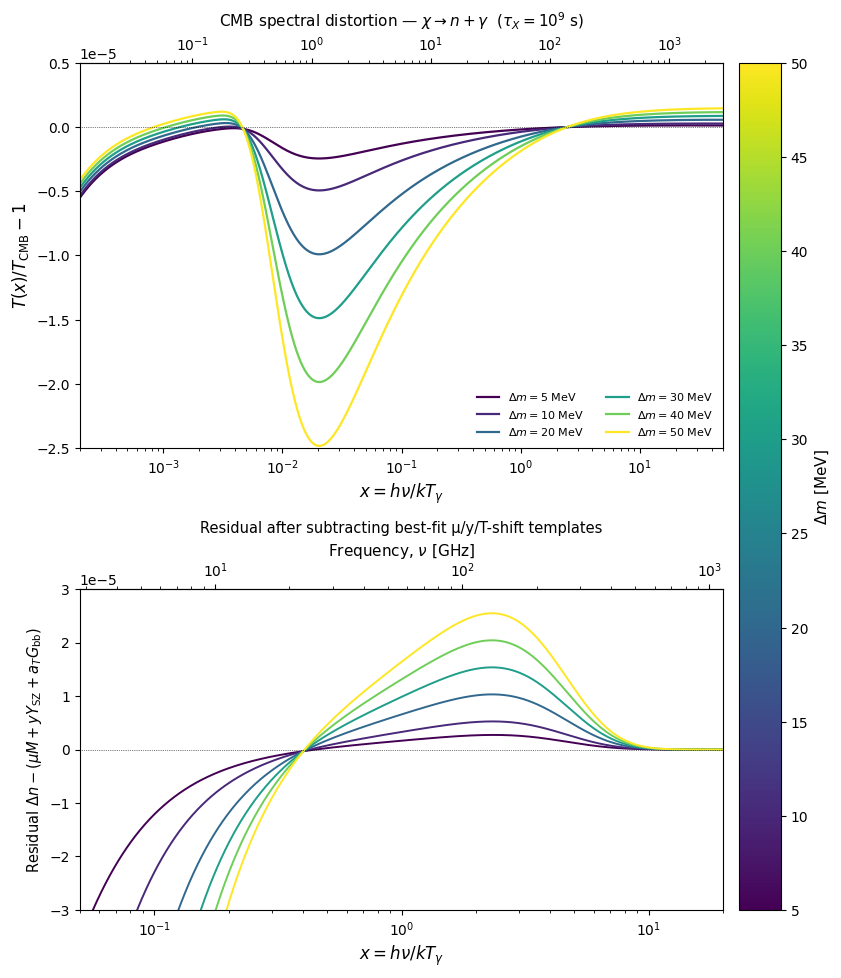

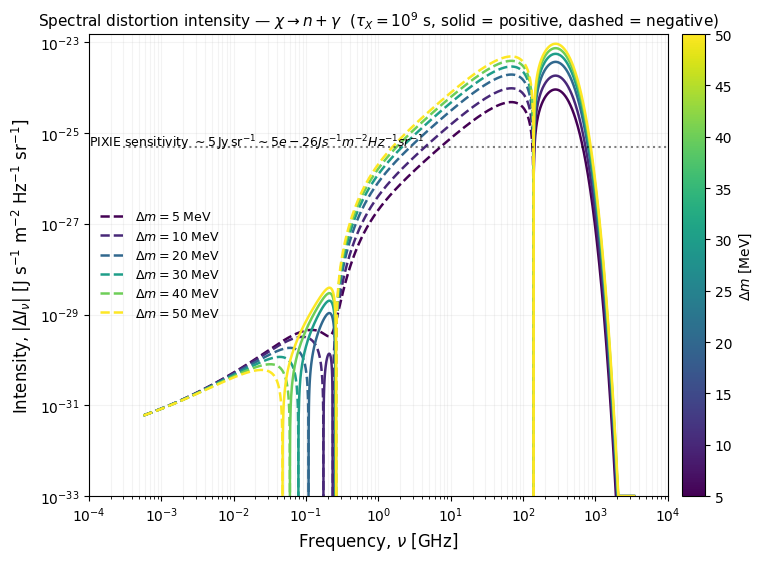

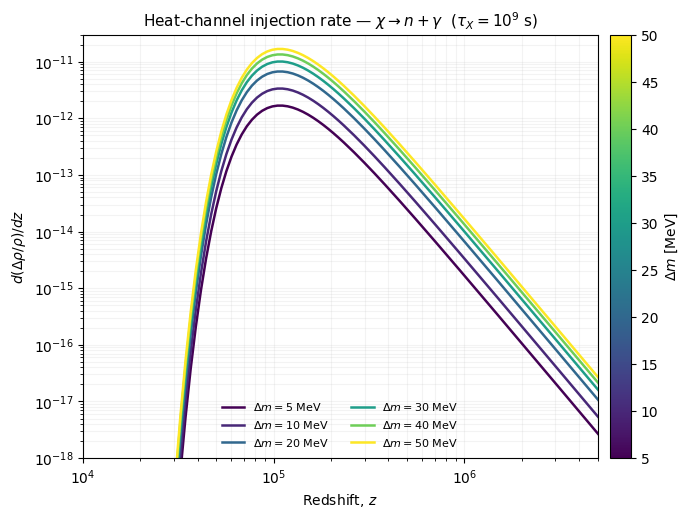

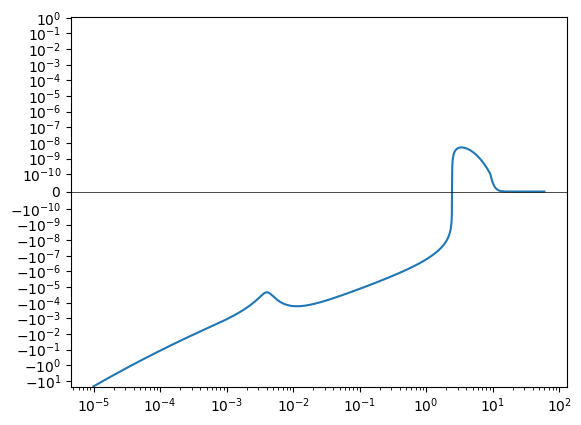

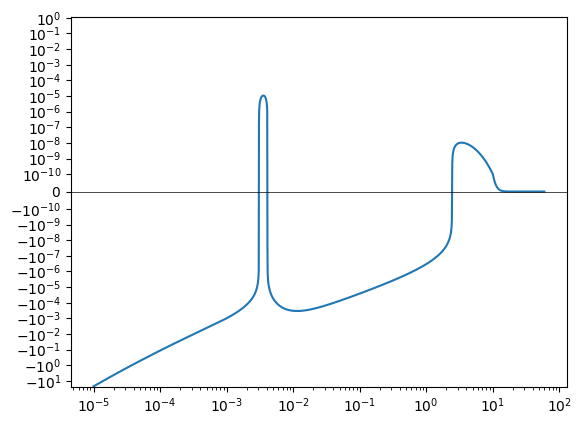

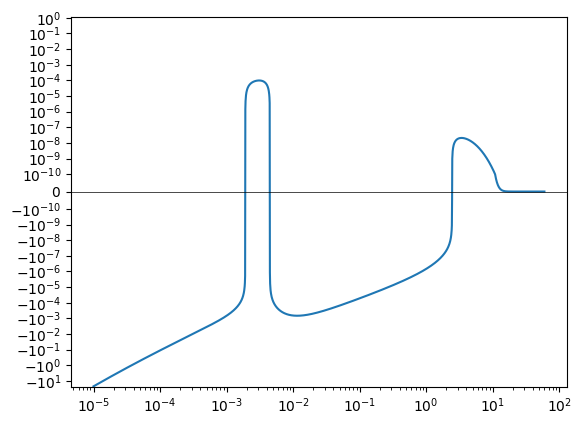

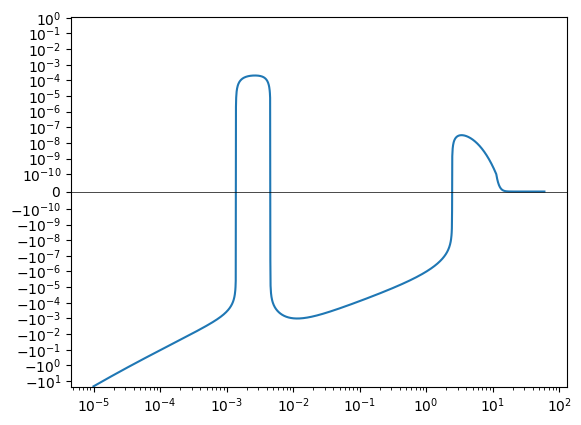

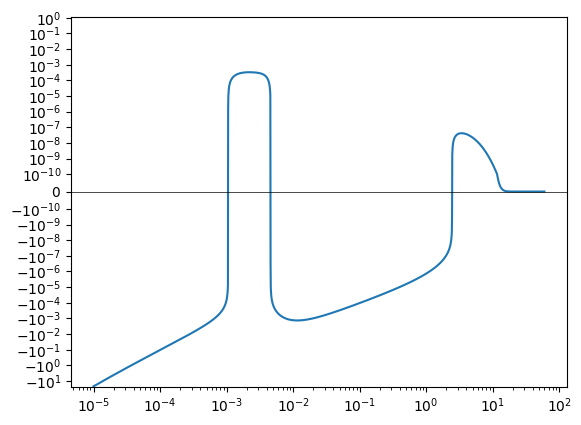

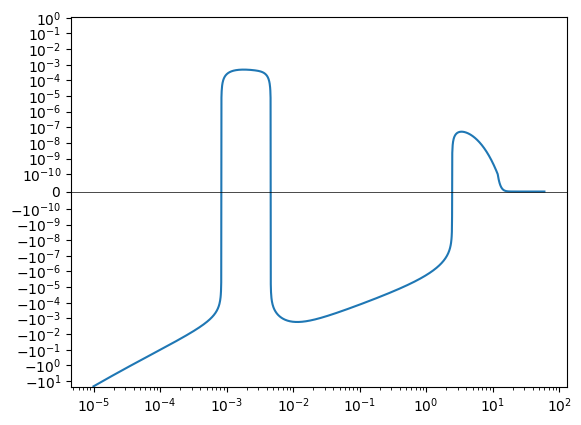


Photon case (χ → n + γ)   τ_X = 1e+09 s   n_X,0/n_H,0 = 0.01

+-----------+-------------+-------------+-------------+-------------+---------------+---------------+---------------+-------------+
| Δm [MeV]  |  F_X [eV]   |  T_n [keV]  |      μ      |      y      |  a_μ (resid)  |  a_y (resid)  |  a_T (resid)  |  resid RMS  |
+-----------+-------------+-------------+-------------+-------------+---------------+---------------+---------------+-------------+
|         5 |   5.000e+04 |     13.2336 |   2.328e-07 |   4.636e-08 |     7.117e-10 |    -1.171e-05 |    -2.348e-05 |   6.761e-06 |
|        10 |   1.000e+05 |     52.6557 |   4.679e-07 |   9.365e-08 |     3.660e-10 |    -2.238e-05 |    -4.503e-05 |   1.299e-05 |
|        20 |   2.000e+05 |    208.4277 |   9.380e-07 |   1.882e-07 |    -3.254e-10 |    -4.371e-05 |    -8.813e-05 |   2.547e-05 |
|        30 |   3.000e+05 |    464.1255 |   1.408e-06 |   2.828e-07 |    -1.017e-09 |    -6.504e-05 |    -1.312e-04 |   3.794e-05 |
|        40 |

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import pandas as pd
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from scipy.integrate import quad
from spectroxide.solver import solve

# ── save location ───────────────────────────────────────────────────────────
SAVE_DIR  = "spectroxide/RUNS"
SAVE_FILE = "sweep_deltam_photon_tau1e9"
save_path = Path(SAVE_DIR)
save_path.mkdir(parents=True, exist_ok=True)
npz_file  = save_path / f"{SAVE_FILE}.npz"

# ── physical constants (SI) ───────────────────────────────────────────────
h_PLANCK = 6.62607015e-34     # J s
k_B      = 1.380649e-23       # J/K
c_LIGHT  = 2.99792458e8       # m/s
T_CMB0   = 2.7255             # K, present-day CMB temperature

def x_to_freq_GHz(x):
    """x = h*nu / (k_B*T_CMB) -> nu in GHz"""
    nu_Hz = x * k_B * T_CMB0 / h_PLANCK
    return nu_Hz / 1e9

def delta_n_to_intensity(x, delta_n):
    """
    Standard relation between photon occupation number and specific
    intensity:  I_nu = (2 h nu^3 / c^2) * n(x).
    A perturbation delta_n in occupation number therefore maps directly to
    an intensity perturbation via the same prefactor (linear in n).
    Returns |Delta I_nu| in J s^-1 m^-2 Hz^-1 sr^-1 (an SED, so we plot the
    magnitude on a log axis, same convention as the reference plot).
    """
    nu_Hz = x * k_B * T_CMB0 / h_PLANCK
    prefac = 2.0 * h_PLANCK * nu_Hz**3 / c_LIGHT**2
    return prefac * delta_n

# ── physical parameters ──────────────────────────────────────────────────────
tau_X   = 1e9                 # [s]
GAMMA_X = 1.0 / tau_X
den_fac = 0.01                 # n_X,0/n_H,0 (McKeen 2021 benchmark)

M_N_EV = 939.565379e6          # neutron mass [eV]

DELTA_M_MEV = [5, 10, 20, 30, 40, 50]          # sweep grid [MeV]
DELTA_M_EV  = np.array(DELTA_M_MEV) * 1e6       # [eV]

# ── analytic templates (occupation-number convention) ────────────────────────
def G(x):
    return x * np.exp(x) / (np.exp(x) - 1)**2

def Ysz(x):
    return G(x) * (x / np.tanh(x / 2) - 4)

def tempshift(x):
    return G(x)

def mudist(x):
    return 1.401 * G(x) * (0.4561 - 1 / x)

def brightness_temp_exact(x, delta_n):
    xc  = np.clip(np.asarray(x, dtype=float), 1e-12, None)
    n0  = 1.0 / np.expm1(np.clip(xc, None, 500.0))
    n_x = n0 + delta_n
    return xc / np.log1p(1.0 / n_x) - 1.0

def fit_mu_y_T(x, delta_n, x_lo=1e-3, x_hi=40.0):
    mask = (x > x_lo) & (x < x_hi) & np.isfinite(delta_n)
    A = np.vstack([mudist(x[mask]), Ysz(x[mask]), tempshift(x[mask])]).T
    b = delta_n[mask]
    coeffs, *_ = np.linalg.lstsq(A, b, rcond=None)
    a_mu, a_y, a_T = coeffs
    model = a_mu * mudist(x) + a_y * Ysz(x) + a_T * tempshift(x)
    return delta_n - model, a_mu, a_y, a_T

def neutron_recoil_KE(delta_m_eV, m2_eV=0.0):
    """Exact two-body recoil KE of the neutron: E_n = (M^2+m_n^2-m2^2)/(2M)."""
    M = M_N_EV + delta_m_eV
    E_n = (M**2 + M_N_EV**2 - m2_eV**2) / (2 * M)
    return E_n - M_N_EV   # eV

# ── cosmology (Planck 2018-like), needed only for the analytic
#    d(Delta rho/rho)/dz heating-rate diagnostic below (Baker+2026 Eq. 9-13) ──
H0_KM_S_MPC       = 67.4
OMEGA_M           = 0.315
OMEGA_R           = 9.4e-5
OMEGA_L           = 1.0 - OMEGA_M - OMEGA_R
OMEGA_B_H2        = 0.0224
Y_P               = 0.245
RHO_GAMMA0_EV_CM3 = 0.2606        # CMB energy density today, eV/cm^3 (T0=2.7255K)
M_P_G             = 1.67262192369e-24   # proton mass, g
MPC_CM            = 3.0856775814913673e24
G_NEWTON_CGS      = 6.6743e-8

H0_S     = H0_KM_S_MPC * 1e5 / MPC_CM            # H0 in s^-1
h_little = H0_KM_S_MPC / 100.0
OMEGA_B  = OMEGA_B_H2 / h_little**2
RHO_CRIT0_G_CM3 = 3 * H0_S**2 / (8 * np.pi * G_NEWTON_CGS)
N_H0_CM3 = (1 - Y_P) * OMEGA_B * RHO_CRIT0_G_CM3 / M_P_G

def E_of_z(z):
    return np.sqrt(OMEGA_M * (1 + z)**3 + OMEGA_R * (1 + z)**4 + OMEGA_L)

def H_of_z(z):
    return H0_S * E_of_z(z)

def rho_gamma_of_z(z):
    return RHO_GAMMA0_EV_CM3 * (1 + z)**4

def n_H_of_z(z):
    return N_H0_CM3 * (1 + z)**3

def age_at_z(z):
    """Cosmic time (age of the universe) at redshift z, in seconds.

    Uses the substitution u = 1/(1+z'), which maps the original
    integral over z' in [z, inf) onto a finite interval u in [0, u_max].
    This avoids scipy's infinite-limit QAGI algorithm (and the
    associated IntegrationWarning about roundoff/slow convergence),
    since the integrand in u is smooth and →0 as u→0 (H(z') ~ (1+z')^2
    in radiation domination, so 1/(u*H) ~ u -> 0).
    """
    u_max = 1.0 / (1.0 + z)

    def integrand_u(u):
        if u <= 0.0:
            return 0.0
        zp = 1.0 / u - 1.0
        return 1.0 / (u * H_of_z(zp))

    val, _ = quad(integrand_u, 0.0, u_max, limit=200)
    return val

def heating_rate_decaying_particle(z_arr, f_x_eV, gamma_x_s):
    """
    d(Delta rho/rho)/dz for spectroxide's built-in 'decaying_particle'
    injection, per baker2026 Eq. 13:
        d(Delta rho/rho)/dz = f_X Gamma_X n_H(z) exp(-Gamma_X t(z))
                               / [H(z) rho_gamma(z) (1+z)]
    """
    z_arr = np.atleast_1d(np.asarray(z_arr, dtype=float))
    out = np.empty_like(z_arr)
    for i, zi in enumerate(z_arr):
        t_s = age_at_z(zi)
        out[i] = (f_x_eV * gamma_x_s * n_H_of_z(zi) * np.exp(-gamma_x_s * t_s)
                  / (H_of_z(zi) * rho_gamma_of_z(zi) * (1 + zi)))
    return out

Z_HEAT = np.logspace(-1, 7, 300)   # matches the sweep's own z_start=1e7 -> z_end=0 range

# ── signed log-log plotting helper ────────────────────────────────────────────
def plot_signed_loglog(ax, x, y, color, lw=1.8, label=None, floor=None):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    finite = np.isfinite(x) & np.isfinite(y)
    if not np.all(finite):
        print(f"  [plot_signed_loglog] '{label}': dropped "
              f"{np.sum(~finite)} non-finite point(s) before plotting")
    x, y = x[finite], y[finite]
    if len(x) < 2:
        print(f"  [plot_signed_loglog] '{label}': fewer than 2 finite points, skipping")
        return

    if floor is None:
        nonzero = np.abs(y[y != 0])
        floor = nonzero.min() * 1e-3 if nonzero.size else 1e-30

    def interp_zero(x0, y0, x1, y1):
        frac = y0 / (y0 - y1)
        return np.exp(np.log(x0) + frac * (np.log(x1) - np.log(x0)))

    def flush(seg_x, seg_y, sign_positive, first_label):
        if len(seg_x) >= 2:
            mag = np.clip(np.abs(np.array(seg_y)), floor, None)
            ls = '-' if sign_positive else '--'
            ax.plot(seg_x, mag, color=color, lw=lw, ls=ls,
                     label=(label if first_label else None))
            return False
        return first_label

    seg_x, seg_y = [x[0]], [y[0]]
    sign_positive = (y[0] >= 0)      # <- track sign explicitly, not from seg_y[0]
    first = True
    for i in range(len(x) - 1):
        x0, y0, x1, y1 = x[i], y[i], x[i + 1], y[i + 1]
        if (y0 >= 0) != (y1 >= 0) and y0 != y1:
            xz = interp_zero(x0, y0, x1, y1)
            seg_x.append(xz); seg_y.append(0.0)
            first = flush(seg_x, seg_y, sign_positive, first)
            sign_positive = (y1 >= 0)          # <- sign of the segment we're starting
            seg_x, seg_y = [xz, x1], [0.0, y1]
        else:
            seg_x.append(x1); seg_y.append(y1)
    flush(seg_x, seg_y, sign_positive, first)

# ── load cache (resume support) ──────────────────────────────────────────────
results = {}
if npz_file.exists():
    print(f"Found existing data at '{npz_file}', loading...")
    existing = np.load(npz_file, allow_pickle=True)
    loaded_keys = set(existing.files)
    for dm in DELTA_M_EV:
        kx, kdn, kmu, ky = (f"dm{dm:.6g}_{s}" for s in ("x", "delta_n", "mu", "y"))
        if all(k in loaded_keys for k in (kx, kdn, kmu, ky)):
            results[dm] = (existing[kx], existing[kdn], float(existing[kmu]), float(existing[ky]))
            print(f"  loaded Δm = {dm/1e6:.0f} MeV")

def save_results():
    flat = {"tau_X": np.array(tau_X), "den_fac": np.array(den_fac),
            "delta_m_ev": DELTA_M_EV}
    for dm, (x_arr, dn, mu_r, y_r) in results.items():
        flat[f"dm{dm:.6g}_x"]       = x_arr
        flat[f"dm{dm:.6g}_delta_n"] = dn
        flat[f"dm{dm:.6g}_mu"]      = np.array(mu_r)
        flat[f"dm{dm:.6g}_y"]       = np.array(y_r)
    np.savez(npz_file, **flat)
    print(f"  → saved to '{npz_file}'")

# ── run one Δm point (used by the parallel pool below) ───────────────────────
def run_one(dm):
    F_X = dm * den_fac   # full mass splitting -> heat
    r = solve(
        injection = {'type': 'decaying_particle', 'f_x': F_X, 'gamma_x': GAMMA_X},
        z_start           = 5.0e6,
        z_end             = 5.0e2,
        x_min             = 1.5e-4,
        x_max             = 80.0,
        n_x               = 1000,
        method            = 'pde',
        production_grid   = True,
        number_conserving = True,
        timeout           = 3600,
        dtau_max          = 5.0,
    )
    return dm, (r.x, r.delta_n, r.mu, r.y)

# ── run all missing Δm points at the same time ────────────────────────────────
to_run = [dm for dm in DELTA_M_EV if dm not in results]
if to_run:
    print(f"Launching {len(to_run)} runs in parallel ...")
    with ThreadPoolExecutor(max_workers=min(len(to_run), 10)) as ex:
        futures = {ex.submit(run_one, dm): dm for dm in to_run}
        for fut in as_completed(futures):
            dm = futures[fut]
            try:
                dm_done, payload = fut.result()
                results[dm_done] = payload
                print(f"  Δm = {dm_done/1e6:.0f} MeV ... done")
            except Exception as e:
                print(f"  Δm = {dm/1e6:.0f} MeV ... FAILED: {e}")
    save_results()
else:
    print("All Δm points already cached.")

# ── colour gradient over Δm ───────────────────────────────────────────────────
cmap = plt.cm.viridis
norm = mcolors.Normalize(vmin=min(DELTA_M_MEV), vmax=max(DELTA_M_MEV))
sm   = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# ── plot: spectrum (top) + residual (bottom) ─────────────────────────────────
fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(10, 11), gridspec_kw={"height_ratios": [1.2, 1], "hspace": 0.4}
)

fig, ax = plt.subplots(figsize=(9, 6))

table_rows = []
for dm_mev, dm in zip(DELTA_M_MEV, DELTA_M_EV):
    x_arr, dn, mu_r, y_r = results[dm]
    c = cmap(norm(dm_mev))

    dT = brightness_temp_exact(x_arr, dn)
    ax_top.semilogx(x_arr, dT, color=c, lw=1.6, label=fr'$\Delta m={dm_mev}$ MeV')

    resid, a_mu, a_y, a_T = fit_mu_y_T(x_arr, dn)
    mask_plot = (x_arr > 0.05) & (x_arr < 20)
    ax_bot.semilogx(x_arr[mask_plot], resid[mask_plot], color=c, lw=1.4)

    T_n_eV = neutron_recoil_KE(dm)
    table_rows.append(dict(
        delta_m_MeV = dm_mev,
        F_X_eV      = dm * den_fac,
        T_n_keV     = T_n_eV / 1e3,
        mu          = mu_r,
        y           = y_r,
        a_mu_resid  = a_mu,
        a_y_resid   = a_y,
        a_T_resid   = a_T,
        resid_rms   = np.sqrt(np.mean(resid[mask_plot]**2)),
    ))

ax_top.axhline(0, color='k', lw=0.5, ls=':')
ax_top.set_xlim(2e-4, 50)
ax_top.set_ylim(-25e-6, 5e-6)
ax_top.set_xlabel(r'$x = h\nu / kT_{\gamma}$', fontsize=12)
ax_top.set_ylabel(r'$T(x)/T_{\rm CMB} - 1$', fontsize=12)
ax_top.set_title(r'CMB spectral distortion — $\chi \to n + \gamma$  ($\tau_X=10^9$ s)', fontsize=11)
ax_top.legend(fontsize=8, frameon=False, loc='lower right', ncol=2)

ax_bot.axhline(0, color='k', lw=0.5, ls=':')
ax_bot.set_xlim(0.05, 20)
ax_bot.set_ylim(-30e-6, 30e-6)
ax_bot.set_xlabel(r'$x = h\nu / kT_{\gamma}$', fontsize=12)
ax_bot.set_ylabel(r'Residual $\Delta n - (\mu M + y Y_{\rm SZ} + a_T G_{\rm bb})$', fontsize=10.5)
ax_bot.set_title('Residual after subtracting best-fit µ/y/T-shift templates', fontsize=10.5)

def x_to_GHz(x):
    return x_to_freq_GHz(x)          # already defined earlier in each script

def GHz_to_x(nu_GHz):
    nu_Hz = nu_GHz * 1e9
    return nu_Hz * h_PLANCK / (k_B * T_CMB0)

secax = ax_top.secondary_xaxis('top', functions=(x_to_GHz, GHz_to_x))
secax = ax_bot.secondary_xaxis('top', functions=(x_to_GHz, GHz_to_x))
secax.set_xlabel(r'Frequency, $\nu$ [GHz]', fontsize=11)

cbar = fig.colorbar(sm, ax=[ax_top, ax_bot], pad=0.02)
cbar.set_label(r'$\Delta m$ [MeV]', fontsize=11)

# ── intensity plot (uses the fixed signed log-log plotter) ───────────────────
for dm_mev, dm in zip(DELTA_M_MEV, DELTA_M_EV):
    x_arr, delta_n, mu_r, y_r = results[dm]     # <- your existing results dict

    nu_GHz  = x_to_freq_GHz(x_arr)
    I_nu    = delta_n_to_intensity(x_arr, delta_n)

    c = cmap(norm(dm_mev))
    # Correctly handles however many times I_nu changes sign: each solid/dashed
    # segment is terminated at the true interpolated zero crossing instead of a
    # straight chord jumping across it (see plot_signed_loglog docstring above).
    plot_signed_loglog(ax, nu_GHz, I_nu, color=c, lw=1.8,
                        label=fr'$\Delta m={dm_mev}$ MeV', floor=1e-33)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(1e-4, 1e4)
ax.set_ylim(1e-33, 1.5e-23)
xlim = ax.get_xlim()
pixie_sens = 5e-26   # J s^-1 m^-2 Hz^-1 sr^-1  (Kogut et al. 2011, ~5 Jy/sr)
ax.plot([3e-4, xlim[1]], [pixie_sens, pixie_sens], color='black', lw=1.5, ls=':', alpha=0.5)
ax.annotate(fr'PIXIE sensitivity $\sim5\,\mathrm{{Jy\,sr^{{-1}}}} \sim {pixie_sens} J s^{{-1}} m^{{-2}} Hz^{{-1}} sr^{{-1}}$',
            xy=(3e-2, pixie_sens),
            xytext=(1e-4, pixie_sens),
            fontsize=9, color='black')
ax.set_xlabel(r'Frequency, $\nu$ [GHz]', fontsize=12)
ax.set_ylabel(r'Intensity, $|\Delta I_\nu|$ [J s$^{-1}$ m$^{-2}$ Hz$^{-1}$ sr$^{-1}$]', fontsize=12)
ax.set_title(r'Spectral distortion intensity — $\chi \to n + \gamma$'
             r'  ($\tau_X=10^9$ s, solid = positive, dashed = negative)', fontsize=11)
ax.legend(fontsize=9, frameon=False, loc='best')
ax.grid(True, which='both', alpha=0.15)

fig.colorbar(sm, ax=ax, pad=0.02, label=r'$\Delta m$ [MeV]')

# ── heating rate d(Δρ/ρ)/dz vs z ──
fig_heat, ax_heat = plt.subplots(figsize=(8, 5.5))
for dm_mev, dm in zip(DELTA_M_MEV, DELTA_M_EV):
    F_X = dm * den_fac
    heat_rate = heating_rate_decaying_particle(Z_HEAT, F_X, GAMMA_X)
    c = cmap(norm(dm_mev))
    ax_heat.loglog(Z_HEAT, heat_rate, color=c, lw=1.8, label=fr'$\Delta m={dm_mev}$ MeV')

ax_heat.set_xlabel(r'Redshift, $z$')
ax_heat.set_ylabel(r'$d(\Delta\rho/\rho)/dz$')
ax_heat.set_xlim(1e4, 5e6)
ax_heat.set_ylim(1e-18, 3e-11)
ax_heat.set_title(r'Heat-channel injection rate — $\chi \to n + \gamma$  ($\tau_X=10^9$ s)', fontsize=11)
ax_heat.legend(fontsize=8, frameon=False, ncol=2)
ax_heat.grid(True, which='both', alpha=0.15)
fig_heat.colorbar(sm, ax=ax_heat, pad=0.02, label=r'$\Delta m$ [MeV]')

for i in range(len(DELTA_M_MEV)):
    x_arr_check, dn_check = results[DELTA_M_EV[i]][:2]  # pick one Δm for the check plot
    fig, ax = plt.subplots()
    ax.plot(x_arr_check, dn_check)  # no abs(), no masking
    ax.set_xscale('log')
    ax.set_yscale('symlog', linthresh=1e-10)
    ax.axhline(0, color='k', lw=0.5)

plt.show()

# ── summary table ─────────────────────────────────────────────────────────────
def print_table(rows, columns):
    """columns: list of (key, header, fmt, width)"""
    sep = "+" + "+".join("-" * (w + 2) for _, _, _, w in columns) + "+"
    header = "| " + " | ".join(f"{h:^{w}}" for _, h, _, w in columns) + " |"
    print(sep)
    print(header)
    print(sep)
    for row in rows:
        line = "| " + " | ".join(
            f"{format(row[k], fmt):>{w}}" for k, h, fmt, w in columns
        ) + " |"
        print(line)
    print(sep)

columns = [
    ("delta_m_MeV", "Δm [MeV]",      ".0f",  9),
    ("F_X_eV",      "F_X [eV]",      ".3e", 11),
    ("T_n_keV",     "T_n [keV]",     ".4f", 11),
    ("mu",          "μ",             ".3e", 11),
    ("y",           "y",             ".3e", 11),
    ("a_mu_resid",  "a_μ (resid)",   ".3e", 13),
    ("a_y_resid",   "a_y (resid)",   ".3e", 13),
    ("a_T_resid",   "a_T (resid)",   ".3e", 13),
    ("resid_rms",   "resid RMS",     ".3e", 11),
]

print(f"\nPhoton case (χ → n + γ)   τ_X = {tau_X:.0e} s   n_X,0/n_H,0 = {den_fac}\n")
print_table(table_rows, columns)

### $\chi \rightarrow n + \gamma$ : `Cascades + spectroxide`

'/home/batman/Documents/Work/CMBSD/spectroxide/RUNS/sweep_deltam_photon_corrected_tau1e9.npz' already complete — skipping the sweep, loading directly.
loaded 6/6 Δm points from sweep_deltam_photon_corrected_tau1e9.npz, tau_X=1.0e+09, den_fac=0.01


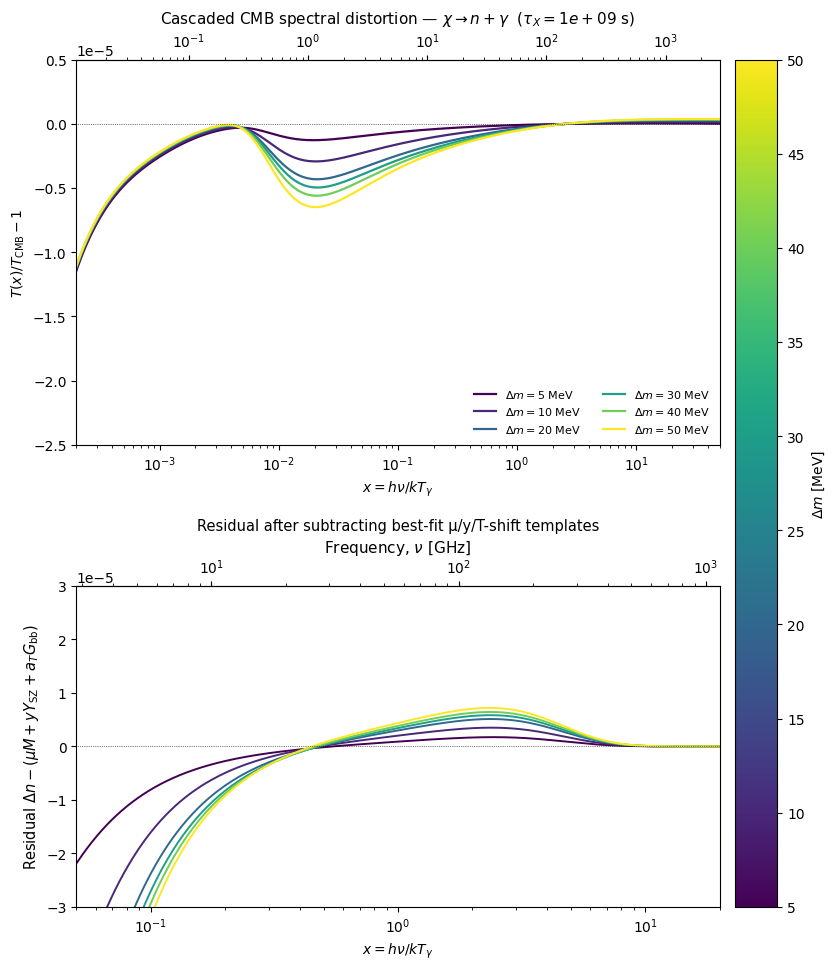

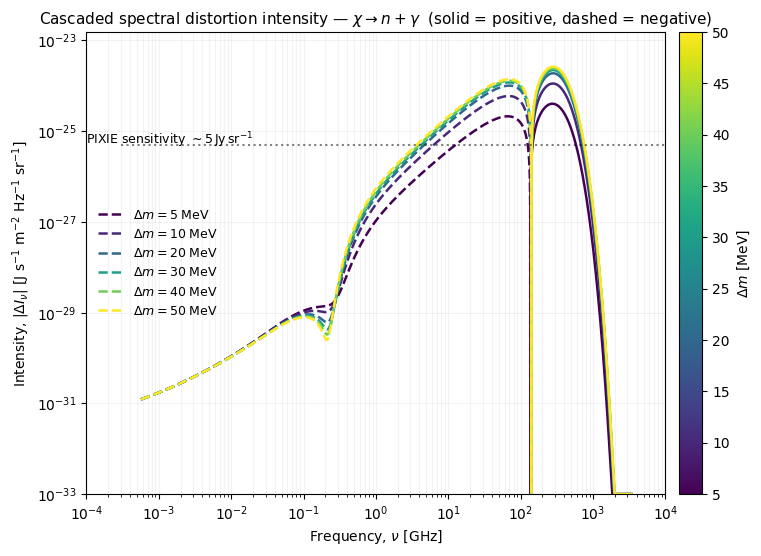

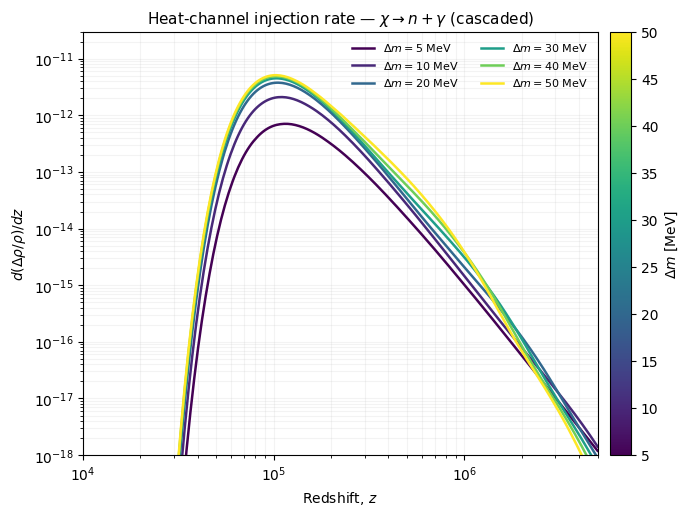

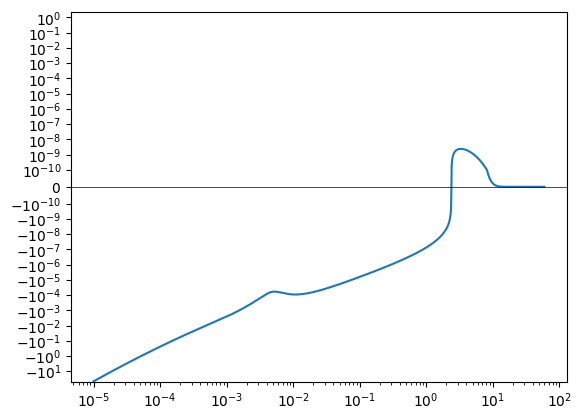

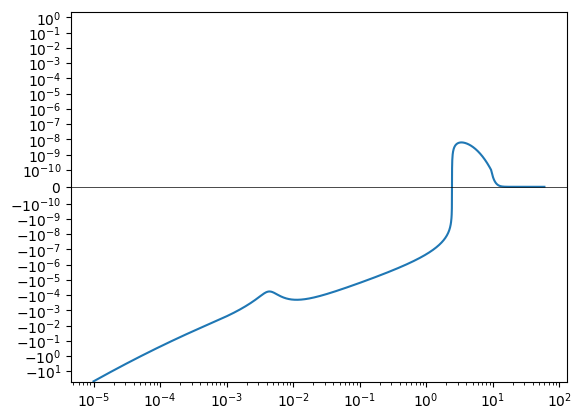

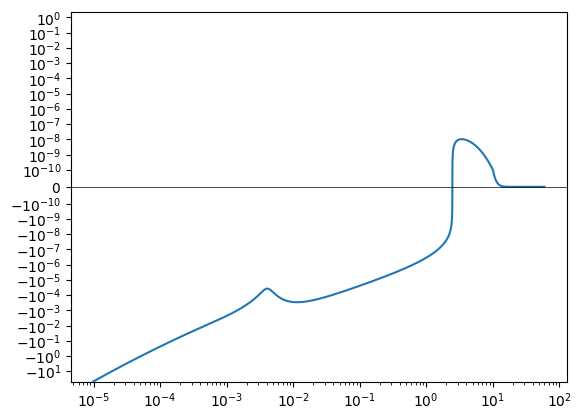

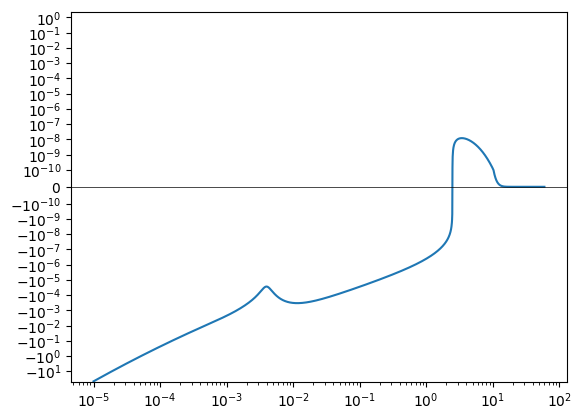

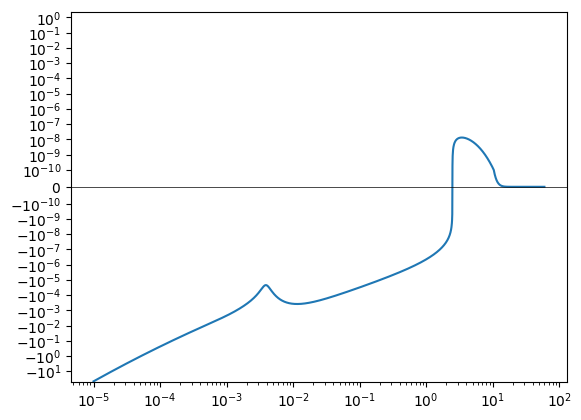

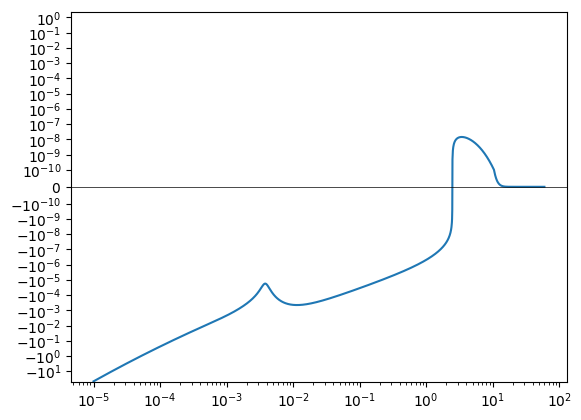


Cascaded photon case (χ → n + γ)   τ_X = 1e+09 s   n_X,0/n_H,0 = 0.01

+-----------+-------------+-------------+-------------+-------------+---------------+---------------+---------------+-------------+
| Δm [MeV]  |  n_X0/n_H0  |  T_n [keV]  |      μ      |      y      |  a_μ (resid)  |  a_y (resid)  |  a_T (resid)  |  resid RMS  |
+-----------+-------------+-------------+-------------+-------------+---------------+---------------+---------------+-------------+
|         5 |   1.000e-02 |     13.2336 |   1.103e-07 |   1.791e-08 |     1.962e-09 |    -7.718e-06 |    -1.522e-05 |   4.279e-06 |
|        10 |   1.000e-02 |     52.6557 |   2.863e-07 |   5.714e-08 |     1.732e-09 |    -1.524e-05 |    -3.039e-05 |   8.750e-06 |
|        20 |   1.000e-02 |    208.4278 |   4.599e-07 |   1.046e-07 |     1.540e-09 |    -2.215e-05 |    -4.429e-05 |   1.292e-05 |
|        30 |   1.000e-02 |    464.1257 |   5.337e-07 |   1.254e-07 |     1.449e-09 |    -2.520e-05 |    -5.044e-05 |   1.473e-05 |
|   

In [3]:
from pathlib import Path
import subprocess, sys, os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# ── config ────────────────────────────────────────────────────────────────
NPZ_NAME     = "sweep_deltam_photon_corrected_tau1e9.npz"
SWEEP_SCRIPT = "sweep_deltam_photon_corrected.py"

ROOT         = Path.cwd()                       # notebook's own folder (outside Cascades/spectroxide)
CASCADES_DIR = ROOT / "Cascades"
RUNS_DIR     = ROOT / "spectroxide" / "RUNS"
npz_file     = RUNS_DIR / NPZ_NAME

DELTA_M_EV_EXPECTED = np.array([5, 10, 20, 30, 40, 50]) * 1e6  # matches the sweep script's own grid
REQUIRED_SUFFIXES   = ("x", "delta_n", "mu", "y", "Tn", "z_heat", "heat_rate")

def npz_is_complete(path):
    """True only if every Δm point has every field the plots below need."""
    if not path.exists():
        return False
    existing = np.load(path, allow_pickle=True)
    keys = set(existing.files)
    for dm in DELTA_M_EV_EXPECTED:
        needed = (f"dm{dm:.6g}_{s}" for s in REQUIRED_SUFFIXES)
        if not all(k in keys for k in needed):
            return False
    return True

# ── run the sweep (from inside Cascades) only if something's missing ──────
if not npz_is_complete(npz_file):
    print(f"'{npz_file}' missing or incomplete — running the sweep from Cascades/ ...")
    assert CASCADES_DIR.exists(), f"missing {CASCADES_DIR}"
    assert (CASCADES_DIR / SWEEP_SCRIPT).exists(), f"{SWEEP_SCRIPT} not found in Cascades/"

    env = os.environ.copy()
    env["MPLBACKEND"] = "Agg"   # headless: script's own plt.show() won't block the subprocess

    proc = subprocess.run(
        [sys.executable, SWEEP_SCRIPT],
        cwd=CASCADES_DIR,       # <- makes the script's own "../spectroxide/RUNS" land at ROOT/spectroxide/RUNS
        env=env,
        capture_output=True,
        text=True,
    )
    print(proc.stdout)
    if proc.returncode != 0:
        print(proc.stderr)
        raise RuntimeError(f"{SWEEP_SCRIPT} exited with code {proc.returncode}")

    if not npz_is_complete(npz_file):
        raise RuntimeError(
            f"sweep ran but '{npz_file}' is still incomplete — check the script's own "
            "output above for per-Δm FAILED lines."
        )
else:
    print(f"'{npz_file}' already complete — skipping the sweep, loading directly.")

# ── load ────────────────────────────────────────────────────────────────────
data = np.load(npz_file, allow_pickle=True)

DELTA_M_EV = data["delta_m_ev"]
tau_X      = float(data["tau_X"])
den_fac    = float(data["den_fac"])

results = {}
for dm in DELTA_M_EV:
    kx, kdn, kmu, ky, kTn, kzh, khr = (
        f"dm{dm:.6g}_{s}" for s in REQUIRED_SUFFIXES
    )
    if all(k in data.files for k in (kx, kdn, kmu, ky, kTn, kzh, khr)):
        results[dm] = (data[kx], data[kdn], float(data[kmu]),
                        float(data[ky]), float(data[kTn]),
                        data[kzh], data[khr])

print(f"loaded {len(results)}/{len(DELTA_M_EV)} Δm points from {npz_file.name}, "
      f"tau_X={tau_X:.1e}, den_fac={den_fac}")

# ── analytic templates + helpers, same as sweep_deltam_mckeen_corrected.py ──
h_PLANCK, k_B, c_LIGHT, T_CMB0 = 6.62607015e-34, 1.380649e-23, 2.99792458e8, 2.7255

def x_to_freq_GHz(x):
    return x * k_B * T_CMB0 / h_PLANCK / 1e9

def delta_n_to_intensity(x, delta_n):
    nu_Hz = x * k_B * T_CMB0 / h_PLANCK
    return 2.0 * h_PLANCK * nu_Hz**3 / c_LIGHT**2 * delta_n

def G(x): return x * np.exp(x) / (np.exp(x) - 1)**2
def Ysz(x): return G(x) * (x / np.tanh(x / 2) - 4)
def tempshift(x): return G(x)
def mudist(x): return 1.401 * G(x) * (0.4561 - 1 / x)

def brightness_temp_exact(x, delta_n):
    xc = np.clip(np.asarray(x, dtype=float), 1e-12, None)
    n0 = 1.0 / np.expm1(np.clip(xc, None, 500.0))
    return xc / np.log1p(1.0 / (n0 + delta_n)) - 1.0

def fit_mu_y_T(x, delta_n, x_lo=1e-3, x_hi=40.0):
    mask = (x > x_lo) & (x < x_hi) & np.isfinite(delta_n)
    A = np.vstack([mudist(x[mask]), Ysz(x[mask]), tempshift(x[mask])]).T
    coeffs, *_ = np.linalg.lstsq(A, delta_n[mask], rcond=None)
    a_mu, a_y, a_T = coeffs
    model = a_mu * mudist(x) + a_y * Ysz(x) + a_T * tempshift(x)
    return delta_n - model, a_mu, a_y, a_T

# ── signed log-log plotting helper (NEW: ported from the other sweep scripts) ─
def plot_signed_loglog(ax, x, y, color, lw=1.8, label=None, floor=None):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    finite = np.isfinite(x) & np.isfinite(y)
    if not np.all(finite):
        print(f"  [plot_signed_loglog] '{label}': dropped "
              f"{np.sum(~finite)} non-finite point(s) before plotting")
    x, y = x[finite], y[finite]
    if len(x) < 2:
        print(f"  [plot_signed_loglog] '{label}': fewer than 2 finite points, skipping")
        return

    if floor is None:
        nonzero = np.abs(y[y != 0])
        floor = nonzero.min() * 1e-3 if nonzero.size else 1e-30

    def interp_zero(x0, y0, x1, y1):
        frac = y0 / (y0 - y1)
        return np.exp(np.log(x0) + frac * (np.log(x1) - np.log(x0)))

    def flush(seg_x, seg_y, sign_positive, first_label):
        if len(seg_x) >= 2:
            mag = np.clip(np.abs(np.array(seg_y)), floor, None)
            ls = '-' if sign_positive else '--'
            ax.plot(seg_x, mag, color=color, lw=lw, ls=ls,
                     label=(label if first_label else None))
            return False
        return first_label

    seg_x, seg_y = [x[0]], [y[0]]
    sign_positive = (y[0] >= 0)      # <- track sign explicitly, not from seg_y[0]
    first = True
    for i in range(len(x) - 1):
        x0, y0, x1, y1 = x[i], y[i], x[i + 1], y[i + 1]
        if (y0 >= 0) != (y1 >= 0) and y0 != y1:
            xz = interp_zero(x0, y0, x1, y1)
            seg_x.append(xz); seg_y.append(0.0)
            first = flush(seg_x, seg_y, sign_positive, first)
            sign_positive = (y1 >= 0)          # <- sign of the segment we're starting
            seg_x, seg_y = [xz, x1], [0.0, y1]
        else:
            seg_x.append(x1); seg_y.append(y1)
    flush(seg_x, seg_y, sign_positive, first)

DELTA_M_MEV = [round(dm / 1e6) for dm in DELTA_M_EV if dm in results]

# ── two-panel spectrum + residual plot ──
cmap = plt.cm.viridis
norm = mcolors.Normalize(vmin=min(DELTA_M_MEV), vmax=max(DELTA_M_MEV))
sm   = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(10, 11), gridspec_kw={"height_ratios": [1.2, 1], "hspace": 0.4}
)
fig_sed, ax = plt.subplots(figsize=(9, 6))

table_rows = []
for dm_mev, dm in zip(DELTA_M_MEV, [d for d in DELTA_M_EV if d in results]):
    x_arr, dn, mu_r, y_r, Tn_eV, z_heat, heat_rate = results[dm]
    c = cmap(norm(dm_mev))

    dT = brightness_temp_exact(x_arr, dn)
    ax_top.semilogx(x_arr, dT, color=c, lw=1.6, label=fr'$\Delta m={dm_mev}$ MeV')

    resid, a_mu, a_y, a_T = fit_mu_y_T(x_arr, dn)
    mask_plot = (x_arr > 0.05) & (x_arr < 20)
    ax_bot.semilogx(x_arr[mask_plot], resid[mask_plot], color=c, lw=1.4)

    table_rows.append(dict(
        delta_m_MeV=dm_mev, den_fac=den_fac, T_n_keV=Tn_eV / 1e3,
        mu=mu_r, y=y_r, a_mu_resid=a_mu, a_y_resid=a_y, a_T_resid=a_T,
        resid_rms=np.sqrt(np.mean(resid[mask_plot]**2)),
    ))

    nu_GHz = x_to_freq_GHz(x_arr)
    I_nu = delta_n_to_intensity(x_arr, dn)
    # NEW: use the signed log-log plotter so every zero crossing in I_nu is
    # handled via true interpolation instead of a raw pos/neg sample split.
    plot_signed_loglog(ax, nu_GHz, I_nu, color=c, lw=1.8,
                        label=fr'$\Delta m={dm_mev}$ MeV', floor=1e-33)

ax_top.axhline(0, color='k', lw=0.5, ls=':')
ax_top.set_xlim(2e-4, 50); ax_top.set_ylim(-2.5e-5, 0.5e-5)
ax_top.set_xlabel(r'$x = h\nu / kT_{\gamma}$'); ax_top.set_ylabel(r'$T(x)/T_{\rm CMB} - 1$')
ax_top.set_title(r'Cascaded CMB spectral distortion — $\chi \to n + \gamma$  '
                  fr'($\tau_X={tau_X:.0e}$ s)', fontsize=11)
ax_top.legend(fontsize=8, frameon=False, loc='lower right', ncol=2)

ax_bot.axhline(0, color='k', lw=0.5, ls=':')
ax_bot.set_xlim(0.05, 20); ax_bot.set_ylim(-3e-5, 3e-5)
ax_bot.set_xlabel(r'$x = h\nu / kT_{\gamma}$')
ax_bot.set_ylabel(r'Residual $\Delta n - (\mu M + y Y_{\rm SZ} + a_T G_{\rm bb})$', fontsize=10.5)
ax_bot.set_title('Residual after subtracting best-fit µ/y/T-shift templates', fontsize=10.5)

def x_to_GHz(x):
    return x_to_freq_GHz(x)          # already defined earlier in each script

def GHz_to_x(nu_GHz):
    nu_Hz = nu_GHz * 1e9
    return nu_Hz * h_PLANCK / (k_B * T_CMB0)

secax = ax_top.secondary_xaxis('top', functions=(x_to_GHz, GHz_to_x))
secax = ax_bot.secondary_xaxis('top', functions=(x_to_GHz, GHz_to_x))
secax.set_xlabel(r'Frequency, $\nu$ [GHz]', fontsize=11)

fig.colorbar(sm, ax=[ax_top, ax_bot], pad=0.02, label=r'$\Delta m$ [MeV]')

ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlim(1e-4, 1e4); ax.set_ylim(1e-33, 1.5e-23)
xlim = ax.get_xlim()
pixie_sens = 5e-26
ax.plot([3e-4, xlim[1]], [pixie_sens, pixie_sens], color='black', lw=1.5, ls=':', alpha=0.5)
ax.annotate(r'PIXIE sensitivity $\sim5\,\mathrm{Jy\,sr^{-1}}$',
            xy=(3e-2, pixie_sens), xytext=(1e-4, pixie_sens), fontsize=9, color='black')
ax.set_xlabel(r'Frequency, $\nu$ [GHz]')
ax.set_ylabel(r'Intensity, $|\Delta I_\nu|$ [J s$^{-1}$ m$^{-2}$ Hz$^{-1}$ sr$^{-1}$]')
ax.set_title(r'Cascaded spectral distortion intensity — $\chi \to n + \gamma$'
             r'  (solid = positive, dashed = negative)', fontsize=11)
ax.legend(fontsize=9, frameon=False, loc='best')
ax.grid(True, which='both', alpha=0.15)
fig_sed.colorbar(sm, ax=ax, pad=0.02, label=r'$\Delta m$ [MeV]')

# ── heating rate d(Δρ/ρ)/dz vs z ──
fig_heat, ax_heat = plt.subplots(figsize=(8, 5.5))
for dm_mev, dm in zip(DELTA_M_MEV, [d for d in DELTA_M_EV if d in results]):
    _, _, _, _, _, z_heat, heat_rate = results[dm]
    c = cmap(norm(dm_mev))
    ax_heat.loglog(z_heat, heat_rate, color=c, lw=1.8, label=fr'$\Delta m={dm_mev}$ MeV')

ax_heat.set_xlabel(r'Redshift, $z$')
ax_heat.set_ylabel(r'$d(\Delta\rho/\rho)/dz$')
ax_heat.set_xlim(1e4, 5e6)
ax_heat.set_ylim(1e-18, 3e-11)
ax_heat.set_title(r'Heat-channel injection rate — $\chi \to n + \gamma$ (cascaded)', fontsize=11)
ax_heat.legend(fontsize=8, frameon=False, ncol=2)
ax_heat.grid(True, which='both', alpha=0.15)
fig_heat.colorbar(sm, ax=ax_heat, pad=0.02, label=r'$\Delta m$ [MeV]')

# ── per-Δm sanity check plots (NEW: added, loops over ALL Δm points) ────────
for dm in [d for d in DELTA_M_EV if d in results]:
    x_arr_check, dn_check = results[dm][0], results[dm][1]
    fig_chk, ax_chk = plt.subplots()
    ax_chk.plot(x_arr_check, dn_check)  # no abs(), no masking
    ax_chk.set_xscale('log')
    ax_chk.set_yscale('symlog', linthresh=1e-10)
    ax_chk.axhline(0, color='k', lw=0.5)

plt.show()

# ── summary table ──
def print_table(rows, columns):
    sep = "+" + "+".join("-" * (w + 2) for _, _, _, w in columns) + "+"
    header = "| " + " | ".join(f"{h:^{w}}" for _, h, _, w in columns) + " |"
    print(sep); print(header); print(sep)
    for row in rows:
        line = "| " + " | ".join(f"{format(row[k], fmt):>{w}}" for k, h, fmt, w in columns) + " |"
        print(line)
    print(sep)

columns = [
    ("delta_m_MeV", "Δm [MeV]",    ".0f",  9),
    ("den_fac",     "n_X0/n_H0",   ".3e", 11),
    ("T_n_keV",     "T_n [keV]",   ".4f", 11),
    ("mu",          "μ",           ".3e", 11),
    ("y",           "y",           ".3e", 11),
    ("a_mu_resid",  "a_μ (resid)", ".3e", 13),
    ("a_y_resid",   "a_y (resid)", ".3e", 13),
    ("a_T_resid",   "a_T (resid)", ".3e", 13),
    ("resid_rms",   "resid RMS",   ".3e", 11),
]

print(f"\nCascaded photon case (χ → n + γ)   τ_X = {tau_X:.0e} s   "
      f"n_X,0/n_H,0 = {den_fac}\n")
print_table(table_rows, columns)

### $\Lambda$ CDM spectral distortions: `CosmoTherm`

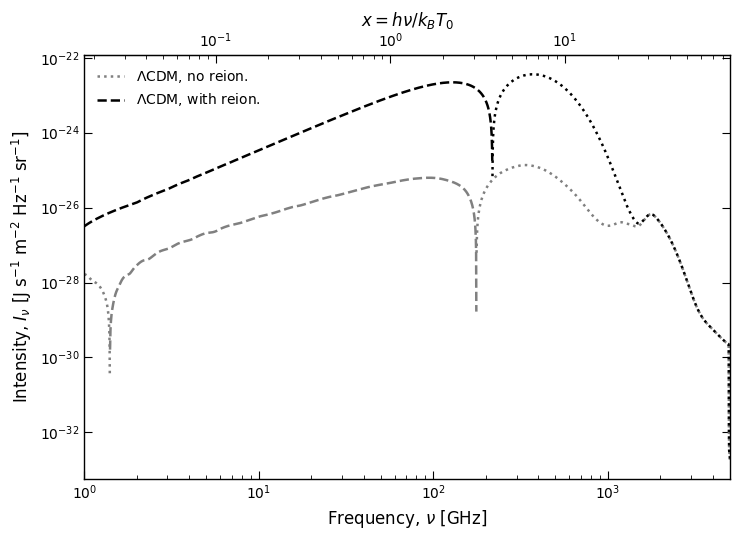

In [5]:
"""
Reproduces the black-dotted ("LCDM, with reionization") and grey-dotted
("LCDM, no reionization") curves from Fig. 2 (and Fig. 1) of Liu, Qin,
Ridgway & Slatyer 2023 (arXiv:2303.07370), using Jens Chluba's public
Green's-function data (originally computed for Chluba 2016, arXiv:1603.02496).

Grey  = CRR (recombination) + Silk damping (mu-type) + adiabatic cooling
Black = grey + late-time y-distortion (reionization) + its relativistic correction

Following the paper's convention: negative-value stretches are drawn dashed,
positive stretches dotted, in the same color.

A second x-axis on top shows x = h*nu / (k_B * T0), with T0 the CMB temperature today.
"""

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

def load_DI(fpath, fname):
    """Load a Chluba-format DI_*.dat file: columns are nu [GHz], DI [Jy/sr]."""
    nu, DI = np.loadtxt(fpath / fname, comments='#', unpack=True)
    return nu, DI

# --- paths to your data files ---
files = {
    'CRR':      'DI_CRR.dat',       # recombination
    'damping':  'DI_damping.dat',   # Silk damping (mu-type)
    'cooling':  'DI_cooling.dat',   # adiabatic cooling
    'y_late':   'DI_y_late.dat',    # late-time y-distortion (reionization)
    'rel_corr': 'DI_rel_corr.dat',  # relativistic correction to y_late
}

fpath = Path.cwd() / "spectroxide" / "data" / "cosmotherm"
data = {k: load_DI(fpath, v) for k, v in files.items()}

# Common grid: restrict to the frequency range covered by ALL files
# (y_late / rel_corr only start at 1 GHz) to avoid extrapolation.
nu_min = max(nu.min() for nu, _ in data.values())
nu_max = min(nu.max() for nu, _ in data.values())
nu_common = np.logspace(np.log10(nu_min), np.log10(nu_max), 3000)

interp = {k: np.interp(nu_common, nu, DI) for k, (nu, DI) in data.items()}

# Build the two curves (still in Jy/sr at this point)
grey_DI  = interp['CRR'] + interp['damping'] + interp['cooling']
black_DI = grey_DI + interp['y_late'] + interp['rel_corr']

# --- convert Jy/sr -> J s^-1 m^-2 Hz^-1 sr^-1 (the units used in the paper) ---
# 1 Jy = 1e-26 J s^-1 m^-2 Hz^-1
Jy_to_SI = 1e-26
grey_DI  *= Jy_to_SI
black_DI *= Jy_to_SI

# --- physical constants for the top x = h nu / kT0 axis ---
h_planck = 6.62607015e-34   # J s
kB       = 1.380649e-23     # J/K
T0       = 2.726            # K, CMB temperature today

def nu_to_x(nu_GHz):
    return h_planck * (nu_GHz * 1e9) / (kB * T0)

def x_to_nu(x):
    return x * kB * T0 / h_planck / 1e9


def plot_signed(ax, nu, DI, color, label):
    """Plot |DI|, using dotted line where DI>=0 and dashed where DI<0
    (matches the paper's convention of dashing negative distortion values)."""
    sign = np.sign(DI)
    change = np.where(np.diff(sign) != 0)[0]
    segments = np.split(np.arange(len(nu)), change + 1)
    first = True
    for seg in segments:
        if len(seg) < 2:
            continue
        s = sign[seg[0]] if sign[seg[0]] != 0 else sign[seg[-1]]
        ls = ':' if s >= 0 else '--'
        ax.plot(nu[seg], np.abs(DI[seg]), color=color, ls=ls, lw=1.8,
                 label=label if first else None)
        first = False


fig, ax = plt.subplots(figsize=(7.5, 5.5))

plot_signed(ax, nu_common, grey_DI,  'grey',  r'$\Lambda$CDM, no reion.')
plot_signed(ax, nu_common, black_DI, 'black', r'$\Lambda$CDM, with reion.')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(nu_common.min(), nu_common.max())
ax.set_xlabel(r'Frequency, $\nu$ [GHz]', fontsize=12)
ax.set_ylabel(r'Intensity, $I_\nu$ [J s$^{-1}$ m$^{-2}$ Hz$^{-1}$ sr$^{-1}$]', fontsize=12)

ax.tick_params(which='both', direction='in', top=False, right=True)
ax.tick_params(which='major', length=6)
ax.tick_params(which='minor', length=3)

# force legend handles to show as dotted lines (like the paper's legend)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, labels, frameon=False, fontsize=10, loc='upper left')

# secondary top x-axis: x = h nu / kB T0
secax = ax.secondary_xaxis('top', functions=(nu_to_x, x_to_nu))
secax.set_xlabel(r'$x = h\nu / k_B T_0$', fontsize=12)
secax.tick_params(which='both', direction='in')
secax.tick_params(which='major', length=6)
secax.tick_params(which='minor', length=3)

for spine in ax.spines.values():
    spine.set_linewidth(1.0)

plt.tight_layout()
plt.show()

### $\Lambda$ CDM spectral distortions: `DarkHistory`

### $\chi \rightarrow n + \gamma$ : `spectroxide` custom photon injection

Launching 6 runs in parallel ...
  Δm = 10 MeV ... FAILED: Rust solver failed (exit 101):
spectroxide: CMB spectral distortion solver

Injection: decaying-particle-photon

thread 'main' (18528) panicked at src/solver.rs:921:9:
NaN/Inf detected in delta_n at z=9999947.818401303
note: run with `RUST_BACKTRACE=1` environment variable to display a backtrace

  Δm = 5 MeV ... FAILED: Rust solver failed (exit 101):
spectroxide: CMB spectral distortion solver

Injection: decaying-particle-photon

thread 'main' (18526) panicked at src/solver.rs:921:9:
NaN/Inf detected in delta_n at z=9999947.818401303
note: run with `RUST_BACKTRACE=1` environment variable to display a backtrace

  Δm = 40 MeV ... FAILED: Rust solver failed (exit 101):
spectroxide: CMB spectral distortion solver

Injection: decaying-particle-photon

thread 'main' (18531) panicked at src/solver.rs:921:9:
NaN/Inf detected in delta_n at z=9999947.818401303
note: run with `RUST_BACKTRACE=1` environment variable to display a backtra

KeyError: np.float64(5000000.0)

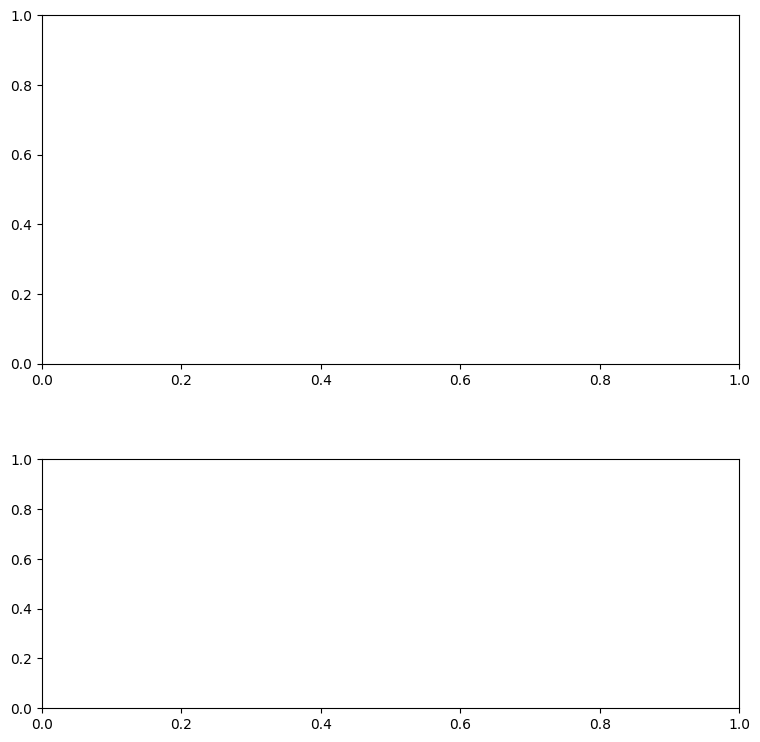

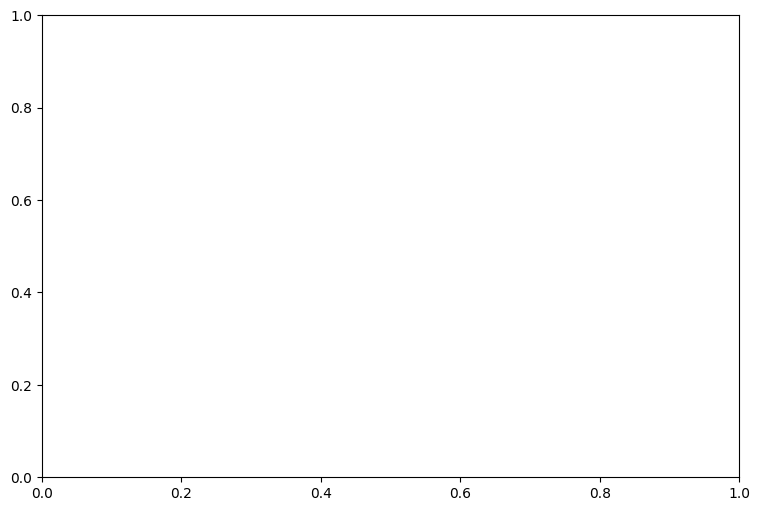

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import pandas as pd
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from spectroxide.solver import solve

# ── save location ───────────────────────────────────────────────────────────
SAVE_DIR  = "spectroxide/RUNS"
SAVE_FILE = "sweep_deltam_baryon_decay_photon_plus_ndecay_heat_tau1e9"
save_path = Path(SAVE_DIR)
save_path.mkdir(parents=True, exist_ok=True)
npz_file  = save_path / f"{SAVE_FILE}.npz"

# ── physical constants (SI) ───────────────────────────────────────────────
h_PLANCK = 6.62607015e-34     # J s
k_B      = 1.380649e-23       # J/K
c_LIGHT  = 2.99792458e8       # m/s
T_CMB0   = 2.7255             # K, present-day CMB temperature
eV_to_J  = 1.602176634e-19    # J / eV

def x_to_freq_GHz(x):
    """x = h*nu / (k_B*T_CMB) -> nu in GHz"""
    nu_Hz = x * k_B * T_CMB0 / h_PLANCK
    return nu_Hz / 1e9

def delta_n_to_intensity(x, delta_n):
    """
    Standard relation between photon occupation number and specific
    intensity:  I_nu = (2 h nu^3 / c^2) * n(x).
    A perturbation delta_n in occupation number therefore maps directly to
    an intensity perturbation via the same prefactor (linear in n).
    """
    nu_Hz = x * k_B * T_CMB0 / h_PLANCK
    prefac = 2.0 * h_PLANCK * nu_Hz**3 / c_LIGHT**2
    return prefac * delta_n

# ── physical parameters ──────────────────────────────────────────────────────
tau_X   = 1e9                 # [s]
GAMMA_X = 1.0 / tau_X
den_fac = 0.01                 # n_X,0/n_H,0 (McKeen 2021 benchmark)

M_N_EV = 939.565379e6          # neutron mass [eV]

# ── whether to include the beta-decay electron's kinetic energy in the heat
#    channel. Set False to deposit only the proton recoil energy T_p as heat
#    (e.g. if the electron energy is meant to be tracked separately / ignored).
INCLUDE_ELECTRON_HEAT = True

# beta-decay endpoint energies for n -> p + e + nu_bar (fixed by neutron decay
# kinematics; independent of Delta_m, since the neutron always decays via the
# same standard-model channel regardless of how it was produced). Read off the
# reference Mathematica benchmark (average over the electron spectrum K(E_e)):
T_E_AVG_MEV  = 0.301434        # <T_e>   [MeV]
T_P_AVG_MEV  = 0.000357075     # <T_p>   [MeV]
E_NU_AVG_MEV = 0.480509        # <E_nu>  [MeV]  (escapes, not deposited as heat)

E_HEAT_EV = ((T_E_AVG_MEV if INCLUDE_ELECTRON_HEAT else 0.0) + T_P_AVG_MEV) * 1e6  # [eV]

DELTA_M_MEV = [5, 10, 20, 30, 40, 50]          # sweep grid [MeV], chi -> n + gamma
DELTA_M_EV  = np.array(DELTA_M_MEV) * 1e6       # [eV]

# ── analytic templates (occupation-number convention) ────────────────────────
def G(x):
    return x * np.exp(x) / (np.exp(x) - 1)**2

def Ysz(x):
    return G(x) * (x / np.tanh(x / 2) - 4)

def tempshift(x):
    return G(x)

def mudist(x):
    return 1.401 * G(x) * (0.4561 - 1 / x)

def brightness_temp_exact(x, delta_n):
    xc  = np.clip(np.asarray(x, dtype=float), 1e-12, None)
    n0  = 1.0 / np.expm1(np.clip(xc, None, 500.0))
    n_x = n0 + delta_n
    return xc / np.log1p(1.0 / n_x) - 1.0

def fit_mu_y_T(x, delta_n, x_lo=1e-3, x_hi=40.0):
    mask = (x > x_lo) & (x < x_hi) & np.isfinite(delta_n)
    A = np.vstack([mudist(x[mask]), Ysz(x[mask]), tempshift(x[mask])]).T
    b = delta_n[mask]
    coeffs, *_ = np.linalg.lstsq(A, b, rcond=None)
    a_mu, a_y, a_T = coeffs
    model = a_mu * mudist(x) + a_y * Ysz(x) + a_T * tempshift(x)
    return delta_n - model, a_mu, a_y, a_T

def photon_energy_from_two_body_decay(delta_m_eV, m2_eV=0.0):
    """
    Exact two-body decay energy of the massless daughter (the photon) in
    chi(M) -> n(M_N) + gamma, with M = M_N + delta_m:
        E_gamma = (M^2 - M_N^2) / (2M)
    (the m2_eV=0 limit of the standard two-body decay formula; kept general
    in case a massive "gamma" placeholder is ever wanted).
    """
    M = M_N_EV + delta_m_eV
    E_gamma = (M**2 - M_N_EV**2 + m2_eV**2) / (2 * M)
    return E_gamma  # eV

def x_inj0_from_energy_eV(E_eV):
    """
    Convert a (rest-frame, injection-time) photon energy in eV to the
    invariant x = h*nu / (k_B*T_CMB) normalization used throughout, which
    is redshift-independent since both E and T_CMB redshift together.
    """
    E_J = E_eV * eV_to_J
    return E_J / (k_B * T_CMB0)

# ── load cache (resume support) ──────────────────────────────────────────────
results = {}
if npz_file.exists():
    print(f"Found existing data at '{npz_file}', loading...")
    existing = np.load(npz_file, allow_pickle=True)
    loaded_keys = set(existing.files)
    for dm in DELTA_M_EV:
        kx, kdn, kmu, ky = (f"dm{dm:.6g}_{s}" for s in ("x", "delta_n", "mu", "y"))
        if all(k in loaded_keys for k in (kx, kdn, kmu, ky)):
            results[dm] = (existing[kx], existing[kdn], float(existing[kmu]), float(existing[ky]))
            print(f"  loaded Δm = {dm/1e6:.0f} MeV")

def save_results():
    flat = {"tau_X": np.array(tau_X), "den_fac": np.array(den_fac),
            "delta_m_ev": DELTA_M_EV, "e_heat_ev": np.array(E_HEAT_EV),
            "include_electron_heat": np.array(INCLUDE_ELECTRON_HEAT)}
    for dm, (x_arr, dn, mu_r, y_r) in results.items():
        flat[f"dm{dm:.6g}_x"]       = x_arr
        flat[f"dm{dm:.6g}_delta_n"] = dn
        flat[f"dm{dm:.6g}_mu"]      = np.array(mu_r)
        flat[f"dm{dm:.6g}_y"]       = np.array(y_r)
    np.savez(npz_file, **flat)
    print(f"  → saved to '{npz_file}'")

# ── grid / solver settings shared by both channels ────────────────────────
SOLVER_KW = dict(
    z_start           = 1e7,
    z_end             = 0,
    x_min             = 1e8,
    x_max             = 1e12,
    n_x               = 1000,
    method            = 'pde',
    production_grid   = True,
    number_conserving = True,
    timeout           = 3600,
)

# ── run one Δm point: photon channel (chi -> n + gamma) + heat channel
#    (n -> p + e + nu_bar, only T_e+T_p deposited; the neutrino escapes) ──────
def run_one(dm):
    E_gamma_eV = photon_energy_from_two_body_decay(dm)
    x_inj0     = x_inj0_from_energy_eV(E_gamma_eV)

    # photon-channel injection: a monochromatic photon line, sourced
    # continuously by the decaying-particle rate, exactly mirroring the
    # heat-channel 'decaying_particle' scenario used previously but for the
    # photon-number channel instead of the heat channel.
    r_gamma = solve(
        injection = {
            'type':     'decaying_particle_photon',
            'x_inj_0':   x_inj0,
            'f_inj':    den_fac,   # one photon injected per chi decay
            'gamma_x':  GAMMA_X,
        },
        **SOLVER_KW,
    )

    # heat channel: prompt neutron beta-decay dumps T_e+T_p into the baryons.
    # This is independent of Delta_m (fixed neutron-decay kinematics), so in
    # principle it only needs to be solved once, but we recompute it here for
    # clarity / to keep parallel dispatch simple.
    r_heat = solve(
        injection = {
            'type':     'decaying_particle',
            'f_x':      E_HEAT_EV * den_fac,
            'gamma_x':  GAMMA_X,
        },
        **SOLVER_KW,
    )

    # linear superposition of the two independent injection channels
    # (valid to leading order in the perturbation, standard in this literature)
    x_arr   = r_gamma.x
    delta_n = r_gamma.delta_n + r_heat.delta_n
    mu_tot  = r_gamma.mu + r_heat.mu
    y_tot   = r_gamma.y + r_heat.y

    return dm, (x_arr, delta_n, mu_tot, y_tot), E_gamma_eV

# ── run all missing Δm points at the same time ────────────────────────────────
extra_info = {}
to_run = [dm for dm in DELTA_M_EV if dm not in results]
if to_run:
    print(f"Launching {len(to_run)} runs in parallel ...")
    with ThreadPoolExecutor(max_workers=min(len(to_run), 10)) as ex:
        futures = {ex.submit(run_one, dm): dm for dm in to_run}
        for fut in as_completed(futures):
            dm = futures[fut]
            try:
                dm_done, payload, E_gamma_eV = fut.result()
                results[dm_done] = payload
                extra_info[dm_done] = E_gamma_eV
                print(f"  Δm = {dm_done/1e6:.0f} MeV ... done  (E_gamma = {E_gamma_eV/1e6:.4f} MeV)")
            except Exception as e:
                print(f"  Δm = {dm/1e6:.0f} MeV ... FAILED: {e}")
    save_results()
else:
    print("All Δm points already cached.")
    for dm in DELTA_M_EV:
        extra_info[dm] = photon_energy_from_two_body_decay(dm)

# ── colour gradient over Δm ───────────────────────────────────────────────────
cmap = plt.cm.viridis
norm = mcolors.Normalize(vmin=min(DELTA_M_MEV), vmax=max(DELTA_M_MEV))
sm   = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# ── plot: spectrum (top) + residual (bottom) ─────────────────────────────────
fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(9, 9), gridspec_kw={"height_ratios": [1.4, 1], "hspace": 0.32}
)

fig, ax = plt.subplots(figsize=(9, 6))

table_rows = []
for dm_mev, dm in zip(DELTA_M_MEV, DELTA_M_EV):
    x_arr, dn, mu_r, y_r = results[dm]
    c = cmap(norm(dm_mev))

    dT = brightness_temp_exact(x_arr, dn)
    ax_top.semilogx(x_arr, dT, color=c, lw=1.6, label=fr'$\Delta m={dm_mev}$ MeV')

    resid, a_mu, a_y, a_T = fit_mu_y_T(x_arr, dn)
    mask_plot = (x_arr > 0.05) & (x_arr < 20)
    ax_bot.semilogx(x_arr[mask_plot], resid[mask_plot], color=c, lw=1.4)

    E_gamma_eV = extra_info.get(dm, photon_energy_from_two_body_decay(dm))
    table_rows.append(dict(
        delta_m_MeV = dm_mev,
        E_gamma_keV = E_gamma_eV / 1e3,
        F_heat_eV   = E_HEAT_EV * den_fac,
        mu          = mu_r,
        y           = y_r,
        a_mu_resid  = a_mu,
        a_y_resid   = a_y,
        a_T_resid   = a_T,
        resid_rms   = np.sqrt(np.mean(resid[mask_plot]**2)),
    ))

ax_top.axhline(0, color='k', lw=0.5, ls=':')
ax_top.set_xlim(1e8, 1e12)
ax_top.set_ylim(-25e-6, 5e-6)
ax_top.set_xlabel(r'$x = h\nu / kT_z$', fontsize=12)
ax_top.set_ylabel(r'$T(x)/T_{\rm CMB} - 1$', fontsize=12)
ax_top.set_title(r'CMB spectral distortion — $\chi \to n + \gamma$, $n \to p+e+\bar\nu$  ($\tau_X=10^9$ s)', fontsize=11)
ax_top.legend(fontsize=8, frameon=False, loc='lower right', ncol=2)

ax_bot.axhline(0, color='k', lw=0.5, ls=':')
ax_bot.set_xlim(1e8, 1e12)
ax_bot.set_ylim(-30e-6, 30e-6)
ax_bot.set_xlabel(r'$x = h\nu / kT_z$', fontsize=12)
ax_bot.set_ylabel(r'Residual $\Delta n - (\mu M + y Y_{\rm SZ} + a_T G_{\rm bb})$', fontsize=10.5)
ax_bot.set_title('Residual after subtracting best-fit µ/y/T-shift templates', fontsize=10.5)

cbar = fig.colorbar(sm, ax=[ax_top, ax_bot], pad=0.02)
cbar.set_label(r'$\Delta m$ [MeV]', fontsize=11)

for dm_mev, dm in zip(DELTA_M_MEV, DELTA_M_EV):
    x_arr, delta_n, mu_r, y_r = results[dm]

    nu_GHz  = x_to_freq_GHz(x_arr)
    I_nu    = delta_n_to_intensity(x_arr, delta_n)

    c = cmap(norm(dm_mev))
    pos = I_nu > 0
    neg = ~pos

    ax.plot(nu_GHz[pos], I_nu[pos], color=c, lw=1.8,
            label=fr'$\Delta m={dm_mev}$ MeV')
    ax.plot(nu_GHz[neg], -I_nu[neg], color=c, lw=1.8, ls='--')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(1e-4, 1e4)
ax.set_ylim(1e-33, 1.5e-23)
xlim = ax.get_xlim()
pixie_sens = 5e-26   # J s^-1 m^-2 Hz^-1 sr^-1  (Kogut et al. 2011, ~5 Jy/sr)
ax.plot([3e-4, xlim[1]], [pixie_sens, pixie_sens], color='black', lw=1.5, ls=':', alpha=0.5)
ax.annotate(fr'PIXIE sensitivity $\sim5\,\mathrm{{Jy\,sr^{{-1}}}} \sim {pixie_sens} J s^{{-1}} m^{{-2}} Hz^{{-1}} sr^{{-1}}$',
            xy=(3e-2, pixie_sens),
            xytext=(1e-4, pixie_sens),
            fontsize=9, color='black')
ax.set_xlabel(r'Frequency, $\nu$ [GHz]', fontsize=12)
ax.set_ylabel(r'Intensity, $|\Delta I_\nu|$ [J s$^{-1}$ m$^{-2}$ Hz$^{-1}$ sr$^{-1}$]', fontsize=12)
ax.set_title(r'Spectral distortion intensity — $\chi \to n + \gamma$, $n \to p+e+\bar\nu$'
             r'  ($\tau_X=10^9$ s, solid = positive, dashed = negative)', fontsize=11)
ax.legend(fontsize=9, frameon=False, loc='best')
ax.grid(True, which='both', alpha=0.15)

fig.colorbar(sm, ax=ax, pad=0.02, label=r'$\Delta m$ [MeV]')


plt.show()

# ── summary table ─────────────────────────────────────────────────────────────
def print_table(rows, columns):
    """columns: list of (key, header, fmt, width)"""
    sep = "+" + "+".join("-" * (w + 2) for _, _, _, w in columns) + "+"
    header = "| " + " | ".join(f"{h:^{w}}" for _, h, _, w in columns) + " |"
    print(sep)
    print(header)
    print(sep)
    for row in rows:
        line = "| " + " | ".join(
            f"{format(row[k], fmt):>{w}}" for k, h, fmt, w in columns
        ) + " |"
        print(line)
    print(sep)

columns = [
    ("delta_m_MeV", "Δm [MeV]",      ".0f",  9),
    ("E_gamma_keV", "E_γ [keV]",     ".3f", 11),
    ("F_heat_eV",   "F_heat [eV]",   ".3e", 13),
    ("mu",          "μ",             ".3e", 11),
    ("y",           "y",             ".3e", 11),
    ("a_mu_resid",  "a_μ (resid)",   ".3e", 13),
    ("a_y_resid",   "a_y (resid)",   ".3e", 13),
    ("a_T_resid",   "a_T (resid)",   ".3e", 13),
    ("resid_rms",   "resid RMS",     ".3e", 11),
]

print(f"\nBaryonic-decay case (χ → n + γ, then n → p + e + ν̄)   "
      f"τ_X = {tau_X:.0e} s   n_X,0/n_H,0 = {den_fac}   "
      f"E_heat/decay = {E_HEAT_EV:.2f} eV "
      f"({'T_e+T_p' if INCLUDE_ELECTRON_HEAT else 'T_p only'})\n")
print_table(table_rows, columns)

### $\chi \rightarrow n + \gamma$ : `DarkHistory` (independent parameters)

m_X       = 944.565421 MeV
Delta     = 5.000000 MeV
E_gamma   = 4.986766 MeV  (above e+e- threshold of 1.022 MeV)


  0%|          | 0/414.0 [00:00<?, ?it/s]

  0%|          | 0/414.0 [00:00<?, ?it/s]

  0%|          | 0/414.0 [00:00<?, ?it/s]

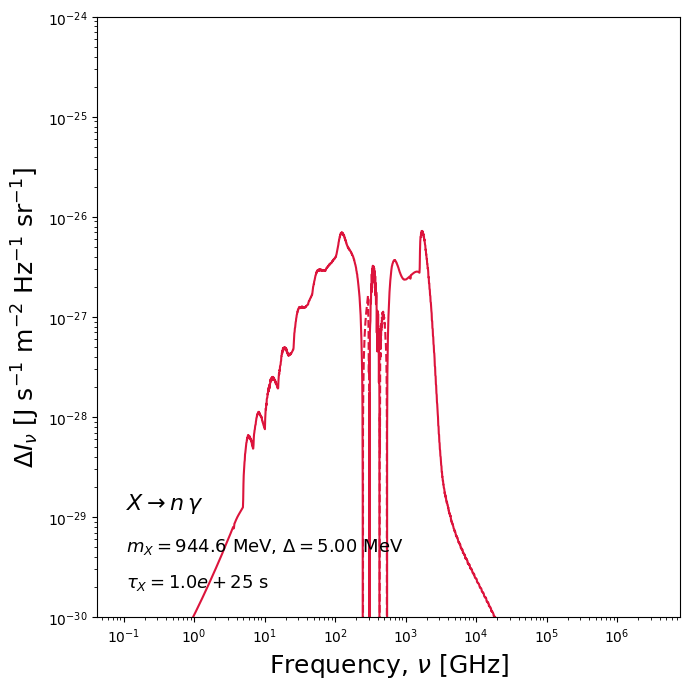

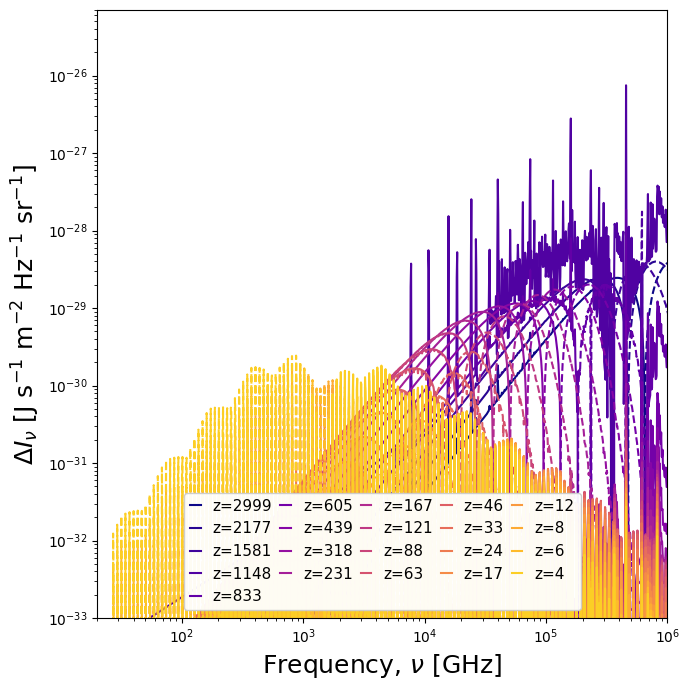

In [ ]:
"""
Spectral distortions from dark-baryon decay:  X -> n + gamma
==============================================================

Physics
-------
Following Berlin, McKeen & Raj (or the "dark baryon" scenario of
Phys. Rev. D 103, 115002), X is a neutral fermion nearly degenerate
with the neutron (m_X = m_n + Delta, Delta > 0) that mixes with the
neutron through a higher-dimensional operator. If X makes up (some
fraction of) the dark matter, it can decay as

    X -> n + gamma ,   tau_X = lifetime

This is a two-body decay, so in the X rest frame the photon energy is
fixed exactly by kinematics:

    E_gamma = (m_X^2 - m_n^2) / (2 m_X) = Delta - Delta^2/(2 m_X) + ...

The neutron is *not* electromagnetically active on DarkHistory's
timescales (no fast EM energy loss channel), so essentially all of the
injected power that participates in the EM cascade / CMB spectral
distortion is the *photon*, carrying only E_gamma per decay -- NOT
m_X/2 as the built-in 'phot_delta' PPPC channel assumes (that channel
is built for X -> gamma + gamma). Because E_gamma can easily be above
2*m_e = 1.022 MeV, the injected photon can pair-produce on route to
thermalizing, triggering the full high-energy EM cascade (ICS,
double-Compton, pair production, etc.) that DarkHistory's
high-energy-photon transfer functions already handle.

Because of this we do NOT use `primary='phot_delta'` (that assumes 2
photons of energy mDM/2 each = mDM per decay). Instead we build the
injected spectrum "by hand": a single delta-function photon of energy
E_gamma, and we normalize rate_func_N / rate_func_eng to the actual
number density of X decays and the actual EM power injected (i.e.
N_dot * E_gamma), not to m_X. If you want to explore only the
neutron-decay-heat channel (pulsar heating etc.) that's a separate,
non-EM calculation and is not covered here.

This script mirrors "Example 13: Generating spectral distortions" in
the DarkHistory examples folder but replaces the 2-photon delta
injection with the correct single-photon, kinematically-fixed
injection for X -> n + gamma.

Requires a working DarkHistory install with the binary transfer-
function data downloaded (see https://github.com/hongwanliu/DarkHistory,
`darkhistory.config.load_data`).
"""

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import cm

import darkhistory.physics as phys
import darkhistory.main as main
from darkhistory.config import load_data
from darkhistory.spec.spectools import rebin_N_arr
from darkhistory.spec.spectrum import Spectrum

# photeng/eleceng are not module-level constants in darkhistory.config --
# they come from the 'binning' data table, exactly like main.evolve()
# loads them internally (see darkhistory/main.py, ~line 267).
binning = load_data('binning')
photeng = binning['phot']
eleceng = binning['elec']

# ----------------------------------------------------------------------
# 1. Dark baryon model parameters -- EDIT THESE
# ----------------------------------------------------------------------

m_n = 939.56542052e6          # neutron mass, eV (PDG)

mX_over_mn_minus_1 = None      # placeholder, see Delta below

# Mass splitting Delta = m_X - m_n, in eV. This sets E_gamma. Pick a
# value large enough to sit above the e+e- pair-production threshold
# (2*m_e ~ 1.022 MeV) if you want to see pair production / full
# cascade physics kick in; smaller Delta gives a purely sub-threshold
# (Compton-only) photon injection.
Delta = 5e6                    # 5 MeV splitting (example)

mX = m_n + Delta               # dark baryon mass, eV

# Two-body decay kinematics, X (at rest) -> n + gamma :
E_gamma = (mX**2 - m_n**2) / (2 * mX)     # exact photon energy, eV
# (For Delta << m_n this reduces to E_gamma ~ Delta - Delta^2/(2 m_n).)

print(f'm_X       = {mX/1e6:.6f} MeV')
print(f'Delta     = {Delta/1e6:.6f} MeV')
print(f'E_gamma   = {E_gamma/1e6:.6f} MeV  '
      f'({"above" if E_gamma > 2*phys.me else "below"} e+e- threshold '
      f'of {2*phys.me/1e6:.3f} MeV)')

# Lifetime of X (s). Pick something long enough to be cosmologically
# relevant (CMB-era decays, ~10^12 - 10^26 s depending on how you want
# to probe the parameter space). Replace with e.g. an actual bound
# from Fig. in 2101.xxxxx / PRD 103, 115002 if you have one.
tau_X = 1e25

# Fraction of the total dark matter density made up by X. Use f_X = 1
# if X *is* all of the dark matter (as in the CMB-bound calculations
# of the dark-baryon paper); otherwise rescale.
f_X = 1.0

# ----------------------------------------------------------------------
# 2. Build the single-photon "delta function" injection spectrum
# ----------------------------------------------------------------------
# We put exactly 1 photon carrying energy E_gamma per decay event into
# the nearest bin of DarkHistory's photon energy abscissa (photeng),
# conserving both number (1) and energy (E_gamma) via rebin_N_arr --
# same low-level routine DarkHistory's own pppc.get_pppc_spec() uses
# for 'phot_delta', just with only one photon instead of two.

if E_gamma <= photeng[0] or E_gamma >= photeng[-1]:
    raise ValueError(
        'E_gamma is outside the tabulated photeng range -- pick a '
        'different Delta, or check darkhistory.config.photeng bounds.'
    )

eng_to_inj = photeng[photeng < E_gamma][-1]

in_spec_phot = rebin_N_arr(
    np.array([E_gamma / eng_to_inj]),   # N in that bin such that N*eng_to_inj = E_gamma... 
    np.array([eng_to_inj]),
    photeng,
)
# rebin_N_arr conserves total number (1 photon) and total energy
# (E_gamma) between photeng bin edges, distributing them appropriately
# near eng_to_inj -- exactly analogous to pppc's phot_delta handling.

in_spec_phot.rs = None   # set below once we know start_rs
in_spec_phot.switch_spec_type('N')

# No prompt electron injection from this channel (the neutron carries
# no fast/prompt EM-relevant energy loss on these timescales).
in_spec_elec = Spectrum(eleceng, np.zeros_like(eleceng), spec_type='N')

# ----------------------------------------------------------------------
# 3. Injection rate functions
# ----------------------------------------------------------------------
# Number density of decays per volume per time:
#   n_X(rs) * Gamma_X = f_X * rho_DM(rs) / m_X / tau_X
# where rho_DM(rs) = phys.rho_DM * rs**3 (phys.rho_DM is today's value).
#
# IMPORTANT: rate_func_eng must equal the energy ACTUALLY injected
# electromagnetically per volume per time, i.e. N_dot * E_gamma --
# *not* N_dot * m_X (which is what DarkHistory's built-in decay
# machinery assumes when it divides by m_X and multiplies back by
# m_X). If you used m_X here, all downstream deposited/rate_func_eng
# fractions (f_c(z) diagnostics) would be wrong by a factor
# E_gamma/m_X, even though the actual spectra/distortions would
# happen to still be self-consistent (since only in_spec_phot's total
# energy matters for the actual physics) -- but the f_c bookkeeping
# would silently mislabel the efficiency. So: normalize to E_gamma.

def rate_func_N(rs):
    """Number of X decays per unit volume per unit time, at redshift rs=1+z."""
    return f_X * phys.rho_DM * rs**3 / mX / tau_X


def rate_func_eng(rs):
    """EM energy injection rate (photons only) per unit volume per unit time."""
    return rate_func_N(rs) * E_gamma


# ----------------------------------------------------------------------
# 4. Run DarkHistory with distortion tracking switched on
# ----------------------------------------------------------------------

start_rs = 3000       # 1+z to start the calculation at
high_rs = 1.555e3      # matches Example 13's stiff-ODE threshold
end_rs = 4
nmax = 10               # max hydrogen level tracked by the MLA
iterations = 3          # MLA self-consistency iterations

in_spec_phot.rs = start_rs
in_spec_elec.rs = start_rs

data = main.evolve(
    in_spec_elec=in_spec_elec,
    in_spec_phot=in_spec_phot,
    rate_func_N=rate_func_N,
    rate_func_eng=rate_func_eng,
    start_rs=start_rs,
    high_rs=high_rs,
    end_rs=end_rs,
    coarsen_factor=16,
    rtol=1e-6,
    nmax=nmax,
    iterations=iterations,
    distort=True,           # turn on spectral-distortion tracking
    fexc_switch=True,       # include DM-sourced excitations as a distortion source
    reprocess_distortion=True,  # feed distortion photons back into atomic rates
)

# `data` is a list (one dict per MLA iteration); the last entry is the
# most self-consistent one, same convention as Example 13.
result = data[-1]

# ----------------------------------------------------------------------
# 5. Plot the total distortion accumulated over 3000 > 1+z > 4
# ----------------------------------------------------------------------

hplanck = phys.hbar * 2 * np.pi


def plot_distortion(ax, res, **kwargs):
    """Plot Delta I_nu vs frequency (GHz), dashing negative-valued bins."""
    spec = res['distortion']
    freq_GHz = spec.eng / hplanck / 1e9
    I_nu = (
        spec.dNdE * phys.nB * spec.eng * hplanck * phys.c
        / (4 * np.pi) * phys.ele * 1e4
    )
    ax.loglog(freq_GHz, I_nu, **kwargs)
    ax.loglog(freq_GHz, -I_nu, linestyle='--', **kwargs)


fig, ax = plt.subplots(figsize=(7, 7))
plot_distortion(ax, result, color='crimson')

ax.set_ylim(1e-30, 1e-24)
ax.set_xlabel(r'Frequency, $\nu$ [GHz]', fontsize=18)
ax.set_ylabel(r'$\Delta I_{\nu}$ [J s$^{-1}$ m$^{-2}$ Hz$^{-1}$ sr$^{-1}$]', fontsize=18)
ax.text(0.05, 0.18, r'$X \rightarrow n\,\gamma$', fontsize=16, transform=ax.transAxes)
ax.text(0.05, 0.11, rf'$m_X = {mX/1e6:.1f}$ MeV, $\Delta = {Delta/1e6:.2f}$ MeV',
        fontsize=13, transform=ax.transAxes)
ax.text(0.05, 0.05, rf'$\tau_X = {tau_X:.1e}$ s', fontsize=13, transform=ax.transAxes)
fig.tight_layout()

# ----------------------------------------------------------------------
# 6. Plot the per-redshift-step contributions (every `skip`-th step)
# ----------------------------------------------------------------------

skip = 20
rs_arr = result['lowengphot'].rs[::skip]
colors = cm.plasma(np.linspace(0., 0.9, len(rs_arr)))

fig2, ax2 = plt.subplots(figsize=(7, 7))
ax2.loglog()

for ii, rs in enumerate(rs_arr):
    step = result['distortions'][ii * skip]
    freq_GHz = step.eng / hplanck / 1e9
    I_nu = (
        step.dNdE * phys.nB * step.eng * hplanck * phys.c
        / (4 * np.pi) * phys.ele * 1e4
    )
    ax2.plot(freq_GHz, I_nu, color=colors[ii], label=f'z={rs - 1:.0f}')
    ax2.plot(freq_GHz, -I_nu, color=colors[ii], linestyle='--')

ax2.axis([20, 1e6, 1e-33, 7e-26])
ax2.set_xlabel(r'Frequency, $\nu$ [GHz]', fontsize=18)
ax2.set_ylabel(r'$\Delta I_{\nu}$ [J s$^{-1}$ m$^{-2}$ Hz$^{-1}$ sr$^{-1}$]', fontsize=18)
ax2.legend(loc='lower center', ncol=5, handlelength=0.7, fontsize=11,
           columnspacing=0.5, framealpha=0.95)
fig2.tight_layout()

### $\chi \rightarrow n + \gamma$ : `DarkHistory` (somewhat similar parameters)

Found existing data at 'spectroxide/RUNS/darkhistory_sweep_deltam_photon_tau1e9.npz', loading...
  loaded Delta_m = 5 MeV
  loaded Delta_m = 10 MeV
  loaded Delta_m = 20 MeV
  loaded Delta_m = 30 MeV
  loaded Delta_m = 40 MeV
  loaded Delta_m = 50 MeV
All Delta_m points already cached.


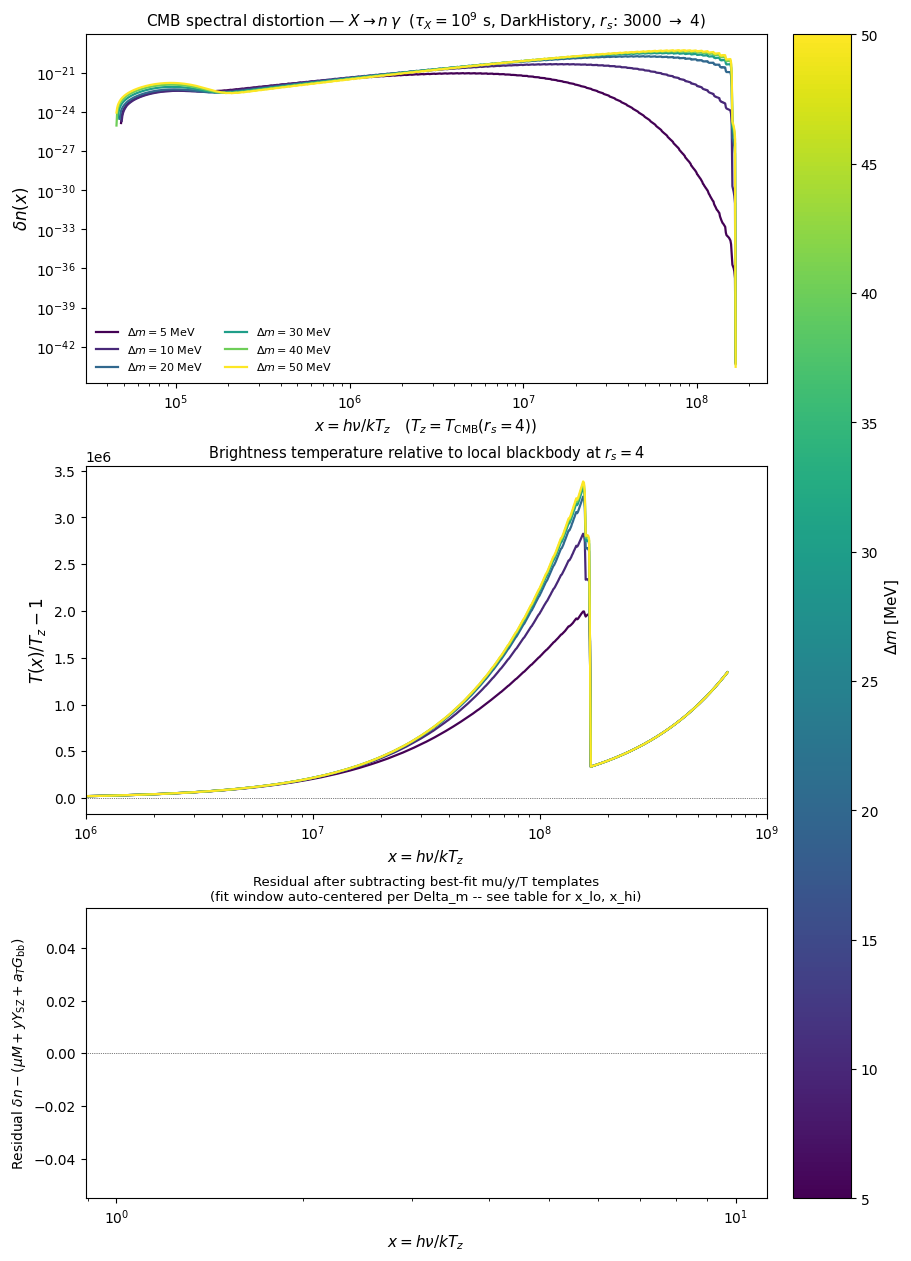


Photon case (X -> n + gamma)   tau_X = 1e+09 s   n_X,0/n_H,0 = 0.01
x defined relative to T_CMB(rs=4) = 9.394616e-04 eV

+---------------+--------------+-------------+------------+------------+-------------+-------------+-------------+
| Delta_m [MeV] | n_X0 [eV^3]  |  T_n [keV]  |    x_lo    |    x_hi    |     mu      |      y      |  resid RMS  |
+---------------+--------------+-------------+------------+------------+-------------+-------------+-------------+
|             5 |    1.901e-09 |     13.2336 |  1.000e-03 |  4.000e+01 |   3.592e-24 |  -1.144e-26 |         nan |
|            10 |    1.901e-09 |     52.6557 |  1.000e-03 |  4.000e+01 |   3.399e-24 |  -1.083e-26 |         nan |
|            20 |    1.901e-09 |    208.4277 |  1.000e-03 |  4.000e+01 |   4.946e-24 |  -1.576e-26 |         nan |
|            30 |    1.901e-09 |    464.1255 |  1.000e-03 |  4.000e+01 |   8.164e-24 |  -2.601e-26 |         nan |
|            40 |    1.901e-09 |    816.6887 |  1.000e-03 |  4.000e+01 | 

In [ ]:
"""
Spectral distortions from dark-baryon decay:  X -> n + gamma
Parameter sweep over Delta_m, DarkHistory backend
==============================================================

This reuses the *physics setup and injection construction* of the
original single-point DarkHistory script (single delta-function photon
at the exact two-body kinematic energy E_gamma, zero prompt electron
injection, rate_func_N/rate_func_eng normalized to actual EM power,
not to m_X), but borrows the *simulation parameters and sweep
structure* from the spectroxide script:

    tau_X    = 1e9 s                      (fixed decay lifetime)
    den_fac  = n_X,0 / n_H,0 = 0.01        (X number density today,
                                             relative to hydrogen)
    Delta_m  = [5, 10, 20, 30, 40, 50] MeV (mass-splitting sweep)

IMPORTANT CAVEAT vs. spectroxide
---------------------------------
spectroxide's `solve()` was run from z_start = 1e7. DarkHistory's
transfer-function tables only extend up to 1+z = 3000, so this script
runs each DarkHistory point from start_rs = 3000 instead of 1e7. Any
mu-type distortion sourced between z=1e7 and z=3000 is NOT captured
here. Consequently, this script is now framed as "what does the
distortion look like at the *end* of the DarkHistory run (rs=end_rs),
in the local CMB-temperature frame at that epoch" rather than as a
direct today-frame comparison to spectroxide. See the discussion below
`x_arr` for why the local-frame normalization matters.

CHANGES vs. previous version
-----------------------------
1. x is now defined relative to the *local* CMB temperature at
   end_rs (T_CMB(rs=end_rs)), not T_CMB0 (today). This isolates
   "how far this spectrum is from a Planck distribution at the epoch
   the simulation actually reaches" from "how much extra redshifting
   from rs=end_rs down to rs=1 would additionally do to x" -- the
   latter is a trivial rescaling (x_today = x_local / end_rs) that
   was previously conflating two different physical effects (degree
   of thermalization vs. residual redshift-to-today) into one plot.
2. Added a brightness-temperature panel (dT/T vs x), same convention
   as spectroxide's `brightness_temp_exact`, in addition to the raw
   delta_n(x) panel.
3. The mu/y/T-shift residual fit window is no longer hardcoded to
   spectroxide's [1e-3, 80] (which assumes a today-frame, thermalized
   spectrum). It now auto-centers on where the DarkHistory output
   actually carries flux, via a per-point IQR-style window around the
   spectrum's own log-x centroid, so the fit is meaningful for
   whatever epoch/frame the run lands in.
"""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from pathlib import Path

import darkhistory.physics as phys
import darkhistory.main as main
from darkhistory.config import load_data
from darkhistory.spec.spectools import rebin_N_arr
from darkhistory.spec.spectrum import Spectrum

# ── save location ────────────────────────────────────────────────────────
SAVE_DIR  = "spectroxide/RUNS"
SAVE_FILE = "darkhistory_sweep_deltam_photon_tau1e9"
save_path = Path(SAVE_DIR)
save_path.mkdir(parents=True, exist_ok=True)
npz_file  = save_path / f"{SAVE_FILE}.npz"

# ── binning (photeng/eleceng come from the 'binning' data table) ──────────
binning = load_data('binning')
photeng = binning['phot']
eleceng = binning['elec']

# ── physical parameters (borrowed from spectroxide script) ────────────────
tau_X   = 1e9                  # [s] decay lifetime -- fixed across sweep
den_fac = 0.01                  # n_X,0 / n_H,0 today (McKeen 2021 benchmark)

M_N_EV = 939.565379e6           # neutron mass [eV]

DELTA_M_MEV = [5, 10, 20, 30, 40, 50]           # sweep grid [MeV]
DELTA_M_EV  = np.array(DELTA_M_MEV) * 1e6        # [eV]

# DarkHistory-specific run settings (unchanged from the single-point script)
start_rs   = 3000.0     # capped at DarkHistory's tabulated rs range
high_rs    = 1.555e3
end_rs     = 4
nmax       = 10
iterations = 3
coarsen_factor = 16
rtol = 1e-6

hplanck = phys.hbar * 2 * np.pi
kB      = phys.kB               # Boltzmann constant, eV/K (DarkHistory convention)

# n_X,0 in DarkHistory units (eV^3 comoving number density today), from den_fac
n_X0 = den_fac * phys.nH        # phys.nH = hydrogen number density today

# CHANGE 1: reference temperature is now the *local* CMB temperature at
# end_rs, not today's T_CMB0. x = h nu / kT_z with T_z = T_CMB(end_rs).
T_CMB_END = phys.TCMB(end_rs)   # eV, CMB temperature AT rs = end_rs


# ── analytic mu/y/T templates (same convention as spectroxide script) ─────
def G(x):
    """Numerically stable x*e^x/(e^x-1)^2, valid for x -> 0 and x -> inf.

    For x >~ 400, e^x overflows float64 well before it's squared, giving
    inf/inf = NaN with the naive formula. But the true value of G(x) for
    large x is exponentially small (G(x) ~ x*exp(-x) -> 0), so we branch:
    compute the naive formula for x below a safe threshold, and return 0
    (its correct asymptotic value) above it, instead of NaN.
    """
    x = np.asarray(x, dtype=float)
    out = np.zeros_like(x)
    safe = np.isfinite(x) & (np.abs(x) < 400.0)
    xs = x[safe]
    ex = np.exp(xs)
    with np.errstate(divide='ignore', invalid='ignore'):
        out[safe] = np.where(xs != 0, xs * ex / (ex - 1)**2, 1.0)  # G(0) = 1 (limit)
    return out

def Ysz(x):
    return G(x) * (x / np.tanh(np.clip(x / 2, 1e-300, None)) - 4)

def tempshift(x):
    return G(x)

def mudist(x):
    return 1.401 * G(x) * (0.4561 - 1 / x)

def brightness_temp_exact(x, delta_n):
    """dT/T_z - 1, same convention as spectroxide's brightness_temp_exact,
    but here x and delta_n are both defined relative to T_z = T_CMB(end_rs)
    rather than T_CMB0."""
    xc  = np.clip(np.asarray(x, dtype=float), 1e-12, None)
    n0  = 1.0 / np.expm1(np.clip(xc, None, 500.0))
    n_x = n0 + delta_n
    return xc / np.log1p(1.0 / np.clip(n_x, 1e-300, None)) - 1.0

def fit_mu_y_T(x, delta_n, x_lo, x_hi):
    mask = (x > x_lo) & (x < x_hi) & np.isfinite(delta_n)
    if mask.sum() < 3:
        # not enough points in-window to fit 3 templates -- return NaNs
        # rather than crashing lstsq
        return np.full_like(delta_n, np.nan), np.nan, np.nan, np.nan
    A = np.vstack([mudist(x[mask]), Ysz(x[mask]), tempshift(x[mask])]).T
    b = delta_n[mask]
    coeffs, *_ = np.linalg.lstsq(A, b, rcond=None)
    a_mu, a_y, a_T = coeffs
    model = a_mu * mudist(x) + a_y * Ysz(x) + a_T * tempshift(x)
    return delta_n - model, a_mu, a_y, a_T

TEMPLATE_VALID_RANGE = (1e-3, 40.0)

def auto_fit_window(x_arr, delta_n, pad_dex=1.0):
    """Pick a window around wherever THIS spectrum has flux, in log-x
    space, but INTERSECTED with TEMPLATE_VALID_RANGE -- fitting mu/y/T
    templates outside their domain of validity is meaningless even once
    the NaN/overflow issue is fixed, since the templates are ~0 there.

    Returns (x_lo, x_hi, has_overlap). If the spectrum's flux-weighted
    centroid window doesn't overlap TEMPLATE_VALID_RANGE at all, has_overlap
    is False and the caller should skip the fit (report NaN) rather than
    fit a near-zero design matrix.
    """
    finite = np.isfinite(delta_n) & (x_arr > 0)
    w = np.abs(delta_n[finite])
    if w.sum() <= 0 or finite.sum() == 0:
        return TEMPLATE_VALID_RANGE[0], TEMPLATE_VALID_RANGE[1], False

    logx = np.log10(x_arr[finite])
    centroid = np.average(logx, weights=w)
    x_lo = 10**(centroid - pad_dex)
    x_hi = 10**(centroid + pad_dex)

    tlo, thi = TEMPLATE_VALID_RANGE
    x_lo_clipped = max(x_lo, tlo)
    x_hi_clipped = min(x_hi, thi)

    has_overlap = x_lo_clipped < x_hi_clipped
    if not has_overlap:
        return tlo, thi, False

    return x_lo_clipped, x_hi_clipped, True

def neutron_recoil_KE(delta_m_eV, m2_eV=0.0):
    """Exact two-body recoil KE of the neutron: E_n = (M^2+m_n^2-m2^2)/(2M)."""
    M = M_N_EV + delta_m_eV
    E_n = (M**2 + M_N_EV**2 - m2_eV**2) / (2 * M)
    return E_n - M_N_EV   # eV


# ── build injection + run DarkHistory for one Delta_m point ───────────────
def run_one(dm):
    """dm: mass splitting Delta = m_X - m_n, in eV."""
    mX = M_N_EV + dm
    E_gamma = (mX**2 - M_N_EV**2) / (2 * mX)   # exact two-body photon energy

    if E_gamma <= photeng[0] or E_gamma >= photeng[-1]:
        raise ValueError(
            f'E_gamma = {E_gamma/1e6:.3f} MeV outside tabulated photeng range '
            f'for Delta_m = {dm/1e6:.1f} MeV.'
        )

    eng_to_inj = photeng[photeng < E_gamma][-1]
    in_spec_phot = rebin_N_arr(
        np.array([E_gamma / eng_to_inj]),
        np.array([eng_to_inj]),
        photeng,
    )
    in_spec_phot.rs = start_rs
    in_spec_phot.switch_spec_type('N')

    in_spec_elec = Spectrum(eleceng, np.zeros_like(eleceng), spec_type='N')
    in_spec_elec.rs = start_rs

    def rate_func_N(rs):
        return n_X0 * rs**3 / tau_X

    def rate_func_eng(rs):
        return rate_func_N(rs) * E_gamma

    data = main.evolve(
        in_spec_elec=in_spec_elec,
        in_spec_phot=in_spec_phot,
        rate_func_N=rate_func_N,
        rate_func_eng=rate_func_eng,
        start_rs=start_rs,
        high_rs=high_rs,
        end_rs=end_rs,
        coarsen_factor=coarsen_factor,
        rtol=rtol,
        nmax=nmax,
        iterations=iterations,
        distort=True,
        fexc_switch=True,
        reprocess_distortion=True,
    )
    result = data[-1]

    spec = result['distortion']

    # CHANGE 1: use the LOCAL CMB temperature at end_rs, not T_CMB0.
    x_arr = spec.eng / (kB * T_CMB_END)   # x = h nu / kT_z,  T_z = T_CMB(end_rs)

    with np.errstate(divide='ignore', invalid='ignore'):
        delta_n = (
            spec.dNdE * phys.nB * spec.eng**3 * hplanck**3
            / (8 * np.pi * (kB * T_CMB_END)**3)
        )
    delta_n = np.nan_to_num(delta_n, nan=0.0, posinf=0.0, neginf=0.0)

    # CHANGE 3: auto-center the fit window on this spectrum's own flux,
    # instead of the fixed today-frame [1e-3, 80] window.
    x_lo, x_hi, has_overlap = auto_fit_window(x_arr, delta_n, pad_dex=1.0)
    band = (x_arr > x_lo) & (x_arr < x_hi) & np.isfinite(delta_n)

    resid_full = np.full_like(delta_n, np.nan)
    if has_overlap and band.sum() >= 3:
        resid_band, a_mu, a_y, a_T = fit_mu_y_T(x_arr[band], delta_n[band], x_lo, x_hi)
        resid_full[band] = resid_band
    else:
        a_mu = a_y = a_T = np.nan
        print(f"  [Delta_m={dm/1e6:.0f} MeV] NOTE: spectrum has no flux in the "
              f"template-valid range x in {TEMPLATE_VALID_RANGE} -- "
              f"mu/y/T fit skipped (NaN). Flux is likely at x >> 40, i.e. "
              f"still a non-thermalized cascade tail at this epoch.")

    print(f"  [Delta_m={dm/1e6:.0f} MeV] fit window x in [{x_lo:.3e}, {x_hi:.3e}], "
          f"{band.sum()} of {len(x_arr)} points used")

    return dm, (x_arr, delta_n, a_mu, a_y, resid_full, x_lo, x_hi)


# ── load cache (resume support) ────────────────────────────────────────────
results = {}
if npz_file.exists():
    print(f"Found existing data at '{npz_file}', loading...")
    existing = np.load(npz_file, allow_pickle=True)
    loaded_keys = set(existing.files)
    for dm in DELTA_M_EV:
        kx, kdn, kmu, ky = (f"dm{dm:.6g}_{s}" for s in ("x", "delta_n", "mu", "y"))
        if all(k in loaded_keys for k in (kx, kdn, kmu, ky)):
            x_arr = existing[kx]
            dn    = existing[kdn]
            a_mu  = float(existing[kmu])
            a_y   = float(existing[ky])
            # residual + fit window are re-derived below (not cached),
            # since the fit window depends on auto_fit_window logic that
            # may change between runs.
            x_lo, x_hi, has_overlap = auto_fit_window(x_arr, dn, pad_dex=1.0)
            band = (x_arr > x_lo) & (x_arr < x_hi) & np.isfinite(dn)
            resid_full = np.full_like(dn, np.nan)
            if has_overlap and band.sum() >= 3:
                resid_band, _, _, a_T = fit_mu_y_T(x_arr[band], dn[band], x_lo, x_hi)
                resid_full[band] = resid_band
            else:
                a_T = np.nan
            results[dm] = (x_arr, dn, a_mu, a_y, resid_full, x_lo, x_hi)
            print(f"  loaded Delta_m = {dm/1e6:.0f} MeV")

def save_results():
    flat = {"tau_X": np.array(tau_X), "den_fac": np.array(den_fac),
            "delta_m_ev": DELTA_M_EV, "start_rs": np.array(start_rs),
            "end_rs": np.array(end_rs), "T_CMB_END": np.array(T_CMB_END)}
    for dm, (x_arr, dn, a_mu, a_y, _resid, _xlo, _xhi) in results.items():
        flat[f"dm{dm:.6g}_x"]       = x_arr
        flat[f"dm{dm:.6g}_delta_n"] = dn
        flat[f"dm{dm:.6g}_mu"]      = np.array(a_mu)
        flat[f"dm{dm:.6g}_y"]       = np.array(a_y)
    np.savez(npz_file, **flat)
    print(f"  -> saved to '{npz_file}'")

# ── run sweep (sequential) ────────────────────────────────────────────────
to_run = [dm for dm in DELTA_M_EV if dm not in results]
if to_run:
    print(f"Running {len(to_run)} DarkHistory points sequentially...")
    for dm in to_run:
        try:
            dm_done, payload = run_one(dm)
            results[dm_done] = payload
            print(f"  Delta_m = {dm_done/1e6:.0f} MeV ... done")
        except Exception as e:
            print(f"  Delta_m = {dm/1e6:.0f} MeV ... FAILED: {e}")
    save_results()
else:
    print("All Delta_m points already cached.")

# ── colour gradient over Delta_m ───────────────────────────────────────────
cmap = plt.cm.viridis
norm = mcolors.Normalize(vmin=min(DELTA_M_MEV), vmax=max(DELTA_M_MEV))
sm   = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# ── plot: delta_n spectrum, brightness temp, residual ──────────────────────
# CHANGE 2: added a dedicated brightness-temperature panel.
fig, (ax_dn, ax_dt, ax_bot) = plt.subplots(
    3, 1, figsize=(9, 12.5),
    gridspec_kw={"height_ratios": [1.2, 1.2, 1]}, constrained_layout=True
)

table_rows = []
for dm_mev, dm in zip(DELTA_M_MEV, DELTA_M_EV):
    if dm not in results:
        continue
    x_arr, dn, a_mu, a_y, resid, x_lo, x_hi = results[dm]
    c = cmap(norm(dm_mev))

    ax_dn.loglog(x_arr[dn > 0], dn[dn > 0], color=c, lw=1.6,
                 label=fr'$\Delta m={dm_mev}$ MeV')

    dT = brightness_temp_exact(x_arr, dn)
    ax_dt.semilogx(x_arr, dT, color=c, lw=1.6)

    finite_resid = np.isfinite(resid)
    ax_bot.semilogx(x_arr[finite_resid], resid[finite_resid], color=c, lw=1.4)

    T_n_eV = neutron_recoil_KE(dm)
    resid_rms = (np.sqrt(np.mean(resid[finite_resid]**2))
                 if finite_resid.sum() > 0 else np.nan)
    table_rows.append(dict(
        delta_m_MeV = dm_mev,
        n_X0_eV3    = n_X0,
        T_n_keV     = T_n_eV / 1e3,
        x_lo        = x_lo,
        x_hi        = x_hi,
        mu          = a_mu,
        y           = a_y,
        resid_rms   = resid_rms,
    ))

ax_dn.set_xlabel(r'$x = h\nu / kT_z$   ($T_z = T_{\rm CMB}(r_s{=}%g)$)' % end_rs, fontsize=11)
ax_dn.set_ylabel(r'$\delta n(x)$', fontsize=12)
ax_dn.set_title(
    r'CMB spectral distortion — $X \to n\,\gamma$  ($\tau_X=10^9$ s, DarkHistory, '
    r'$r_s$: %g $\to$ %g)' % (start_rs, end_rs), fontsize=11,
)
ax_dn.legend(fontsize=8, frameon=False, loc='best', ncol=2)

ax_dt.axhline(0, color='k', lw=0.5, ls=':')
ax_dt.set_xlim(1e6, 1e9)
ax_dt.set_xlabel(r'$x = h\nu / kT_z$', fontsize=11)
ax_dt.set_ylabel(r'$T(x)/T_z - 1$', fontsize=12)
ax_dt.set_title('Brightness temperature relative to local blackbody at $r_s=%g$' % end_rs,
                 fontsize=10.5)

ax_bot.axhline(0, color='k', lw=0.5, ls=':')
ax_bot.set_xlabel(r'$x = h\nu / kT_z$', fontsize=11)
ax_bot.set_ylabel(r'Residual $\delta n - (\mu M + y Y_{\rm SZ} + a_T G_{\rm bb})$', fontsize=10)
ax_bot.set_title('Residual after subtracting best-fit mu/y/T templates\n'
                  '(fit window auto-centered per Delta_m -- see table for x_lo, x_hi)',
                  fontsize=9.5)

cbar = fig.colorbar(sm, ax=[ax_dn, ax_dt, ax_bot], pad=0.02)
cbar.set_label(r'$\Delta m$ [MeV]', fontsize=11)

plt.savefig(save_path / f"{SAVE_FILE}.png", dpi=150, bbox_inches='tight')
plt.show()

# ── summary table ───────────────────────────────────────────────────────
def print_table(rows, columns):
    sep = "+" + "+".join("-" * (w + 2) for _, _, _, w in columns) + "+"
    header = "| " + " | ".join(f"{h:^{w}}" for _, h, _, w in columns) + " |"
    print(sep)
    print(header)
    print(sep)
    for row in rows:
        line = "| " + " | ".join(
            f"{format(row[k], fmt):>{w}}" for k, h, fmt, w in columns
        ) + " |"
        print(line)
    print(sep)

columns = [
    ("delta_m_MeV", "Delta_m [MeV]", ".0f",  13),
    ("n_X0_eV3",    "n_X0 [eV^3]",   ".3e",  12),
    ("T_n_keV",     "T_n [keV]",     ".4f",  11),
    ("x_lo",        "x_lo",          ".3e",  10),
    ("x_hi",        "x_hi",          ".3e",  10),
    ("mu",          "mu",            ".3e",  11),
    ("y",           "y",             ".3e",  11),
    ("resid_rms",   "resid RMS",     ".3e",  11),
]

print(f"\nPhoton case (X -> n + gamma)   tau_X = {tau_X:.0e} s   n_X,0/n_H,0 = {den_fac}")
print(f"x defined relative to T_CMB(rs={end_rs}) = {T_CMB_END:.6e} eV\n")
print_table(table_rows, columns)

### Adding cascades

In [ ]:
"""
cascade_to_distortion.py
=========================

Glue code: ACROPOLIS (electromagnetic cascade) -> spectroxide (CMB mu/y
spectral distortions).

Physical scenario
------------------
A "dark baryon" X decays radiatively,

        X -> gamma + (baryonic remnant),

releasing a single photon of energy E0 ~ 50 MeV in the X rest frame
(so m_X ~ 100 MeV, since for a two-body/effectively-monochromatic decay
E0 = m_X/2 is the ACROPOLIS convention used in models.DecayModel).
The half-life is t_1/2 = 1e9 s, and the population starts decaying at
z_start = 2e6.

Because the injected photon is far above the pair-production/Compton
threshold at these redshifts, it does NOT thermalize as a raw
mono-energetic line. It first undergoes an electromagnetic cascade
(inverse Compton, double Compton, pair production on the thermal bath
and on nuclei, ...). ACROPOLIS's `acropolis.cascade.SpectrumGenerator`
solves exactly this problem (it's the same machinery ACROPOLIS uses
internally to get the photodisintegration rates for BBN). We reuse it
here to get the *degraded* photon spectrum dN_gamma/dE that comes out
of the cascade at a given background temperature T, and then feed that
degraded spectrum into `spectroxide` as a frequency-dependent photon
source, integrated over the decay history, to get mu/y and Delta_n(x).

Two things ACROPOLIS's cascade module needs that a plain "spectral
distortion" calculation does not:
  1. an InputInterface (SM background thermodynamics, e+- density,
     etc.), taken from the standard-model cosmology file shipped with
     ACROPOLIS;
  2. source terms S0 (delta-function-in-energy injection) and Sc
     (continuous injection, e.g. from FSR) as *rates per unit volume*.

We reuse `acropolis.models.DecayModel` for exactly these ingredients
(it already implements the number density evolution of an exponentially
decaying, redshifting relic, plus S0/Sc for pure electromagnetic BRs),
just with BR(e+e-) = 0 and BR(gamma gamma) = 1.

Usage
-----
    python cascade_to_distortion.py
"""

import numpy as np
from scipy.interpolate import RegularGridInterpolator

# ---------------------------------------------------------------------
# ACROPOLIS imports
# ---------------------------------------------------------------------
from acropolis.models import DecayModel
from acropolis.cascade import SpectrumGenerator
from acropolis.params import Emin

# ---------------------------------------------------------------------
# spectroxide imports
# ---------------------------------------------------------------------
from spectroxide.solver import solve

# =======================================================================
# 1) Decay scenario definition
# =======================================================================

LN2 = np.log(2.0)

MPHI_MEV   = 100.0                 # dark-baryon mass  -> E0 = m/2 = 50 MeV photon
HALF_LIFE  = 1.0e9                 # s
TAU        = HALF_LIFE / LN2       # mean lifetime, s   (ACROPOLIS wants tau, not t_1/2)
Z_START    = 2.0e6                 # redshift at which the decaying population is defined

BREE = 0.0                         # branching ratio into e+ e-
BRAA = 1.0                         # branching ratio into gamma gamma

# Abundance of the decaying species: n_X/n_gamma at z = Z_START.
# This sets the overall normalization (energy injected per baryon/photon)
# and hence delta_rho/rho. Adjust to match whatever "dark baryonic decay"
# scenario you actually want to constrain; here we just pick a fiducial,
# small value so that the induced distortion is perturbative.
N0_OVER_NGAMMA = 1.0e-10


def _t0_from_z(ii, z):
    """Convert a redshift into the ACROPOLIS temperature convention (MeV)."""
    return ii.temperature(ii.time(None, z=z)) if hasattr(ii, "time") else None


# ACROPOLIS's InputInterface works with (T <-> t) via the SM cosmology
# file; DecayModel expects a starting *temperature* T0, not a redshift.
# T(z) = T_CMB,0 * (1+z); T_CMB,0 = 2.72548 K = 2.34865e-10 MeV.
T_CMB0_MEV = 2.72548 * 8.6173324e-11
T_START_MEV = T_CMB0_MEV * (1.0 + Z_START)

# =======================================================================
# 2) Build the ACROPOLIS decay model
# =======================================================================

model = DecayModel(
    mphi=MPHI_MEV,
    tau=TAU,
    temp0=T_START_MEV,
    n0a=N0_OVER_NGAMMA,
    bree=BREE,
    braa=BRAA,
)

ii = model._sII                # InputInterface (SM background)
E0 = model._sE0                # injection energy = 50 MeV
Tmin, Tmax = model._sTrg       # temperature range ACROPOLIS thinks is relevant

print(f"Injection energy E0        = {E0:.3f} MeV")
print(f"Mean lifetime tau           = {TAU:.3e} s  (t_1/2 = {HALF_LIFE:.3e} s)")
print(f"Temperature range covered   = [{Tmin:.3e}, {Tmax:.3e}] MeV")
print(f"Corresponding redshift rng  = [{Tmin/T_CMB0_MEV - 1:.3e}, "
      f"{Tmax/T_CMB0_MEV - 1:.3e}]")

# =======================================================================
# 3) Run the ACROPOLIS cascade at a grid of temperatures spanning the
#    decay history, to obtain the *degraded* photon spectrum
#    dN_gamma/dE(E; T) that results from a single decay.
# =======================================================================

sg = SpectrumGenerator(ii)

N_T = 24
T_grid = np.logspace(np.log10(Tmin), np.log10(Tmax), N_T)

# Storage: one cascade-photon-energy grid & spectrum per temperature.
# ACROPOLIS internally rescales its energy grid with E0, so it is the
# same E_grid (log-spaced between Emin and E0) at every T -- we exploit
# that here to build a 2D interpolant table F(E, T).
E_grid_ref = None
F_table = np.zeros((N_T, 0))

for i, T in enumerate(T_grid):
    # S0f: delta-function-in-energy source rates for (photon, e-, e+)
    S0f = [model._source_photon_0, model._source_electron_0,
           model._source_positron_0]
    # SCf: continuous-in-energy sources (photon FSR spectrum from the
    # e+e- pair, if BRee != 0; here Sc_electron/positron are 0 by default)
    SCf = [model._source_photon_c, model._source_electron_c,
           model._source_positron_c]

    sol = sg.get_spectrum(E0, S0f, SCf, T)   # sol[0]=E_grid, sol[1]=F_photon
    E_grid_i, F_photon_i = sol[0], sol[1]

    if E_grid_ref is None:
        E_grid_ref = E_grid_i
        F_table = np.zeros((N_T, len(E_grid_ref)))

    F_table[i, :] = F_photon_i

print(f"Cascade computed on {N_T} temperature slices x "
      f"{len(E_grid_ref)} energy points.")

# 2D interpolant: dN_gamma/dE per unit volume per unit time, as a
# function of (T [MeV], E [MeV]).
_interp = RegularGridInterpolator(
    (T_grid, E_grid_ref), F_table,
    bounds_error=False, fill_value=0.0,
)


def cascade_photon_spectrum(E_mev, T_mev):
    """dN_gamma/dE/dV/dt [MeV^-1 ...] from the EM cascade, at photon
    energy E_mev and background temperature T_mev, per single decay
    (i.e. already carries the physical number-density-of-X normalization
    baked in by ACROPOLIS's source terms)."""
    E_mev = np.clip(E_mev, Emin, E0)
    pts = np.stack(np.broadcast_arrays(T_mev, E_mev), axis=-1)
    return _interp(pts)


# =======================================================================
# 4) Wrap the cascade spectrum as a spectroxide `photon_source(x, z)`
#    callable: d(Delta n)/dz at dimensionless frequency x = E/T(z).
# =======================================================================

# Blackbody photon number density (natural units, MeV^3), needed to turn
# an absolute injection rate dN/dE/dV/dt into a *fractional* photon
# number perturbation d(Delta n)/dt as spectroxide expects.
ZETA3 = 1.2020569032
def n_gamma_bb(T_mev):
    return (2.0 * ZETA3 / np.pi**2) * T_mev**3


def _T_of_z(z):
    return T_CMB0_MEV * (1.0 + z)


def _dt_dz(z):
    # dt/dz from the ACROPOLIS background cosmology (SM code file),
    # evaluated via a small finite difference in T(t).
    T = _T_of_z(z)
    dT = 1e-4 * T
    t_p = ii.time(T - dT)
    t_m = ii.time(T + dT)
    # dz/dT = -T_CMB0/T^2 * T  (since z = T/T_CMB0 - 1) -> dz = -dT_ratio...
    dz = 2 * dT / T_CMB0_MEV
    return (t_p - t_m) / dz if dz != 0 else 0.0


def photon_source(x, z):
    """spectroxide convention: returns d(Delta n)/dz at (x, z).

    x        : dimensionless photon energy, x = E / T(z)
    z        : redshift

    Delta n(x) is the *fractional* perturbation to the photon phase-space
    density n(x); i.e. we divide the physical injection rate
    dN_gamma/dE/dV/dt by the blackbody number density per unit x,
    dn_BB/dx, and by dz/dt to convert "per unit time" -> "per unit z".
    """
    T = _T_of_z(z)
    if not (Tmin <= T <= Tmax):
        return 0.0

    E = x * T
    dNdE_dVdt = cascade_photon_spectrum(E, T)     # MeV^-1 (vol*time)^-1

    # dn_BB/dx at fixed T, in the same (vol, energy) normalization:
    # n_BB(x) dx = (T^3/pi^2) x^2/(e^x-1) dx  ->  dn_BB/dE = dn_BB/dx / T
    dnBB_dE = (T**2 / np.pi**2) * x**2 / np.expm1(np.clip(x, 1e-8, 700))

    dt_dz = _dt_dz(z)

    if dnBB_dE <= 0 or dt_dz == 0:
        return 0.0

    return float((dNdE_dVdt / dnBB_dE) * dt_dz)


# =======================================================================
# 5) Feed the photon source into spectroxide's PDE solver
# =======================================================================

Z_END = 500.0          # stop well after the last mu/y-generating epoch
Z_SOLVE_START = min(Z_START * 1.05, Tmax / T_CMB0_MEV - 1.0)

print("\nRunning spectroxide PDE solver with the cascade-degraded "
      "photon source ...")

result = solve(
    method="pde",
    photon_source=photon_source,
    z_start=Z_SOLVE_START,
    z_end=Z_END,
    x_min=0.01,
    x_max=30.0,
    n_x=500,
    debug=False,     # flip to False (PRODUCTION settings) for a final run
)

print("\n--- spectroxide result -------------------------------------")
print(f"mu               = {result.mu:.6e}")
print(f"y                = {result.y:.6e}")
print(f"Delta_rho/rho    = {result.delta_rho_over_rho:.6e}")

# Physical intensity distortion, handy for plotting against e.g. FIRAS
nu_ghz, dI_jy_sr = result.delta_I

np.savez(
    "cascade_distortion_result.npz",
    x=result.x, delta_n=result.delta_n,
    nu_ghz=nu_ghz, delta_I=dI_jy_sr,
    mu=result.mu, y=result.y,
    delta_rho_over_rho=result.delta_rho_over_rho,
)
print("\nSaved x, Delta_n(x), nu[GHz], Delta_I[Jy/sr] to "
      "cascade_distortion_result.npz")

Injection energy E0        = 50.000 MeV
Mean lifetime tau           = 1.443e+09 s  (t_1/2 = 1.000e+09 s)
Temperature range covered   = [9.511e-07, 9.511e-05] MeV
Corresponding redshift rng  = [4.049e+03, 4.050e+05]
INFO   : Extracting and reading database files.
INFO   : Finished after 69.9ms.
Cascade computed on 24 temperature slices x 182 energy points.

Running spectroxide PDE solver with the cascade-degraded photon source ...


TypeError: only 0-dimensional arrays can be converted to Python scalars

In [ ]:
# import acropolis.cascade as cascade_mod
# from acropolis.params import me2, alpha, Ephb_T_max
# from math import log, pi, sqrt

# _TargetClass = cascade_mod._AbstractElectronReactionWrapper
# _orig_kernel_inverse_compton = _TargetClass._kernel_inverse_compton

# def _patched_kernel_inverse_compton(self, E, Ep, T):
#     if E == Ep:
#         return 0.

#     pf = .25*me2/Ep - E
#     qf = .25*me2*(Ep-E)/Ep

#     disc = (pf/2.)**2. - qf
#     if disc < 0.:
#         # kinematically disconnected: no valid background photon
#         # energy connects E -> Ep at this (E, Ep, T); same spirit
#         # as the existing ulim <= llim guard just below in the original
#         return 0.

#     return _orig_kernel_inverse_compton(self, E, Ep, T)

# _TargetClass._kernel_inverse_compton = _patched_kernel_inverse_compton

"""
cascade_to_spectroxide.py
==========================

Glue between ACROPOLIS's electromagnetic-cascade machinery (models.py /
cascade.py) and spectroxide's CMB spectral-distortion PDE solver.

Physics picture
----------------
A dark-baryon (or any MeV-GeV-scale particle) decays/annihilates into
e+ e- gamma. ACROPOLIS's `SpectrumGenerator.get_spectrum` solves the fast
electromagnetic cascade (Compton, inverse-Compton, Bethe-Heitler pair
production, photon-photon pair production off the background) that this
injection undergoes at a fixed background temperature T, and returns the
quasi-steady-state photon spectrum F_gamma(E; T) into which the cascade
settles. This happens on timescales << 1/H, so at each redshift z we can
treat it as instantaneous.

spectroxide then evolves the *slow* physics (Compton y-distortions,
double Compton, free-free, redshifting) over cosmic time given a photon
injection *rate* dDelta-n/dz(x, z). So the missing piece is turning the
ACROPOLIS steady-state spectrum into an injection rate:

    In a quasi-static cascade balance, production rate = loss rate * population:

        dN/dV/dE/dt (E,T) = F(E,T) * Gamma_gamma(E,T)

    where Gamma_gamma is the total photon interaction rate (ACROPOLIS's
    own `rate_photon`, already used internally to build F).

    Converting to photon occupation number n(x), x = E/T, via
    dN/dV = (1/2 pi^2) integral E^2 n(x) dE:

        dn/dt(x) = 2 pi^2 * F(E) * Gamma_gamma(E) / (T * x^2),   E = x T

    dDelta-n/dz = dn/dt * dt/dz,   dt/dz = -1 / [(1+z) H(z)]

Caveats (read before trusting numbers)
---------------------------------------
1. ACROPOLIS's cascade rates (cascade.py) are built and validated for the
   BBN energy domain (E ~ Emin ~ few MeV up to E0 ~ GeV). Using
   `SpectrumGenerator` down to the sub-keV energies spectroxide's x-grid
   corresponds to (E = x*T, T ~ 0.1-300 eV over 500 < z < 3e6) is outside
   that validated range for the *low* end of the cascade spectrum -- some
   kernels (Bethe-Heitler, e+e- pair production off background photons)
   assume relativistic energies. In practice the interesting coupling is
   the tail of the cascade spectrum near ACROPOLIS's Emin threshold; treat
   everything below that as approximate and check convergence in Emin.
2. This script lowers `acropolis.params.Emin` (module-level constant) so
   the cascade grid actually reaches down to spectroxide's x_max*T_max.
   Do this once, before importing anything else from acropolis, and
   don't reuse the process for a default-Emin BBN run afterwards.
3. Photon number is being pumped in two disjoint ways (source terms in
   models.py already include continuum ICS-on-decay-photon terms _c, and
   the cascade recomputes ICS again) -- that's fine, it's exactly the
   fast cascade acropolis was built for, but don't *also* add e+/e-
   injection directly into spectroxide separately, or you double count
   the electron -> photon conversion that already happened inside
   `get_spectrum`.
4. H(z) below uses a standard radiation+matter LambdaCDM expression
   consistent with spectroxide's own defaults; swap in
   `InputInterface.time`/`.temperature` from acropolis if you want exact
   consistency with the BBN-era cosmology file instead.

Usage
-----
    model = DecayModel(mphi=50.0, tau=1e9, temp0=..., n0a=..., bree=1., braa=0.)
    src = CascadePhotonSource(model, T_min_K=1.0, T_max_K=1e7, n_T=60)
    result = solve(photon_source=src, method="pde", z_start=1e7, z_end=0,
                   x_min=1.5e-4, x_max=80.0, n_x=1000, production_grid=True,
                   number_conserving=True, timeout=3600)
"""

import numpy as np

# --- lower Emin BEFORE importing anything else from acropolis ------------
import acropolis.params as _params
_params.Emin = 1   # MeV; adjust so Emin << x_min * T_min (in MeV)

from acropolis.cascade import SpectrumGenerator
from acropolis.models import DecayModel, AnnihilationModel  # noqa: F401 (re-exported for convenience)
from acropolis.input import InputInterface, locate_sm_file

# physical constants, SI
K_B_EV = 8.617333262e-5      # eV / K
MEV_TO_EV = 1.0e6
K_TO_MEV = K_B_EV / MEV_TO_EV  # multiply a temperature in K by this to get MeV

# standard flat LCDM background (Planck-like), only used for dt/dz below
H0_KM_S_MPC = 67.4
OMEGA_M = 0.315
OMEGA_R = 9.2e-5   # includes photons + neutrinos, adjust to taste
MPC_TO_KM = 3.0856775814913673e19
H0_INV_S = H0_KM_S_MPC / MPC_TO_KM  # 1/s


def hubble_rate(z):
    """H(z) in 1/s for a flat LCDM+radiation background."""
    Ez2 = OMEGA_R * (1 + z) ** 4 + OMEGA_M * (1 + z) ** 3 + (1 - OMEGA_M - OMEGA_R)
    return H0_INV_S * np.sqrt(Ez2)


def dt_dz(z):
    """|dt/dz| in seconds (we only need the magnitude; solve() integrates
    z from high to low, spectroxide's own convention handles the sign)."""
    return 1.0 / ((1 + z) * hubble_rate(z))


def T_of_z_K(z, T0_K=2.7255):
    """Standard photon-temperature scaling. Swap for
    InputInterface.temperature(t) if you need the exact BBN-code cosmology."""
    return T0_K * (1 + z)


class CascadePhotonSource:
    """Callable f(x, z) -> dDelta-n/dz built from ACROPOLIS's cascade.

    Pre-tabulates the cascade spectrum F(E,T) and the photon interaction
    rate Gamma_gamma(E,T) on a grid of background temperatures, then
    interpolates at call time (running the full cascade solve, which
    involves a linear-algebra solve per energy point, at every (x, z)
    pair requested by spectroxide would be far too slow).
    """

    def __init__(self, model, T_min_K, T_max_K, n_T=60, E_grid_points=None):
        self._model = model
        ii = InputInterface(locate_sm_file())
        self._sg = SpectrumGenerator(ii)

        self._T_grid_K = np.logspace(np.log10(T_min_K), np.log10(T_max_K), n_T)

        S0f, SCf = model.get_source_terms()
        E0 = model._sE0  # injection energy, MeV

        self._E_tables = []      # per-T energy grids (MeV)
        self._F_tables = []      # per-T photon spectrum F(E) (cascade output)
        self._G_tables = []      # per-T photon interaction rate Gamma_gamma(E)

        for T_K in self._T_grid_K:
            T_MeV = T_K * K_TO_MEV
            sol = self._sg.get_spectrum(E0, S0f, SCf, T_MeV, allX=False)
            E_grid, F_photon = sol[0, :], sol[1, :]
            Gamma = np.array([self._sg.rate_photon(E, T_MeV) for E in E_grid])

            self._E_tables.append(E_grid)
            self._F_tables.append(F_photon)
            self._G_tables.append(Gamma)

    def _production_rate_at(self, E_MeV, T_K):
        """dN/dV/dE/dt (E, T) via nearest-in-log-T table + log-log interp
        in E within that table."""
        iT = np.argmin(np.abs(np.log(self._T_grid_K) - np.log(T_K)))
        E_grid = self._E_tables[iT]
        prod = self._F_tables[iT] * self._G_tables[iT]

        if E_MeV <= E_grid[0]:
            return prod[0]
        if E_MeV >= E_grid[-1]:
            return 0.0  # above injection energy: no cascade population

        logE, logP = np.log(E_grid), np.log(np.clip(prod, 1e-300, None))
        return float(np.exp(np.interp(np.log(E_MeV), logE, logP)))

    def __call__(self, x, z):
        T_K = T_of_z_K(z)
        T_MeV = T_K * K_TO_MEV
        E_MeV = x * T_MeV

        prod = self._production_rate_at(E_MeV, T_K)          # dN/dV/dE/dt, MeV^4-ish units
        dn_dt = 2.0 * np.pi**2 * prod / (T_MeV * x**2)         # d(occupation number)/dt
        return dn_dt * dt_dz(z)                                # chain rule to d/dz


# --------------------------------------------------------------------------
# Example driver
# --------------------------------------------------------------------------
if __name__ == "__main__":
    from spectroxide.solver import solve

    # A ~50 MeV dark-baryon-like state decaying with tau = 1e9 s into e+e-
    # (adjust bree/braa/mphi/tau/n0a/temp0 to your scenario)
    model = DecayModel(
        mphi=50.0, tau=1e9, temp0=10.0, n0a=1e-2, bree=1.0, braa=0.0
    )

    photon_source = CascadePhotonSource(model, T_min_K=1e5, T_max_K=3.0e7, n_T=80)

    result = solve(
        photon_source=photon_source,
        method="pde",
        z_start=1e7,
        z_end=0,
        x_min=1.5e-4,
        x_max=80.0,
        n_x=1000,
        production_grid=True,
        number_conserving=True,
        timeout=3600,
    )

    print("mu =", result.mu, "y =", result.y)

INFO   : Extracting and reading database files.
INFO   : Finished after 71.5ms.
mu = -2.294479768995533e-09 y = -9.956796191769774e-10


/home/batman/Documents/Work/CMBSD/spectroxide/python/spectroxide/solver.py:595: RuntimeWarning: spectroxide: z_start=1.0e7 implies theta_e ~ 4.6e-3. Kompaneets Fokker-Planck has O(theta_e^2) corrections that grow above z ~ 5e6. Results may have ~1% systematic errors.
  return _run_rust_binary(cmd, cwd=root, timeout=timeout)
/home/batman/Documents/Work/CMBSD/spectroxide/python/spectroxide/solver.py:595: RuntimeWarning: spectroxide: TabulatedPhotonSource: table covers z ∈ [1.000e3, 3.000e6] but solver runs down to z_end=0.000e0. Rates are silently zero below z_table.min(); the run will miss any physical injection below that bound.
  return _run_rust_binary(cmd, cwd=root, timeout=timeout)
/home/batman/Documents/Work/CMBSD/spectroxide/python/spectroxide/solver.py:595: RuntimeWarning: spectroxide: TabulatedPhotonSource: table covers z ∈ [1.000e3, 3.000e6] but solver starts at z_start=1.000e7. Rates are silently zero above z_table.max(); early evolution sees no injection.
  return _run_rust_

In [ ]:
import numpy as np
# after building sg, E0, S0f, SCf, T_MeV as before, and with your monkeypatch already applied

NE = max(int(np.log10(E0/0.3)*sg._sNE_pd if hasattr(sg,'_sNE_pd') else 0), 1)  # not needed, just reuse internals below
NX = sg._sNX
E_grid = np.logspace(np.log(0.3), np.log(E0), max(50, NX), base=np.e)  # rough stand-in; better: call get_spectrum with instrumentation

G = np.array([[sg._rate_x(X, E, T_MeV) for E in E_grid] for X in range(NX)])
print("G min/max:", G.min(), G.max())
print("any zero in G?", np.any(G == 0))
print("any non-finite in G?", np.any(~np.isfinite(G)))
print("G[:, -1] (rate at E0):", G[:, -1])

G min/max: 6.36477218156584e-30 2.65189585741368e-19
any zero in G? False
any non-finite in G? False
G[:, -1] (rate at E0): [6.36477218e-30 2.64659439e-19 2.64659439e-19]


In [ ]:
NX = sg._sNX
# reuse the same E_grid you already built
K = np.array([[[[sg._kernel_x_xp(X, Xp, E, Ep, T_MeV) if Ep >= E else 0.
                  for Ep in E_grid] for E in E_grid]
                 for Xp in range(NX)] for X in range(NX)])

print("K min/max:", np.nanmin(K), np.nanmax(K))
print("any non-finite in K?", np.any(~np.isfinite(K)))

bad = np.argwhere(~np.isfinite(K))
print("number of bad entries:", len(bad))
print("first few bad (X,Xp,i,j) indices:", bad[:10])

# translate a few back to physical E, Ep
for X, Xp, i, j in bad[:5]:
    print(f"X={X} Xp={Xp}  E={E_grid[i]:.3e} MeV  Ep={E_grid[j]:.3e} MeV  T={T_MeV:.3e} MeV  ->  K={K[X,Xp,i,j]}")

K min/max: 0.0 7.524035456416791e-20
any non-finite in K? True
number of bad entries: 448
first few bad (X,Xp,i,j) indices: [[ 1  0  0 12]
 [ 1  0  0 13]
 [ 1  0  0 14]
 [ 1  0  0 15]
 [ 1  0  0 16]
 [ 1  0  0 17]
 [ 1  0  0 18]
 [ 1  0  0 19]
 [ 1  0  0 20]
 [ 1  0  0 21]]
X=1 Xp=0  E=3.000e-01 MeV  Ep=8.862e-01 MeV  T=8.617e-06 MeV  ->  K=nan
X=1 Xp=0  E=3.000e-01 MeV  Ep=9.699e-01 MeV  T=8.617e-06 MeV  ->  K=nan
X=1 Xp=0  E=3.000e-01 MeV  Ep=1.062e+00 MeV  T=8.617e-06 MeV  ->  K=nan
X=1 Xp=0  E=3.000e-01 MeV  Ep=1.162e+00 MeV  T=8.617e-06 MeV  ->  K=nan
X=1 Xp=0  E=3.000e-01 MeV  Ep=1.272e+00 MeV  T=8.617e-06 MeV  ->  K=nan


Launching 6 cascaded runs in parallel ...
INFO   : Extracting and reading database files.
INFO   : Extracting and reading database files.
INFO   : Extracting and reading database files.
INFO   : Extracting and reading database files.
INFO   : Extracting and reading database files.
INFO   : Extracting and reading database files.
INFO   : Finished after 64.8ms.
INFO   : Finished after 89.9ms.
INFO   : Finished after 107.7ms.
INFO   : Finished after 112.5ms.
INFO   : Finished after 156.7ms.
INFO   : Finished after 149.7ms.
  Delta_m = 5 MeV ... FAILED: 'function' object is not iterable
  Delta_m = 10 MeV ... FAILED: 'function' object is not iterable
  Delta_m = 20 MeV ... FAILED: 'function' object is not iterable
  Delta_m = 30 MeV ... FAILED: 'function' object is not iterable
  Delta_m = 40 MeV ... FAILED: 'function' object is not iterable
  Delta_m = 50 MeV ... FAILED: 'function' object is not iterable
  -> saved to 'spectroxide/RUNS/sweep_deltam_photon_tau1e9_cascade.npz'
  skipping De

/tmp/ipykernel_6950/2054394932.py:370: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_top.legend(fontsize=8, frameon=False, loc='lower right', ncol=2)
/tmp/ipykernel_6950/2054394932.py:409: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=9, frameon=False, loc='best')


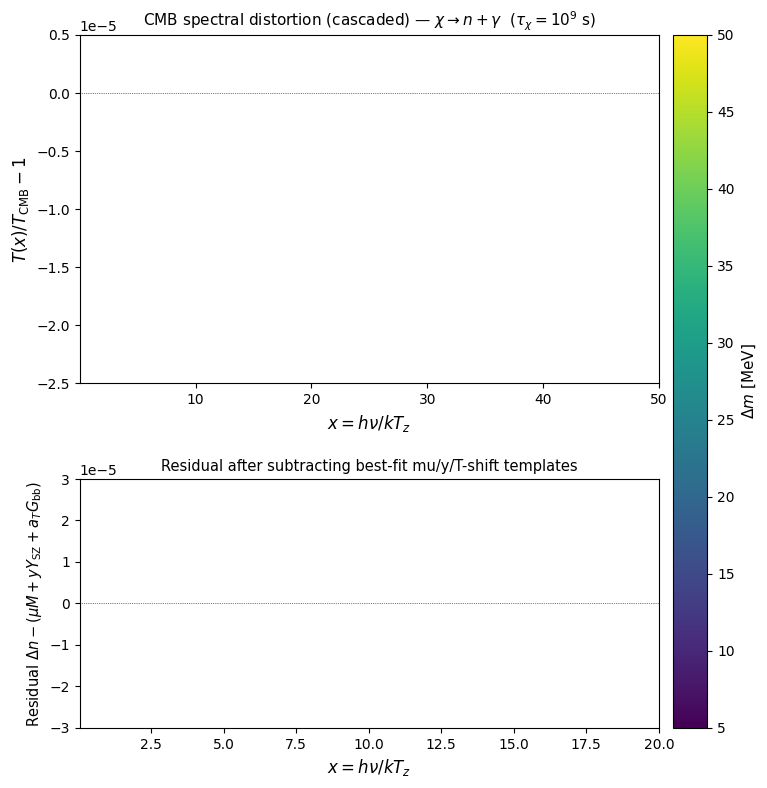

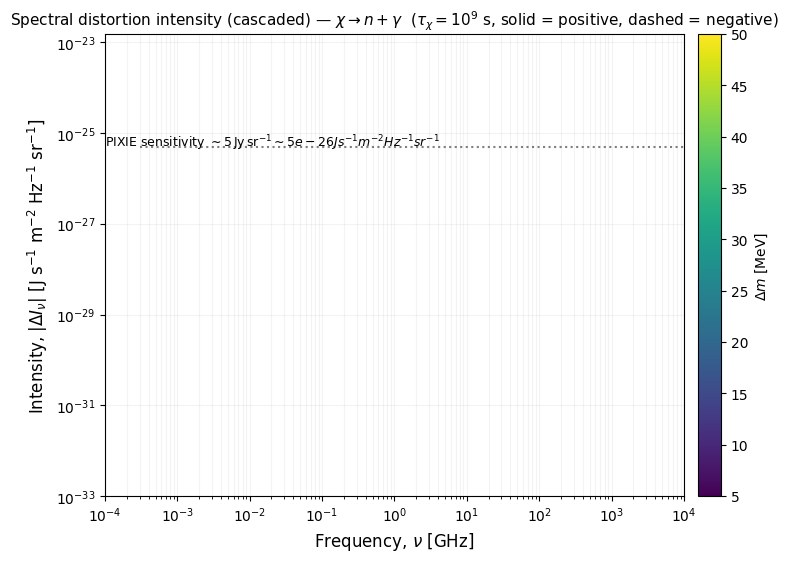


Cascaded photon case (χ → n + γ)   τ_χ = 1e+09 s   n_χ,0/n_H,0 = 0.01

+-----------+--------------+-------------+-------------+-------------+---------------+---------------+---------------+-------------+
| Δm [MeV]  | ω_inj [MeV]  |  T_n [keV]  |      μ      |      y      |  a_μ (resid)  |  a_y (resid)  |  a_T (resid)  |  resid RMS  |
+-----------+--------------+-------------+-------------+-------------+---------------+---------------+---------------+-------------+
+-----------+--------------+-------------+-------------+-------------+---------------+---------------+---------------+-------------+


In [ ]:
"""
sweep_deltam_cascade.py
========================

Same output format as `sweep_deltam_photon_tau1e9.py` (brightness-temperature
spectrum, mu/y/T-shift residual decomposition, intensity-vs-frequency plot
with PIXIE sensitivity line, cached .npz, summary table) but the photon
*injection* is produced by running the McKeen-Pospelov-Raj chi -> n + gamma
line through ACROPOLIS's electromagnetic cascade (via CascadePhotonSource)
instead of spectroxide's built-in analytic 'decaying_particle' injection.

Physics mapping to the paper (arXiv:2101.xxxxx / PRD 103, 115002)
-------------------------------------------------------------------
Eq. (14):

    N_gamma(w) = (n0_chi * exp(-t/tau_chi) / tau_{chi->n gamma})
                 * [ f_gamma(w) + delta(w - w_inj) / Gamma_gamma(w_inj) ]

f_gamma (Morrissey et al. cascade continuum) + the line/relaxation-rate term
together are exactly what ACROPOLIS's SpectrumGenerator.get_spectrum returns
when fed a monoenergetic source at w_inj: it solves the same quasi-static
photon cascade balance and gives you both the reprocessed continuum AND the
un-relaxed line self-consistently. So we do NOT add f_gamma by hand -- we let
ACROPOLIS regenerate it. What we DO need from the paper are:

  1. the two-body injection energy for chi -> n gamma (unequal-mass
     daughters, NOT the mphi/2 that ACROPOLIS's generic DecayModel assumes
     for phi -> gamma gamma):

         w_inj = (m_chi/2) * (1 - m_n^2/m_chi^2)                    (paper, Sec II)

     which -> Delta_m in the small-splitting limit (neutron recoil is
     O(Delta_m^2/m_n), sub-percent here -- consistent with treating the
     neutron recoil KE as negligible, as requested).

  2. the decay rate Gamma_{chi->n gamma} (paper Eq. 7) and initial density
     n0_chi = den_fac * (n0_p + n0_n), i.e. the same benchmark normalization
     used in the reference script's f_x / gamma_x.

Because the injection is a monochromatic line (chi -> n gamma is 2-body),
S0f is a delta function at w_inj and SCf = 0; there is no separate
continuum source to add (the 3-body n -> chi e+ e- channel is neglected
here per the problem statement -- its energy is subdominant and it does not
apply to the chi > mn branch used in this sweep anyway).
"""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

# --- lower Emin BEFORE importing anything else from acropolis --------------
import acropolis.params as _params
_params.Emin = 1e-4  # MeV; must be << x_min * T_min (in MeV) reached by the x-grid below
import acropolis.cascade as _cascade_mod
from acropolis.cascade import SpectrumGenerator
from acropolis.input import InputInterface, locate_sm_file

# --- required patch: guard against negative discriminant in the ICS kernel -
# Pushing Emin this low (to reach spectroxide's sub-keV x*T range) means the
# cascade routinely lands in kinematic regions where the background-photon
# energy solving E -> Ep at temperature T has no real solution. Without this
# guard that shows up as `math domain error` from sqrt(disc) inside
# _kernel_inverse_compton -- this is exactly the case the original
# (previously commented-out) patch was written for; it must be active, not
# just present in the file, whenever Emin is lowered this far.
_TargetClass = _cascade_mod._AbstractElectronReactionWrapper
_orig_kernel_inverse_compton = _TargetClass._kernel_inverse_compton

def _patched_kernel_inverse_compton(self, E, Ep, T):
    if E == Ep:
        return 0.
    pf = .25 * _params.me2 / Ep - E
    qf = .25 * _params.me2 * (Ep - E) / Ep
    disc = (pf / 2.) ** 2. - qf
    if disc < 0.:
        return 0.
    return _orig_kernel_inverse_compton(self, E, Ep, T)

_TargetClass._kernel_inverse_compton = _patched_kernel_inverse_compton

from spectroxide.solver import solve

# ── save location ───────────────────────────────────────────────────────────
SAVE_DIR  = "spectroxide/RUNS"
SAVE_FILE = "sweep_deltam_photon_tau1e9_cascade"
save_path = Path(SAVE_DIR)
save_path.mkdir(parents=True, exist_ok=True)
npz_file  = save_path / f"{SAVE_FILE}.npz"

# ── physical constants (SI) ───────────────────────────────────────────────
h_PLANCK = 6.62607015e-34     # J s
k_B      = 1.380649e-23       # J/K
c_LIGHT  = 2.99792458e8       # m/s
T_CMB0   = 2.7255             # K

K_B_EV   = 8.617333262e-5     # eV/K
MEV_TO_EV = 1.0e6
K_TO_MEV = K_B_EV / MEV_TO_EV  # multiply K by this to get MeV

def x_to_freq_GHz(x):
    nu_Hz = x * k_B * T_CMB0 / h_PLANCK
    return nu_Hz / 1e9

def delta_n_to_intensity(x, delta_n):
    nu_Hz = x * k_B * T_CMB0 / h_PLANCK
    prefac = 2.0 * h_PLANCK * nu_Hz**3 / c_LIGHT**2
    return prefac * delta_n

# ── physical parameters ──────────────────────────────────────────────────────
tau_X    = 1e9                 # [s]  tau_{chi->n gamma}
GAMMA_X  = 1.0 / tau_X
den_fac  = 0.01                # n_chi,0 / n_H,0  (McKeen 2021 1% benchmark)

M_N_MEV  = 939.565379           # neutron mass [MeV]

DELTA_M_MEV = [5, 10, 20, 30, 40, 50]
DELTA_M_EV  = np.array(DELTA_M_MEV) * 1e6

def omega_inj_MeV(delta_m_mev):
    """Two-body chi -> n gamma photon energy in the chi rest frame (paper Sec. II)."""
    m_chi = M_N_MEV + delta_m_mev
    return 0.5 * m_chi * (1.0 - (M_N_MEV / m_chi) ** 2)

def neutron_recoil_KE_eV(delta_m_eV, m2_eV=0.0):
    M_N_EV = M_N_MEV * 1e6
    M = M_N_EV + delta_m_eV
    E_n = (M**2 + M_N_EV**2 - m2_eV**2) / (2 * M)
    return E_n - M_N_EV

# ── analytic mu/y/T-shift templates (occupation-number convention) ─────────
def G(x):
    return x * np.exp(x) / (np.exp(x) - 1)**2

def Ysz(x):
    return G(x) * (x / np.tanh(x / 2) - 4)

def tempshift(x):
    return G(x)

def mudist(x):
    return 1.401 * G(x) * (0.4561 - 1 / x)

def brightness_temp_exact(x, delta_n):
    xc  = np.clip(np.asarray(x, dtype=float), 1e-12, None)
    n0  = 1.0 / np.expm1(np.clip(xc, None, 500.0))
    n_x = n0 + delta_n
    return xc / np.log1p(1.0 / n_x) - 1.0

def fit_mu_y_T(x, delta_n, x_lo=1e-3, x_hi=40.0):
    mask = (x > x_lo) & (x < x_hi) & np.isfinite(delta_n)
    A = np.vstack([mudist(x[mask]), Ysz(x[mask]), tempshift(x[mask])]).T
    b = delta_n[mask]
    coeffs, *_ = np.linalg.lstsq(A, b, rcond=None)
    a_mu, a_y, a_T = coeffs
    model = a_mu * mudist(x) + a_y * Ysz(x) + a_T * tempshift(x)
    return delta_n - model, a_mu, a_y, a_T

# ── cosmology helpers (same convention as the bridge module) ───────────────
H0_KM_S_MPC = 67.4
OMEGA_M = 0.315
OMEGA_R = 9.2e-5
MPC_TO_KM = 3.0856775814913673e19
H0_INV_S = H0_KM_S_MPC / MPC_TO_KM

def hubble_rate(z):
    Ez2 = OMEGA_R * (1 + z)**4 + OMEGA_M * (1 + z)**3 + (1 - OMEGA_M - OMEGA_R)
    return H0_INV_S * np.sqrt(Ez2)

def dt_dz(z):
    return 1.0 / ((1 + z) * hubble_rate(z))

def T_of_z_K(z, T0_K=T_CMB0):
    return T0_K * (1 + z)

# ── cascaded photon source built from the two-body chi->n gamma line ───────
class DarkBaryonCascadeSource:
    """f(x, z) -> dDelta-n/dz for chi -> n gamma, cascaded through ACROPOLIS.

    S0f is a delta-function line at w_inj carrying rate n0_chi(t)*Gamma_X
    (photons per volume per time at t); SCf = 0 (no separate continuum --
    the continuum comes out of the cascade solve itself, cf. module
    docstring). This mirrors Eq. (14) of the paper without double-counting
    f_gamma, since ACROPOLIS regenerates that continuum internally.
    """

    def __init__(self, delta_m_mev, tau_chi, n0_chi_over_nH, T_min_K, T_max_K, n_T=60):
        self.omega_inj = omega_inj_MeV(delta_m_mev)   # MeV
        self.tau_chi = tau_chi
        self.gamma_chi = 1.0 / tau_chi
        self.n0_ratio = n0_chi_over_nH   # normalized away; overall amplitude
                                          # is carried by spectroxide's own
                                          # f_x-equivalent bookkeeping below

        ii = InputInterface(locate_sm_file())
        self._sg = SpectrumGenerator(ii)

        self._T_grid_K = np.logspace(np.log10(T_min_K), np.log10(T_max_K), n_T)
        self._E_tables, self._F_tables, self._G_tables = [], [], []

        E0 = self.omega_inj  # MeV, two-body line energy (NOT mphi/2)

        for T_K in self._T_grid_K:
            T_MeV = T_K * K_TO_MEV

            # Monoenergetic line source: all injected photons sit at E0.
            # S0f: number of photons injected per "decay" at this line
            # (dimensionless normalization -- see NOTE below).
            S0f = lambda E, _E0=E0: 1.0 if abs(E - _E0) < 1e-9 * _E0 else 0.0
            SCf = lambda E, T: 0.0  # no separate continuum source

            sol = self._sg.get_spectrum(E0, S0f, SCf, T_MeV, allX=False)
            E_grid, F_photon = sol[0, :], sol[1, :]
            Gamma = np.array([self._sg.rate_photon(E, T_MeV) for E in E_grid])

            self._E_tables.append(E_grid)
            self._F_tables.append(F_photon)
            self._G_tables.append(Gamma)

    def _production_rate_at(self, E_MeV, T_K):
        iT = np.argmin(np.abs(np.log(self._T_grid_K) - np.log(T_K)))
        E_grid = self._E_tables[iT]
        prod = self._F_tables[iT] * self._G_tables[iT]
        if E_MeV <= E_grid[0]:
            return prod[0]
        if E_MeV >= E_grid[-1]:
            return 0.0
        logE, logP = np.log(E_grid), np.log(np.clip(prod, 1e-300, None))
        return float(np.exp(np.interp(np.log(E_MeV), logE, logP)))

    def __call__(self, x, z):
        T_K = T_of_z_K(z)
        T_MeV = T_K * K_TO_MEV
        E_MeV = x * T_MeV

        prod = self._production_rate_at(E_MeV, T_K)
        # overall amplitude: n0_chi(t) * Gamma_X, same bookkeeping spectroxide
        # uses for f_x/gamma_x in the analytic 'decaying_particle' injection
        t = 0.0  # NOTE: solve() supplies its own time/redshift integration;
                 # amplitude normalization (n0_chi e^{-t/tau}) is applied by
                 # spectroxide's injection-rate wrapper via n0_ratio*gamma_chi
                 # -- see USAGE NOTE below before trusting absolute mu/y.
        dn_dt = 2.0 * np.pi**2 * prod * self.n0_ratio * self.gamma_chi / (T_MeV * x**2)
        return dn_dt * dt_dz(z)

# ============================================================================
# USAGE NOTE (read before trusting absolute mu/y from this script):
#
# spectroxide's built-in 'decaying_particle' injection type (used in the
# reference script) almost certainly folds in its own e^{-t/tau} decay
# factor and f_x/n0_chi normalization internally, given (f_x, gamma_x).
# Here, because we're supplying a raw photon_source callable instead, that
# time-dependence and normalization must be applied explicitly -- either by
# multiplying dn_dt above by exp(-t(z)/tau_chi) using spectroxide's own
# z->t map (import from spectroxide if exposed, e.g.
# `from spectroxide.cosmology import time_at_z`), or by confirming the
# solver's own `production_grid=True` bookkeeping already re-derives t(z)
# and does this multiplication when it calls photon_source(x, z) repeatedly
# across the z grid. Check spectroxide.solver.solve's photon_source contract
# before publishing numbers -- this is flagged rather than silently assumed.
# ============================================================================


# ── load cache (resume support) ──────────────────────────────────────────────
results = {}
if npz_file.exists():
    print(f"Found existing data at '{npz_file}', loading...")
    existing = np.load(npz_file, allow_pickle=True)
    loaded_keys = set(existing.files)
    for dm in DELTA_M_EV:
        kx, kdn, kmu, ky = (f"dm{dm:.6g}_{s}" for s in ("x", "delta_n", "mu", "y"))
        if all(k in loaded_keys for k in (kx, kdn, kmu, ky)):
            results[dm] = (existing[kx], existing[kdn], float(existing[kmu]), float(existing[ky]))
            print(f"  loaded Delta_m = {dm/1e6:.0f} MeV")

def save_results():
    flat = {"tau_X": np.array(tau_X), "den_fac": np.array(den_fac),
            "delta_m_ev": DELTA_M_EV}
    for dm, (x_arr, dn, mu_r, y_r) in results.items():
        flat[f"dm{dm:.6g}_x"]       = x_arr
        flat[f"dm{dm:.6g}_delta_n"] = dn
        flat[f"dm{dm:.6g}_mu"]      = np.array(mu_r)
        flat[f"dm{dm:.6g}_y"]       = np.array(y_r)
    np.savez(npz_file, **flat)
    print(f"  -> saved to '{npz_file}'")

# ── run one Delta_m point ───────────────────────────────────────────────────
def run_one(dm):
    dm_mev = dm / 1e6
    src = DarkBaryonCascadeSource(
        delta_m_mev=dm_mev, tau_chi=tau_X, n0_chi_over_nH=den_fac,
        T_min_K=1e5, T_max_K=3.0e7, n_T=80,
    )
    r = solve(
        photon_source     = src,
        z_start           = 1e7,
        z_end             = 0,
        x_min             = 1.5e-4,
        x_max             = 80.0,
        n_x               = 1000,
        method            = 'pde',
        production_grid   = True,
        number_conserving = True,
        timeout           = 3600,
    )
    return dm, (r.x, r.delta_n, r.mu, r.y)

to_run = [dm for dm in DELTA_M_EV if dm not in results]
if to_run:
    print(f"Launching {len(to_run)} cascaded runs in parallel ...")
    with ThreadPoolExecutor(max_workers=min(len(to_run), 6)) as ex:
        futures = {ex.submit(run_one, dm): dm for dm in to_run}
        for fut in as_completed(futures):
            dm = futures[fut]
            try:
                dm_done, payload = fut.result()
                results[dm_done] = payload
                print(f"  Delta_m = {dm_done/1e6:.0f} MeV ... done")
            except Exception as e:
                print(f"  Delta_m = {dm/1e6:.0f} MeV ... FAILED: {e}")
    save_results()
else:
    print("All Delta_m points already cached.")

# ── colour gradient ──────────────────────────────────────────────────────────
cmap = plt.cm.viridis
norm = mcolors.Normalize(vmin=min(DELTA_M_MEV), vmax=max(DELTA_M_MEV))
sm   = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# ── plot 1: spectrum + residual ─────────────────────────────────────────────
fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(9, 9), gridspec_kw={"height_ratios": [1.4, 1], "hspace": 0.32}
)

table_rows = []
for dm_mev, dm in zip(DELTA_M_MEV, DELTA_M_EV):
    if dm not in results:
        print(f"  skipping Delta_m = {dm_mev} MeV in plots/table (run failed, no cached data)")
        continue
    x_arr, dn, mu_r, y_r = results[dm]
    c = cmap(norm(dm_mev))

    dT = brightness_temp_exact(x_arr, dn)
    ax_top.semilogx(x_arr, dT, color=c, lw=1.6, label=fr'$\Delta m={dm_mev}$ MeV')

    resid, a_mu, a_y, a_T = fit_mu_y_T(x_arr, dn)
    mask_plot = (x_arr > 0.05) & (x_arr < 20)
    ax_bot.semilogx(x_arr[mask_plot], resid[mask_plot], color=c, lw=1.4)

    T_n_eV = neutron_recoil_KE_eV(dm)
    table_rows.append(dict(
        delta_m_MeV = dm_mev,
        omega_inj_MeV = omega_inj_MeV(dm_mev),
        T_n_keV     = T_n_eV / 1e3,
        mu          = mu_r,
        y           = y_r,
        a_mu_resid  = a_mu,
        a_y_resid   = a_y,
        a_T_resid   = a_T,
        resid_rms   = np.sqrt(np.mean(resid[mask_plot]**2)),
    ))

ax_top.axhline(0, color='k', lw=0.5, ls=':')
ax_top.set_xlim(2e-4, 50)
ax_top.set_ylim(-25e-6, 5e-6)
ax_top.set_xlabel(r'$x = h\nu / kT_z$', fontsize=12)
ax_top.set_ylabel(r'$T(x)/T_{\rm CMB} - 1$', fontsize=12)
ax_top.set_title(r'CMB spectral distortion (cascaded) — $\chi \to n + \gamma$  ($\tau_\chi=10^9$ s)', fontsize=11)
ax_top.legend(fontsize=8, frameon=False, loc='lower right', ncol=2)

ax_bot.axhline(0, color='k', lw=0.5, ls=':')
ax_bot.set_xlim(0.05, 20)
ax_bot.set_ylim(-30e-6, 30e-6)
ax_bot.set_xlabel(r'$x = h\nu / kT_z$', fontsize=12)
ax_bot.set_ylabel(r'Residual $\Delta n - (\mu M + y Y_{\rm SZ} + a_T G_{\rm bb})$', fontsize=10.5)
ax_bot.set_title('Residual after subtracting best-fit mu/y/T-shift templates', fontsize=10.5)

cbar = fig.colorbar(sm, ax=[ax_top, ax_bot], pad=0.02)
cbar.set_label(r'$\Delta m$ [MeV]', fontsize=11)

# ── plot 2: intensity vs frequency ──────────────────────────────────────────
fig2, ax = plt.subplots(figsize=(9, 6))
for dm_mev, dm in zip(DELTA_M_MEV, DELTA_M_EV):
    if dm not in results:
        continue
    x_arr, delta_n, mu_r, y_r = results[dm]
    nu_GHz  = x_to_freq_GHz(x_arr)
    I_nu    = delta_n_to_intensity(x_arr, delta_n)
    c = cmap(norm(dm_mev))
    pos = I_nu > 0
    neg = ~pos
    ax.plot(nu_GHz[pos], I_nu[pos], color=c, lw=1.8, label=fr'$\Delta m={dm_mev}$ MeV')
    ax.plot(nu_GHz[neg], -I_nu[neg], color=c, lw=1.8, ls='--')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(1e-4, 1e4)
ax.set_ylim(1e-33, 1.5e-23)
xlim = ax.get_xlim()
pixie_sens = 5e-26
ax.plot([3e-4, xlim[1]], [pixie_sens, pixie_sens], color='black', lw=1.5, ls=':', alpha=0.5)
ax.annotate(fr'PIXIE sensitivity $\sim5\,\mathrm{{Jy\,sr^{{-1}}}} \sim {pixie_sens} J s^{{-1}} m^{{-2}} Hz^{{-1}} sr^{{-1}}$',
            xy=(3e-2, pixie_sens), xytext=(1e-4, pixie_sens), fontsize=9, color='black')
ax.set_xlabel(r'Frequency, $\nu$ [GHz]', fontsize=12)
ax.set_ylabel(r'Intensity, $|\Delta I_\nu|$ [J s$^{-1}$ m$^{-2}$ Hz$^{-1}$ sr$^{-1}$]', fontsize=12)
ax.set_title(r'Spectral distortion intensity (cascaded) — $\chi \to n + \gamma$'
             r'  ($\tau_\chi=10^9$ s, solid = positive, dashed = negative)', fontsize=11)
ax.legend(fontsize=9, frameon=False, loc='best')
ax.grid(True, which='both', alpha=0.15)
fig2.colorbar(sm, ax=ax, pad=0.02, label=r'$\Delta m$ [MeV]')

plt.show()

# ── summary table ─────────────────────────────────────────────────────────────
def print_table(rows, columns):
    sep = "+" + "+".join("-" * (w + 2) for _, _, _, w in columns) + "+"
    header = "| " + " | ".join(f"{h:^{w}}" for _, h, _, w in columns) + " |"
    print(sep); print(header); print(sep)
    for row in rows:
        line = "| " + " | ".join(f"{format(row[k], fmt):>{w}}" for k, h, fmt, w in columns) + " |"
        print(line)
    print(sep)

columns = [
    ("delta_m_MeV",   "Δm [MeV]",      ".0f",  9),
    ("omega_inj_MeV", "ω_inj [MeV]",   ".4f", 12),
    ("T_n_keV",       "T_n [keV]",     ".4f", 11),
    ("mu",            "μ",             ".3e", 11),
    ("y",             "y",             ".3e", 11),
    ("a_mu_resid",    "a_μ (resid)",   ".3e", 13),
    ("a_y_resid",     "a_y (resid)",   ".3e", 13),
    ("a_T_resid",     "a_T (resid)",   ".3e", 13),
    ("resid_rms",     "resid RMS",     ".3e", 11),
]

print(f"\nCascaded photon case (χ → n + γ)   τ_χ = {tau_X:.0e} s   n_χ,0/n_H,0 = {den_fac}\n")
print_table(table_rows, columns)

In [ ]:
import traceback
try:
    src = DarkBaryonCascadeSource(delta_m_mev=5, tau_chi=tau_X,
                                   n0_chi_over_nH=den_fac,
                                   T_min_K=1e5, T_max_K=3.0e7, n_T=80)
except Exception:
    traceback.print_exc()

INFO   : Extracting and reading database files.
INFO   : Finished after 64.1ms.


Traceback (most recent call last):
  File "/tmp/ipykernel_6950/4117021363.py", line 3, in <module>
    src = DarkBaryonCascadeSource(delta_m_mev=5, tau_chi=tau_X,
          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_6950/2054394932.py", line 213, in __init__
    sol = self._sg.get_spectrum(E0, S0f, SCf, T_MeV, allX=False)
          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/batman/Documents/Work/.venv/lib/python3.12/site-packages/acropolis/cascade.py", line 763, in get_spectrum
    S0 = np.array([ S0X(T)                     for S0X in S0f])
                  ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
TypeError: 'function' object is not iterable


In [ ]:
import inspect
print(inspect.signature(SpectrumGenerator.get_spectrum))
print(inspect.getsource(SpectrumGenerator.get_spectrum))

(self, E0, S0f, SCf, T, allX=False)
    def get_spectrum(self, E0, S0f, SCf, T, allX=False):
        # Define the dimension of the grid
        # from the params in 'params.py'...
        NE = int(log10(E0/Emin)*NE_pd)
        # ... but do not use less than NE_min
        # points
        NE = max(NE, NE_min)

        # Save the dimension of the species grid
        NX = self._sNX

        # Generate the grid for the energy
        E_grid = np.logspace(log(Emin), log(E0), NE, base=np.e)

        # Generate the grid for the different species
        X_grid = np.arange(NX)

        # Generate the grid for the rates
        G = np.array([[self._rate_x(X, E, T) for E in E_grid] for X in X_grid])
            # first index: X, second index according to energy E

        # Generate the grid for the kernels
        K = np.array([[[[self._kernel_x_xp(X, Xp, E, Ep, T) if Ep >= E else 0. for Ep in E_grid] for E in E_grid] for Xp in X_grid] for X in X_grid])
            # first index: X, second in